# SC4020 · Run 6 v5
## GraphSAGE: from controlled message passing to critical model interpretation

**An executable research narrative** · EuroMart (quarterly) and Retail POS (monthly) · Strict node-only feature policy

**Guiding question.** *Does neighbourhood message passing recover useful customer–category preference information beyond frozen node features and non-graph baselines—and, if so, under what structural and optimisation conditions?*

This notebook deliberately follows the logic of a scientific investigation rather than collecting every chart at the end. **Every analysis chapter displays the figures it creates directly beneath its explanation**, and also saves high-resolution PNG and vector SVG copies by analysis family and dataset.

> **Evidence hierarchy:** validation-only architecture selection → held-out headline comparison → paired uncertainty → controlled interventions → customer recommendation behaviour → representation and numerical diagnostics → guarded synthesis.

**Reproducibility.** The notebook preserves the existing v5 GraphSAGE model, training objective, validation-selected configurations, three final seeds (42, 43, 44) and Run 2/3 data contracts. `PROFILE='smoke'` produces structural checks and illustrative smoke results only. `PROFILE='exhaustive'` enables the complete 96-candidate search and the full ablation family. No source v3/v4 artifacts are modified.

**Canonical Run 6 v5 · benchmark-ready.** A separate output directory prevents reuse of previous v5 results. Finite extreme logits are logged, not automatically treated as divergence. Zero-success ablations are recorded, and incomplete seed outputs are excluded.

**Runtime comparison.** We record real wall-clock durations of HPO, selected GraphSAGE fits, epoch optimisation/validation, held-out inference, and ablations separately. The exported team comparison includes hardware and availability of seed SD. These are *measured values*, never inferred from epoch counts.


### Notebook atlas · Read in order

| Chapter | Research question | Main evidence |
|:--|:--|:--|
| **01 · Contract** | Are the graphs and baseline results comparable and leakage-controlled? | Frozen SHA-256 manifests; dataset contracts |
| **02 · Model** | What computation does GraphSAGE actually learn? | Exact node-only implementation and loss |
| **03 · Tuning** | Which architectural choices survive validation-only selection? | Search landscape, failure accounting, finalists |
| **04 · Training dynamics** | How do the selected models optimise, and what checkpoint is actually chosen? | Train/val BCE, NDCG and gradient trajectories |
| **05 · Headline evidence** | Does message passing improve next-period ranking? | Run 3 + GraphSAGE leaderboard, PR curves and seed dispersion |
| **06 · Uncertainty & time** | How consistent is an observed improvement? | Customer-cluster paired bootstrap; held-out periods |
| **07 · Causal probes** | Does structure, depth or particular feature access matter? | Controlled ablations, degree-preserving rewiring and team-ready runtime tables |
| **08 · Recommendation behaviour** | Is the model personalised and does it discover novel links? | List diversity, exposure, customer strata and recall |
| **09 · Representations** | Do embeddings preserve informative variation and numerical scale? | Effective rank, norms, logits and saturation |
| **10 · Evidence synthesis** | What can this experiment establish and what remains uncertain? | Automatic evidence ledger and indexed figure atlas |

**Important interpretation constraint:** EuroMart now predicts quarters and Retail POS predicts months; cross-dataset absolute metric levels are not directly comparable. With only three final seeds and a short test horizon, small score differences should not be overstated. Existing v3/v4 test exposure makes v5 exploratory rather than a pristine held-out confirmatory study.

## 01 · Experiment contract and provenance

**Hypothesis-control gate.** Both GraphSAGE models must use the exact same eligible customer–category labels, historical graph topology, 7+7 node features and ranking definitions as Run 3. Edge attributes, numeric pair histories and pair-engineered predictors are *excluded*. The input graph may still encode prior binary purchases—that is the relationship GraphSAGE is intended to test.

The notebook refuses to proceed when Run 2 snapshots, their hashes or Run 3's frozen model selection disagree with the v5 contract. All test data remain unavailable to the tuning procedure.

In [1]:
from __future__ import annotations
import os,sys,json,hashlib,random,time,copy,traceback,math,shutil,platform,socket
from pathlib import Path
from collections import defaultdict
from datetime import datetime,timezone
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.metrics import average_precision_score
from IPython.display import display

PROFILE='exhaustive'  # smoke first; switch to exhaustive for complete 96-candidate + 3-seed benchmark
REPO_ROOT_OVERRIDE=None
RUN3_ROOT_OVERRIDE=None
DEVICE_OVERRIDE=None
USE_LOCAL_SNAPSHOT_CACHE=True
FORCE_RERUN=True  # Default: actually retrain HPO + final models; False permits checkpoint reuse.
DATASETS=('euromart','retail_pos')
FINAL_SEEDS=(42,43,44)
LR_GRID=(1.,.1,.01,.001,.0001)
N_CAT=17
KS=(3,5,10)
PRIMARY='NDCG@10'
STABILITY=dict(median_logit_max=100.,p99_logit_max=250.,max_grad_norm=1e6,clip=5.)  # finite magnitude limits are warning flags only
BUDGET={
 'smoke':dict(trials=2,screen_epochs=1,search_epochs=2,patience=1,topk=1,
        final_epochs=3,final_patience=1,selection_seeds=(42,),final_seeds=(42,),
        ablation_seeds=(42,),rewire_repeats=1,boot=60),
 'exhaustive':dict(trials=96,screen_epochs=20,search_epochs=100,patience=12,topk=5,
        final_epochs=200,final_patience=20,selection_seeds=FINAL_SEEDS,
        final_seeds=FINAL_SEEDS,ablation_seeds=FINAL_SEEDS,rewire_repeats=3,boot=5000)}
B=BUDGET[PROFILE]

def set_seed(s):
    random.seed(s);np.random.seed(s);torch.manual_seed(s)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(s)
def filehash(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''):h.update(b)
    return h.hexdigest()
def json_safe(x):
    if isinstance(x,np.generic):return x.item()
    if isinstance(x,np.ndarray):return x.tolist()
    if isinstance(x,Path):return str(x)
    if isinstance(x,(tuple,list)):return [json_safe(v) for v in x]
    if isinstance(x,dict):return {k:json_safe(v) for k,v in x.items()}
    return x
def write_json(p,x):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);p.write_text(json.dumps(json_safe(x),indent=2,sort_keys=True,default=str))
def read_json(p):return json.loads(Path(p).read_text())
def save_csv(df,p):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    df.to_csv(p,index=False,compression='gzip' if str(p).endswith('.gz') else None)
def hash_config(v):return hashlib.sha256(json.dumps(json_safe(v),sort_keys=True).encode()).hexdigest()[:16]

def find_root():
    try:
        from google.colab import drive
        if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
    except ImportError:pass
    for x in [REPO_ROOT_OVERRIDE,os.environ.get('SC4020_REPO_ROOT'),'/content/drive/MyDrive/SC4020-DataMining',
              '/content/SC4020-DataMining',Path.cwd(),Path.cwd().parent]:
        if x and (Path(x)/'graph_data/v5/euromart/snapshot_index.csv').exists() and (Path(x)/'graph_data/v3/retail_pos/snapshot_index.csv').exists():return Path(x).resolve()
    raise FileNotFoundError('Run 2 v5 prerequisite missing. Set REPO_ROOT_OVERRIDE.')
ROOT=find_root()
RUN3=Path(RUN3_ROOT_OVERRIDE) if RUN3_ROOT_OVERRIDE else ROOT/'results/v5/run3_baselines'/PROFILE
OUT=ROOT/'results/v5/run6_graphsage_benchmark_v5'/PROFILE
OUT.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device(DEVICE_OVERRIDE or ('cuda' if torch.cuda.is_available() else 'cpu'))
set_seed(2026)
print('Repo',ROOT,'/ Run3',RUN3,'/ Run6',OUT,'/ Device',DEVICE)

def sync_device():
    if DEVICE.type=='cuda':torch.cuda.synchronize(DEVICE)

def hardware_snapshot():
    import sklearn
    out=dict(utc_time=datetime.now(timezone.utc).isoformat(),
             python=sys.version.split()[0],pytorch=torch.__version__,
             numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__,
             platform=platform.platform(),machine=platform.machine(),hostname=socket.gethostname(),
             torch_device=str(DEVICE),device_type=DEVICE.type,
             cpu_logical_cores=os.cpu_count(),cuda_available=torch.cuda.is_available(),
             cuda_version=torch.version.cuda,forced_rerun=FORCE_RERUN,
             profile=PROFILE,budget=B,benchmark_timer='time.perf_counter; CUDA synchronised',
             notes='Training times include model initialisation and epoch-wise validation. '
                   'CUDA GPU kernel synchronisation is forced around each timed phase; '
                   'GPU memory is training peak allocated, not total device reservation.')
    if DEVICE.type=='cuda':
        ix=DEVICE.index if DEVICE.index is not None else torch.cuda.current_device()
        prop=torch.cuda.get_device_properties(ix)
        out.update(gpu_name=prop.name,gpu_total_bytes=int(prop.total_memory),
                   gpu_index=int(ix))
    else:out.update(gpu_name=None,gpu_total_bytes=None,gpu_index=None)
    return out
HARDWARE=hardware_snapshot()
write_json(OUT/'manifests/benchmark_hardware.json',HARDWARE)
print('Benchmark profile:',PROFILE,'| device:',DEVICE,'| fresh rerun:',FORCE_RERUN)


Mounted at /content/drive
Repo /content/drive/MyDrive/SC4020-DataMining / Run3 /content/drive/MyDrive/SC4020-DataMining/results/v5/run3_baselines/exhaustive / Run6 /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive / Device cpu
Benchmark profile: exhaustive | device: cpu | fresh rerun: True


In [2]:
REQUIRED={'customer_features','category_features','edge_index','edge_index_bipartite',
          'eligible_customer_idx','labels','eligible_history_pair_mask','eligible_history_degree',
          'eligible_previous_month_mask'}
INFO={};CACHE={}
def ds_base(ds):return ROOT/('graph_data/v5/euromart' if ds=='euromart' else 'graph_data/v3/retail_pos')
def ds_snapdir(ds):return ds_base(ds)/('quarterly' if ds=='euromart' else 'monthly')

for ds in DATASETS:
    base=ds_base(ds);idx=pd.read_csv(base/'snapshot_index.csv',dtype={'target_month':str,'split':str})
    assert len(idx)==(15 if ds=='euromart' else 12)
    assert idx.target_month.is_unique and idx.target_month.is_monotonic_increasing
    loss=read_json(base/'loss_diagnostics.json')
    INFO[ds]=dict(index=idx,loss=loss,base=base)
    for r in idx.itertuples(index=False):
        p=ds_snapdir(ds)/r.snapshot_file
        if not p.exists() or filehash(p)!=r.snapshot_sha256:raise AssertionError('Snapshot hash mismatch: '+str(p))

if USE_LOCAL_SNAPSHOT_CACHE and Path('/content').exists():
    for ds in DATASETS:
        dest=Path('/content/sc4020_v5_run6_cache')/ds;dest.mkdir(parents=True,exist_ok=True)
        for r in INFO[ds]['index'].itertuples(index=False):
            src=ds_snapdir(ds)/r.snapshot_file;p=dest/src.name
            if not p.exists() or filehash(p)!=r.snapshot_sha256:shutil.copy2(src,p)
        CACHE[ds]=dest

def load_one(ds,row):
    p=CACHE.get(ds,ds_snapdir(ds))/row.snapshot_file
    with np.load(p,allow_pickle=False) as z:
        # Whitelist only permitted node features, binary topology and evaluation masks.
        a={k:z[k] for k in REQUIRED.union({'history_customer_mask','history_category_mask',
          'customer_history_degree','category_history_degree','category_features_raw',
          'eligible_train_seen_customer_mask'}) if k in z.files}
    assert set(REQUIRED).issubset(a)
    n=len(a['customer_features']);e=a['edge_index_bipartite'];
    assert a['category_features'].shape==(17,7) and a['customer_features'].shape==(n,7)
    assert a['labels'].shape==(len(a['eligible_customer_idx']),17)
    assert a['edge_index'].shape==(2,2*len(e[0]))
    assert np.array_equal(a['edge_index'][:,:len(e[0])],np.stack([e[0],e[1]+n]))
    assert np.array_equal(a['edge_index'][:,len(e[0]):],np.stack([e[1]+n,e[0]]))
    hist=np.zeros((n,17),dtype=np.uint8);hist[e[0],e[1]]=1
    assert np.array_equal(hist[a['eligible_customer_idx']],a['eligible_history_pair_mask'])
    assert (a['labels'].sum(axis=1)>0).all() and np.isfinite(a['customer_features']).all()
    a['target_month']=str(row.target_month);a['split']=str(row.split)
    assert not any('edge_attr' in k or 'history_freshness' in k for k in a)
    return a

def get_splits(ds,splits=('train','val')):
    idx=INFO[ds]['index']
    return {k:[load_one(ds,r) for r in idx[(idx.split==k)&idx.usable_for_supervision.astype(bool)].itertuples(index=False)] for k in splits}

MUST=[RUN3/'manifests/frozen_selection.json',RUN3/'manifests/run_contract.json',RUN3/'tables/run3_test_summary.csv']
for x in MUST:
    if not x.exists():raise FileNotFoundError('Run 3 v5 must complete first: '+str(x))
SELECTION3=read_json(MUST[0]);CONTRACT3=read_json(MUST[1])
assert CONTRACT3['feature_policy']=='node_only_14D_for_learned_models'
assert set(SELECTION3)==set(DATASETS)
assert CONTRACT3['period_unit']=={'euromart':'quarter','retail_pos':'month'}
RUN3_HASH=filehash(MUST[0])
EXP_CONTRACT={'version':'5_benchmark_walltime','profile':PROFILE,'datasets':DATASETS,'seeds':FINAL_SEEDS,
  'source_run3_selection_sha256':RUN3_HASH,'lr_grid':LR_GRID,'budget':B,
  'archs':['Controlled','Tuned'],'policy':'no_edge_or_pair_numeric_features',
  'historical_test_exposure':True,'source_graph_hashes':{
    ds:filehash(ds_base(ds)/'snapshot_index.csv') for ds in DATASETS}}
cp=OUT/'manifests/run_contract.json'
if cp.exists():assert read_json(cp)==json_safe(EXP_CONTRACT),'Old Run6 contract differs; do not overwrite'
else:write_json(cp,EXP_CONTRACT)
print('Verified 27 v5-compatible snapshots and corresponding Run3 v5 frozen selection')


Verified 27 v5-compatible snapshots and corresponding Run3 v5 frozen selection


## 02 · GraphSAGE computation and training criterion

For directed neighbour messages on the undirected customer–category graph, the node-only layer is

$$\mathbf m_{v\leftarrow j}^{(\ell)}=\mathbf W_{\mathrm{neigh}}^{(\ell)}\mathbf h_j^{(\ell)}+\mathbf b_{\mathrm{neigh}}^{(\ell)},\qquad\mathbf h_v^{(\ell+1)}=\phi\!\left(\mathbf W_{\mathrm{self}}^{(\ell)}\mathbf h_v^{(\ell)}+\mathbf b_{\mathrm{self}}^{(\ell)}+\operatorname{AGG}_{j\in\mathcal N(v)}\mathbf m_{v\leftarrow j}^{(\ell)}\right).$$

The dot-product decoder scores **all 17 categories** for each eligible customer: $s(u,c)=\mathbf z_u^\top\mathbf z_c$. The model optimises positively weighted BCE-with-logits, but **checkpoint selection and hyperparameter optimisation use validation NDCG@10**. Therefore, minimum validation BCE and maximum validation ranking quality need not coincide.

**Comparators:** the controlled reference fixes two mean-aggregation layers, 64-dimensional embeddings and learning rate 0.001. The tuned variant searches propagation depth, aggregation, dimensions, activation, residual/normalisation choices and regularisation. Neither receives numerical edge attributes.

In [ ]:
def order_scores(s):
    s=np.asarray(s,float)
    if not np.isfinite(s).all():raise FloatingPointError('Nonfinite score')
    return np.argsort(-s,axis=1,kind='stable')
def instance_metrics(y,s):
    order=order_scores(s);ranked=np.take_along_axis(y,order,axis=1)
    assert (y.sum(axis=1)>0).all()
    out={}
    for k in KS:
        hits=ranked[:,:k].sum(axis=1)
        disc=1/np.log2(np.arange(2,k+2))
        ideal=np.array([disc[:min(int(p),k)].sum() for p in y.sum(axis=1)])
        out[f'NDCG@{k}']=np.sum(ranked[:,:k]*disc[None,:],axis=1)/ideal
        out[f'Recall@{k}']=hits/y.sum(axis=1)
        out[f'Precision@{k}']=hits/k
        out[f'HitRate@{k}']=(hits>0).astype(float)
    return out

def ranking_metrics(y,s):
    out={k:float(v.mean()) for k,v in instance_metrics(y,s).items()}
    out['PR-AUC']=float(average_precision_score(y.ravel(),s.ravel())) if len(np.unique(y))>1 else np.nan
    out['eligible_customers']=len(y);out['positive_pairs']=int(y.sum())
    return out

def act(name,x):
    if name=='relu':return F.relu(x)
    if name=='leaky_relu':return F.leaky_relu(x,negative_slope=.1)
    if name=='gelu':return F.gelu(x)
    raise ValueError(name)

class GraphSAGELayer(nn.Module):
    def __init__(self,in_dim,out_dim,cfg):
        super().__init__()
        self.agg=cfg['aggregator'];self.activation=cfg['activation'];self.dropout=float(cfg['dropout'])
        self.residual=bool(cfg['residual']);self.self_linear=nn.Linear(in_dim,out_dim)
        self.neigh_linear=nn.Linear(in_dim,out_dim,bias=bool(cfg.get('neigh_bias',True)))
        self.norm=nn.LayerNorm(out_dim) if cfg['layernorm'] else None
    def forward(self,h,edge,disable_messages=False):
        if disable_messages:messages=h.new_zeros((len(h),self.self_linear.out_features))
        else:
            src,dst=edge;m=self.neigh_linear(h[src]);n=len(h)
            if self.agg=='max':
                messages=m.new_full((n,m.shape[1]),-torch.inf)
                if len(dst):messages.scatter_reduce_(0,dst[:,None].expand_as(m),m,reduce='amax',include_self=True)
                messages=torch.where(torch.isfinite(messages),messages,torch.zeros_like(messages))
            else:
                messages=m.new_zeros((n,m.shape[1]))
                if len(dst):messages.index_add_(0,dst,m)
                if self.agg in ('mean','degree_sqrt'):
                    counts=m.new_zeros(n)
                    if len(dst):counts.index_add_(0,dst,m.new_ones(len(dst)))
                    messages/=counts.clamp_min(1).pow(1 if self.agg=='mean' else .5)[:,None]
                elif self.agg!='sum':raise ValueError(self.agg)
        out=self.self_linear(h)+messages
        if self.norm is not None:out=self.norm(out)
        out=act(self.activation,out)
        if self.residual and out.shape==h.shape:out=out+h
        return F.dropout(out,p=self.dropout,training=self.training) if self.dropout else out

class GraphSAGE(nn.Module):
    def __init__(self,cfg):
        super().__init__();self.cfg=dict(cfg)
        h=int(cfg['hidden_dim']);d=int(cfg['embedding_dim']);L=int(cfg['num_layers'])
        self.customer_input=nn.Linear(7,h);self.category_input=nn.Linear(7,h)
        self.layers=nn.ModuleList()
        for i in range(L):
            nextdim=d if i==L-1 else h
            self.layers.append(GraphSAGELayer(h,nextdim,cfg));h=nextdim
        self.l2=bool(cfg['l2_normalize'])
    def encode(self,rec,disable_messages=False,return_layers=False):
        h=torch.cat((act(self.cfg['activation'],self.customer_input(rec['cu'])),
                     act(self.cfg['activation'],self.category_input(rec['ca']))),dim=0)
        layers=[h]
        for layer in self.layers:
            h=layer(h,rec['edge'],disable_messages)
            if return_layers:layers.append(h)
        if self.l2:h=F.normalize(h,p=2,dim=1)
        return (h,layers) if return_layers else h
    def forward(self,rec,disable_messages=False):
        h=self.encode(rec,disable_messages=disable_messages)
        nu=len(rec['cu']);return h[rec['eligible']]@h[nu:].T

CONTROLLED={'num_layers':2,'aggregator':'mean','hidden_dim':64,'embedding_dim':64,
 'learning_rate':.001,'weight_decay':1e-5,'dropout':0.,'activation':'relu',
 'residual':False,'layernorm':False,'l2_normalize':False,'neigh_bias':True}
assert 'edge_aware' not in CONTROLLED

def tensor(s):
    return {'cu':torch.as_tensor(s['customer_features'],dtype=torch.float32,device=DEVICE),
            'ca':torch.as_tensor(s['category_features'],dtype=torch.float32,device=DEVICE),
            'edge':torch.as_tensor(s['edge_index'],dtype=torch.long,device=DEVICE),
            'eligible':torch.as_tensor(s['eligible_customer_idx'],dtype=torch.long,device=DEVICE),
            'labels':torch.as_tensor(s['labels'],dtype=torch.float32,device=DEVICE),
            'target_month':s['target_month']}
def to_tensors(snaps):return [tensor(s) for s in snaps]
def param_count(model):return sum(x.numel() for x in model.parameters())


### 02.1 · A stability-gated optimiser

The training loop records train/validation BCE and NDCG@10 **after each epoch in evaluation mode**, together with pre-clipping gradient norms. It rejects non-finite values and unstable gradients, but flags large finite logits as diagnostics, and replays saved checkpoints before reporting final test predictions. Numerical eligibility does not imply score calibration.

**Benchmark contract:** Wall times use `time.perf_counter()` with CUDA synchronisation for GPU work. `model_initialisation_seconds`, `optimisation_seconds` (gradient updates), `epoch_monitoring_seconds` (train and validation metric passes), and `fit_wall_seconds` are separated. Training does **not** include data snapshot loading, HPO, diagnostics, held-out evaluation, or figure creation; those are reported separately. Runtime is hardware-dependent and includes any Python/host overhead within each timed phase.


In [ ]:
class NumericalFailure(RuntimeError):pass

def diagnose(logits):
    """Nonfinite logits are fatal. Finite saturation is a recorded diagnostic."""
    v=logits.detach().float().abs().flatten()
    if v.numel()==0 or not torch.isfinite(v).all():
        raise NumericalFailure('Nonfinite or empty logits')
    md=float(v.median());p99=float(torch.quantile(v,.99))
    flag=(md>STABILITY['median_logit_max'] or p99>STABILITY['p99_logit_max'])
    return dict(median_abs_logit=md,p99_abs_logit=p99,
                saturation_fraction=float((v>16).float().mean()),
                extreme_finite_logits=bool(flag))

def evaluate_epoch(model,records,pw,disable_messages=False):
    model.eval();ys=[];scores=[];loss_num=0.;den=0
    w=torch.tensor(float(pw),dtype=torch.float32,device=DEVICE)
    with torch.no_grad():
        for r in records:
            p=model(r,disable_messages=disable_messages);diagnose(p)
            n=r['labels'].numel();loss_num+=float(F.binary_cross_entropy_with_logits(p,r['labels'],pos_weight=w))*n
            ys.append(r['labels'].cpu().numpy().astype(np.uint8));scores.append(p.cpu().numpy());den+=n
    if den==0 or not np.isfinite(loss_num):raise NumericalFailure('Invalid evaluation loss')
    m=ranking_metrics(np.concatenate(ys),np.concatenate(scores))
    return loss_num/den,m

def train_one(cfg,train,val,pw,seed,epochs,patience,checkpoint=None,history_path=None,disable_messages=False):
    # Time model setup, actual gradient updates and post-epoch monitor passes
    # separately. Force CUDA synchronisation to measure GPU work rather than
    # only asynchronous CPU launches.
    sync_device();init_begin=time.perf_counter()
    set_seed(int(seed))
    model=GraphSAGE(cfg).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),
             lr=float(cfg['learning_rate']),weight_decay=float(cfg['weight_decay']))
    w=torch.tensor(float(pw),device=DEVICE,dtype=torch.float32)
    sync_device();init_seconds=time.perf_counter()-init_begin
    if DEVICE.type=='cuda':
        torch.cuda.reset_peak_memory_stats(DEVICE)
    best=-np.inf;best_state=None;best_epoch=0;stale=0;history=[]
    sum_updates=0.;sum_train_monitor=0.;sum_val_monitor=0.
    sync_device();fit_begin=time.perf_counter()
    for ep in range(1,epochs+1):
        sync_device();epoch_begin=time.perf_counter()
        model.train();gradients=[]
        sync_device();updates_begin=time.perf_counter()
        for r in train:
            optimizer.zero_grad(set_to_none=True)
            pred=model(r,disable_messages=disable_messages);diagnose(pred)
            loss=F.binary_cross_entropy_with_logits(pred,r['labels'],pos_weight=w)
            if not torch.isfinite(loss):raise NumericalFailure('Nonfinite train loss')
            loss.backward()
            g=torch.nn.utils.clip_grad_norm_(model.parameters(),STABILITY['clip'])
            if not torch.isfinite(g) or float(g)>STABILITY['max_grad_norm']:
                raise NumericalFailure('Unstable preclip gradient norm')
            optimizer.step();gradients.append(float(g))
        sync_device();update_seconds=time.perf_counter()-updates_begin
        sync_device();monitor_begin=time.perf_counter()
        train_loss,train_metrics=evaluate_epoch(model,train,pw,disable_messages=disable_messages)
        sync_device();train_monitor_seconds=time.perf_counter()-monitor_begin
        sync_device();monitor_begin=time.perf_counter()
        val_loss,val_metrics=evaluate_epoch(model,val,pw,disable_messages=disable_messages)
        sync_device();val_monitor_seconds=time.perf_counter()-monitor_begin
        epoch_seconds=time.perf_counter()-epoch_begin
        sum_updates+=update_seconds;sum_train_monitor+=train_monitor_seconds
        sum_val_monitor+=val_monitor_seconds
        score=val_metrics[PRIMARY]
        history.append(dict(seed=int(seed),epoch=ep,train_bce=train_loss,val_bce=val_loss,
             train_NDCG10=train_metrics[PRIMARY],val_NDCG10=score,
             preclip_grad_norm_max=max(gradients),preclip_grad_norm_mean=float(np.mean(gradients)),
             optimisation_seconds=update_seconds,
             training_monitor_seconds=train_monitor_seconds,
             validation_monitor_seconds=val_monitor_seconds,
             epoch_wall_seconds=epoch_seconds))
        if score>best+1e-10:
            best=score;best_epoch=ep
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            stale=0
        else:stale+=1
        if stale>=patience:break
    sync_device();fit_seconds=time.perf_counter()-fit_begin
    if best_state is None:raise NumericalFailure('No stable validation checkpoint')
    peak_bytes=(int(torch.cuda.max_memory_allocated(DEVICE))
                if DEVICE.type=='cuda' else None)
    model.load_state_dict(best_state);model.eval()
    meta=dict(cfg=cfg,seed=int(seed),validation_NDCG10=best,best_epoch=best_epoch,
         seconds=init_seconds+fit_seconds,fit_wall_seconds=fit_seconds,
         training_wall_seconds=init_seconds+fit_seconds,
         model_initialisation_seconds=init_seconds,
         optimisation_seconds=sum_updates,
         training_monitor_seconds=sum_train_monitor,
         validation_monitor_seconds=sum_val_monitor,
         mean_epoch_wall_seconds=float(np.mean([h['epoch_wall_seconds'] for h in history])),
         training_peak_cuda_memory_bytes=peak_bytes,
         parameters=param_count(model),epochs_ran=len(history),
         contract_hash=hash_config(EXP_CONTRACT),disable_messages=bool(disable_messages),
         benchmark_device=str(DEVICE),benchmark_hardware=HARDWARE['gpu_name'])
    if checkpoint:
        path=Path(checkpoint);path.parent.mkdir(parents=True,exist_ok=True)
        torch.save(dict(state=best_state,meta=json_safe(meta)),path)
    df=pd.DataFrame(history)
    if history_path:save_csv(df,history_path)
    return model,meta,df

def load_checkpoint(cfg,path,seed):
    try:ck=torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:ck=torch.load(path,map_location='cpu')
    assert ck['meta']['cfg']==cfg and ck['meta']['seed']==seed
    assert ck['meta'].get('contract_hash')==hash_config(EXP_CONTRACT), 'Incompatible checkpoint contract'
    model=GraphSAGE(cfg).to(DEVICE);model.load_state_dict(ck['state']);model.eval()
    return model,ck['meta']

def verify_replay(model,path,cfg,seed,records,disable_messages=False):
    saved,_=load_checkpoint(cfg,path,seed)
    model.eval();saved.eval()
    with torch.no_grad():
        a=np.concatenate([model(r,disable_messages=disable_messages).cpu().numpy().ravel() for r in records])
        b=np.concatenate([saved(r,disable_messages=disable_messages).cpu().numpy().ravel() for r in records])
    if not (np.isfinite(a).all() and np.isfinite(b).all() and np.allclose(a,b,atol=1e-5,rtol=1e-5)):
        raise NumericalFailure(f'Checkpoint replay failed; max difference={np.max(abs(a-b))}')
    return float(np.max(abs(a-b)))


## 03 · Validation-only optimisation landscape

**Question.** Does the fixed GraphSAGE architecture leave useful performance on the table, and which tuning dimensions matter most?

The exhaustive procedure conducts five diagnostic learning-rate screens, evaluates 96 initial candidate configurations using seed 42, and re-ranks the five leading eligible candidates across seeds 42–44. A model with any failed finalist seed is ineligible. The selected architecture is frozen using validation NDCG@10, then tested later without modification. A learning-rate screen is **diagnostic, not a search-space pruning mechanism**.

**Reading the figures.** Search boxplots describe *tested configurations*, not causal effects of each hyperparameter: other parameters vary simultaneously, and failed configurations must be considered. Finalist means summarise three validation-seed evaluations, not independent test replicates.

In [ ]:
SPACE={'num_layers':(1,2,3,4),'aggregator':('mean','max','degree_sqrt'),
 'hidden_dim':(32,64,128),'embedding_dim':(32,64,128),
 'learning_rate':LR_GRID,'weight_decay':(0.,1e-6,1e-5,1e-4),
 'dropout':(0.,.1,.25),'activation':('relu','leaky_relu','gelu'),
 'residual':(False,True),'layernorm':(False,True),'l2_normalize':(False,True)}
def configs(n):
    rng=np.random.default_rng(2026);out=[];seen=set()
    for lr in LR_GRID:
        c=dict(CONTROLLED,learning_rate=lr);out.append(c);seen.add(hash_config(c))
    while len(out)<n:
        c={k:v[int(rng.integers(len(v)))] for k,v in SPACE.items()};c['neigh_bias']=True
        if hash_config(c) not in seen:seen.add(hash_config(c));out.append(c)
    return out[:n]

def trial(ds,stage,cfg,seed,train,val,pw,epochs,patience):
    key=hash_config([ds,stage,cfg,seed,epochs,patience])
    path=OUT/'search'/ds/stage/(key+'.json')
    if path.exists() and not FORCE_RERUN:
        cached=read_json(path)
        return dict(cached,cache_reused=True,compute_this_execution_seconds=0.)
    sync_device();started=time.perf_counter()
    try:
        model,meta,_=train_one(cfg,train,val,pw,seed,epochs,patience)
        row=dict(dataset=ds,stage=stage,seed=seed,config=cfg,status='ok',
          validation_NDCG10=meta['validation_NDCG10'],epoch=meta['best_epoch'],
          epochs_ran=meta['epochs_ran'],parameters=meta['parameters'],
          training_wall_seconds=meta['training_wall_seconds'],
          optimisation_seconds=meta['optimisation_seconds'],
          validation_monitor_seconds=meta['validation_monitor_seconds'],
          train_monitor_seconds=meta['training_monitor_seconds'],
          peak_cuda_memory_bytes=meta['training_peak_cuda_memory_bytes'])
    except (FloatingPointError,NumericalFailure,RuntimeError,ValueError) as e:
        row=dict(dataset=ds,stage=stage,seed=seed,config=cfg,status='failure',
          validation_NDCG10=None,error=type(e).__name__+': '+str(e)[:500],
          training_wall_seconds=np.nan,optimisation_seconds=np.nan,
          validation_monitor_seconds=np.nan,train_monitor_seconds=np.nan)
    sync_device()
    elapsed=time.perf_counter()-started
    row.update(trial_wall_seconds=elapsed,
      compute_this_execution_seconds=elapsed,cache_reused=False,
      torch_device=str(DEVICE))
    write_json(path,row)
    return row

def run_search(ds,train,val,pw):
    records=[]
    for lr in LR_GRID:
        cfg=dict(CONTROLLED,learning_rate=lr)
        records.append(trial(ds,'rate_screen',cfg,42,train,val,pw,B['screen_epochs'],max(1,B['screen_epochs'])))
    plans=configs(B['trials'])
    if PROFILE=='smoke':plans=[dict(CONTROLLED)]
    for cfg in plans:
        records.append(trial(ds,'initial',cfg,42,train,val,pw,B['search_epochs'],B['patience']))
    successful=sorted([x for x in records if x['stage']=='initial' and x['status']=='ok'],
                      key=lambda x:(-x['validation_NDCG10'],hash_config(x['config'])))
    if not successful:raise RuntimeError(f'{ds}: no valid hyperparameter candidate')
    finalists=[]
    for x in successful[:B['topk']]:
        rerank=[trial(ds,'rerank',x['config'],s,train,val,pw,B['search_epochs'],B['patience'])
                for s in B['selection_seeds']]
        records.extend(rerank)
        if all(r['status']=='ok' for r in rerank):
            values=[r['validation_NDCG10'] for r in rerank]
            finalists.append(dict(config=x['config'],mean=np.mean(values),
                         sd=np.std(values,ddof=1) if len(values)>1 else None,scores=values,
                         parameters=param_count(GraphSAGE(x['config']))))
    if not finalists:raise RuntimeError(f'{ds}: no stable finalist')
    finalists.sort(key=lambda x:(-x['mean'],x['parameters'],hash_config(x['config'])))
    flat=[]
    for x in records:
        flat.append({**{k:v for k,v in x.items() if k!='config'},**x['config']})
    trials=pd.DataFrame(flat)
    save_csv(trials,OUT/f'search/{ds}/trials.csv')
    stage_totals=(trials.groupby('stage',dropna=False)
        .agg(attempts=('status','size'),trial_wall_seconds=('trial_wall_seconds','sum'),
             compute_this_execution_seconds=('compute_this_execution_seconds','sum'),
             successful=('status',lambda v:int((v=='ok').sum()))).reset_index())
    save_csv(stage_totals,OUT/f'search/{ds}/hpo_stage_runtime.csv')
    write_json(OUT/f'search/{ds}/hpo_runtime_summary.json',
      dict(dataset=ds,total_trial_wall_seconds=float(trials.trial_wall_seconds.sum()),
           computed_this_execution_seconds=float(trials.compute_this_execution_seconds.sum()),
           trials=len(trials),success_count=int((trials.status=='ok').sum()),
           hardware=HARDWARE['gpu_name'],device=str(DEVICE)))
    write_json(OUT/f'search/{ds}/selection.json',{'winner':finalists[0],'finalists':finalists,
        'validation_only':True,'tested_candidates':len(plans),'rate_screens':len(LR_GRID)})
    return finalists[0]

FROZEN_PATH=OUT/'manifests/frozen_selection.json'
if FROZEN_PATH.exists() and not FORCE_RERUN:
    FROZEN=read_json(FROZEN_PATH);assert FROZEN['source_contract']==hash_config(EXP_CONTRACT)
else:
    FROZEN={'source_contract':hash_config(EXP_CONTRACT),'datasets':{},'seeds':B['selection_seeds']}
    for ds in DATASETS:
        sn=get_splits(ds);train=[tensor(s) for s in sn['train']];val=[tensor(s) for s in sn['val']]
        print('VALIDATION ONLY:',ds,flush=True)
        win=run_search(ds,train,val,float(INFO[ds]['loss']['primary_scalar_pos_weight']))
        FROZEN['datasets'][ds]={'GraphSAGE-Controlled':dict(CONTROLLED),
                                 'GraphSAGE-Tuned':win['config'],
                                 'selection_val_NDCG10':win['mean']}
    write_json(FROZEN_PATH,FROZEN)
print('Both datasets have frozen node-only model selections; test is still sealed.')


VALIDATION ONLY: euromart
VALIDATION ONLY: retail_pos
Both datasets have frozen node-only model selections; test is still sealed.


In [ ]:
# Notebook visual system. Every saved figure also appears inline in its analysis chapter.
from IPython.display import Image as NotebookImage, Markdown as NotebookMarkdown
import matplotlib as mpl
mpl.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white',
 'font.size':10,'axes.titlesize':12,'axes.labelsize':10,'axes.spines.top':False,
 'axes.spines.right':False,'grid.alpha':.19,'axes.titleweight':'semibold'})
FIGROOT=OUT/'figures'
FIGURES=[]
INLINE_FIGURES=True  # Set False only if the full 50+ figure output is too large in Colab.

def chapter_figure(fig,ds,folder,slug,caption,source=None):
    folder=FIGROOT/folder/ds
    folder.mkdir(parents=True,exist_ok=True)
    png=folder/(slug+'.png');svg=folder/(slug+'.svg')
    fig.tight_layout(pad=1.5)
    fig.savefig(png,dpi=175,bbox_inches='tight')
    fig.savefig(svg,bbox_inches='tight')
    plt.close(fig)
    entry={'chapter':folder.parent.name,'dataset':ds,'name':slug,
           'caption':caption,'png':str(png.relative_to(OUT)),
           'svg':str(svg.relative_to(OUT)),'source':source or ''}
    FIGURES.append(entry)
    if INLINE_FIGURES:
        display(NotebookMarkdown('**'+caption+'**'))
        display(NotebookImage(filename=str(png)))
    return png

def ds_header(ds):
    display(NotebookMarkdown('#### '+('EuroMart · quarterly' if ds=='euromart' else 'Retail POS · monthly')))

def plot_empty(ax,msg):
    ax.text(.5,.5,msg,ha='center',va='center',transform=ax.transAxes)
    ax.set_axis_off()

def numeric_table(df,title,cols=None,roundto=4):
    display(NotebookMarkdown('**'+title+'**'))
    display(df[cols].round(roundto) if cols else df.round(roundto))

print('Figure output:',FIGROOT,'· inline rendering:',INLINE_FIGURES)

Figure output: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures · inline rendering: True


### 03.1 · Search outcomes, numerical eligibility and parameter sensitivity

These charts appear **before any held-out test analysis**. They provide an auditable record of tested learning rates, successful/failed configurations, relative validation performance and the finally selected configuration. Failure proportions should not be mistaken for general estimates of instability outside the sampled search space.

#### EuroMart · quarterly

**Search audit: all attempted trials**

,stage,status,trials
0,initial,failure,3
1,initial,ok,93
2,rate_screen,failure,1
3,rate_screen,ok,4
4,rerank,ok,15


**Search eligibility: successful and failed training evaluations**

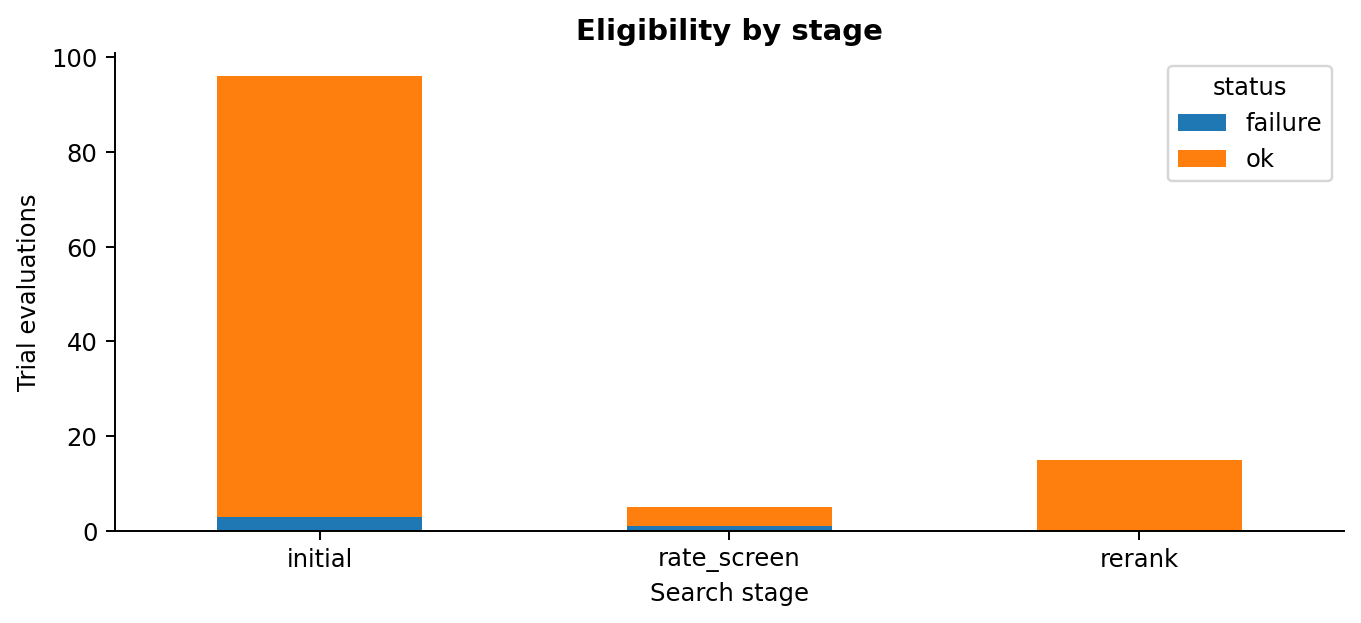

**Learning-rate screening on the controlled configuration (diagnostic only)**

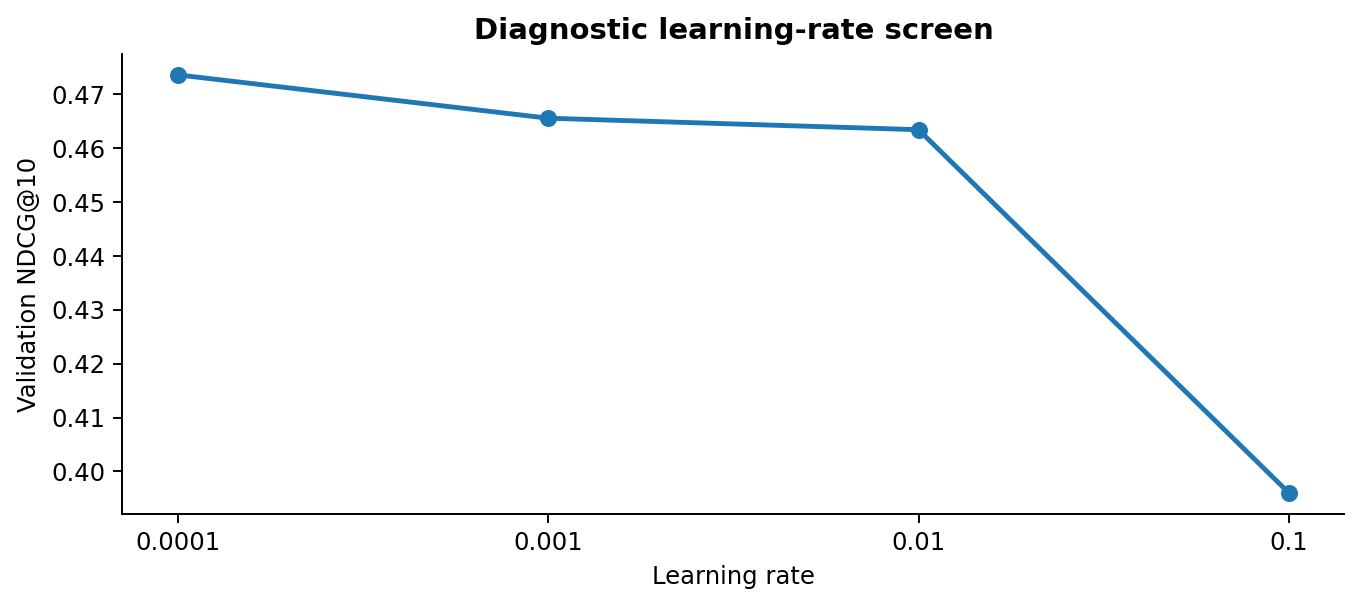

**Observed validation scores across the sampled aggregation choices; other settings vary**

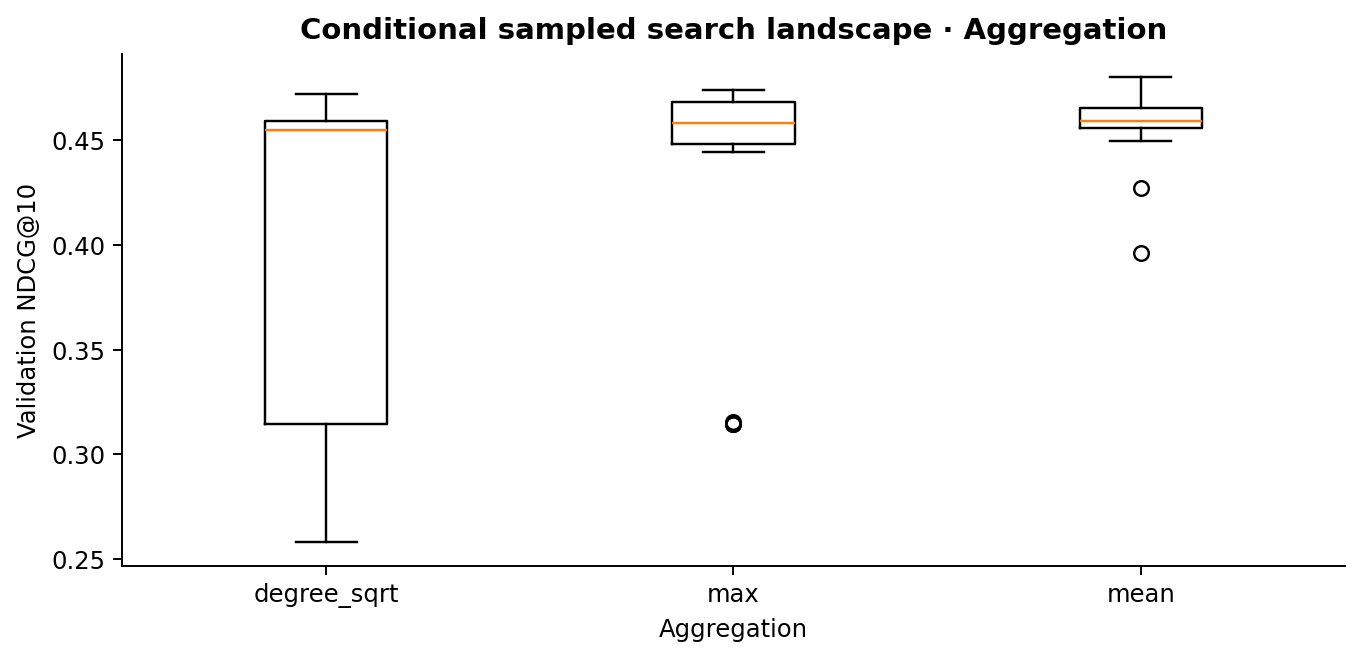

**Observed validation scores across the sampled propagation depth choices; other settings vary**

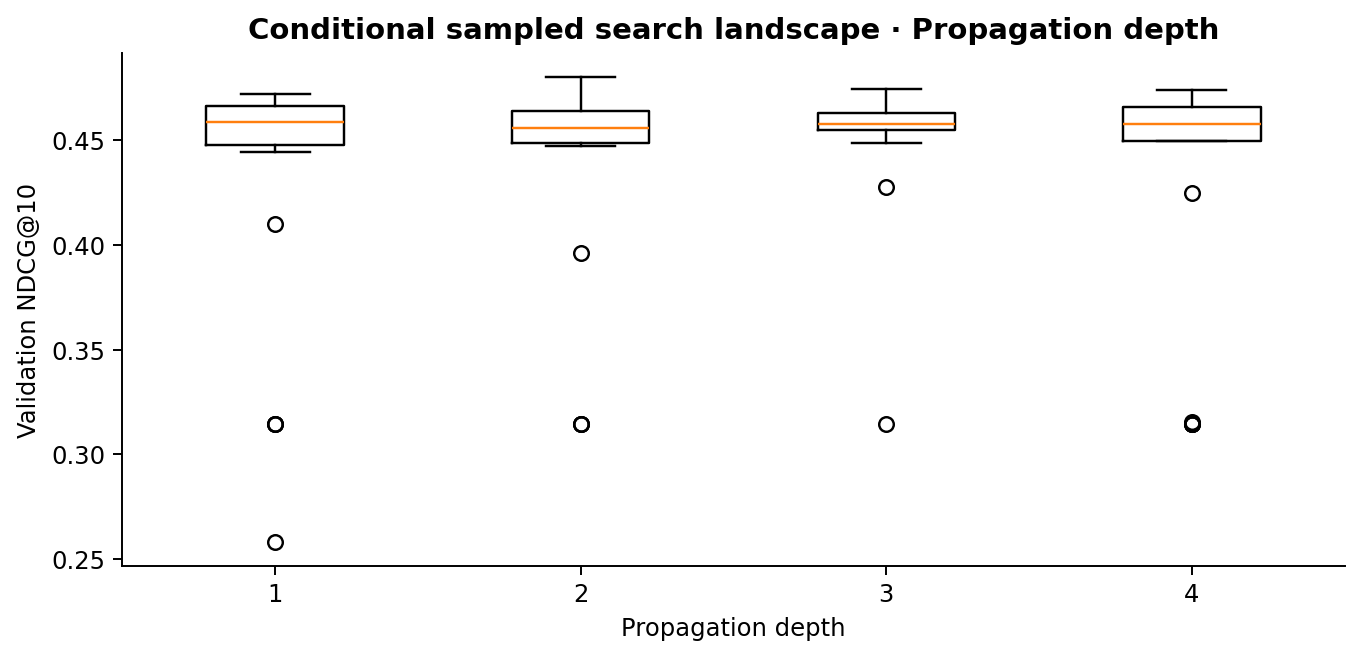

**Observed validation scores across the sampled learning rate choices; other settings vary**

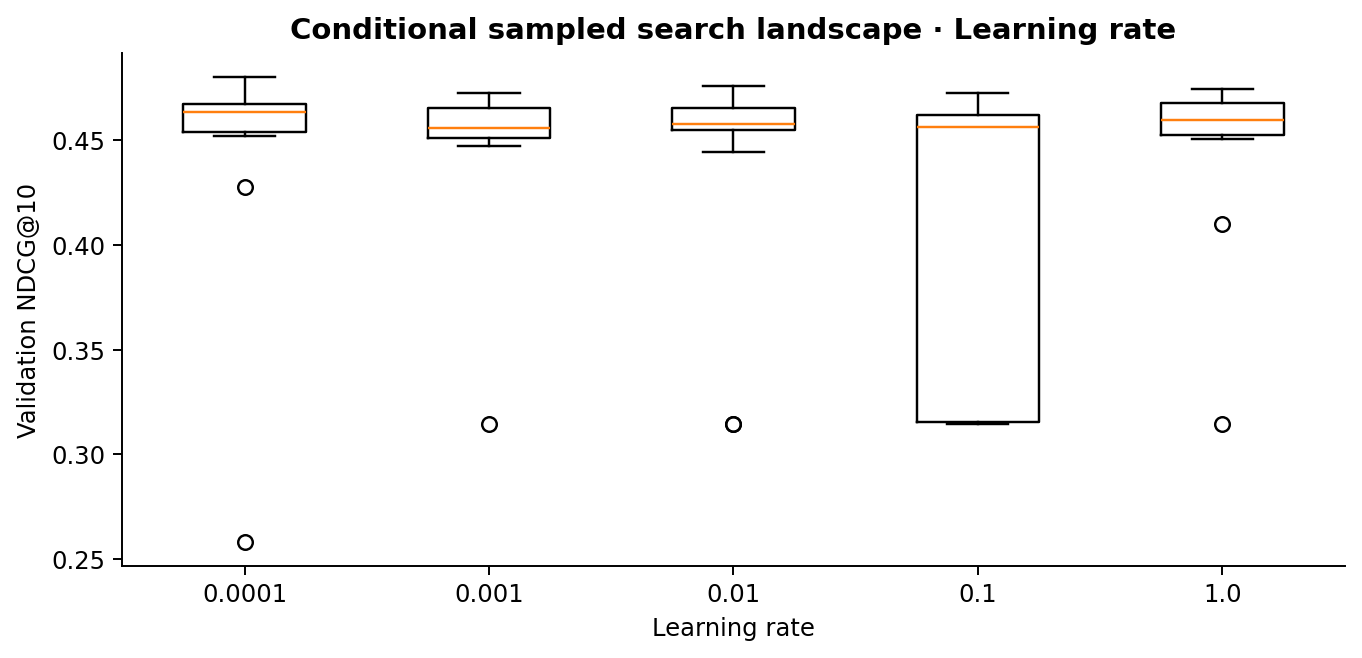

**Observed validation scores across the sampled hidden width choices; other settings vary**

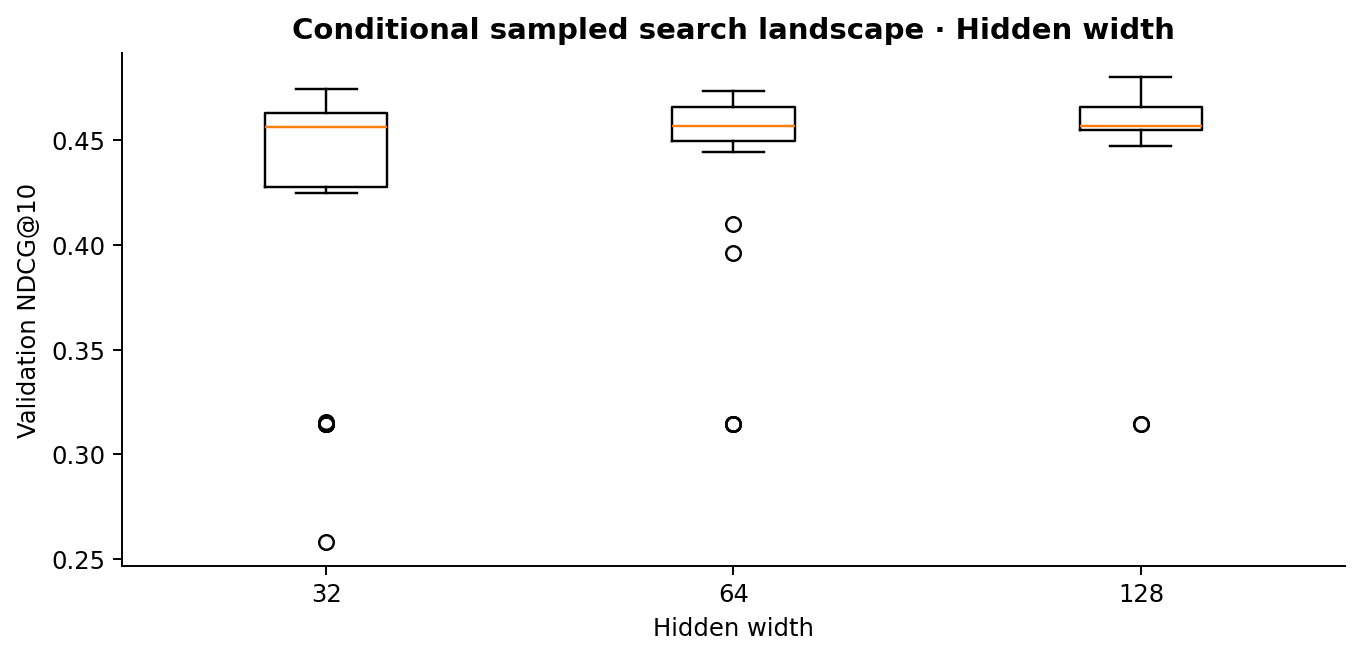

**Finalist re-ranking (validation only)**

,candidate,mean,sd,layers,aggregator,params
0,F1,0.4736,0.0044,4,max,110208
1,F2,0.4702,0.0012,2,mean,43328
2,F3,0.4670,0.0118,2,mean,51584
3,F4,0.4655,0.0100,3,max,9216
4,F5,0.4640,0.0090,2,mean,17664


**Validation finalists: seed mean ± sample SD; selected before test evaluation**

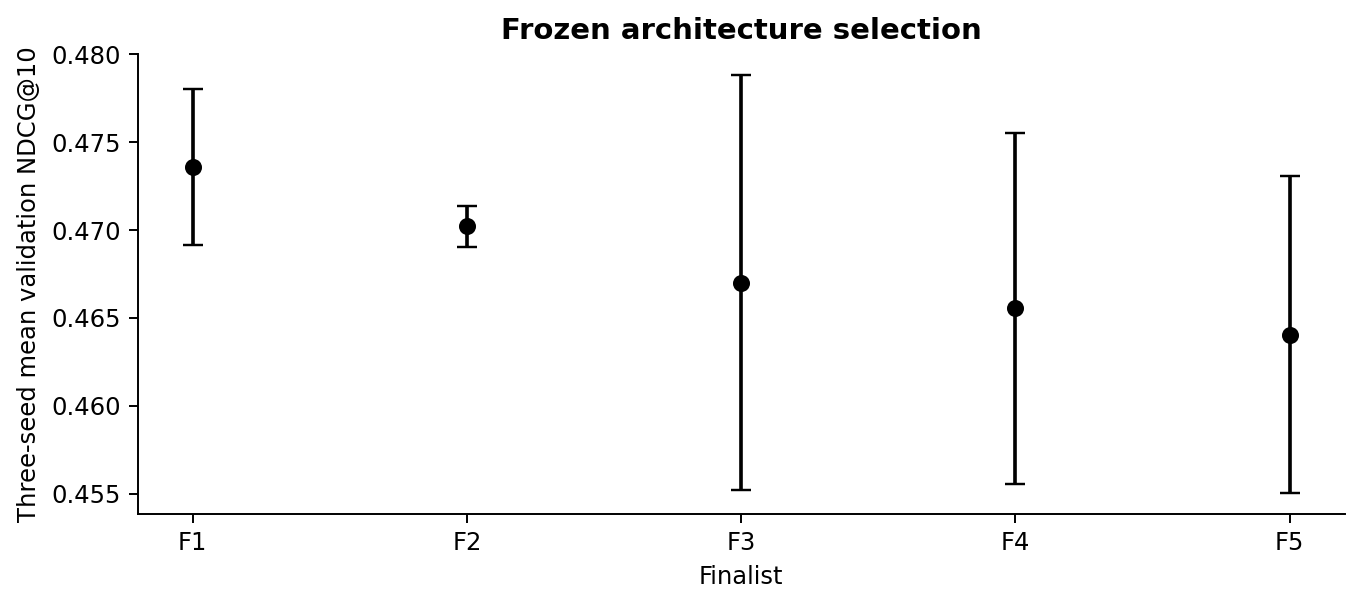

**Frozen tuned configuration**

,num_layers,aggregator,hidden_dim,embedding_dim,learning_rate,weight_decay,dropout,activation,residual,layernorm,l2_normalize,neigh_bias
0,4,max,128,32,1.0,0.0,0.1,gelu,True,True,False,True


#### Retail POS · monthly

**Search audit: all attempted trials**

,stage,status,trials
0,initial,failure,3
1,initial,ok,93
2,rate_screen,failure,1
3,rate_screen,ok,4
4,rerank,ok,15


**Search eligibility: successful and failed training evaluations**

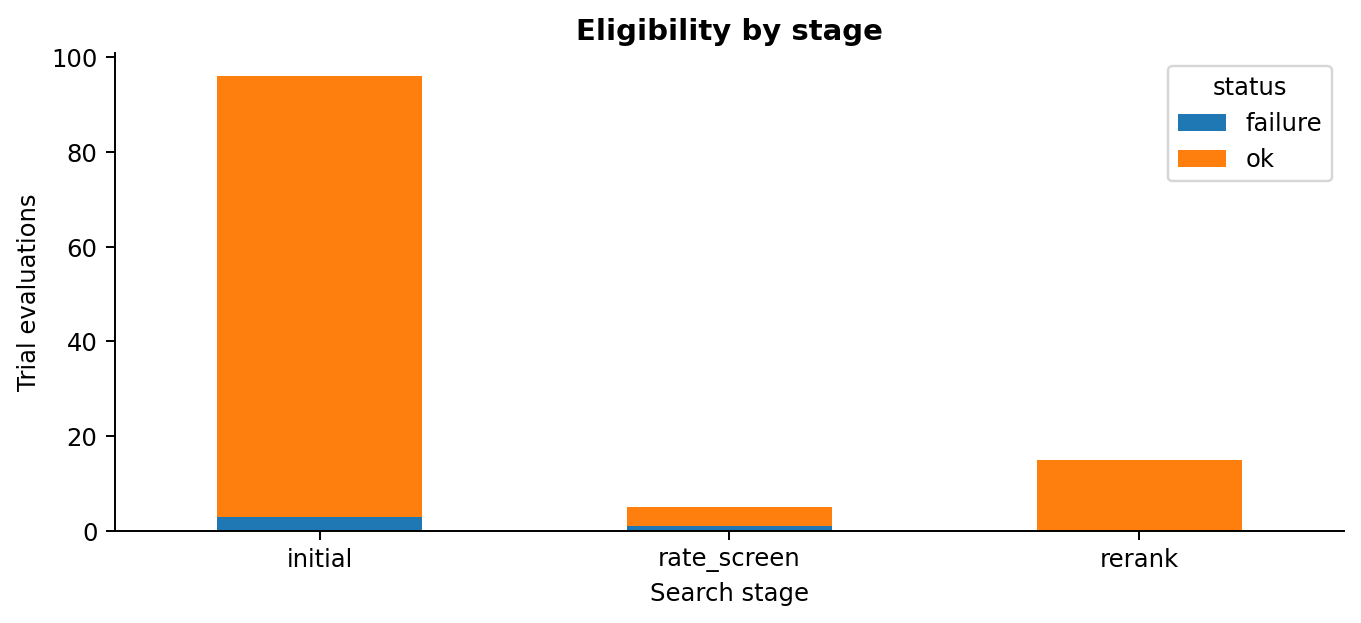

**Learning-rate screening on the controlled configuration (diagnostic only)**

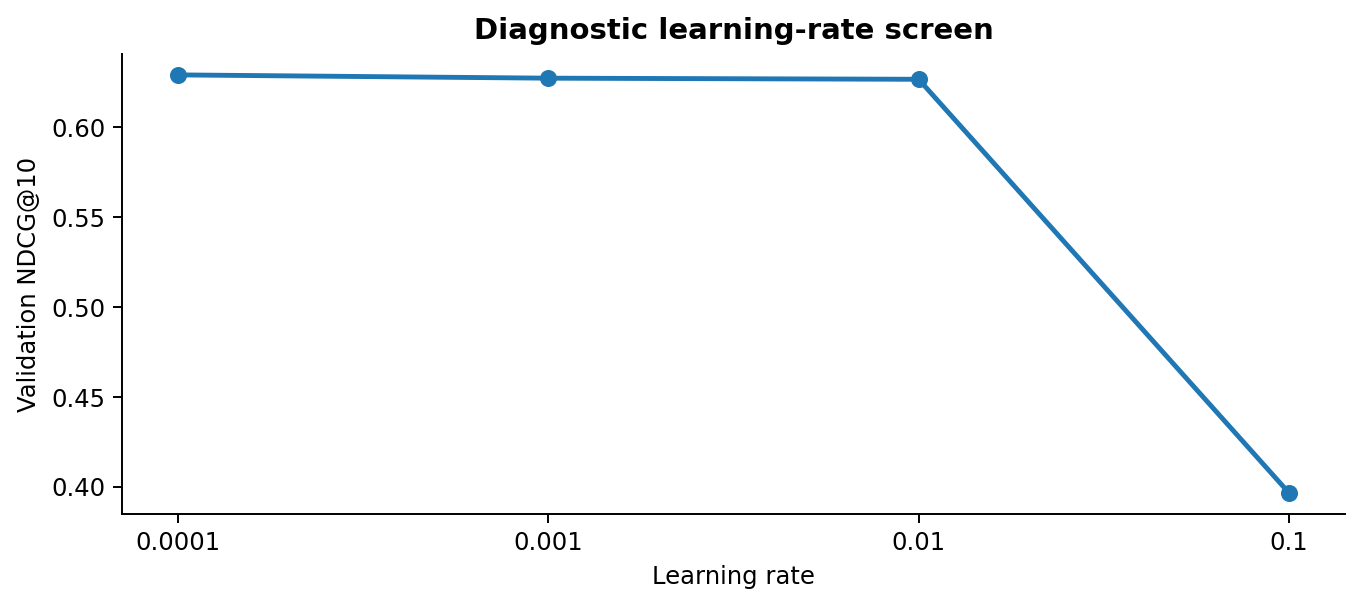

**Observed validation scores across the sampled aggregation choices; other settings vary**

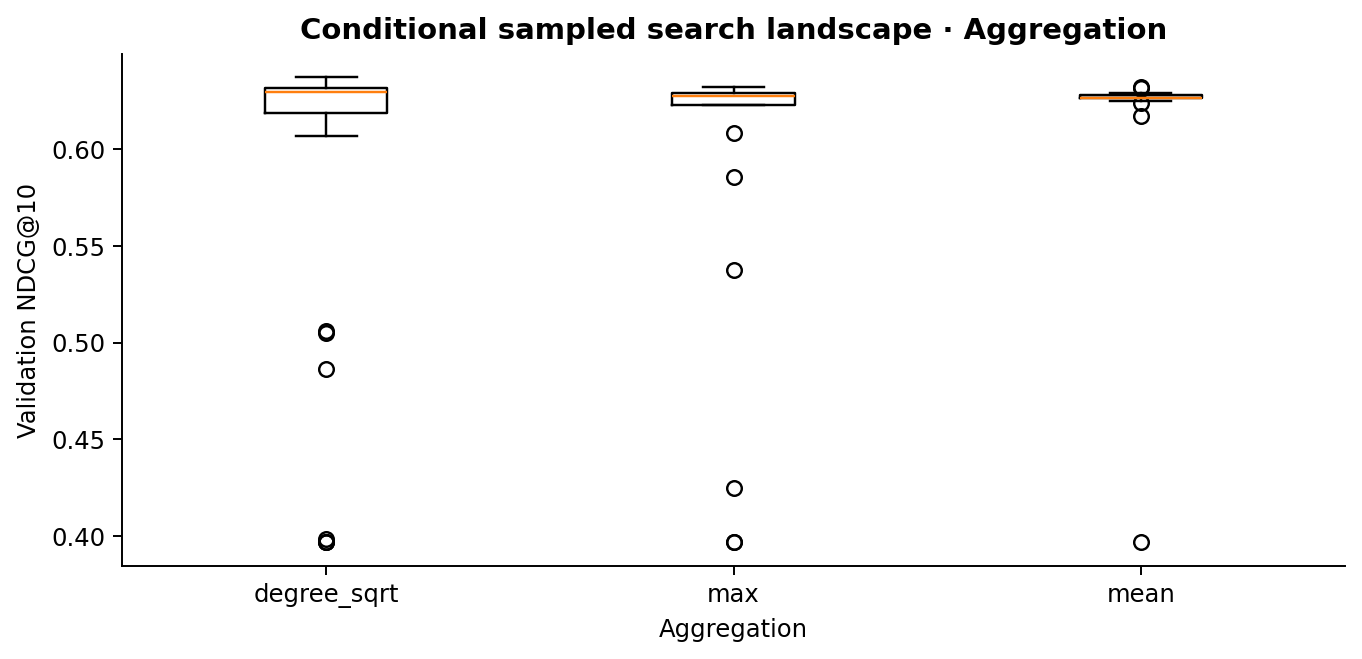

**Observed validation scores across the sampled propagation depth choices; other settings vary**

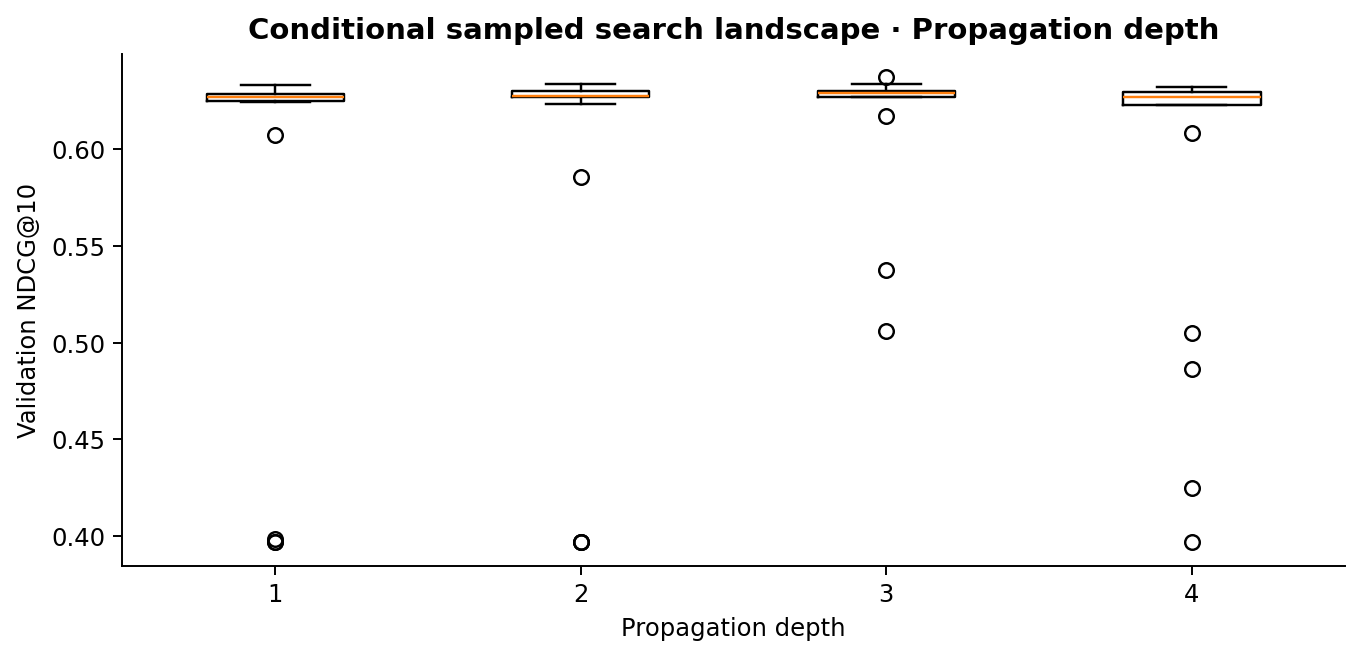

**Observed validation scores across the sampled learning rate choices; other settings vary**

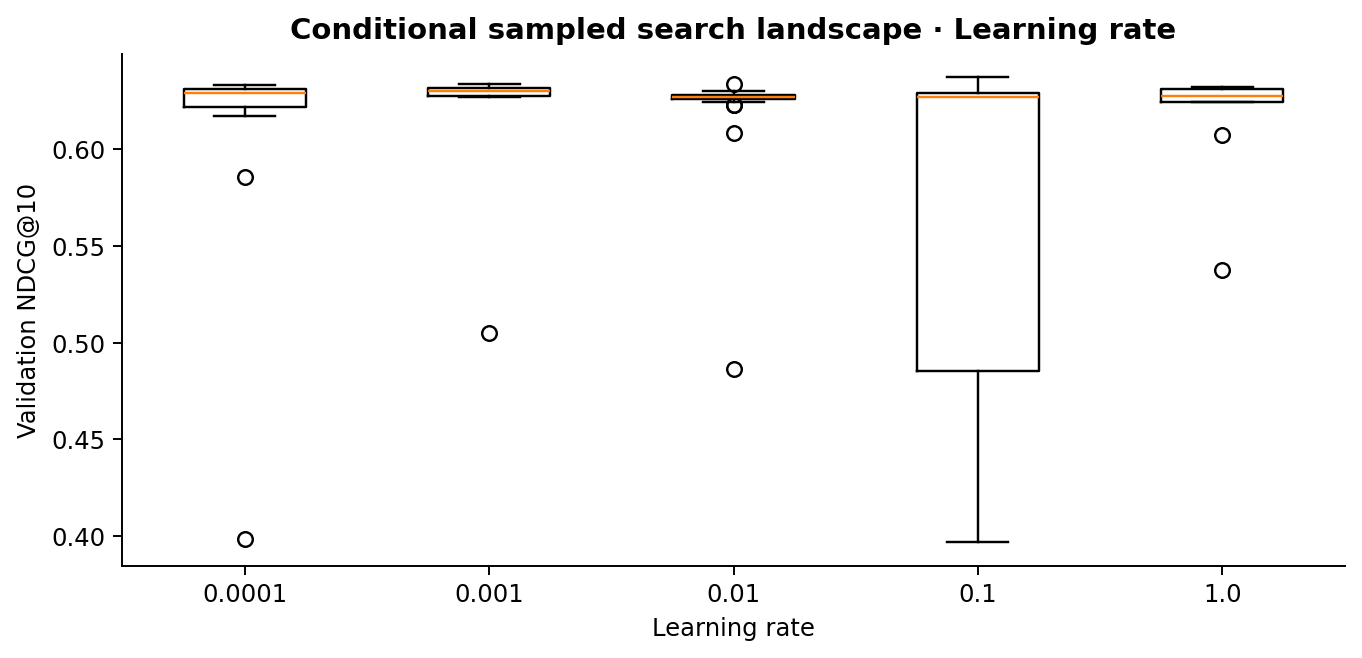

**Observed validation scores across the sampled hidden width choices; other settings vary**

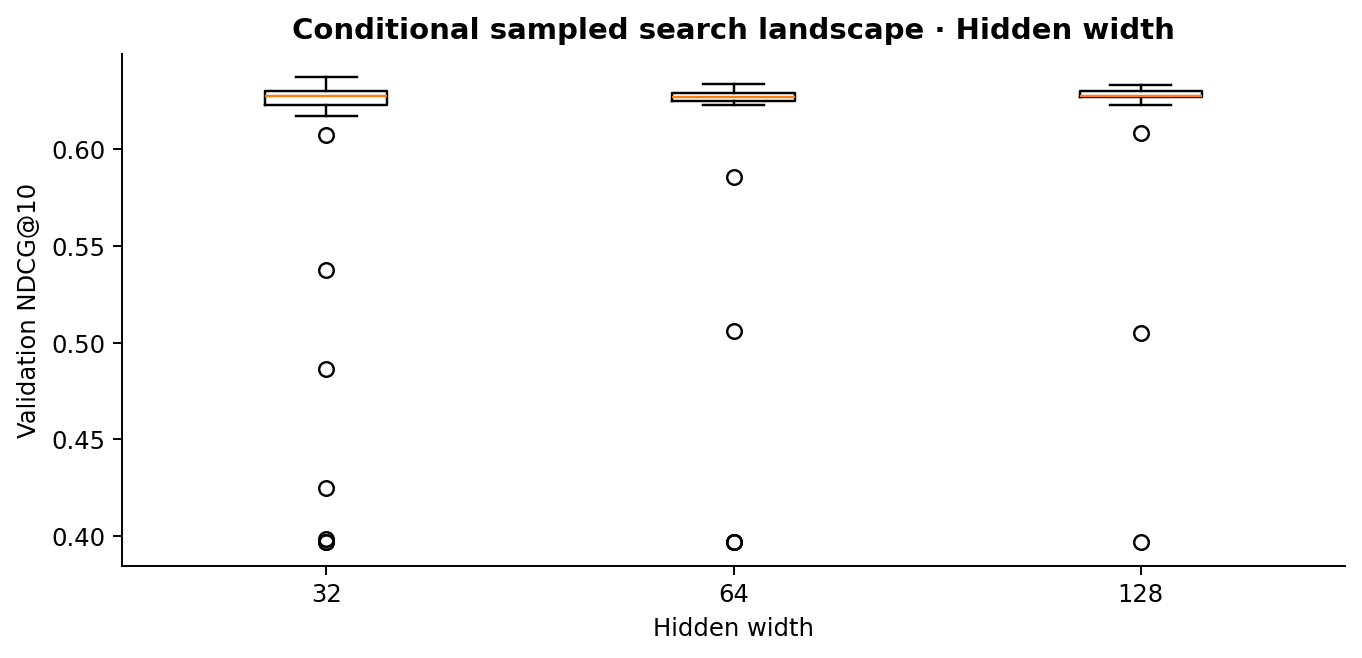

**Finalist re-ranking (validation only)**

,candidate,mean,sd,layers,aggregator,params
0,F1,0.6318,0.0011,1,degree_sqrt,18688
1,F2,0.6313,0.0023,3,degree_sqrt,13184
2,F3,0.6306,0.0054,1,degree_sqrt,2624
3,F4,0.6287,0.0053,2,degree_sqrt,17920
4,F5,0.6248,0.0127,3,degree_sqrt,6848


**Validation finalists: seed mean ± sample SD; selected before test evaluation**

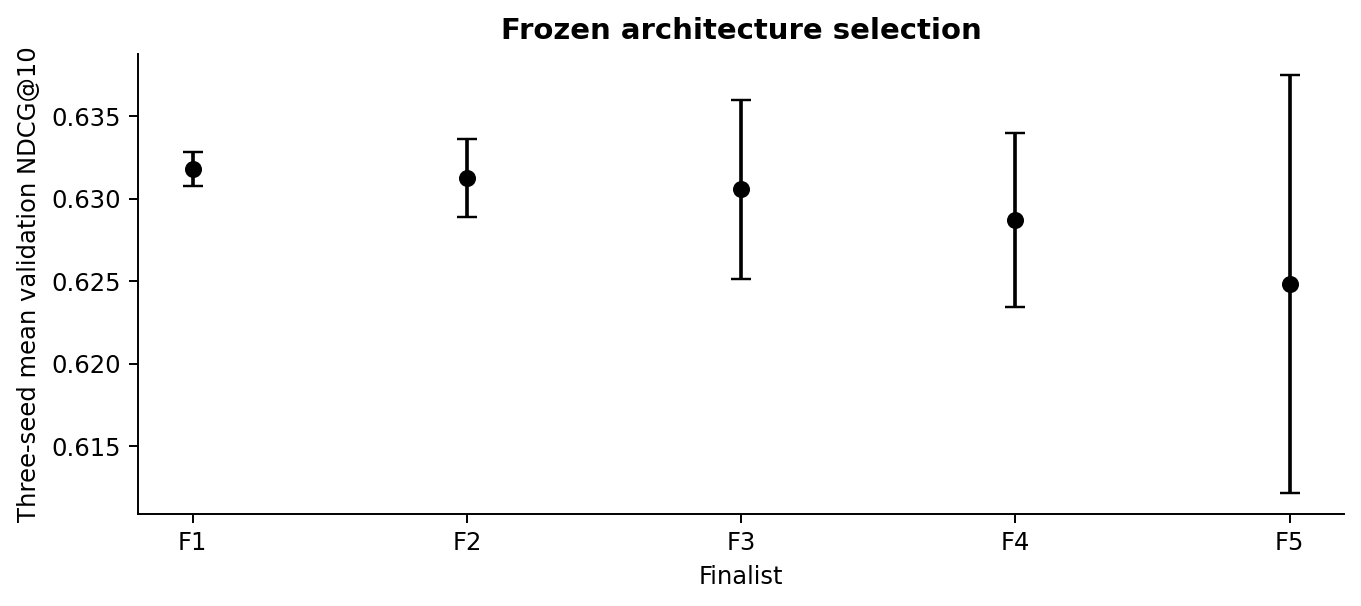

**Frozen tuned configuration**

,num_layers,aggregator,hidden_dim,embedding_dim,learning_rate,weight_decay,dropout,activation,residual,layernorm,l2_normalize,neigh_bias
0,1,degree_sqrt,128,64,0.0001,0.0,0.25,relu,False,True,True,True


In [ ]:
for ds in DATASETS:
    ds_header(ds)
    p=OUT/'search'/ds/'trials.csv'
    if not p.exists():
        display(NotebookMarkdown('Search trial table unavailable; inspect the frozen selection manifest.'))
        continue
    t=pd.read_csv(p)
    t['is_valid']=(t.status=='ok') & pd.to_numeric(t.validation_NDCG10,errors='coerce').notna()
    numeric_table(t.groupby(['stage','status'],dropna=False).size().rename('trials').reset_index(),
                  'Search audit: all attempted trials')
    counts=t.groupby(['stage','status']).size().unstack(fill_value=0)
    fig,ax=plt.subplots(figsize=(8,3.8));counts.plot(kind='bar',stacked=True,ax=ax)
    ax.set(xlabel='Search stage',ylabel='Trial evaluations',title='Eligibility by stage')
    ax.tick_params(axis='x',rotation=0)
    chapter_figure(fig,ds,'09_hyperparameter_search',f'{ds}_hpo_trial_status',
                   'Search eligibility: successful and failed training evaluations','search/*/trials.csv')
    r=t[(t.stage=='rate_screen') & t.is_valid].sort_values('learning_rate')
    fig,ax=plt.subplots(figsize=(8,3.7))
    if len(r):
        ax.plot(np.arange(len(r)),r.validation_NDCG10,marker='o',lw=2)
        ax.set_xticks(np.arange(len(r)),[f'{x:g}' for x in r.learning_rate])
    else:plot_empty(ax,'No successful rate-screen trials')
    ax.set(xlabel='Learning rate',ylabel='Validation NDCG@10',title='Diagnostic learning-rate screen')
    chapter_figure(fig,ds,'09_hyperparameter_search',f'{ds}_hpo_learning_rate_screen',
                   'Learning-rate screening on the controlled configuration (diagnostic only)')
    init=t[(t.stage=='initial')&t.is_valid]
    for key,label in [('aggregator','Aggregation'),('num_layers','Propagation depth'),
                      ('learning_rate','Learning rate'),('hidden_dim','Hidden width')]:
        fig,ax=plt.subplots(figsize=(8,4))
        groups=[(str(v),z.validation_NDCG10.dropna().to_numpy()) for v,z in init.groupby(key,dropna=False)]
        groups=[(a,b) for a,b in groups if len(b)]
        if groups:
            ax.boxplot([v for _,v in groups],tick_labels=[k for k,_ in groups],showmeans=False)
        else:plot_empty(ax,'No eligible initial trials')
        ax.set(xlabel=label,ylabel='Validation NDCG@10',title=f'Conditional sampled search landscape · {label}')
        chapter_figure(fig,ds,'09_hyperparameter_search',f'{ds}_hpo_{key}',
                       f'Observed validation scores across the sampled {label.lower()} choices; other settings vary')
    sel=read_json(OUT/'search'/ds/'selection.json') if (OUT/'search'/ds/'selection.json').exists() else None
    if sel:
        f=pd.DataFrame([{'candidate':f'F{i+1}','mean':x['mean'],'sd':x['sd'],
                 'layers':x['config']['num_layers'],'aggregator':x['config']['aggregator'],
                 'params':x['parameters']} for i,x in enumerate(sel['finalists'])])
        numeric_table(f,'Finalist re-ranking (validation only)')
        fig,ax=plt.subplots(figsize=(8,3.7));x=np.arange(len(f))
        ax.errorbar(x,f['mean'],yerr=f['sd'].fillna(0),fmt='o',color='black',ecolor='black',capsize=4)
        ax.set_xticks(x,f.candidate);ax.set(xlabel='Finalist',ylabel='Three-seed mean validation NDCG@10',
             title='Frozen architecture selection')
        chapter_figure(fig,ds,'09_hyperparameter_search',f'{ds}_hpo_finalists',
                       'Validation finalists: seed mean ± sample SD; selected before test evaluation')
    numeric_table(pd.DataFrame([FROZEN['datasets'][ds]['GraphSAGE-Tuned']]),'Frozen tuned configuration')

## 04 · Train the two headline models and interrogate learning dynamics

**Question.** Do Controlled and Tuned GraphSAGE converge reliably, and does validation ranking quality peak at the same epoch as the classification objective?

The selected configurations are now frozen. Headline training uses three final seeds in the exhaustive profile (one in smoke). Each checkpoint is chosen by **best validation NDCG@10**, and the result is replay-checked. The following figures are based on *recorded epoch histories*, not interpolated or synthetic loss curves.

**Timing integrity.** Each final model and ablation seed now reports time for model initialization, optimisation, epoch-wise training/validation monitoring, total fit, checkpoint verification/diagnostics, and a separately timed held-out forward pass. CUDA is synchronised around timed phases. Warmup forward passes are excluded. Preprocessing is measured per method once, not attributed to every seed. A separate HPO total is included to avoid misrepresenting model-selection cost as final training time.


In [ ]:
def rewire(s,seed,repeats=3):
    rng=np.random.default_rng(int(seed))
    e=s['edge_index_bipartite'].copy();m=e.shape[1];n=len(s['customer_features'])
    keys=set(zip(e[0].tolist(),e[1].tolist()))
    success=0
    if m>=2:
        for _ in range(m*repeats):
            a,b=rng.choice(m,2,replace=False)
            ua,ca=e[:,a];ub,cb=e[:,b]
            if ua==ub or ca==cb or (int(ua),int(cb)) in keys or (int(ub),int(ca)) in keys:continue
            keys.remove((int(ua),int(ca)));keys.remove((int(ub),int(cb)))
            keys.add((int(ua),int(cb)));keys.add((int(ub),int(ca)))
            e[1,a]=cb;e[1,b]=ca;success+=1
    z=dict(s);z['edge_index_bipartite']=e
    z['edge_index']=np.concatenate((np.stack((e[0],e[1]+n)),np.stack((e[1]+n,e[0]))),axis=1)
    assert np.array_equal(np.bincount(e[0],minlength=n),np.bincount(s['edge_index_bipartite'][0],minlength=n))
    assert np.array_equal(np.bincount(e[1],minlength=17),np.bincount(s['edge_index_bipartite'][1],minlength=17))
    return z,dict(attempts=m*repeats,successful_swaps=success,success_fraction=success/max(m*repeats,1))

def ablation_plan(control,tuned):
    if PROFILE=='smoke':return [('NoMessages',dict(control),'nomessages'),
                                ('NoCategoryFeatures',dict(control),'nocategory')]
    result=[('NoMessages',dict(control),'nomessages'),
       ('NoCustomerFeatures',dict(control),'nocustomer'),
       ('NoCategoryFeatures',dict(control),'nocategory'),
       ('NoNodeFeatures',dict(control),'nonode')]
    for L in (1,2,3,4):result.append((f'Depth{L}',dict(control,num_layers=L),'none'))
    for name,changes in [('Depth3Residual',dict(num_layers=3,residual=True)),
                          ('Depth3LayerNorm',dict(num_layers=3,layernorm=True)),
                          ('Depth3ResidualLayerNorm',dict(num_layers=3,residual=True,layernorm=True)),
                          ('SumAggregation',dict(aggregator='sum')),
                          ('SumWithoutNeighbourBias',dict(aggregator='sum',neigh_bias=False)),
                          ('MaxAggregation',dict(aggregator='max')),
                          ('DegreeSqrtAggregation',dict(aggregator='degree_sqrt'))]:
        result.append((name,dict(control,**changes),'none'))
    for i in range(B['rewire_repeats']):result.append((f'Rewired{i+1}',dict(control),f'rewire{i+1}'))
    return result

def transformed(ds,snaps,mask):
    if mask=='none':return snaps,[]
    records=[];audit=[]
    for s in snaps:
        t=dict(s)
        if mask=='nocustomer' or mask=='nonode':t['customer_features']=np.zeros_like(s['customer_features'])
        if mask=='nocategory' or mask=='nonode':t['category_features']=np.zeros_like(s['category_features'])
        if mask.startswith('rewire'):
            rep=int(mask[6:]);val=int(hashlib.sha256(f'{ds}|{s["target_month"]}|{rep}'.encode()).hexdigest()[:8],16)
            t,stats=rewire(t,val);audit.append(dict(target_month=s['target_month'],**stats))
        records.append(t)
    return records,audit

METRICS=[];STATUS=[];HISTORIES=[];MONTHS=[];INSTANCES=[];NOVELTY=[];DIVERSITY=[];LAYERS=[]
RUN_TIMING_ROWS=[];PREP_TIMING_ROWS=[]
def diagnostics(ds,method,seed,split,snaps,recs,model,disabled):
    for s,t in zip(snaps,recs):
        model.eval()
        with torch.no_grad():
            raw=model(t,disable_messages=disabled);diag=diagnose(raw)
            z,steps=model.encode(t,disable_messages=disabled,return_layers=True)
        scores=raw.cpu().numpy();y=s['labels'];n=len(y);ordered=order_scores(scores)
        row=dict(dataset=ds,method=method,seed=seed,split=split,target_month=s['target_month'])
        MONTHS.append(dict(**row,**ranking_metrics(y,scores),**diag))
        rm=instance_metrics(y,scores)
        ins=pd.DataFrame({**row,'customer_idx':s['eligible_customer_idx'],
            'historical_degree':s['eligible_history_degree'],'positive_categories':y.sum(axis=1)})
        for k,v in rm.items():ins[k]=v
        INSTANCES.append(ins)
        idx=np.empty_like(ordered);idx[np.arange(n)[:,None],ordered]=np.arange(1,18)
        cand=pd.DataFrame({**row,'customer_idx':np.repeat(s['eligible_customer_idx'],17),
             'category_idx':np.tile(np.arange(17),n),'label':y.ravel(),
             'score':scores.ravel(),'rank':idx.ravel(),
             'historical_link':s['eligible_history_pair_mask'].ravel(),
             'previous_period_link':s['eligible_previous_month_mask'].ravel()})
        save_csv(cand,OUT/f'predictions/{ds}/{method}/seed{seed}/{split}/{s["target_month"]}_candidates.csv.gz')
        for kind,mask in [('repeated',s['eligible_history_pair_mask'].astype(bool)),
                          ('novel',~s['eligible_history_pair_mask'].astype(bool))]:
            pos=(y.astype(bool)&mask).sum(axis=1);valid=pos>0
            rr=dict(**row,group=kind,group_customers=int(valid.sum()),positive_pairs=int(pos.sum()))
            for k in KS:
                pred=np.zeros_like(y,dtype=bool);pred[np.arange(n)[:,None],ordered[:,:k]]=1
                hits=(pred&mask&y.astype(bool)).sum(axis=1)
                rr[f'Recall@{k}']=float((hits[valid]/pos[valid]).mean()) if valid.any() else np.nan
            NOVELTY.append(rr)
        t10=ordered[:,:10]
        DIVERSITY.append(dict(**row,distinct_ordered_top10=len({tuple(v) for v in t10.tolist()}),
                   distinct_unordered_top10=len({tuple(sorted(v)) for v in t10.tolist()}),
                   customer_count=n,**diag))
        nu=len(s['customer_features'])
        for i,z in enumerate(steps):
            arr=z[:nu].detach().cpu().numpy()
            norms=np.linalg.norm(arr,axis=1)
            centred=arr-arr.mean(axis=0,keepdims=True)
            sv=np.linalg.svd(centred,compute_uv=False)
            p=sv/(sv.sum()+1e-12)
            eff=float(np.exp(-(p*np.log(p+1e-12)).sum()))
            LAYERS.append(dict(**row,layer=i,mean_norm=float(norms.mean()),effective_rank=eff,
                               p95_norm=float(np.quantile(norms,.95))))

def evaluate_variant(ds,method,cfg,snaps,mask='none',seeds=None,allow_all_failed=False):
    """Atomic per-seed evaluation with synchronised phase timings."""
    seeds=tuple(seeds or B['final_seeds'])
    disabled=(mask=='nomessages')
    sync_device();prep_t0=time.perf_counter()
    changed,audit=transformed(ds,snaps['train']+snaps['val']+snaps['test'],mask)
    L=len(snaps['train']);V=len(snaps['val'])
    st={'train':changed[:L],'val':changed[L:L+V],'test':changed[L+V:]}
    if audit:save_csv(pd.DataFrame(audit),OUT/f'diagnostics/{ds}/{method}_rewiring_audit.csv')
    records={key:to_tensors(value) for key,value in st.items()}
    sync_device();prep_elapsed=time.perf_counter()-prep_t0
    PREP_TIMING_ROWS.append(dict(dataset=ds,method=method,stage='feature_graph_setup',
                                 preparation_wall_seconds=prep_elapsed,
                                 snapshots=len(changed),device=str(DEVICE)))
    pw=float(INFO[ds]['loss']['primary_scalar_pos_weight'])
    for seed in seeds:
        sync_device();run_t0=time.perf_counter()
        cp=OUT/f'checkpoints/{ds}/{method}/seed{seed}.pt'
        lengths={key:len(globals()[key]) for key in
                 ('METRICS','HISTORIES','MONTHS','INSTANCES','NOVELTY','DIVERSITY','LAYERS')}
        fresh_metrics=[]
        cached=False;meta={};inference_seconds={};candidate_counts={}
        try:
            if cp.exists() and not FORCE_RERUN:
                model,meta=load_checkpoint(cfg,cp,seed)
                cached=True
                if bool(meta.get('disable_messages',False))!=bool(disabled):
                    raise ValueError('Checkpoint intervention mask mismatch')
                hp=OUT/f'histories/{ds}/{method}/seed{seed}.csv'
                hist=pd.read_csv(hp) if hp.exists() else pd.DataFrame()
            else:
                model,meta,hist=train_one(
                    cfg,records['train'],records['val'],pw,seed,
                    B['final_epochs'],B['final_patience'],cp,
                    OUT/f'histories/{ds}/{method}/seed{seed}.csv',
                    disable_messages=disabled)
            replay=verify_replay(model,cp,cfg,seed,records['val'],disable_messages=disabled)
            for split in ('val','test'):
                model.eval()
                # The warmup is excluded from measured inference duration.
                sync_device()
                if records[split]:
                    with torch.no_grad():
                        _=model(records[split][0],disable_messages=disabled)
                sync_device();t_forward=time.perf_counter()
                with torch.no_grad():
                    pred=[model(rec,disable_messages=disabled) for rec in records[split]]
                sync_device();inference_seconds[split]=time.perf_counter()-t_forward
                for out in pred:diagnose(out)
                ys=[rec['labels'].cpu().numpy().astype(np.uint8) for rec in records[split]]
                sc=[out.detach().cpu().numpy() for out in pred]
                candidate_counts[split]=sum(y.size for y in ys)
                outcome=ranking_metrics(np.concatenate(ys),np.concatenate(sc))
                fresh_metrics.append(dict(dataset=ds,method=method,seed=seed,
                    split=split,**outcome,best_epoch=meta['best_epoch'],
                    seconds=meta['seconds'],parameters=meta['parameters'],
                    replay_max_abs_difference=replay,
                    training_wall_seconds=meta.get('training_wall_seconds'),
                    fit_wall_seconds=meta.get('fit_wall_seconds'),
                    optimisation_seconds=meta.get('optimisation_seconds'),
                    model_initialisation_seconds=meta.get('model_initialisation_seconds'),
                    epochs_ran=meta.get('epochs_ran'),
                    inference_forward_wall_seconds=inference_seconds[split],
                    candidate_pairs=candidate_counts[split],
                    trained_this_execution=not cached))
                for snap,record in zip(st[split],records[split]):
                    diagnostics(ds,method,seed,split,[snap],[record],model,disabled)
            # Only fully verified seeds contribute to aggregate metrics.
            METRICS.extend(fresh_metrics)
            if not hist.empty:HISTORIES.append(hist.assign(dataset=ds,method=method))
            status=dict(dataset=ds,method=method,seed=seed,status='ok',error='')
        except Exception as exc:
            for key,n in lengths.items():del globals()[key][n:]
            stale=OUT/f'predictions/{ds}/{method}/seed{seed}'
            if stale.exists():shutil.rmtree(stale)
            status=dict(dataset=ds,method=method,seed=seed,status='failure',
                        error=repr(exc),traceback=traceback.format_exc(limit=6))
        sync_device();end_to_end=time.perf_counter()-run_t0
        # A failed seed is still counted as resource consumed, but unknown
        # phase durations remain NA and are not counted as successes.
        row=dict(dataset=ds,method=method,seed=int(seed),
            status=status['status'],trained_this_execution=not cached,
            device=str(DEVICE),gpu_name=HARDWARE.get('gpu_name'),
            epochs_ran=meta.get('epochs_ran'),best_epoch=meta.get('best_epoch'),
            parameters=meta.get('parameters'),
            training_wall_seconds=meta.get('training_wall_seconds'),
            fit_wall_seconds=meta.get('fit_wall_seconds'),
            model_initialisation_seconds=meta.get('model_initialisation_seconds'),
            optimisation_seconds=meta.get('optimisation_seconds'),
            training_monitor_seconds=meta.get('training_monitor_seconds'),
            validation_monitor_seconds=meta.get('validation_monitor_seconds'),
            mean_epoch_wall_seconds=meta.get('mean_epoch_wall_seconds'),
            training_peak_cuda_memory_bytes=meta.get('training_peak_cuda_memory_bytes'),
            training_peak_cuda_memory_mib=(
                meta['training_peak_cuda_memory_bytes']/2**20
                if meta.get('training_peak_cuda_memory_bytes') is not None else np.nan),
            validation_forward_seconds=inference_seconds.get('val'),
            test_forward_seconds=inference_seconds.get('test'),
            test_candidate_pairs=candidate_counts.get('test'),
            test_pairs_per_second=(
                candidate_counts['test']/inference_seconds['test']
                if inference_seconds.get('test',0)>0 else np.nan),
            seed_pipeline_wall_seconds=end_to_end,
            checkpoint_reused=cached,error=status.get('error',''))
        RUN_TIMING_ROWS.append(row)
        STATUS.append(dict(**status,training_wall_seconds=meta.get('training_wall_seconds'),
                           test_forward_seconds=inference_seconds.get('test'),
                           pipeline_wall_seconds=end_to_end,
                           checkpoint_reused=cached))
        save_csv(pd.DataFrame(STATUS),OUT/'tables/seed_status.csv')
        save_csv(pd.DataFrame(RUN_TIMING_ROWS),OUT/'tables/run6_runtime_per_seed.csv')
        print('FINAL',ds,method,seed,status['status'],
              'train_s=',row['training_wall_seconds'],
              'test_forward_s=',row['test_forward_seconds'],
              status.get('error','')[:120],flush=True)
    passed=sum(r['status']=='ok' and r['dataset']==ds and
               r['method']==method and r['seed'] in seeds for r in STATUS)
    if passed==0:
        message=f'{ds}/{method}: 0/{len(seeds)} successful seeds; see tables/seed_status.csv'
        if allow_all_failed:print('[FAILED ABLATION - CONTINUING]',message,flush=True)
        else:raise RuntimeError(message)
    elif passed<len(seeds):
        print('[PARTIAL SUCCESS]',ds,method,f'{passed}/{len(seeds)} seeds',flush=True)
    return passed


In [ ]:
# Headline models only. All downstream chapters can now inspect their histories.
for ds in DATASETS:
    sn=get_splits(ds,('train','val','test'))
    frozen=FROZEN['datasets'][ds]
    for method in ('GraphSAGE-Controlled','GraphSAGE-Tuned'):
        evaluate_variant(ds,method,frozen[method],sn)

HEADLINE=pd.DataFrame(METRICS)
HISTORY=pd.concat(HISTORIES,ignore_index=True) if HISTORIES else pd.DataFrame()
assert not HEADLINE.empty,'No successful headline evaluations'
print('Headline evaluations completed. Ablations will run only after the headline chapters.')

FINAL euromart GraphSAGE-Controlled 42 ok train_s= 0.7352513050000198 test_forward_s= 0.000721830999964368 
FINAL euromart GraphSAGE-Controlled 43 ok train_s= 0.8026063439999689 test_forward_s= 0.0006992200000013327 
FINAL euromart GraphSAGE-Controlled 44 ok train_s= 0.8071734250000873 test_forward_s= 0.0006620999999995547 
FINAL euromart GraphSAGE-Tuned 42 ok train_s= 1.6395934280001256 test_forward_s= 0.00185481100004381 
FINAL euromart GraphSAGE-Tuned 43 ok train_s= 1.643389997999975 test_forward_s= 0.0017857799999774215 
FINAL euromart GraphSAGE-Tuned 44 ok train_s= 2.0111405849999073 test_forward_s= 0.0017647799999167546 
FINAL retail_pos GraphSAGE-Controlled 42 ok train_s= 0.5159306660000311 test_forward_s= 0.0004861999999548061 
FINAL retail_pos GraphSAGE-Controlled 43 ok train_s= 0.5511249660000885 test_forward_s= 0.0004959399999506786 
FINAL retail_pos GraphSAGE-Controlled 44 ok train_s= 0.48183099599998513 test_forward_s= 0.0004944499999055552 
FINAL retail_pos GraphSAGE-Tune

### 04.1 · BCE, validation ranking and gradient trajectories

Solid and dashed traces denote training and validation quantities respectively. Each seed is plotted separately, with a marker at its selected checkpoint epoch. Remember that a decrease in BCE does *not* necessarily improve the top-10 ranking; the checkpoint marker refers to the validation NDCG maximum. Gradient plots use pre-clipping norms and help distinguish genuinely stable optimisation from apparent stability induced only by clipping.

**Numerical policy:** Nonfinite values, nonfinite losses/gradients, and failed checkpoint replay are fatal. Extreme yet finite logits are reported with a saturation flag and are not automatically censored. No test information is used for hyperparameter selection.


#### EuroMart · quarterly

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

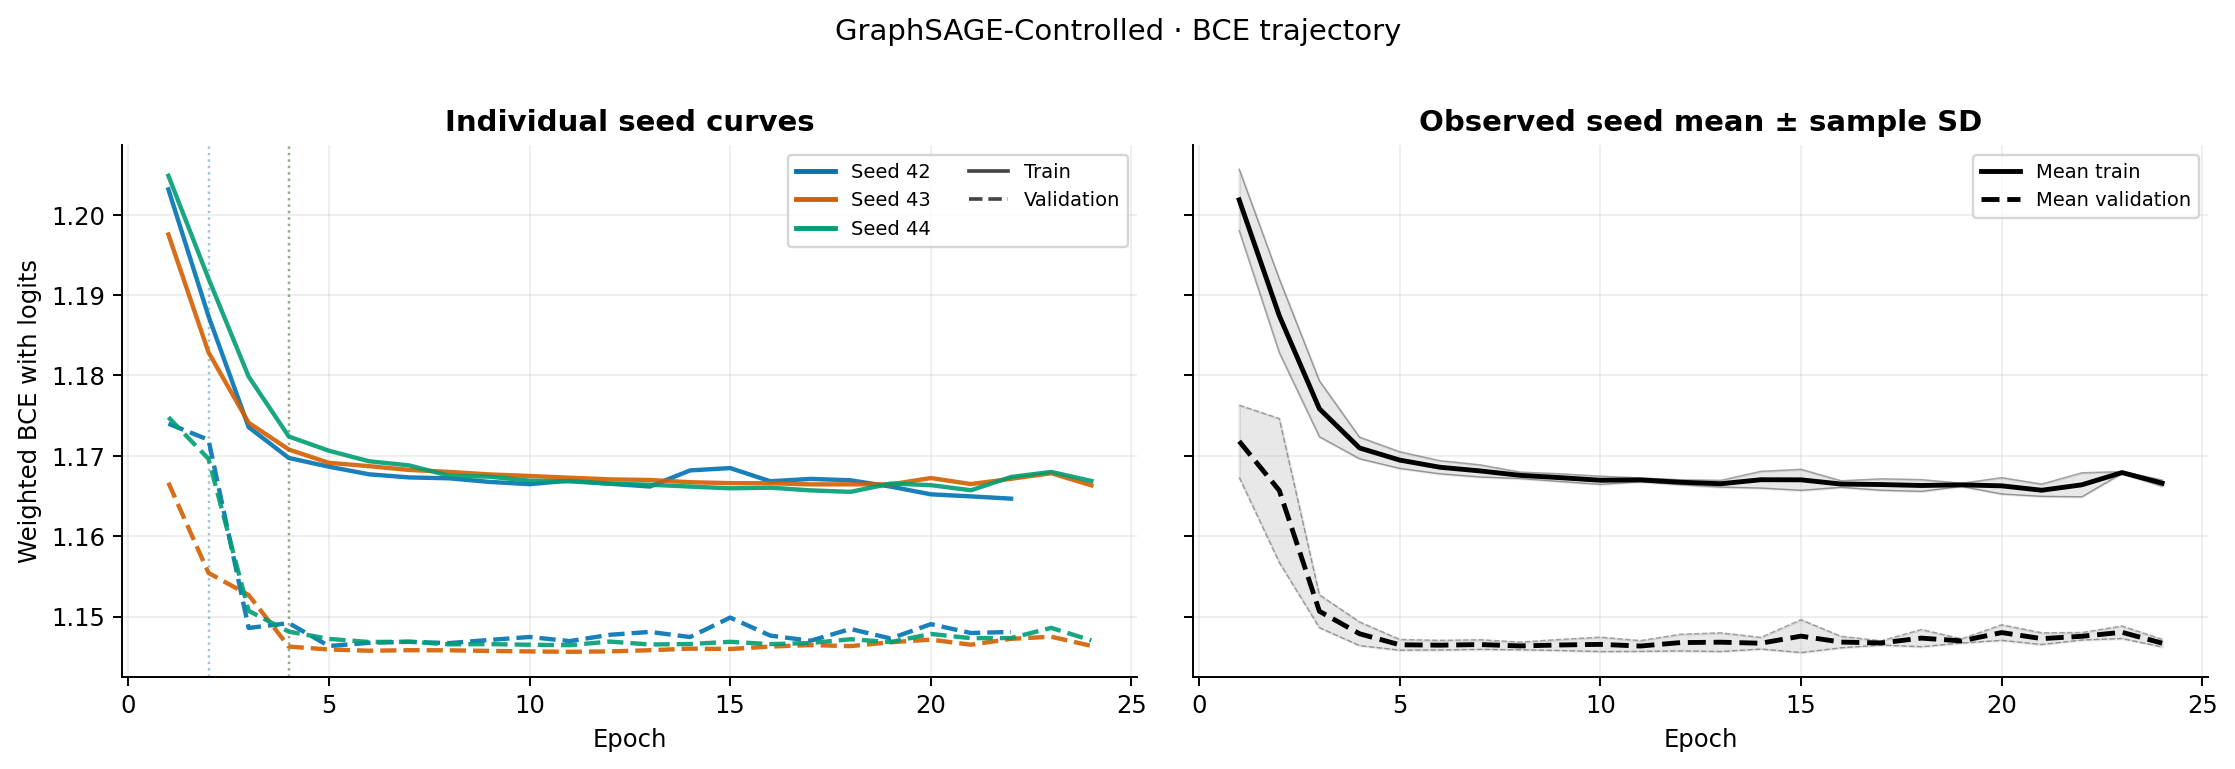

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

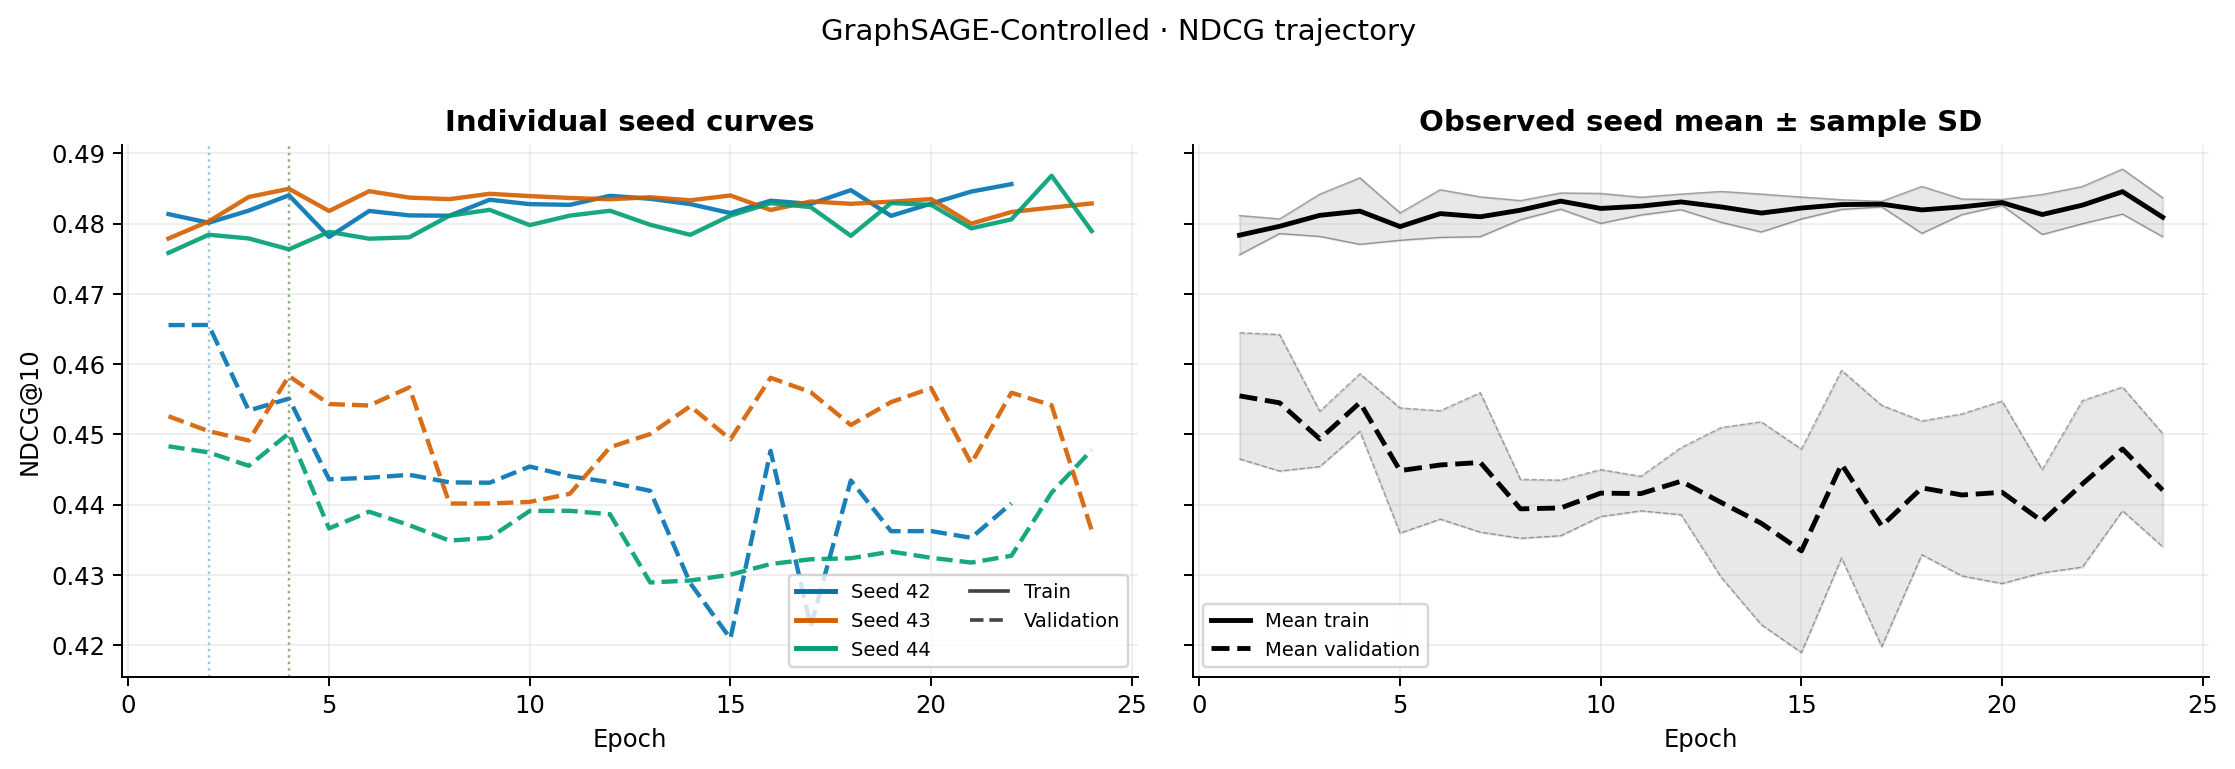

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = mean/max gradient; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

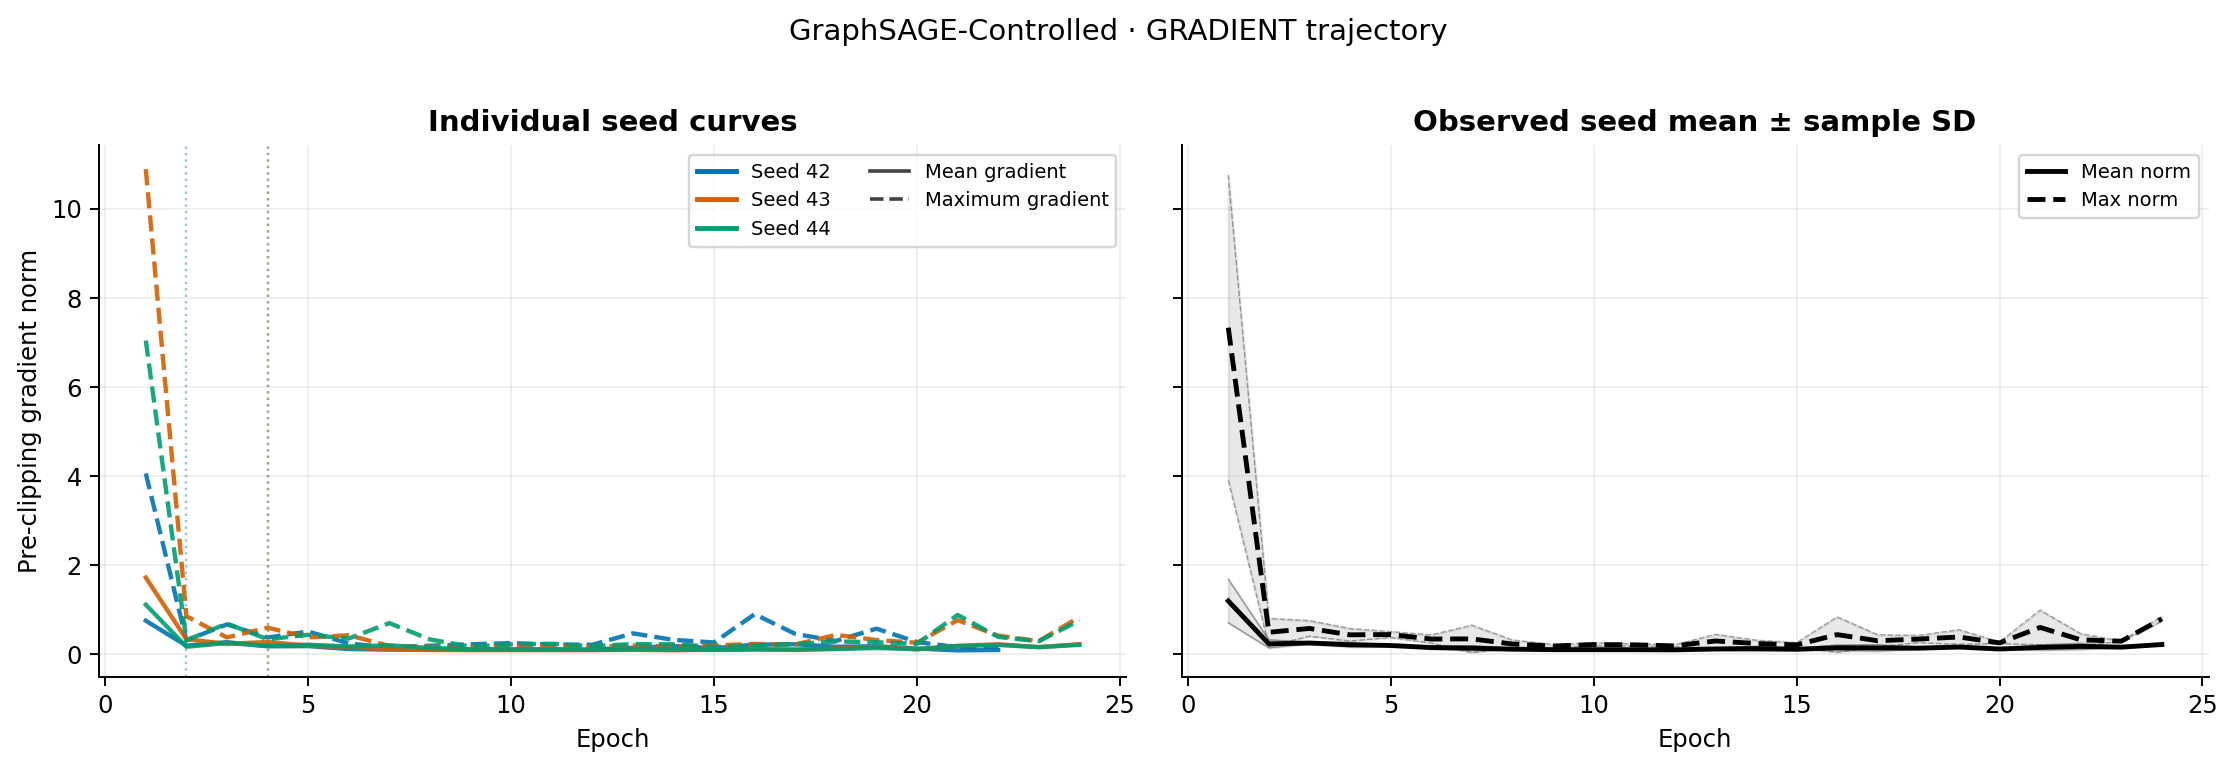

**GraphSAGE-Controlled: optimisation and selected checkpoint epochs**

,seed,epochs,minimum_val_BCE,maximum_val_NDCG10,selected_epoch
0,42,22,1.1463,0.4656,2
1,43,24,1.1456,0.4583,4
2,44,24,1.1464,0.4502,4


**GraphSAGE-Tuned: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

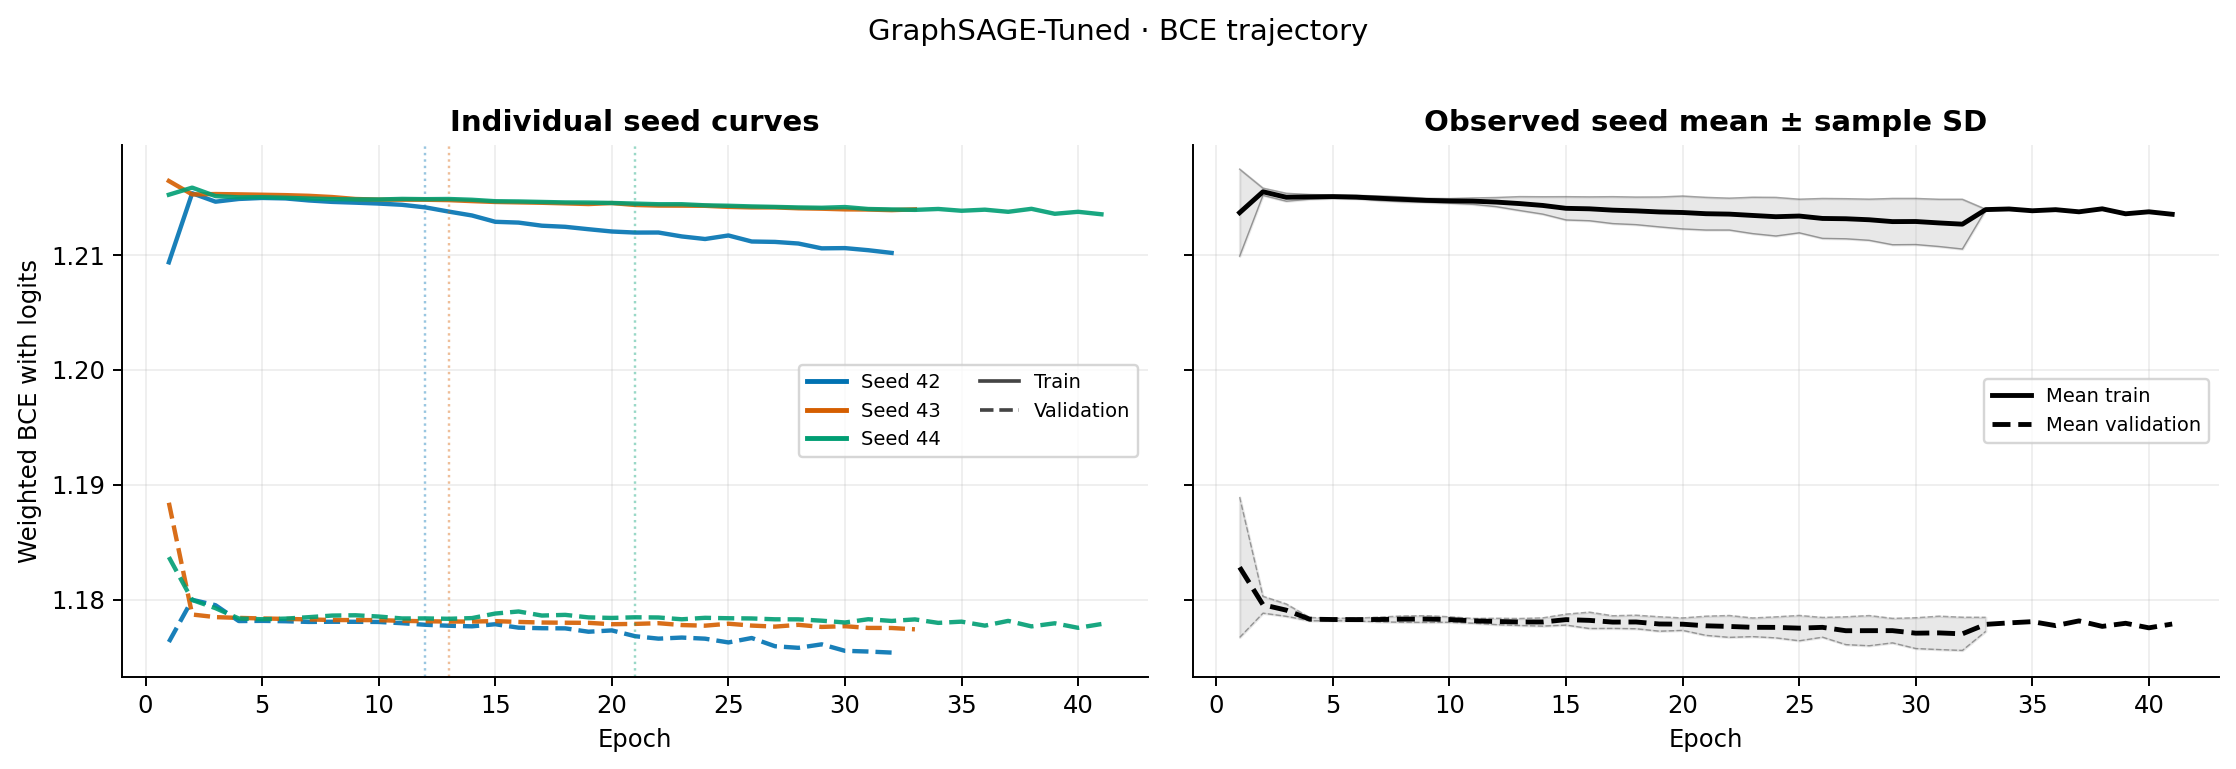

**GraphSAGE-Tuned: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

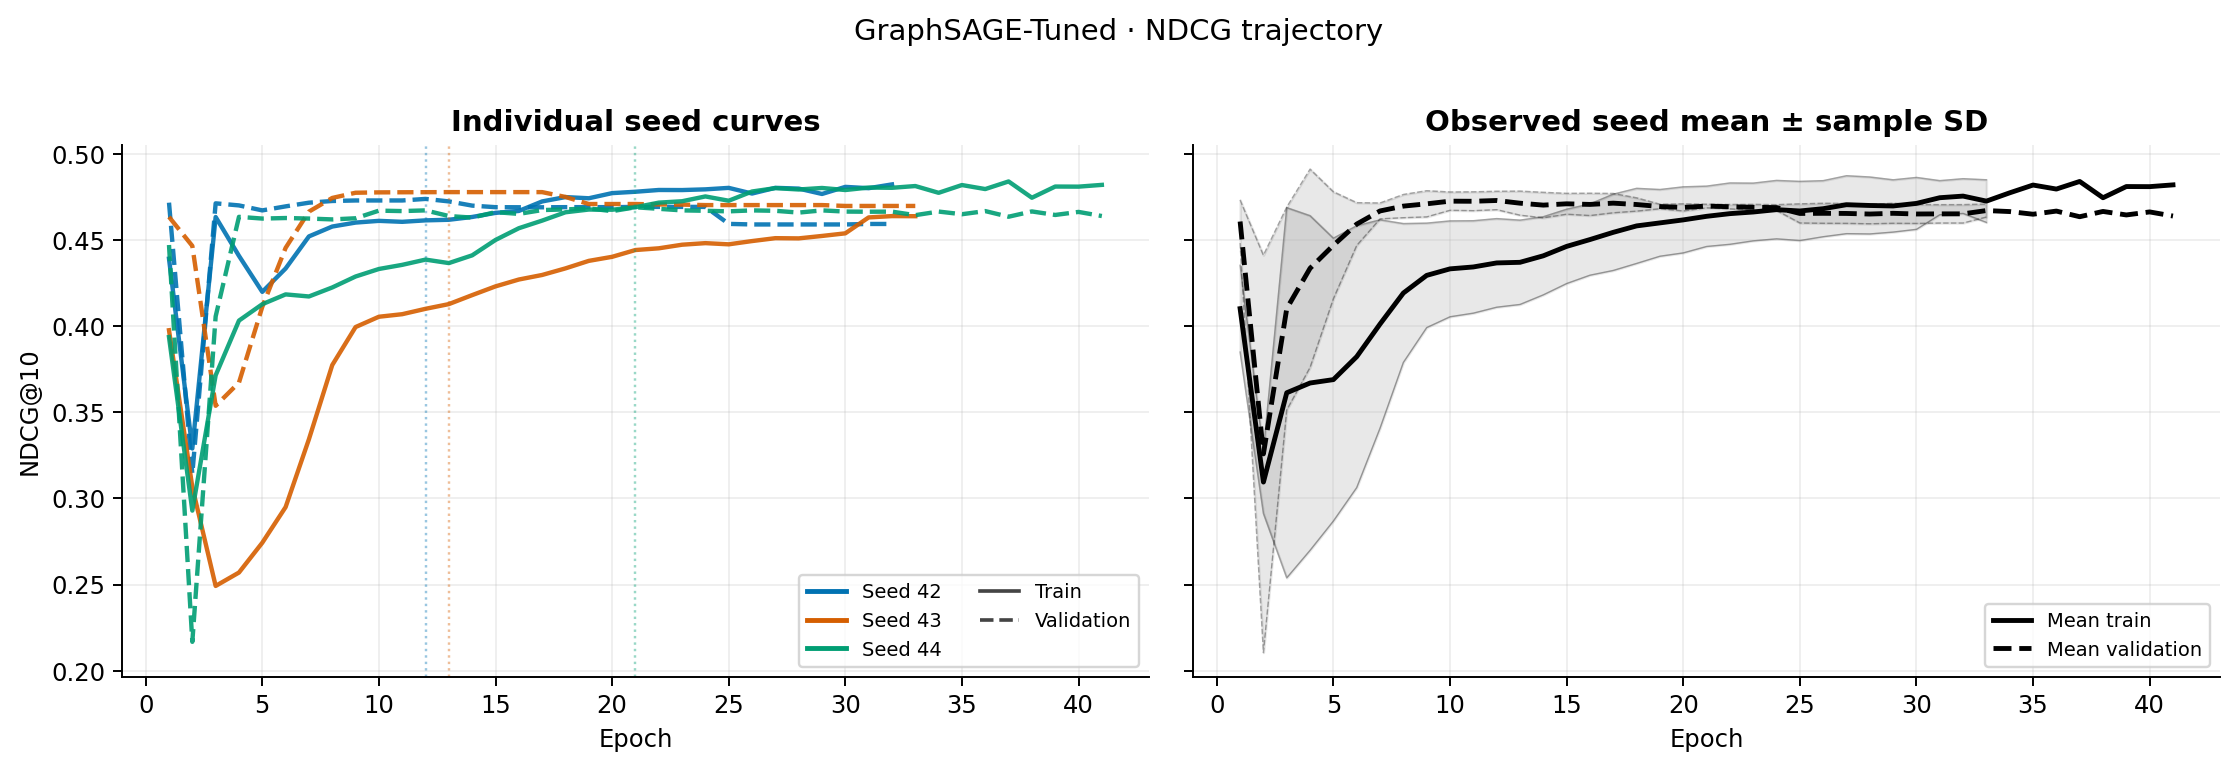

**GraphSAGE-Tuned: fixed seed colours, solid/dashed = mean/max gradient; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

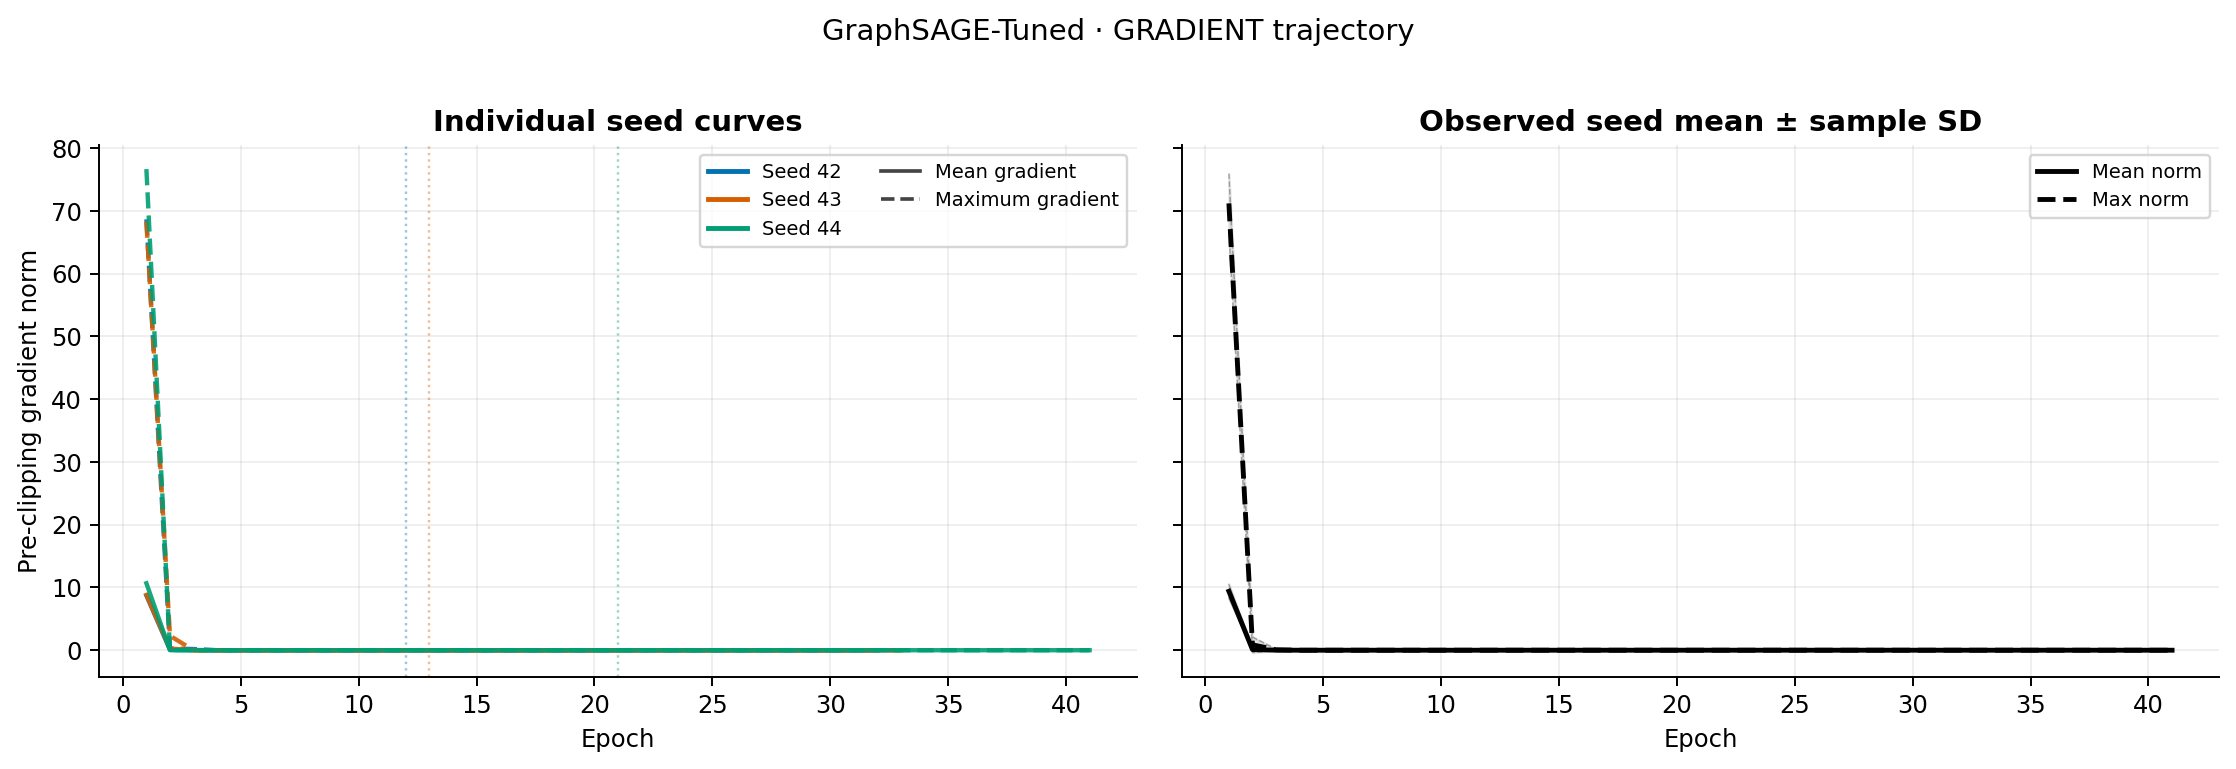

**GraphSAGE-Tuned: optimisation and selected checkpoint epochs**

,seed,epochs,minimum_val_BCE,maximum_val_NDCG10,selected_epoch
0,42,32,1.1754,0.4739,12
1,43,33,1.1774,0.4778,13
2,44,41,1.1775,0.4690,21


#### Retail POS · monthly

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

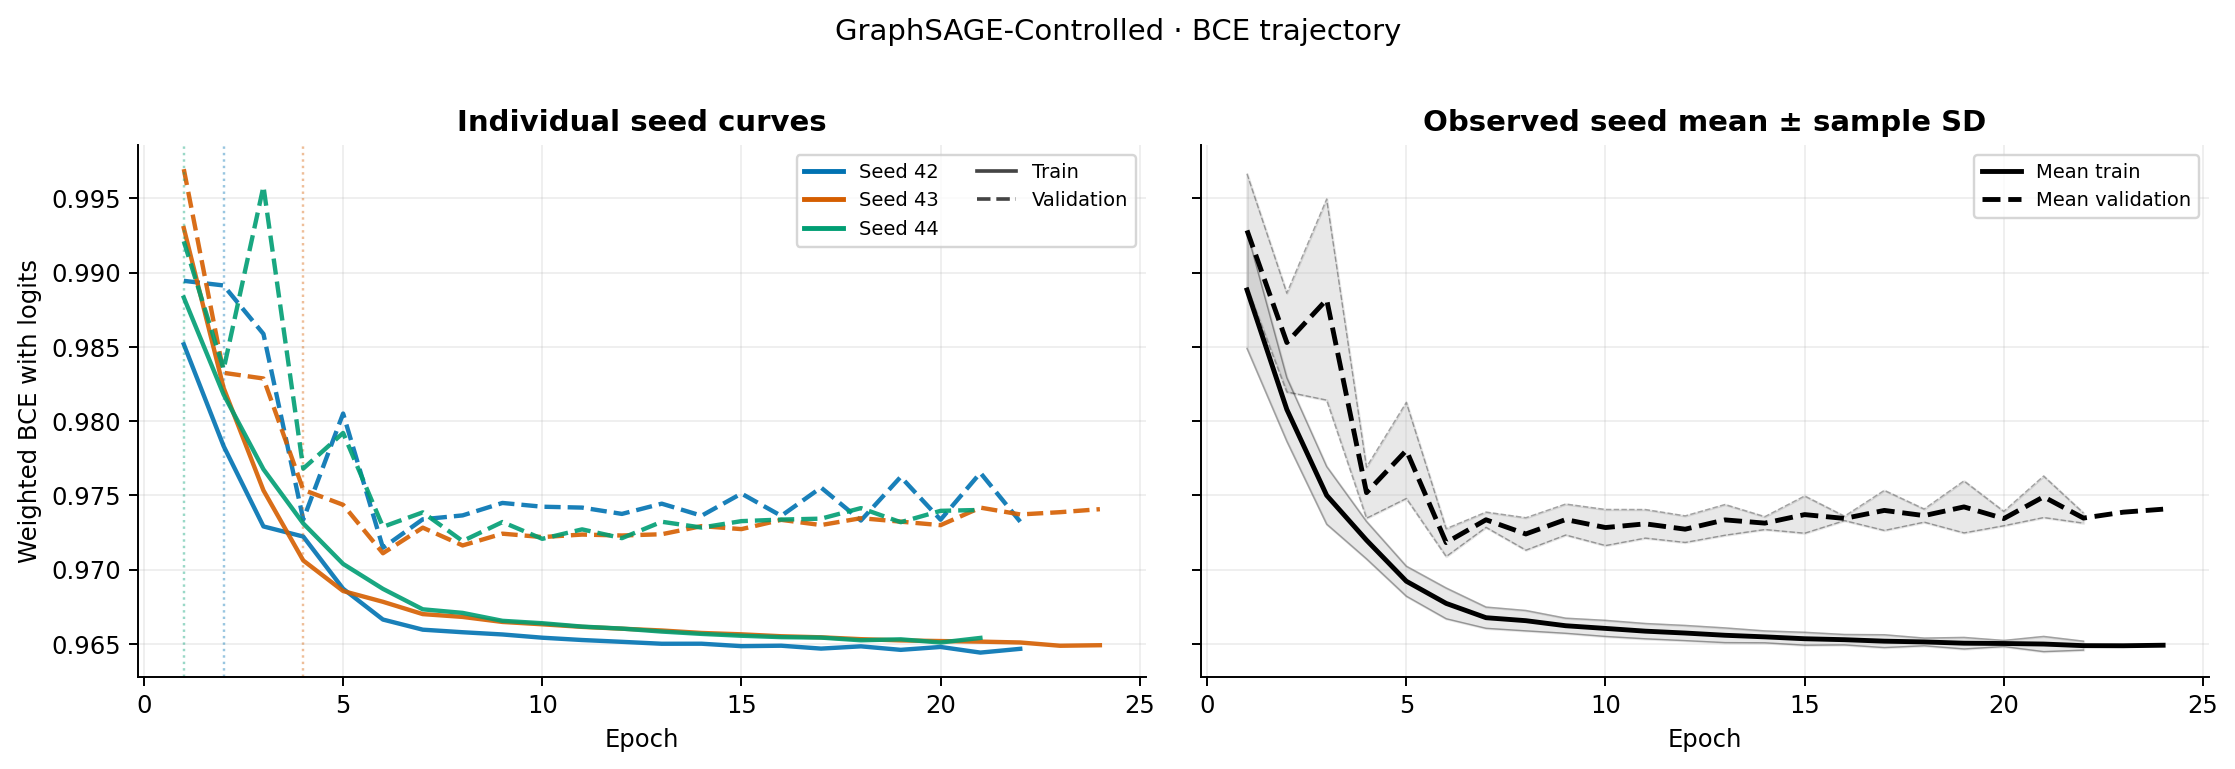

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

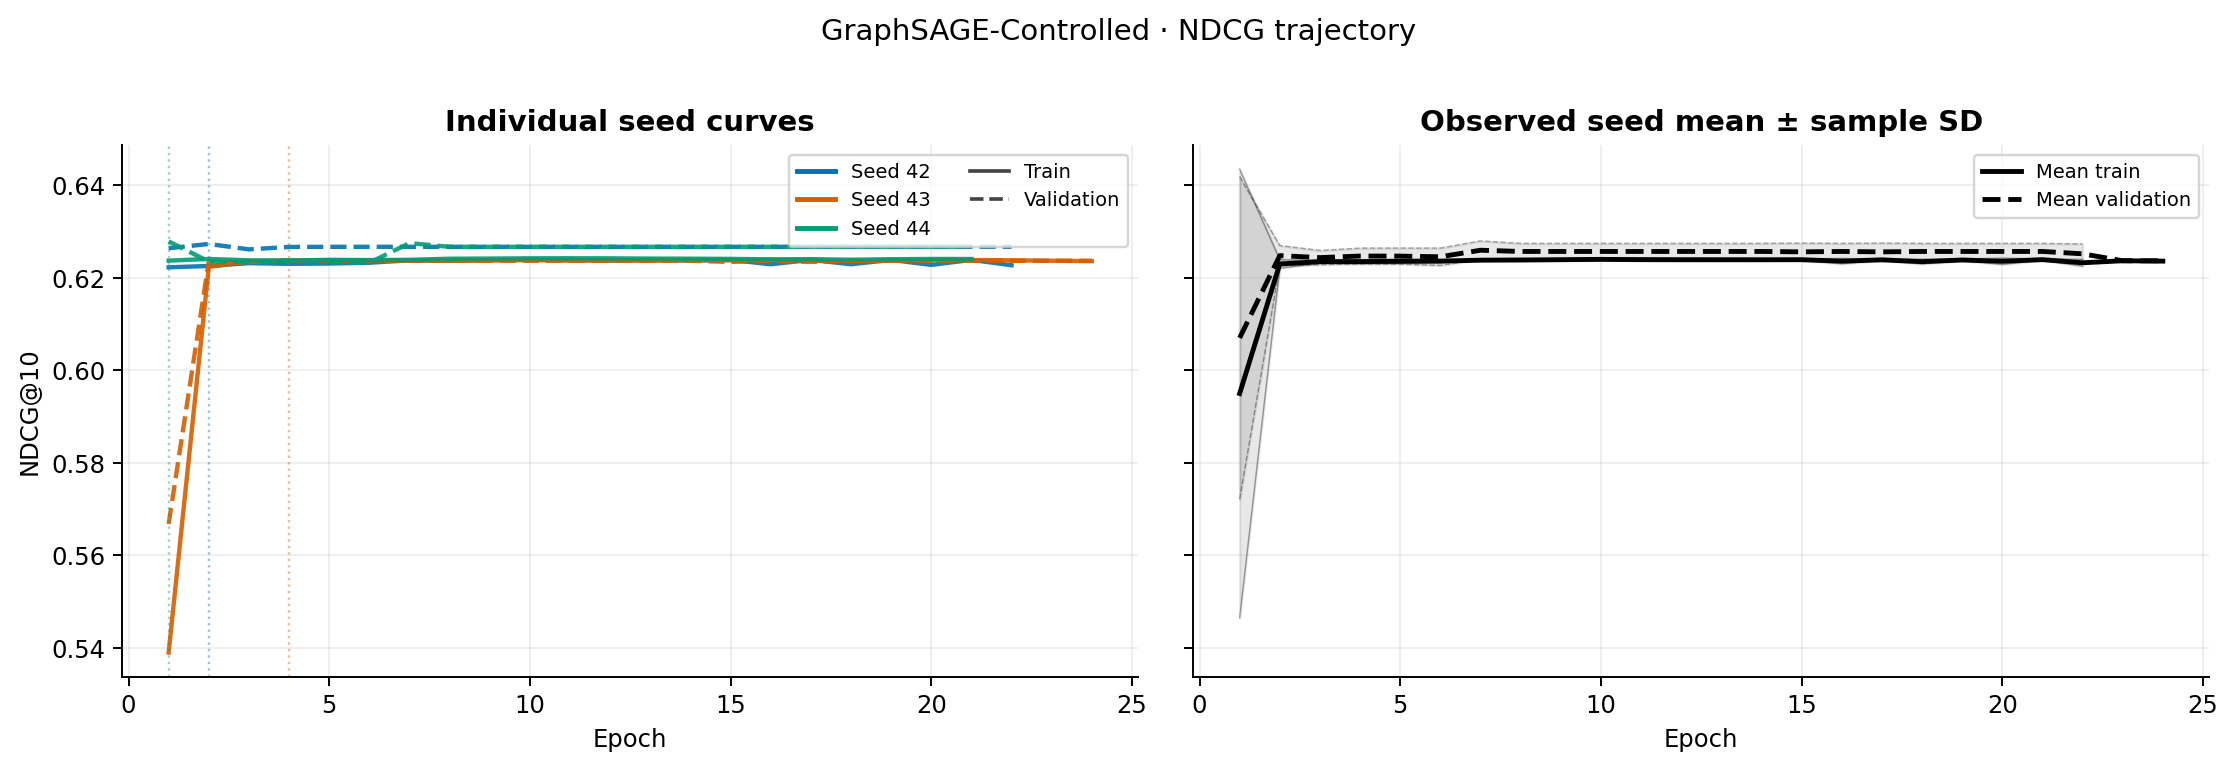

**GraphSAGE-Controlled: fixed seed colours, solid/dashed = mean/max gradient; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

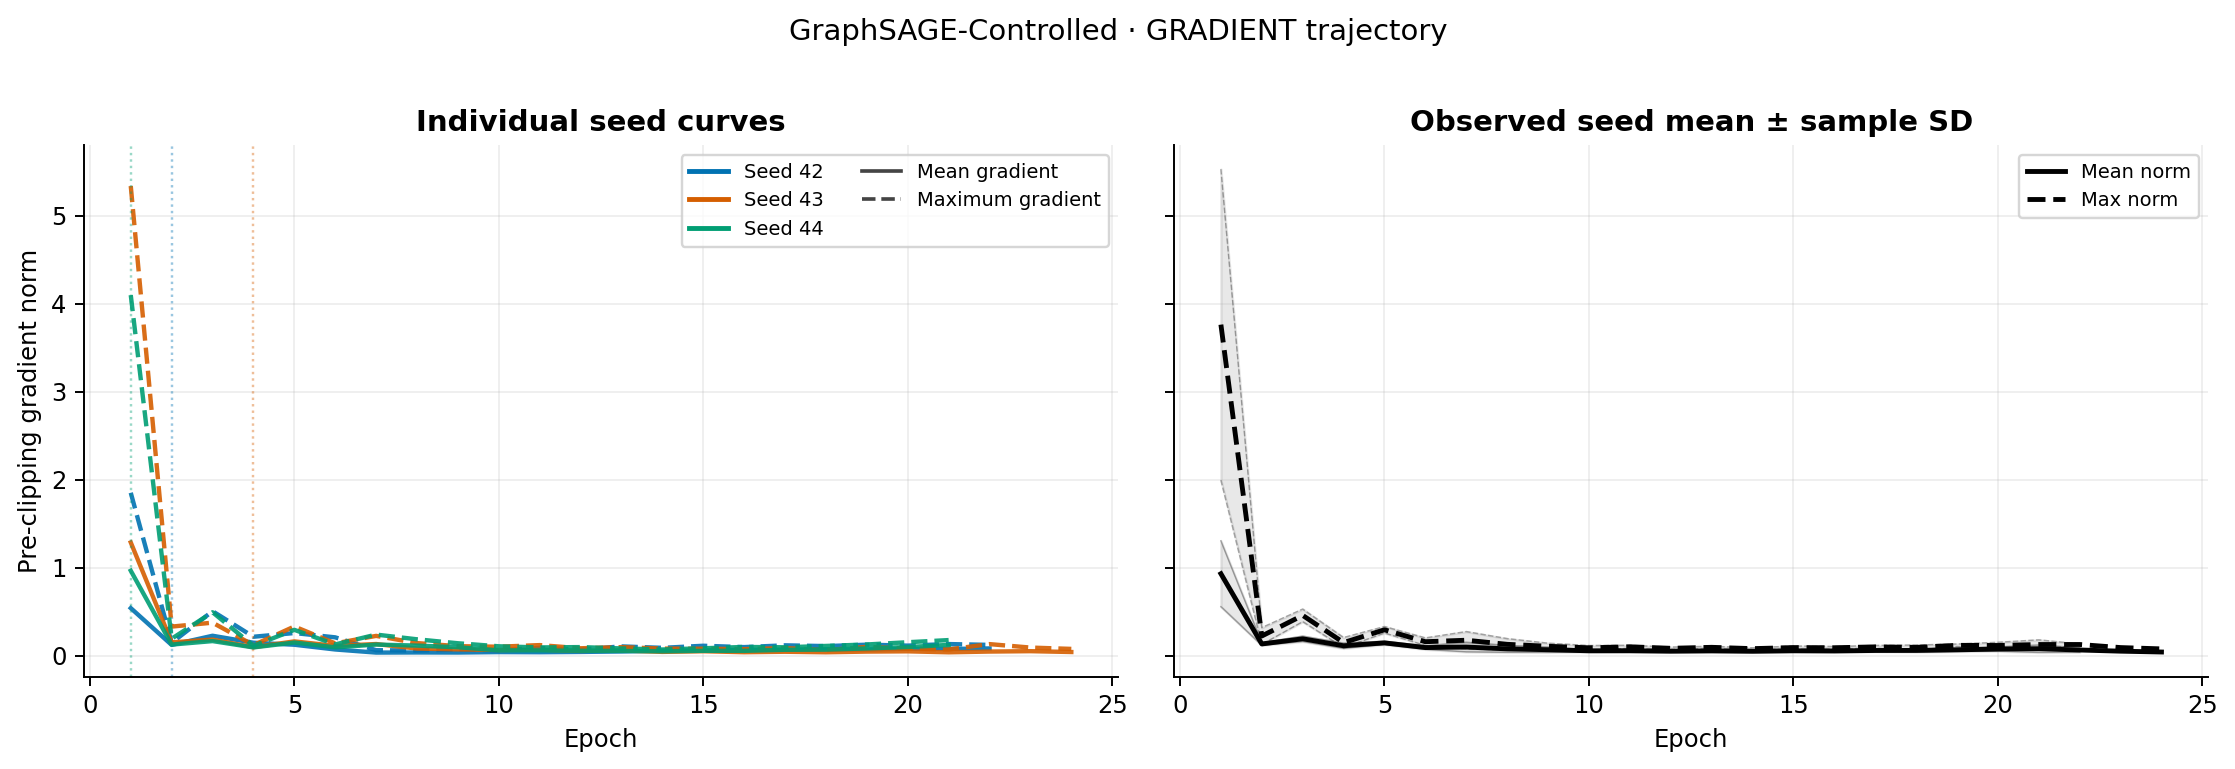

**GraphSAGE-Controlled: optimisation and selected checkpoint epochs**

,seed,epochs,minimum_val_BCE,maximum_val_NDCG10,selected_epoch
0,42,22,0.9715,0.6273,2
1,43,24,0.9711,0.6237,4
2,44,21,0.9719,0.6279,1


**GraphSAGE-Tuned: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

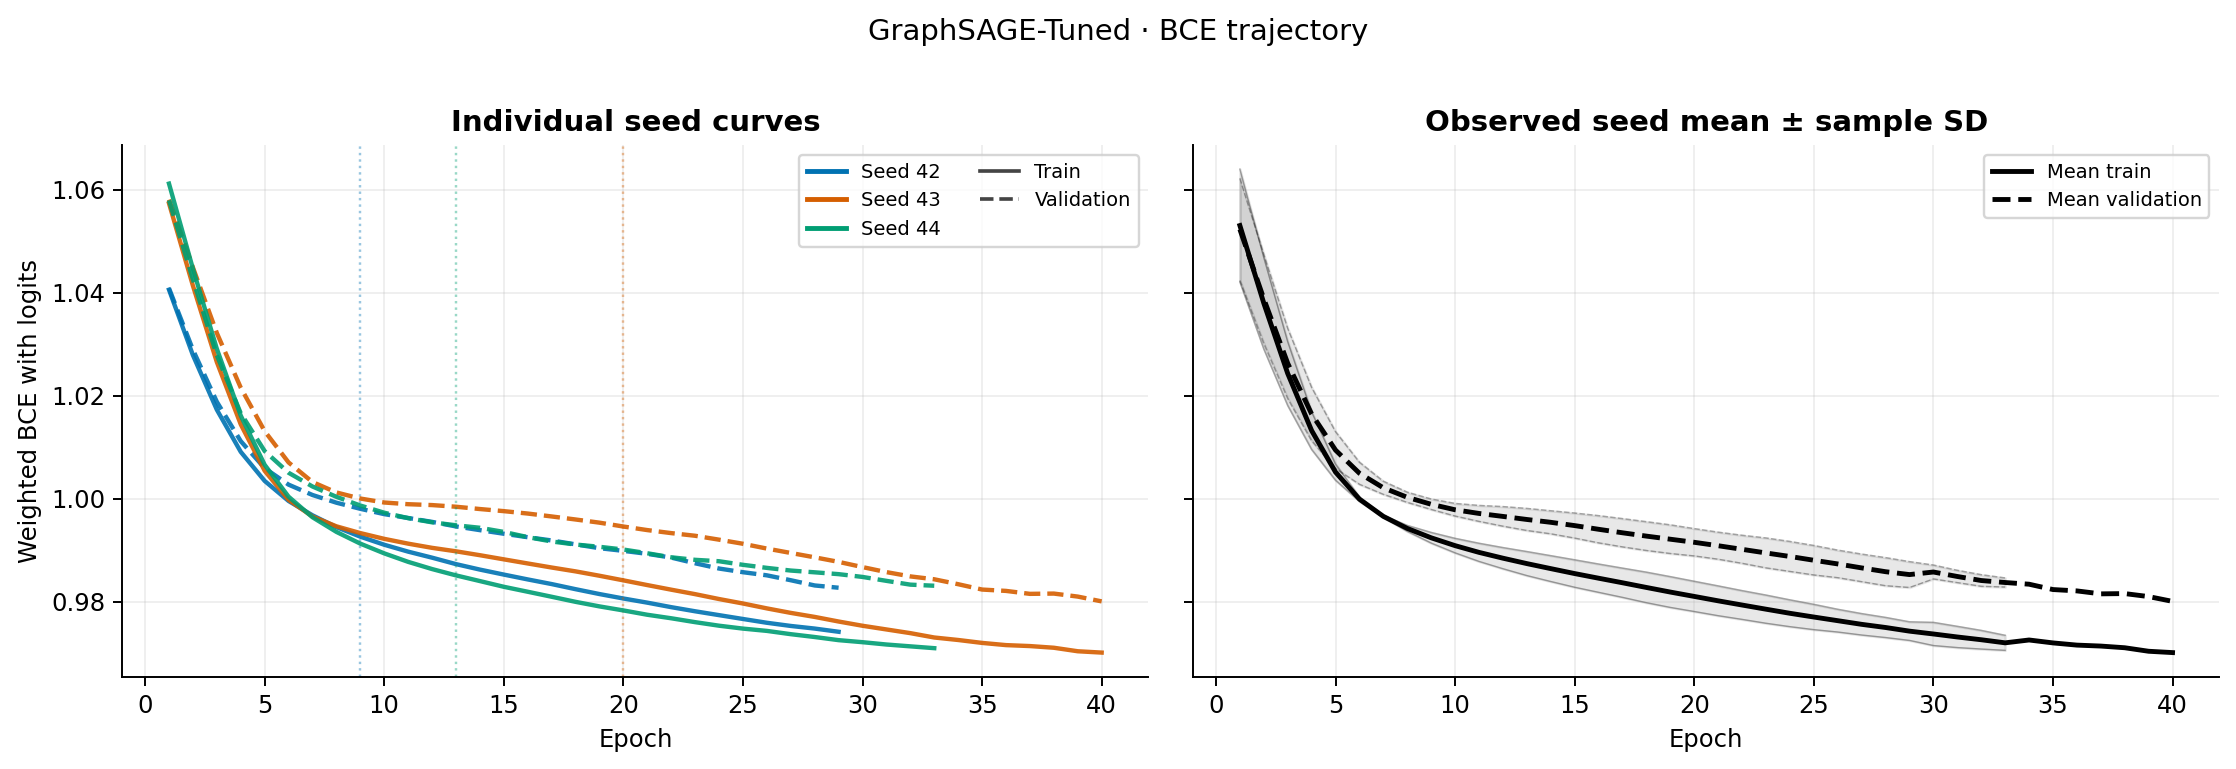

**GraphSAGE-Tuned: fixed seed colours, solid/dashed = train/validation; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

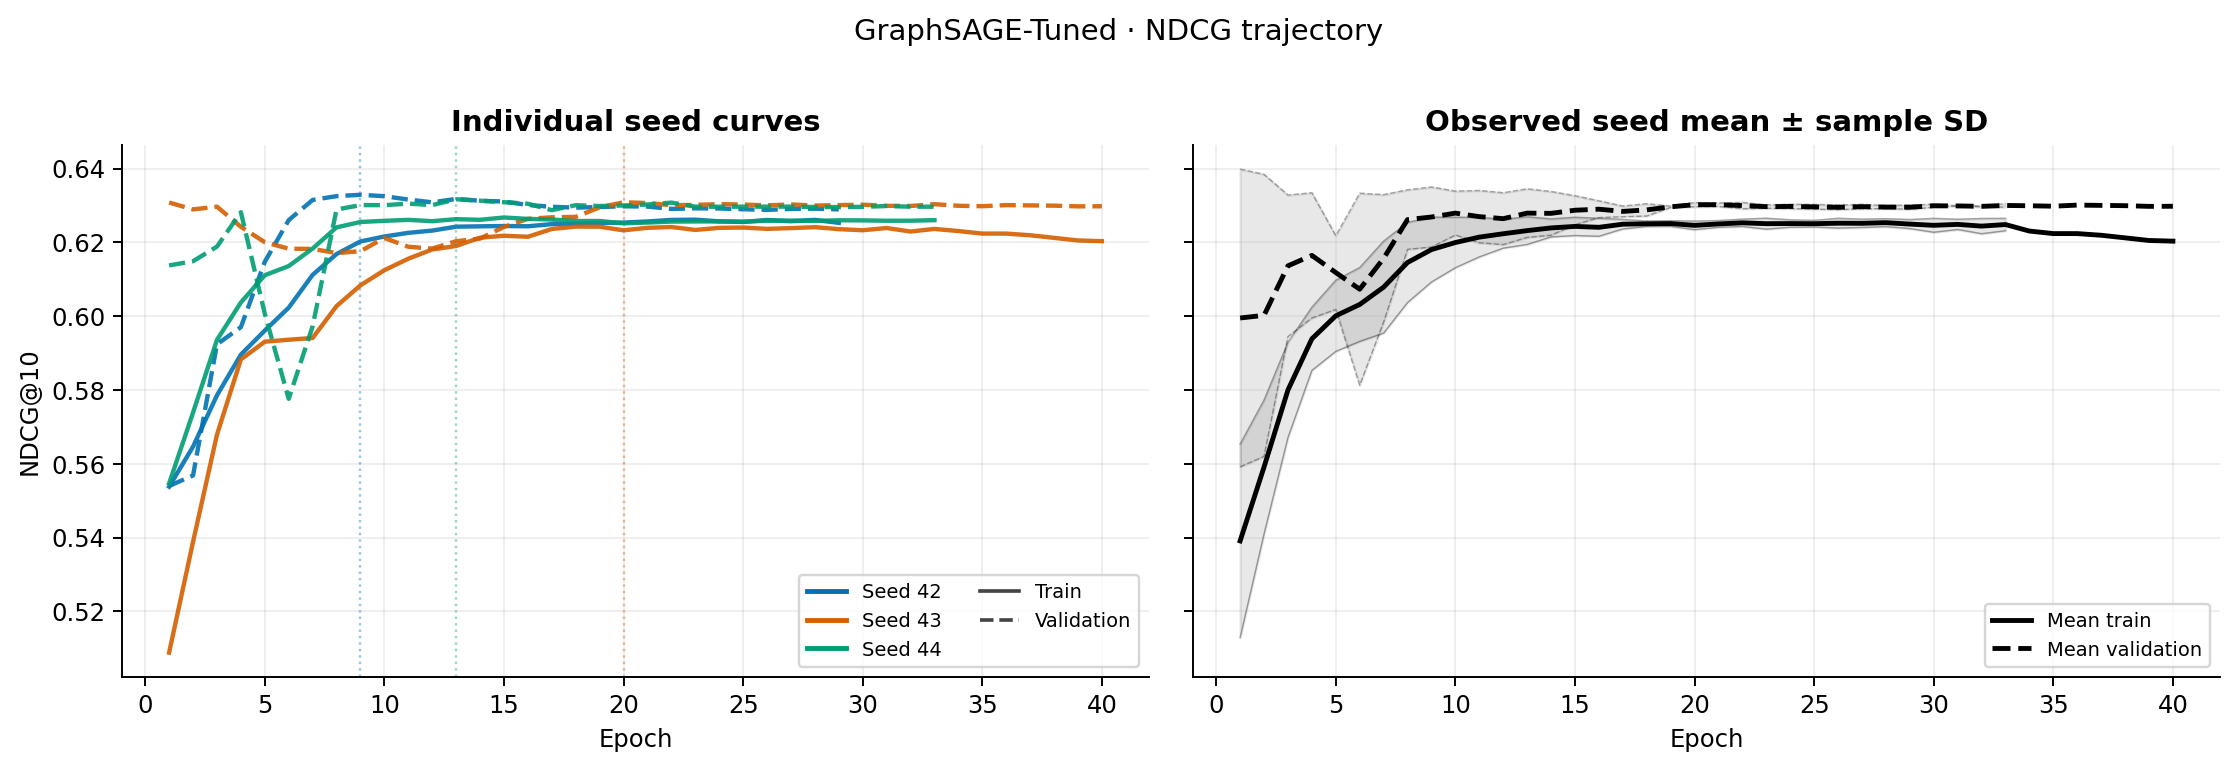

**GraphSAGE-Tuned: fixed seed colours, solid/dashed = mean/max gradient; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).**

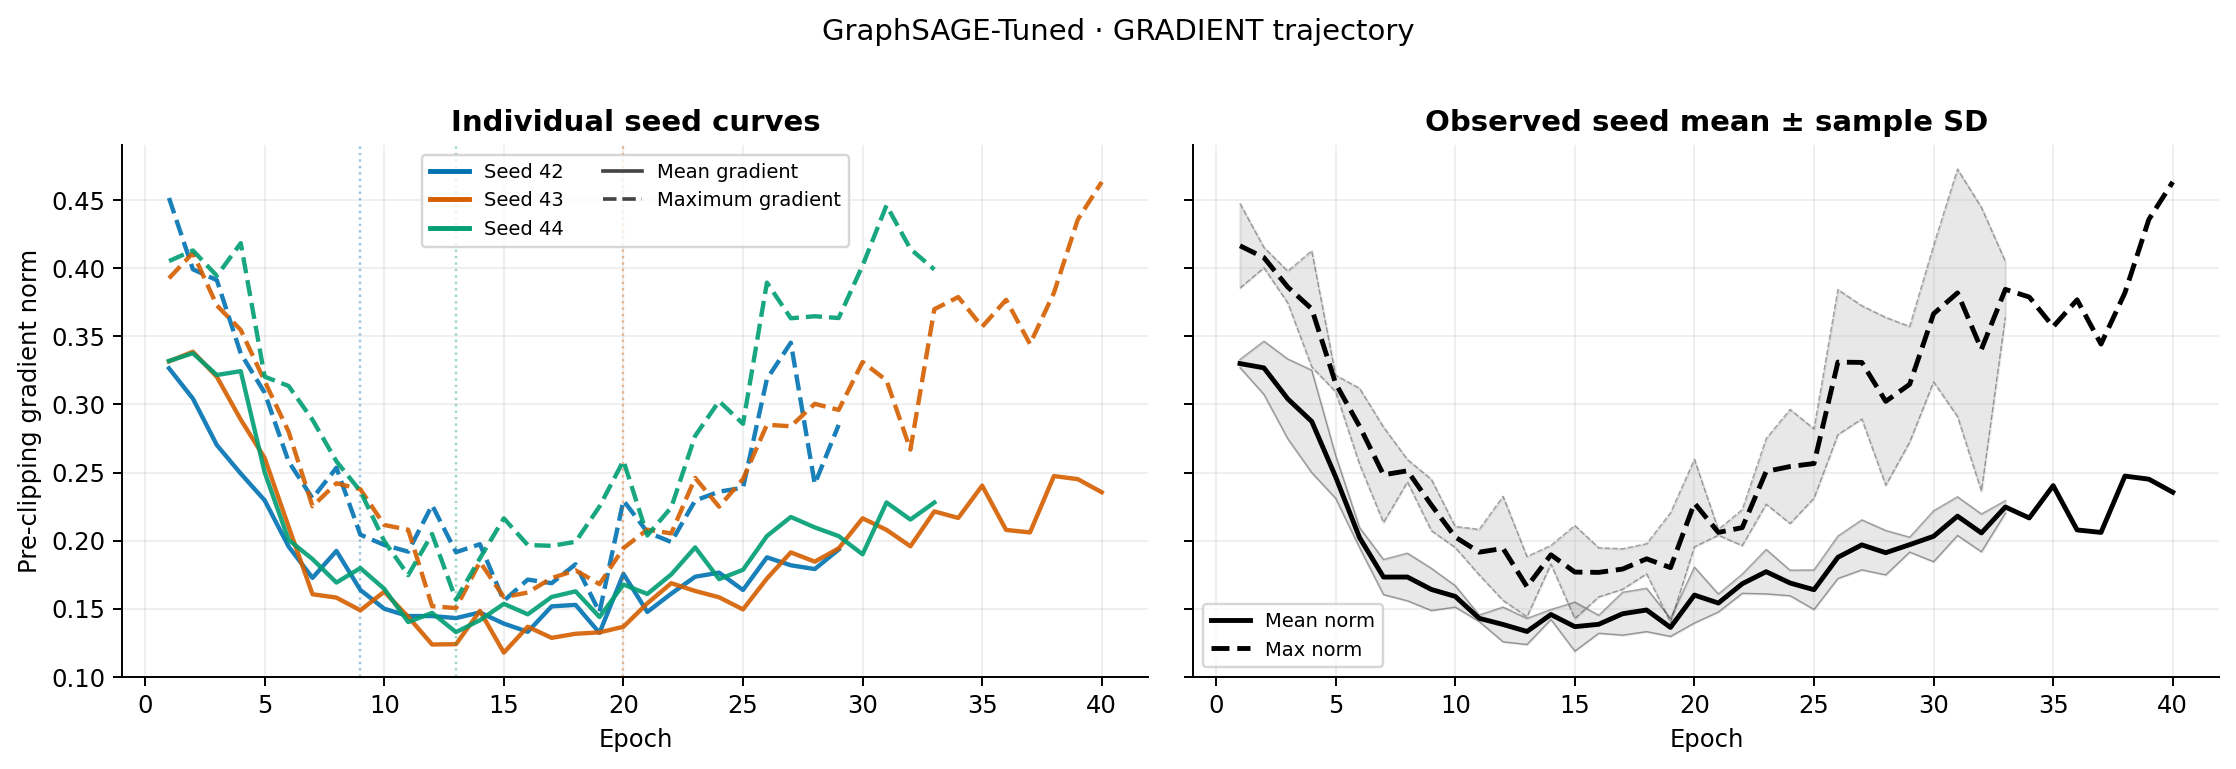

**GraphSAGE-Tuned: optimisation and selected checkpoint epochs**

,seed,epochs,minimum_val_BCE,maximum_val_NDCG10,selected_epoch
0,42,29,0.9827,0.6329,9
1,43,40,0.9800,0.6309,20
2,44,33,0.9831,0.6317,13


In [ ]:
# One colour identifies one seed throughout; line style identifies train/validation.
# Mean ± sample SD is displayed separately and never extrapolated after early stopping.
from matplotlib.lines import Line2D
SEED_COLOURS={42:'#0072B2',43:'#D55E00',44:'#009E73'}
for ds in DATASETS:
    ds_header(ds)
    for method in ('GraphSAGE-Controlled','GraphSAGE-Tuned'):
        h=HISTORY[(HISTORY.dataset==ds)&(HISTORY.method==method)].copy() if len(HISTORY) else pd.DataFrame()
        if h.empty:continue
        selected=HEADLINE[(HEADLINE.dataset==ds)&(HEADLINE.method==method)&(HEADLINE.split=='test')]
        checkpoint=dict(zip(selected.seed,selected.best_epoch))
        for fields,stem,ylabel in [
            (('train_bce','val_bce'),'bce','Weighted BCE with logits'),
            (('train_NDCG10','val_NDCG10'),'ndcg','NDCG@10'),
            (('preclip_grad_norm_mean','preclip_grad_norm_max'),'gradient','Pre-clipping gradient norm')]:
            gradient=(stem=='gradient')
            fig,(ax,aggax)=plt.subplots(1,2,figsize=(13,4.5),sharex=True,sharey=True)
            seeds=sorted(h.seed.unique())
            for seed,ss in h.groupby('seed'):
                ss=ss.sort_values('epoch')
                colour=SEED_COLOURS.get(int(seed),plt.get_cmap('tab10')(seeds.index(seed)%10))
                for i,field in enumerate(fields):
                    ax.plot(ss.epoch,ss[field],color=colour,ls='-' if i==0 else '--',lw=1.8,alpha=.9)
                ep=checkpoint.get(seed)
                if ep is not None and pd.notna(ep):ax.axvline(ep,color=colour,ls=':',alpha=.4,lw=1)
            for i,field in enumerate(fields):
                agg=h.groupby('epoch')[field].agg(['mean','std','count']).sort_index()
                line='-' if i==0 else '--'
                aggax.plot(agg.index,agg['mean'],color='black',ls=line,lw=2,
                           label='Mean '+('train' if i==0 else 'validation') if not gradient else ('Mean norm' if i==0 else 'Max norm'))
                eligible=agg[agg['count']>=2]
                if not eligible.empty:
                    x=eligible.index.to_numpy(float)
                    low=(eligible['mean']-eligible['std']).to_numpy(float)
                    high=(eligible['mean']+eligible['std']).to_numpy(float)
                    aggax.fill_between(x,low,high,color='black',alpha=.09)
                    aggax.plot(x,low,color='black',lw=.6,alpha=.3,ls=line)
                    aggax.plot(x,high,color='black',lw=.6,alpha=.3,ls=line)
            keys=[Line2D([0],[0],color=SEED_COLOURS.get(int(seed),plt.get_cmap('tab10')(seeds.index(seed)%10)),
                          lw=2,label=f'Seed {seed}') for seed in seeds]
            keys.extend([Line2D([0],[0],color='#444',ls='-',label='Train' if not gradient else 'Mean gradient'),
                         Line2D([0],[0],color='#444',ls='--',label='Validation' if not gradient else 'Maximum gradient')])
            ax.legend(handles=keys,ncol=2,fontsize=8)
            ax.set(xlabel='Epoch',ylabel=ylabel,title='Individual seed curves')
            aggax.set(xlabel='Epoch',title='Observed seed mean ± sample SD')
            aggax.legend(fontsize=8)
            for a in (ax,aggax):a.grid(alpha=.2)
            fig.suptitle(f'{method} · {stem.upper()} trajectory')
            chapter_figure(fig,ds,'08_training_dynamics',f'{ds}_{method}_{stem}_epoch',
               f'{method}: fixed seed colours, solid/dashed = '+
               ('mean/max gradient' if gradient else 'train/validation')+
               '; dotted lines = selected epochs; black band = mean ± sample SD (n>=2 epochs).',
               'tables/run6_epoch_history.csv.gz')
        e=h.groupby('seed').agg(epochs=('epoch','max'),minimum_val_BCE=('val_bce','min'),
                 maximum_val_NDCG10=('val_NDCG10','max')).reset_index()
        e['selected_epoch']=e.seed.map(checkpoint)
        numeric_table(e,f'{method}: optimisation and selected checkpoint epochs')


## 05 · Held-out predictive value: GraphSAGE versus the non-graph alternatives

**Question.** After validation-only tuning, do graph-derived embeddings actually improve the next-period category ranking over the existing v5 baseline suite?

We now compare the two GraphSAGE models to the full **Run 3 test leaderboard**, not merely to one manually chosen comparator. Only the Run 3 validation winner and GlobalPopularity are used for primary paired differences. The test leaderboard is descriptive; it must **not** be used to retroactively change the model selection.

**Interpretation order:** (i) absolute NDCG@10, (ii) improvement over the frozen validation winner, (iii) seed spread and number of successful seeds, (iv) metric sensitivity across k. A difference smaller than its seed spread is not necessarily evidence of an advantage.

**Uncertainty display:** The unified baseline-versus-GraphSAGE leaderboard uses black mean ± sample-SD whiskers for methods with at least two successful seeds and an available SD. Missing whiskers do not mean zero variation.


#### EuroMart · quarterly

**Joint Run 3 + GraphSAGE held-out leaderboard**

,method,family,NDCG@10,NDCG@10_seed_sd,valid_seeds
0,GraphSAGE-Tuned,GraphSAGE,0.4805,0.0030,3
1,FeatureLogistic,Run 3,0.4800,0.0033,3
2,GlobalPopularity,Run 3,0.4773,NaN,1
3,PopularityPersonalBlend,Run 3,0.4771,NaN,1
4,FeatureMLP,Run 3,0.4763,0.0052,3
5,GraphSAGE-Controlled,GraphSAGE,0.4713,0.0068,3
6,CategoryKNN-Jaccard,Run 3,0.4621,NaN,1
7,CategoryKNN-Cosine,Run 3,0.4571,NaN,1
8,CategoryKNN-NoSelf,Run 3,0.4562,NaN,1
9,PersonalHistory-Binary,Run 3,0.4494,NaN,1


**Held-out model comparison. Black whiskers = sample SD for methods with at least two successful seeds and a reported SD; missing whiskers do not indicate zero SD.**

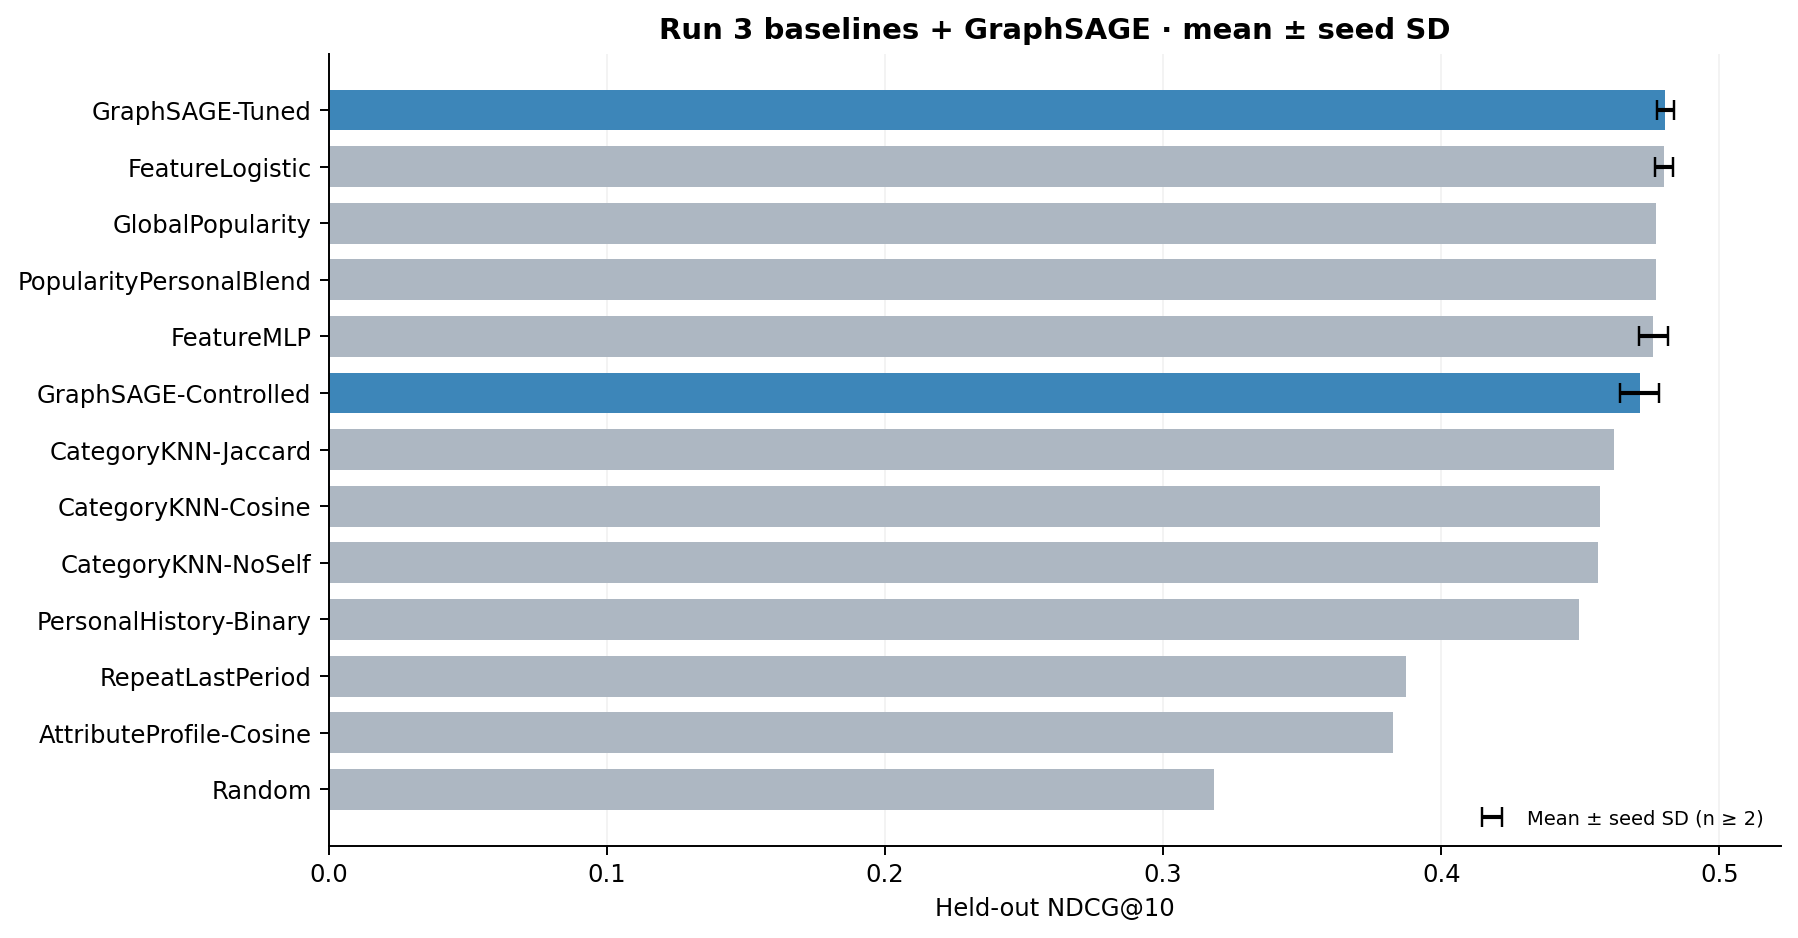

**NDCG@3 for Controlled and Tuned GraphSAGE; descriptive test result**

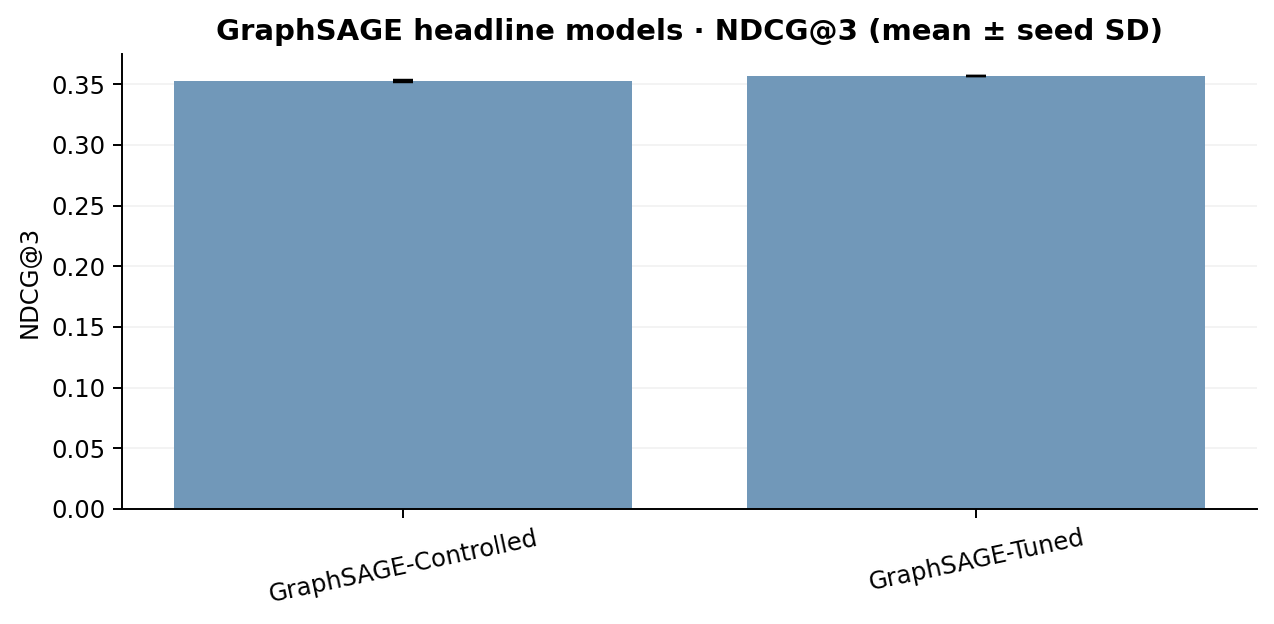

**NDCG@5 for Controlled and Tuned GraphSAGE; descriptive test result**

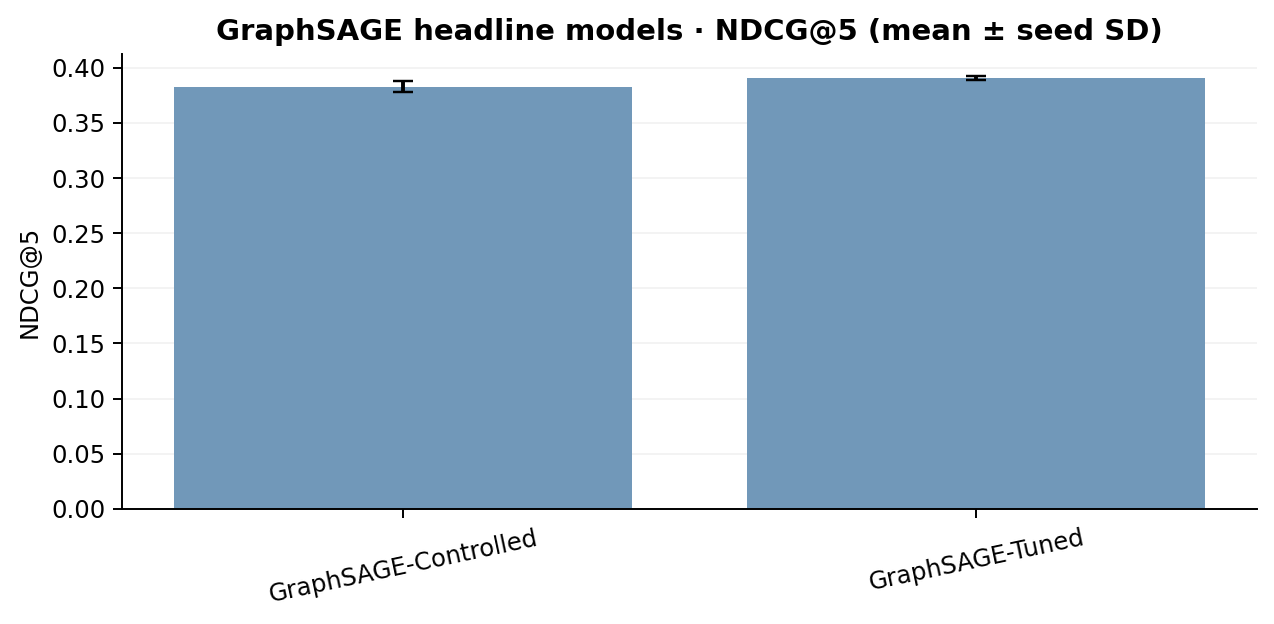

**NDCG@10 for Controlled and Tuned GraphSAGE; descriptive test result**

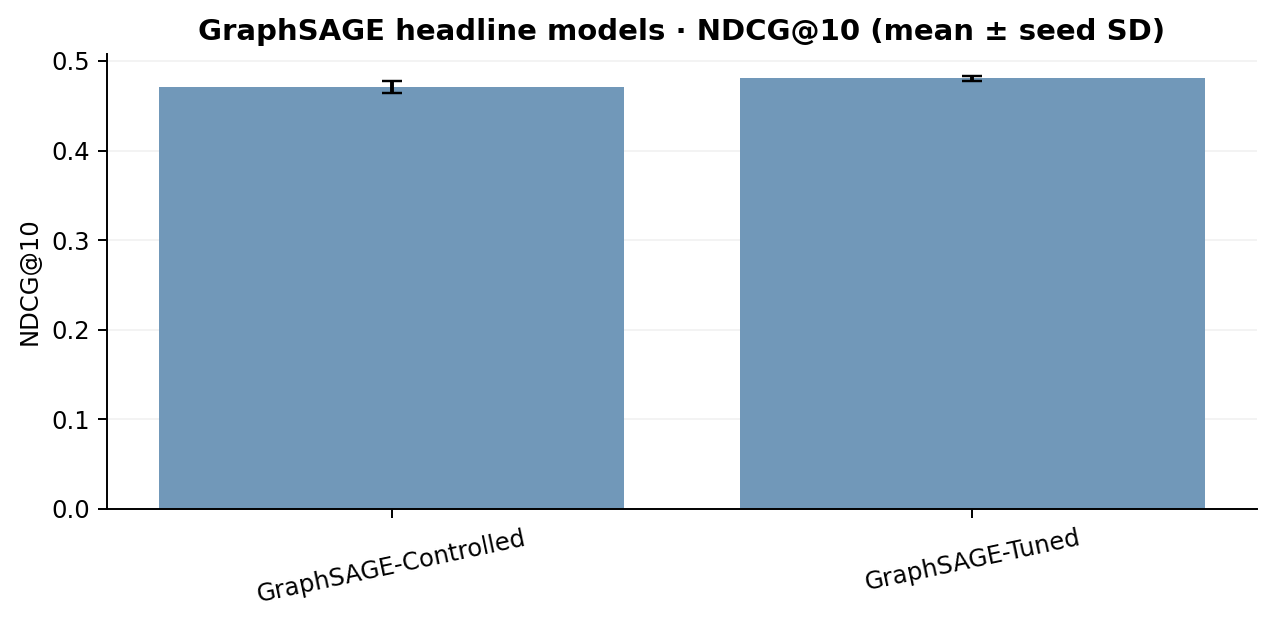

**Recall@10 for Controlled and Tuned GraphSAGE; descriptive test result**

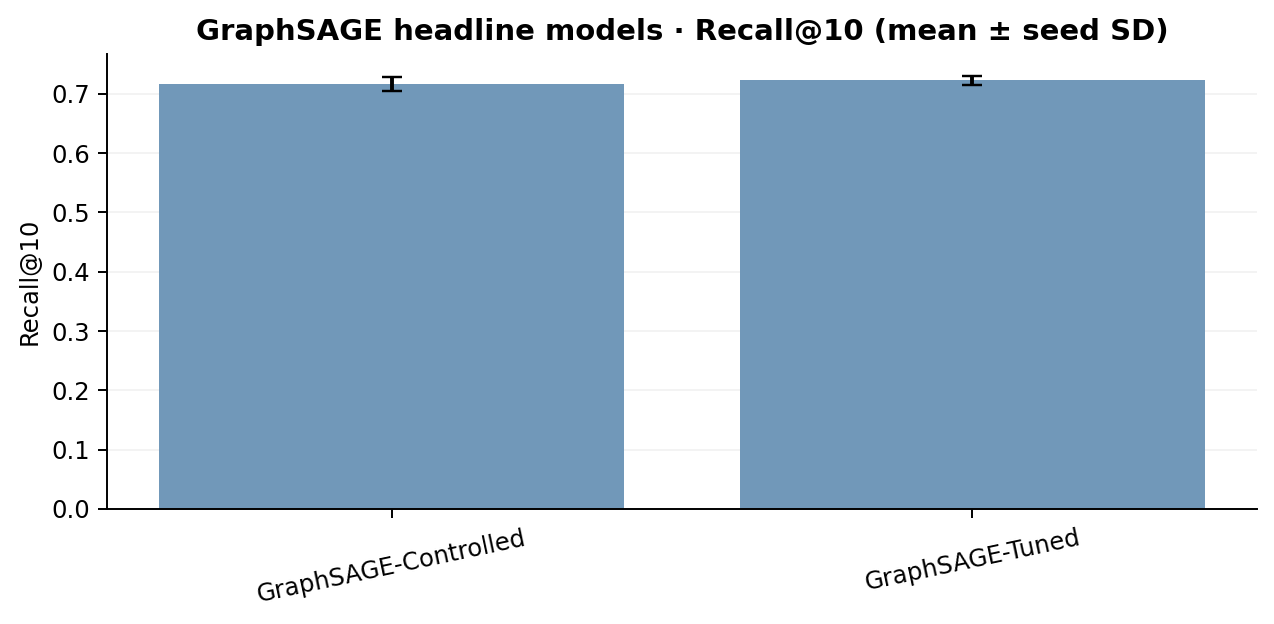

**PR-AUC for Controlled and Tuned GraphSAGE; descriptive test result**

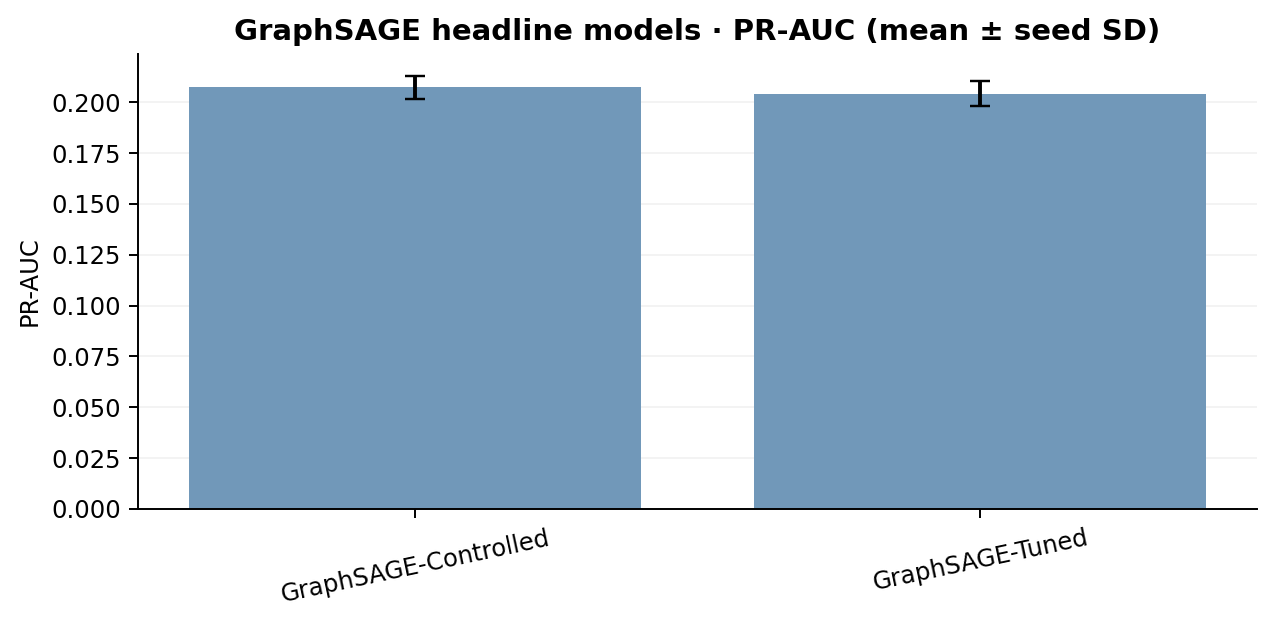

**Individual seed results and mean ± sample SD (not a confidence interval)**

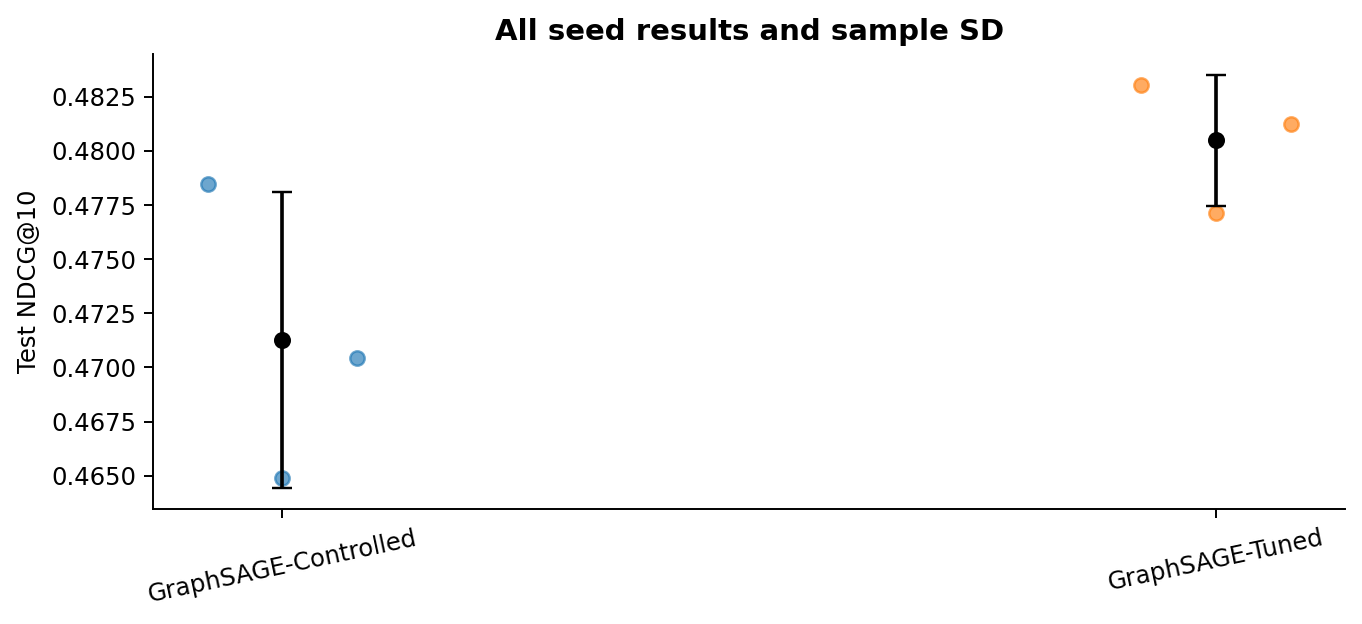

#### Retail POS · monthly

**Joint Run 3 + GraphSAGE held-out leaderboard**

,method,family,NDCG@10,NDCG@10_seed_sd,valid_seeds
0,PopularityPersonalBlend,Run 3,0.6315,NaN,1
1,FeatureMLP,Run 3,0.6291,0.0000,3
2,GlobalPopularity,Run 3,0.6291,NaN,1
3,FeatureLogistic,Run 3,0.6290,0.0001,3
4,GraphSAGE-Tuned,GraphSAGE,0.6288,0.0027,3
5,GraphSAGE-Controlled,GraphSAGE,0.6287,0.0009,3
6,CategoryKNN-Cosine,Run 3,0.6220,NaN,1
7,PersonalHistory-Binary,Run 3,0.6059,NaN,1
8,CategoryKNN-Jaccard,Run 3,0.5892,NaN,1
9,CategoryKNN-NoSelf,Run 3,0.5810,NaN,1


**Held-out model comparison. Black whiskers = sample SD for methods with at least two successful seeds and a reported SD; missing whiskers do not indicate zero SD.**

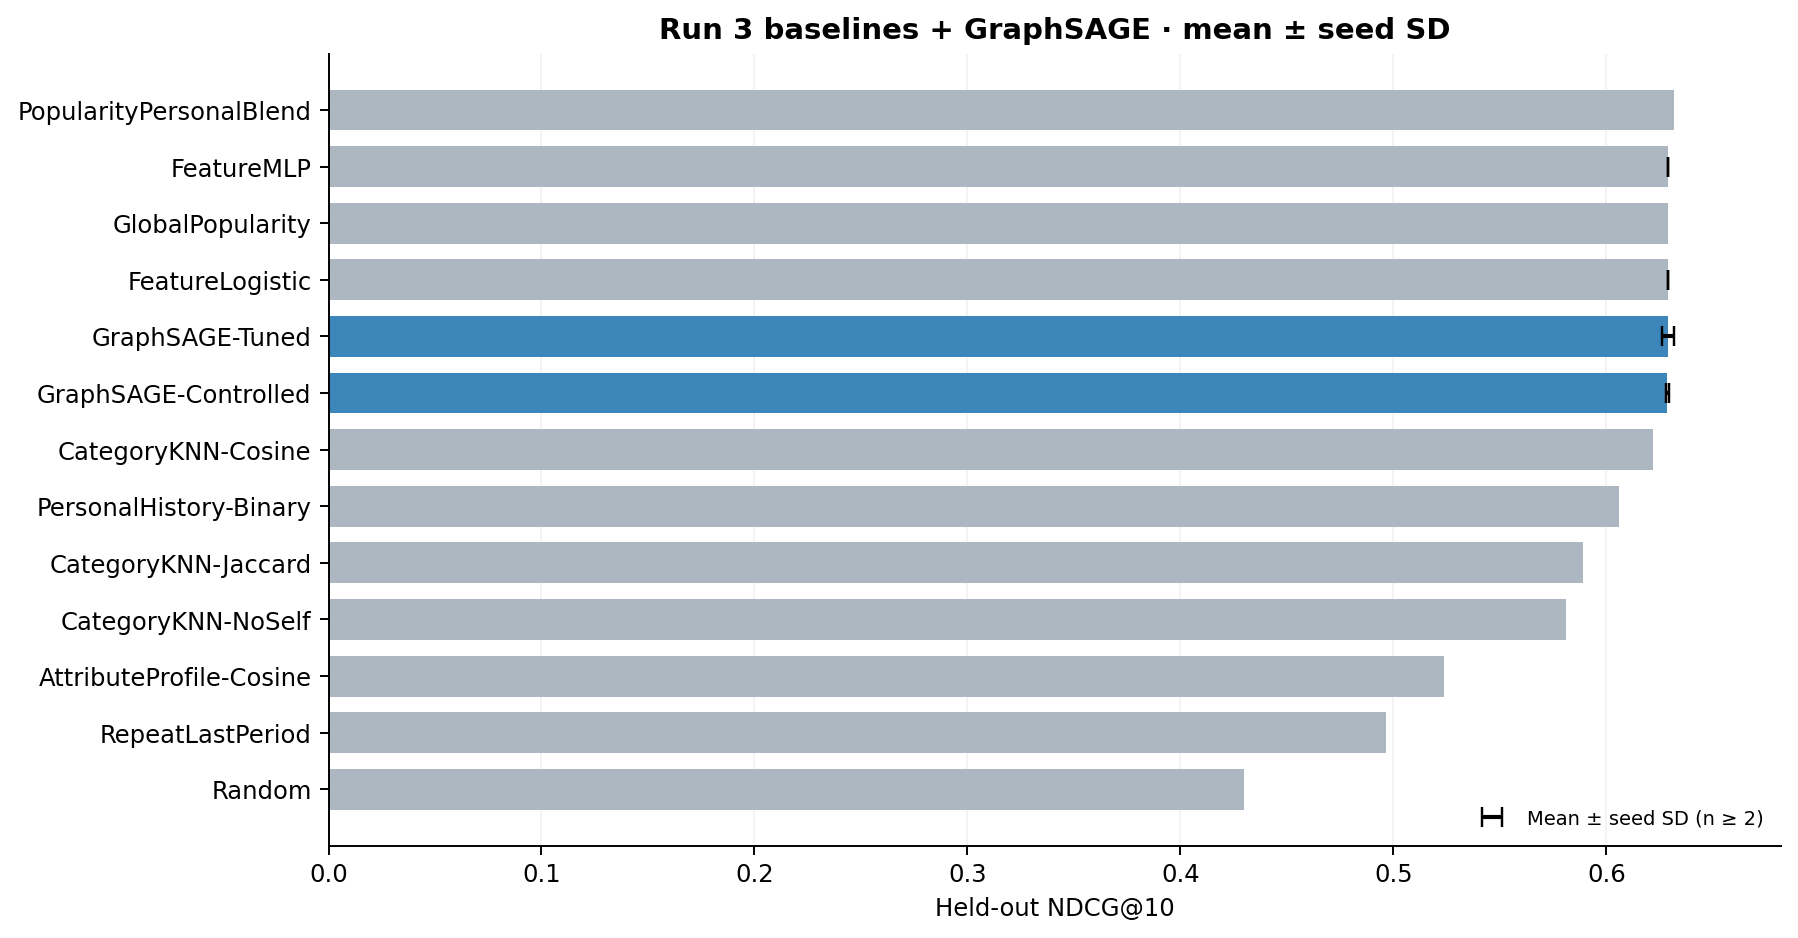

**NDCG@3 for Controlled and Tuned GraphSAGE; descriptive test result**

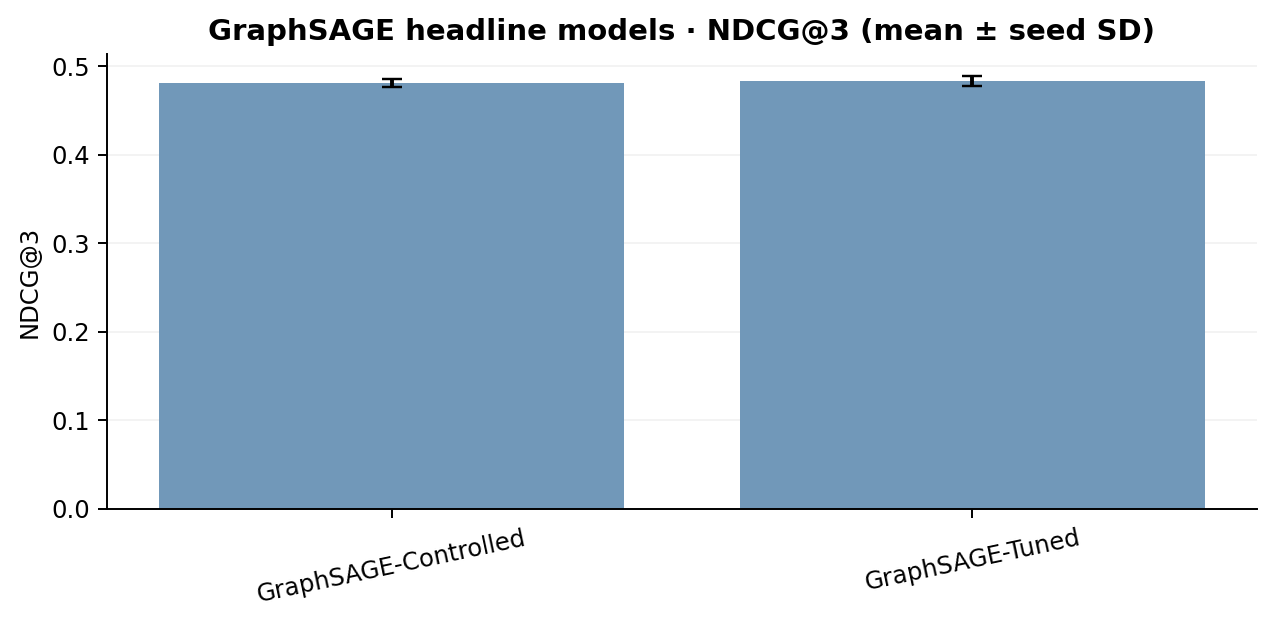

**NDCG@5 for Controlled and Tuned GraphSAGE; descriptive test result**

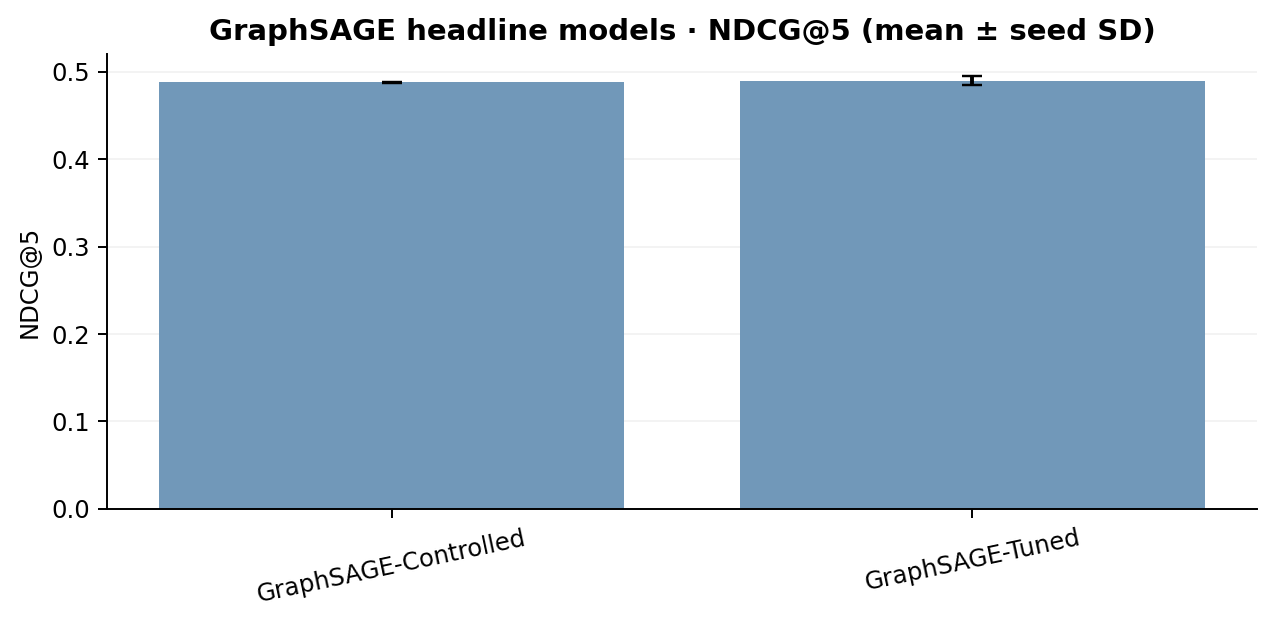

**NDCG@10 for Controlled and Tuned GraphSAGE; descriptive test result**

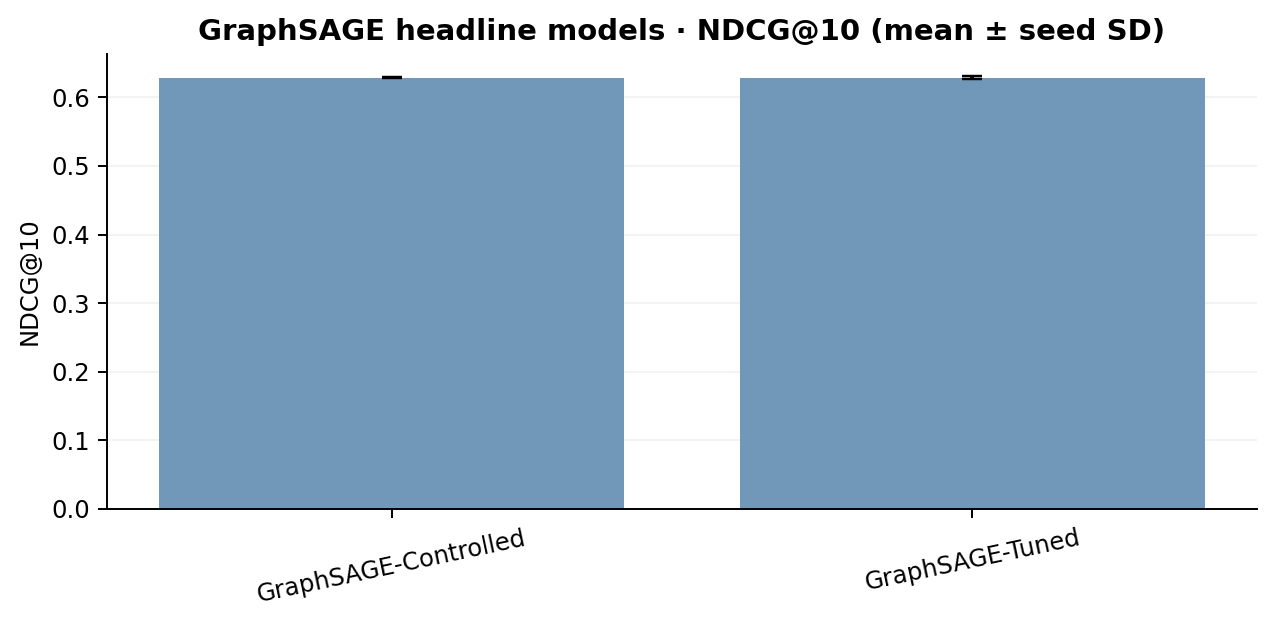

**Recall@10 for Controlled and Tuned GraphSAGE; descriptive test result**

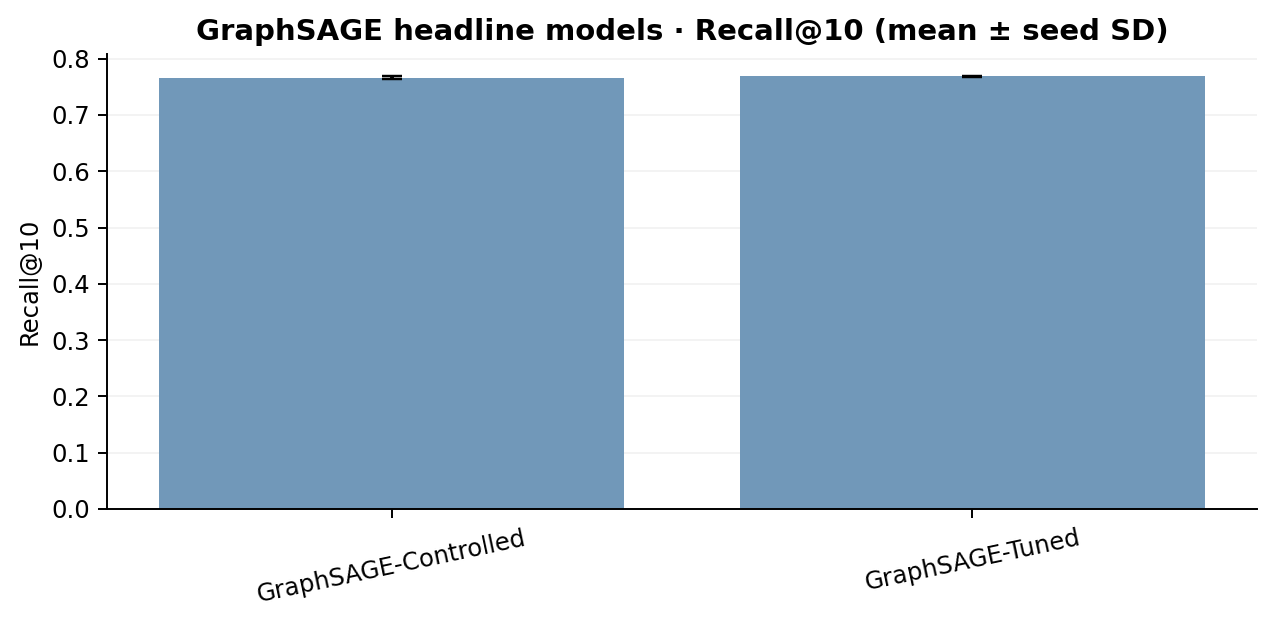

**PR-AUC for Controlled and Tuned GraphSAGE; descriptive test result**

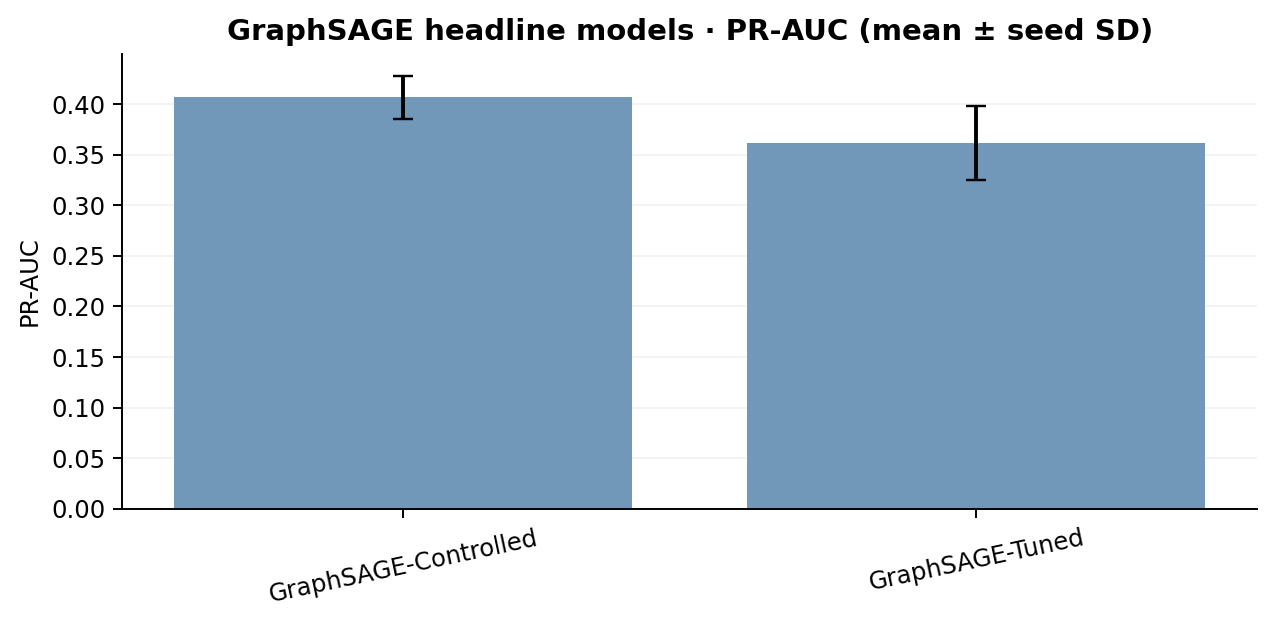

**Individual seed results and mean ± sample SD (not a confidence interval)**

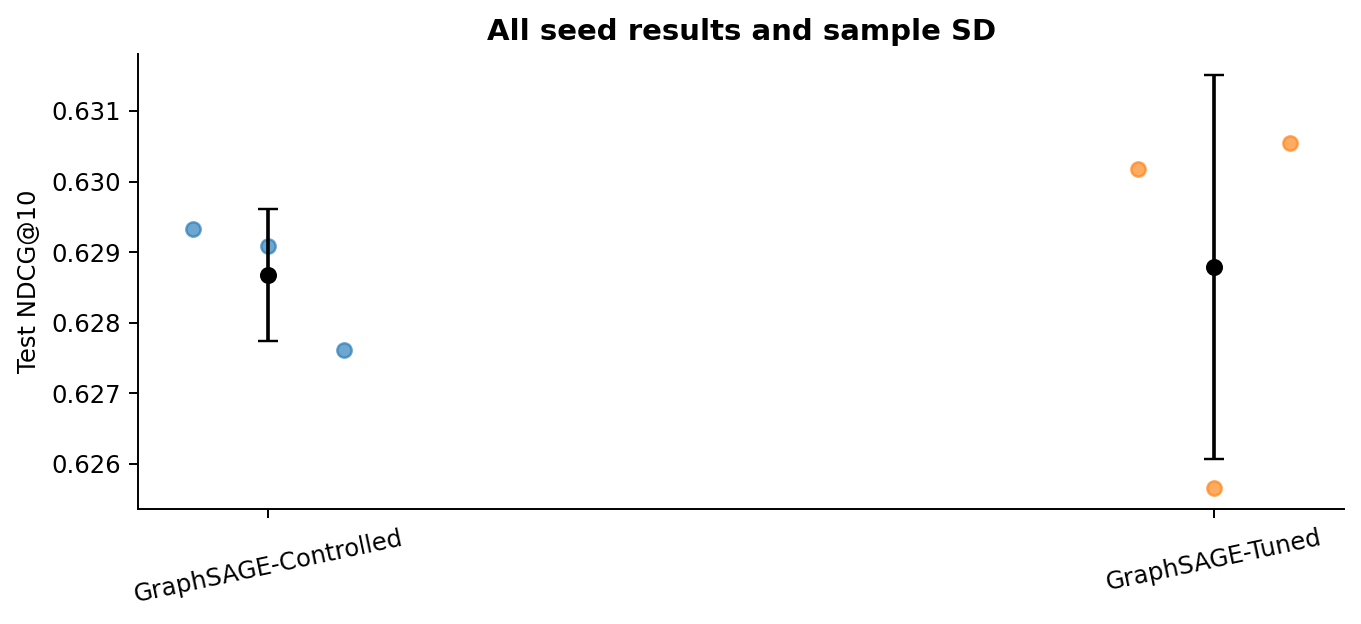

In [ ]:
RUN3_SUMMARY=pd.read_csv(RUN3/'tables/run3_test_summary.csv')
for ds in DATASETS:
    ds_header(ds)
    g=HEADLINE[(HEADLINE.dataset==ds)&(HEADLINE.split=='test')]
    rows=[]
    for name,s in g.groupby('method'):
        row={'method':name,'family':'GraphSAGE','valid_seeds':len(s)}
        for col in ['NDCG@3','NDCG@5','NDCG@10','Recall@10','PR-AUC']:
            row[col]=s[col].mean();row[col+'_seed_sd']=s[col].std(ddof=1) if len(s)>1 else np.nan
        rows.append(row)
    r3=RUN3_SUMMARY[RUN3_SUMMARY.dataset==ds].copy();r3['family']='Run 3'
    leader=pd.concat([r3,pd.DataFrame(rows)],ignore_index=True)
    leader=leader.sort_values('NDCG@10',ascending=False)
    save_csv(leader,OUT/f'tables/{ds}_run3_graphsage_joint_leaderboard.csv')
    numeric_table(leader[['method','family','NDCG@10','NDCG@10_seed_sd','valid_seeds']].reset_index(drop=True),
                 'Joint Run 3 + GraphSAGE held-out leaderboard')
    # Black whiskers are sample SD (n >= 2), never an implied 95% CI.
    fig,ax=plt.subplots(figsize=(10.5,max(5.6,.43*len(leader))))
    tmp=leader.iloc[::-1].reset_index(drop=True)
    y_pos=np.arange(len(tmp))
    score=pd.to_numeric(tmp['NDCG@10'],errors='coerce').to_numpy(float)
    sd=pd.to_numeric(tmp['NDCG@10_seed_sd'],errors='coerce').to_numpy(float)
    n=pd.to_numeric(tmp['valid_seeds'],errors='coerce').to_numpy(float)
    colours=['#3d86b9' if fam=='GraphSAGE' else '#adb7c2' for fam in tmp.family]
    ax.barh(y_pos,score,color=colours,height=.72,zorder=2)
    has_sd=(n>=2)&np.isfinite(sd)&(sd>=0)&np.isfinite(score)
    if has_sd.any():
        ax.errorbar(score[has_sd],y_pos[has_sd],xerr=sd[has_sd],
                    fmt='none',ecolor='black',elinewidth=1.7,capsize=4,zorder=4,
                    label='Mean ± seed SD (n ≥ 2)')
        ax.legend(loc='lower right',fontsize=8,frameon=False)
    ax.set_yticks(y_pos,tmp.method)
    ax.set(xlabel='Held-out NDCG@10',title='Run 3 baselines + GraphSAGE · mean ± seed SD')
    ax.grid(axis='x',alpha=.15,zorder=0);ax.margins(x=.08)
    chapter_figure(fig,ds,'01_model_performance',f'{ds}_unified_leaderboard',
        'Held-out model comparison. Black whiskers = sample SD for methods with at least '
        'two successful seeds and a reported SD; missing whiskers do not indicate zero SD.',
        f'tables/{ds}_run3_graphsage_joint_leaderboard.csv')
    core=pd.DataFrame(rows)
    for col in ['NDCG@3','NDCG@5','NDCG@10','Recall@10','PR-AUC']:
        fig,ax=plt.subplots(figsize=(7.5,3.8))
        pos=np.arange(len(core));ax.bar(pos,core[col],color='#7198b9',zorder=2)
        err=pd.to_numeric(core[col+'_seed_sd'],errors='coerce').to_numpy(float)
        cnt=pd.to_numeric(core['valid_seeds'],errors='coerce').to_numpy(float)
        good=(cnt>=2)&np.isfinite(err)&(err>=0)
        if good.any():
            ax.errorbar(pos[good],core[col].to_numpy(float)[good],yerr=err[good],
                        fmt='none',ecolor='black',elinewidth=1.6,capsize=4,zorder=3)
        ax.set_xticks(pos,core.method,rotation=12)
        ax.set(ylabel=col,title='GraphSAGE headline models · '+col+' (mean ± seed SD)')
        ax.grid(axis='y',alpha=.15,zorder=0)
        chapter_figure(fig,ds,'01_model_performance',f'{ds}_{col.replace("@","at").replace("-","")}_models',
                       f'{col} for Controlled and Tuned GraphSAGE; descriptive test result')
    fig,ax=plt.subplots(figsize=(8,3.8));x=np.arange(len(core))
    ax.errorbar(x,core['NDCG@10'],yerr=core['NDCG@10_seed_sd'].fillna(0),fmt='o',color='black',ecolor='black',capsize=4)
    for i,m in enumerate(core.method):
        z=g[g.method==m]
        ax.scatter(np.full(len(z),i)+np.linspace(-.08,.08,len(z)),z['NDCG@10'],s=35,alpha=.65)
    ax.set_xticks(x,core.method,rotation=12);ax.set(ylabel='Test NDCG@10',title='All seed results and sample SD')
    chapter_figure(fig,ds,'02_statistical_uncertainty',f'{ds}_seed_level_uncertainty',
                   'Individual seed results and mean ± sample SD (not a confidence interval)')

### 05.1 · Held-out precision–recall curves and reproducibility audit

Precision–recall curves use the **original float32 scores from saved validation-selected checkpoints** on the exact held-out snapshots. No model training or hyperparameter selection is repeated. This avoids numerical or stale-artifact discrepancies potentially introduced by reloading saved predictions as float64 CSV scores.

The curves micro-average all eligible held-out customer–category pairs (17 candidates per customer). Seed colours are consistent with the training plots (42 blue, 43 orange, 44 green); the dotted black horizontal line is positive-pair prevalence within this restricted cohort. AP uses the exact scikit-learn average-precision definition, not trapezoidal PR area. Sample SD is calculated over successful seeds only.

A supplementary audit reports checkpoint AP, originally reported AP, CSV AP when loaded as float64 and float32, and prediction agreement. Any mismatch is visibly flagged in the figure and recorded in the output audit CSV. Full-resolution PR coordinates are saved, while the displayed curves may thin points to keep vector figures manageable.



#### EuroMart · quarterly

**Held-out pair-level PR reconstructed from original checkpoint float32 scores. Fixed seed colours; dotted black prevalence baseline; sample SD across seeds. If an AP verification mismatch occurs it is shown with an asterisk and audit row.**

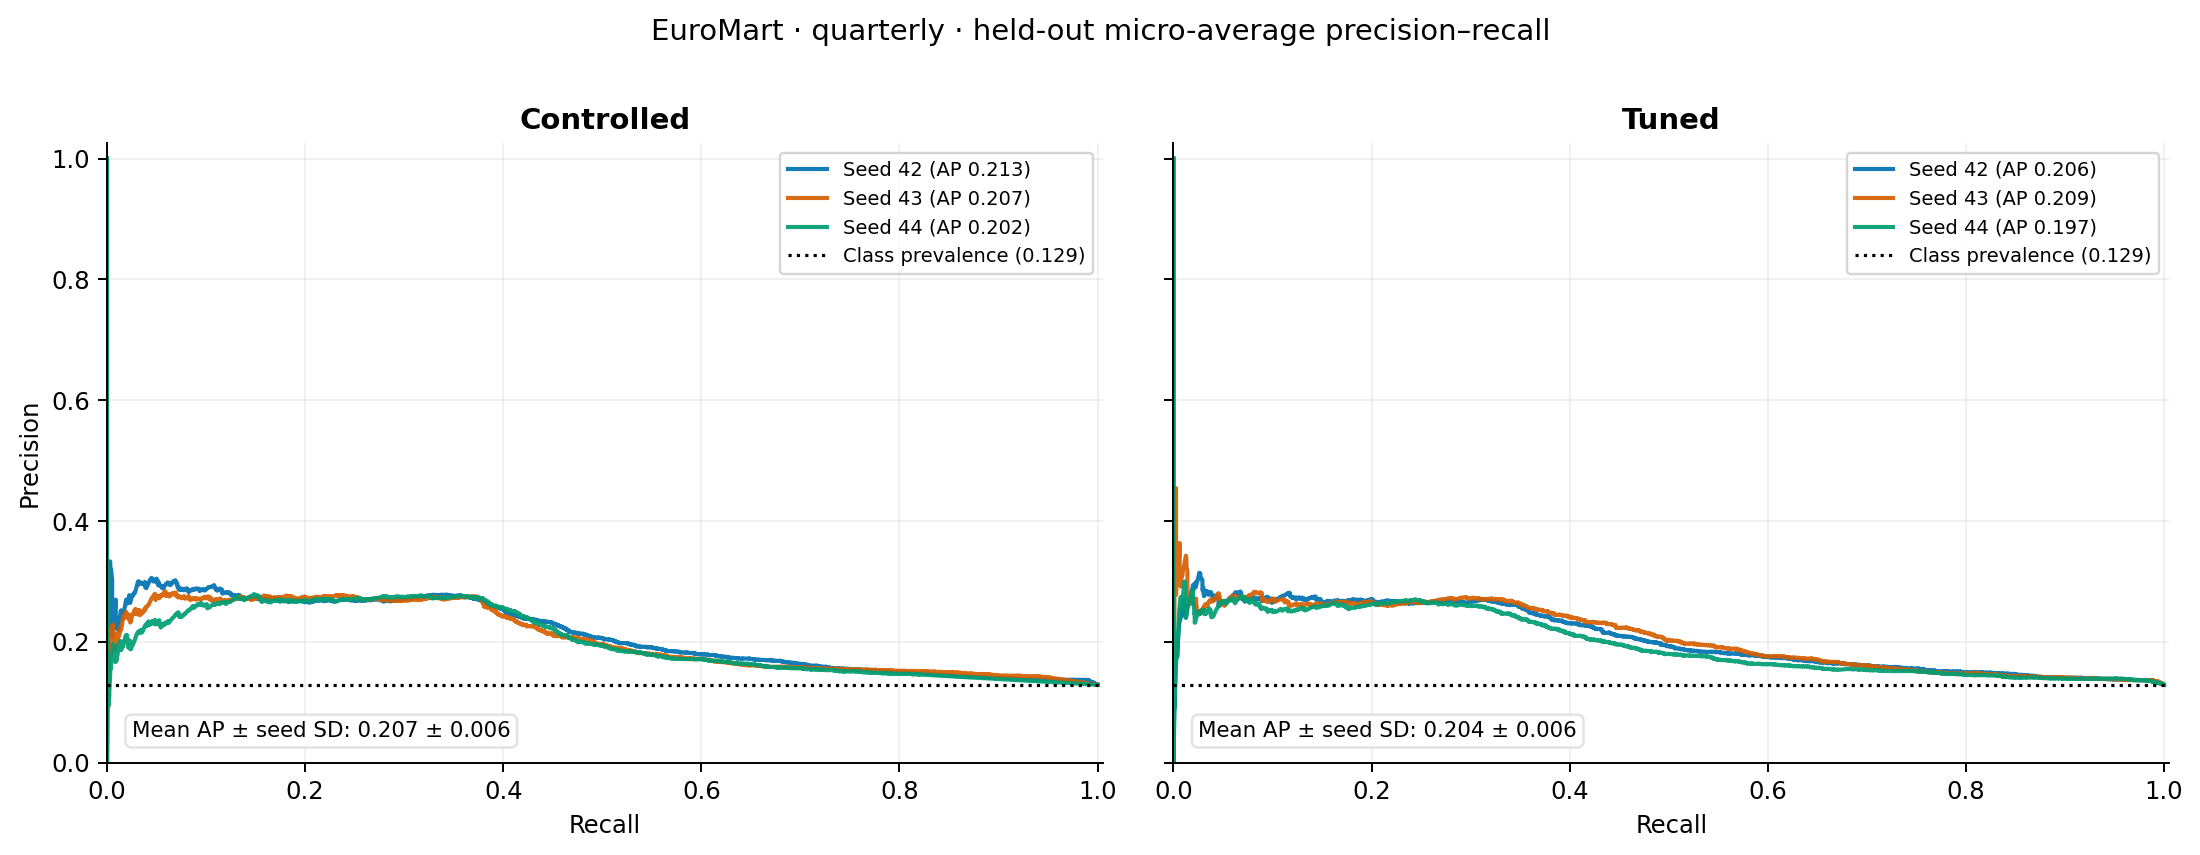

#### Retail POS · monthly

[CHECKPOINT AP WARNING] retail_pos/GraphSAGE-Tuned/seed43: recomputed=0.392735388 reported=0.392730632 delta=+4.75525621e-06


**Held-out pair-level PR reconstructed from original checkpoint float32 scores. Fixed seed colours; dotted black prevalence baseline; sample SD across seeds. If an AP verification mismatch occurs it is shown with an asterisk and audit row.**

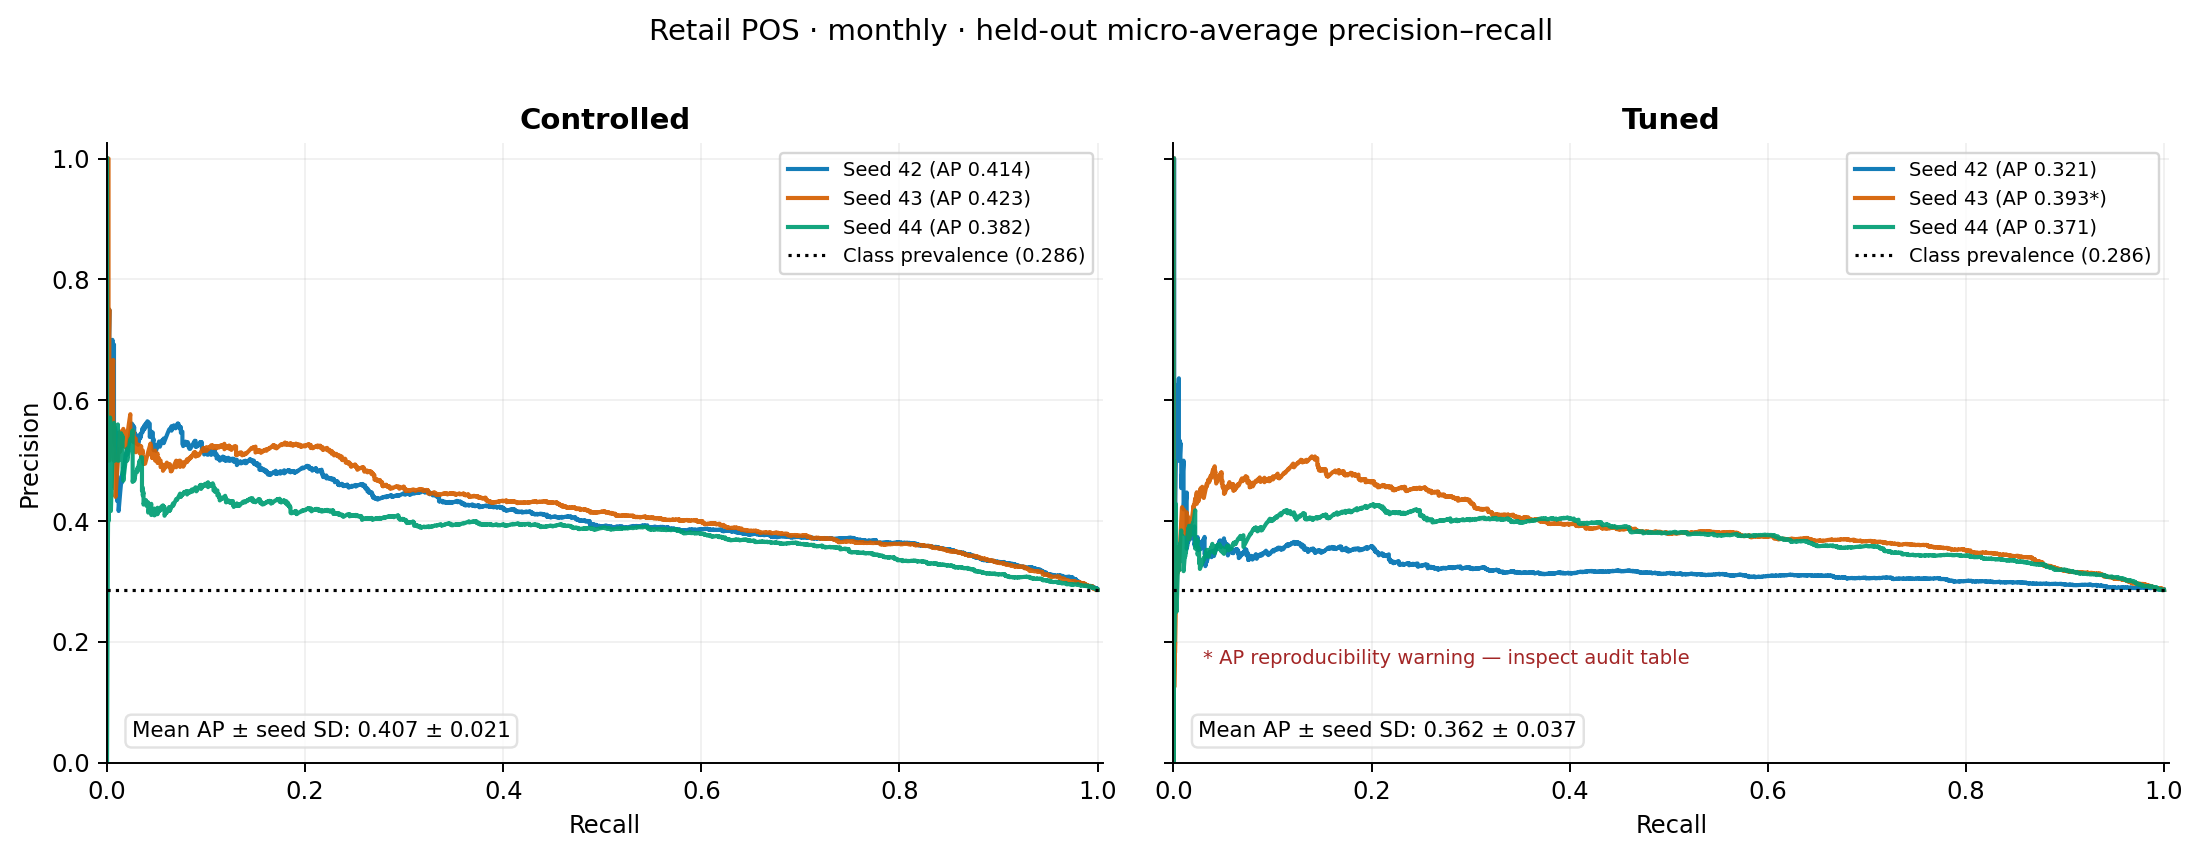

**Checkpoint AP per held-out seed**

,dataset,method,seed,ap,reported_ap,ap_verified,positive_prevalence,positive_pairs,all_pairs,test_periods,exact_points
0,euromart,GraphSAGE-Controlled,42,0.2130,0.2130,True,0.1291,1914,14824,3,14823
1,euromart,GraphSAGE-Controlled,43,0.2072,0.2072,True,0.1291,1914,14824,3,12932
2,euromart,GraphSAGE-Controlled,44,0.2015,0.2015,True,0.1291,1914,14824,3,10771
3,euromart,GraphSAGE-Tuned,42,0.2063,0.2063,True,0.1291,1914,14824,3,14814
4,euromart,GraphSAGE-Tuned,43,0.2092,0.2092,True,0.1291,1914,14824,3,14808
5,euromart,GraphSAGE-Tuned,44,0.1973,0.1973,True,0.1291,1914,14824,3,14814
6,retail_pos,GraphSAGE-Controlled,42,0.4144,0.4144,True,0.2860,1274,4454,2,4455
7,retail_pos,GraphSAGE-Controlled,43,0.4229,0.4229,True,0.2860,1274,4454,2,4452
8,retail_pos,GraphSAGE-Controlled,44,0.3825,0.3825,True,0.2860,1274,4454,2,4455
9,retail_pos,GraphSAGE-Tuned,42,0.3212,0.3212,True,0.2860,1274,4454,2,4453


**Held-out Average Precision: mean ± sample SD**

,dataset,method,n_seeds,mean_average_precision,sd_average_precision,positive_prevalence,verified_seed_count
0,euromart,GraphSAGE-Controlled,3,0.2073,0.0058,0.1291,3
1,euromart,GraphSAGE-Tuned,3,0.2043,0.0062,0.1291,3
2,retail_pos,GraphSAGE-Controlled,3,0.4066,0.0213,0.2860,3
3,retail_pos,GraphSAGE-Tuned,3,0.3617,0.0367,0.2860,2


**Checkpoint versus stored CSV prediction audit**

,dataset,method,seed,checkpoint_ap,reported_test_ap,checkpoint_minus_reported_ap,checkpoint_ap_matches_test,csv_ap_float64,csv_ap_float32,csv_cohort_matches_checkpoint,csv_max_abs_score_difference,csv_files
0,euromart,GraphSAGE-Controlled,42,0.2130,0.2130,0.0,True,0.2130,0.2130,True,0.0,3
1,euromart,GraphSAGE-Controlled,43,0.2072,0.2072,0.0,True,0.2072,0.2072,True,0.0,3
2,euromart,GraphSAGE-Controlled,44,0.2015,0.2015,0.0,True,0.2015,0.2015,True,0.0,3
3,euromart,GraphSAGE-Tuned,42,0.2063,0.2063,0.0,True,0.2063,0.2063,True,0.0,3
4,euromart,GraphSAGE-Tuned,43,0.2092,0.2092,0.0,True,0.2092,0.2092,True,0.0,3
5,euromart,GraphSAGE-Tuned,44,0.1973,0.1973,0.0,True,0.1973,0.1973,True,0.0,3
6,retail_pos,GraphSAGE-Controlled,42,0.4144,0.4144,0.0,True,0.4144,0.4144,True,0.0,2
7,retail_pos,GraphSAGE-Controlled,43,0.4229,0.4229,0.0,True,0.4229,0.4229,True,0.0,2
8,retail_pos,GraphSAGE-Controlled,44,0.3825,0.3825,0.0,True,0.3825,0.3825,True,0.0,2
9,retail_pos,GraphSAGE-Tuned,42,0.3212,0.3212,-0.0,True,0.3212,0.3212,True,0.0,2


In [ ]:
# 05.1 · Recompute original float32 test logits directly from checkpoints.
# No retraining: reuses previously selected configurations and frozen weights.
from sklearn.metrics import precision_recall_curve,average_precision_score
PR_METHODS=('GraphSAGE-Controlled','GraphSAGE-Tuned')
PR_COLOURS=globals().get('SEED_COLOURS',{42:'#0072B2',43:'#D55E00',44:'#009E73'})
PR_RESULTS=[];PR_SUMMARIES=[];PR_AUDIT=[]
PR_PLOT_MAX_POINTS=4000

def checkpoint_pr(ds,method,seed,snaps):
    cfg=FROZEN['datasets'][ds][method]
    cp=OUT/f'checkpoints/{ds}/{method}/seed{seed}.pt'
    if not cp.exists():raise FileNotFoundError(f'Missing saved checkpoint: {cp}')
    model,meta=load_checkpoint(cfg,cp,seed)
    if meta.get('disable_messages',False):raise AssertionError('Headline messages unexpectedly disabled')
    labels=[];scores=[]
    model.eval()
    with torch.no_grad():
        for snap in snaps:
            r=tensor(snap)
            pred=model(r)
            diagnose(pred)
            labels.append(r['labels'].cpu().numpy().astype(np.uint8).ravel())
            scores.append(pred.cpu().numpy().ravel())
    y=np.concatenate(labels);s=np.concatenate(scores)
    if s.dtype!=np.float32 or not np.isfinite(s).all() or not (0<y.sum()<len(y)):
        raise ValueError(f'Unexpected checkpoint prediction array: {ds}/{method}/seed{seed}')
    precision,recall,_=precision_recall_curve(y,s)
    ap=float(average_precision_score(y,s))
    ref=HEADLINE[(HEADLINE.dataset==ds)&(HEADLINE.method==method)&
                 (HEADLINE.split=='test')&(HEADLINE.seed==seed)]
    if len(ref)!=1:raise AssertionError('Expected one held-out row per seed')
    reported=float(ref['PR-AUC'].iloc[0])
    diff=ap-reported
    verified=bool(np.isclose(ap,reported,atol=1e-6,rtol=1e-6))
    if not verified:
        print(f'[CHECKPOINT AP WARNING] {ds}/{method}/seed{seed}: '
              f'recomputed={ap:.9f} reported={reported:.9f} delta={diff:+.9g}')
    folder=OUT/'predictions'/ds/method/f'seed{seed}'/'test'
    files=sorted(folder.glob('*_candidates.csv.gz'))
    ap_csv64=np.nan;ap_csv32=np.nan;cohort_match=None;score_diff=np.nan
    if files:
        csv=pd.concat([pd.read_csv(path,usecols=['label','score'])
                       for path in files],ignore_index=True)
        cy=csv.label.to_numpy(np.uint8)
        cs=csv.score.to_numpy(np.float64)
        cohort_match=bool(np.array_equal(cy,y))
        if np.isfinite(cs).all() and 0<cy.sum()<len(cy):
            ap_csv64=float(average_precision_score(cy,cs))
            ap_csv32=float(average_precision_score(cy,cs.astype(np.float32)))
        if cohort_match:
            score_diff=float(np.max(np.abs(cs-s.astype(np.float64))))
        else:
            print(f'[CSV COHORT WARNING] {ds}/{method}/seed{seed}: CSV labels/order differ')
    PR_AUDIT.append(dict(dataset=ds,method=method,seed=int(seed),
        checkpoint_ap=ap,reported_test_ap=reported,
        checkpoint_minus_reported_ap=diff,checkpoint_ap_matches_test=verified,
        csv_ap_float64=ap_csv64,csv_ap_float32=ap_csv32,
        csv_cohort_matches_checkpoint=cohort_match,
        csv_max_abs_score_difference=score_diff,csv_files=len(files)))
    # precision_recall_curve emits descending recall; reverse for increasing x-axis.
    rr=recall[::-1];pp=precision[::-1]
    save_csv(pd.DataFrame(dict(recall=rr,precision=pp,dataset=ds,
                 method=method,seed=int(seed))),
             OUT/f'tables/pr_curves/{ds}/{method}_seed{seed}.csv.gz')
    ix=np.unique(np.linspace(0,len(rr)-1,min(PR_PLOT_MAX_POINTS,len(rr)),dtype=int))
    info=dict(dataset=ds,method=method,seed=int(seed),ap=ap,
              reported_ap=reported,ap_verified=verified,
              positive_prevalence=float(y.mean()),positive_pairs=int(y.sum()),
              all_pairs=len(y),test_periods=len(snaps),exact_points=len(rr))
    return info,rr[ix],pp[ix],hashlib.sha256(y.tobytes()).hexdigest()

for ds in DATASETS:
    ds_header(ds)
    snapshots=get_splits(ds,('test',))['test']
    fig,axs=plt.subplots(1,2,figsize=(12.8,5),sharex=True,sharey=True)
    label_hashes=set()
    for method,ax in zip(PR_METHODS,axs):
        eligible=HEADLINE[(HEADLINE.dataset==ds)&(HEADLINE.method==method)&
                          (HEADLINE.split=='test')]
        group=[]
        if eligible.empty:
            plot_empty(ax,'No successful held-out seeds')
            continue
        for seed in sorted(eligible.seed.unique()):
            info,r,p,h=checkpoint_pr(ds,method,int(seed),snapshots)
            PR_RESULTS.append(info);group.append(info);label_hashes.add(h)
            star='' if info['ap_verified'] else '*'
            ax.plot(r,p,color=PR_COLOURS.get(int(seed),'#777777'),lw=1.7,
                    alpha=.92,label=f'Seed {seed} (AP {info["ap"]:.3f}{star})')
        prevalence=group[0]['positive_prevalence']
        ax.axhline(prevalence,color='black',ls=':',lw=1.3,
                   label=f'Class prevalence ({prevalence:.3f})')
        aps=np.array([q['ap'] for q in group])
        mean=float(aps.mean())
        sd=float(aps.std(ddof=1)) if len(aps)>=2 else np.nan
        label=f'{mean:.3f} ± {sd:.3f}' if len(aps)>=2 else f'{mean:.3f} (n=1; SD N/A)'
        ax.text(.025,.035,f'Mean AP ± seed SD: {label}',fontsize=8.8,
                transform=ax.transAxes,va='bottom',
                bbox=dict(facecolor='white',edgecolor='#dddddd',alpha=.85,
                          boxstyle='round,pad=.3'))
        if not all(z['ap_verified'] for z in group):
            ax.text(.03,.16,'* AP reproducibility warning — inspect audit table',
                    transform=ax.transAxes,color='#a32626',fontsize=8)
        PR_SUMMARIES.append(dict(dataset=ds,method=method,n_seeds=len(group),
             mean_average_precision=mean,sd_average_precision=sd,
             positive_prevalence=prevalence,
             verified_seed_count=sum(x['ap_verified'] for x in group)))
        ax.set(title=method.replace('GraphSAGE-',''),xlabel='Recall',
               xlim=(0,1.005),ylim=(0,1.025))
        ax.grid(alpha=.18);ax.legend(fontsize=8,loc='best')
    if len(label_hashes)>1:
        plt.close(fig)
        raise AssertionError('Test label cohorts differ between model seeds')
    axs[0].set_ylabel('Precision')
    fig.suptitle(('EuroMart · quarterly' if ds=='euromart' else 'Retail POS · monthly')
                 +' · held-out micro-average precision–recall')
    chapter_figure(fig,ds,'01_model_performance',f'{ds}_heldout_precision_recall',
        'Held-out pair-level PR reconstructed from original checkpoint float32 scores. '
        'Fixed seed colours; dotted black prevalence baseline; sample SD across seeds. '
        'If an AP verification mismatch occurs it is shown with an asterisk and audit row.',
        'tables/pr_curves/*/*.csv.gz')
PR_SEED_TABLE=pd.DataFrame(PR_RESULTS)
PR_SUMMARY_TABLE=pd.DataFrame(PR_SUMMARIES)
PR_AUDIT_TABLE=pd.DataFrame(PR_AUDIT)
save_csv(PR_SEED_TABLE,OUT/'tables/run6_precision_recall_per_seed.csv')
save_csv(PR_SUMMARY_TABLE,OUT/'tables/run6_precision_recall_summary.csv')
save_csv(PR_AUDIT_TABLE,OUT/'tables/run6_precision_recall_prediction_audit.csv')
numeric_table(PR_SEED_TABLE,'Checkpoint AP per held-out seed')
numeric_table(PR_SUMMARY_TABLE,'Held-out Average Precision: mean ± sample SD')
numeric_table(PR_AUDIT_TABLE,'Checkpoint versus stored CSV prediction audit')


## 06 · Paired evidence and temporal generalisation

**Question.** Is an observed gain robust to heterogeneity among customers and evaluated periods?

A paired customer-cluster bootstrap resamples customer IDs, retaining the customer's repeated held-out observations together. Predictions are first averaged over available model seeds. Its 95% intervals are **conditional on trained models and observed test periods**; they do not capture full seed-selection or future-quarter uncertainty.

Temporal curves distinguish the EuroMart quarters from Retail POS months. Only three EuroMart test quarters and two Retail POS test months are available, so these plots reveal heterogeneity rather than reliable estimates of long-run drift.

#### EuroMart · quarterly

**Customer-cluster paired difference estimates**

,method,baseline,delta,ci_low,ci_high,n_customers
0,GraphSAGE-Controlled,FeatureLogistic,-0.0087,-0.0192,0.0016,583
1,GraphSAGE-Controlled,GlobalPopularity,-0.0061,-0.0123,-0.0001,583
2,GraphSAGE-Tuned,FeatureLogistic,0.0005,-0.0063,0.0069,583
3,GraphSAGE-Tuned,GlobalPopularity,0.0032,-0.0067,0.0129,583


**Difference from validation-frozen and popularity comparators; intervals conditional on observed periods**

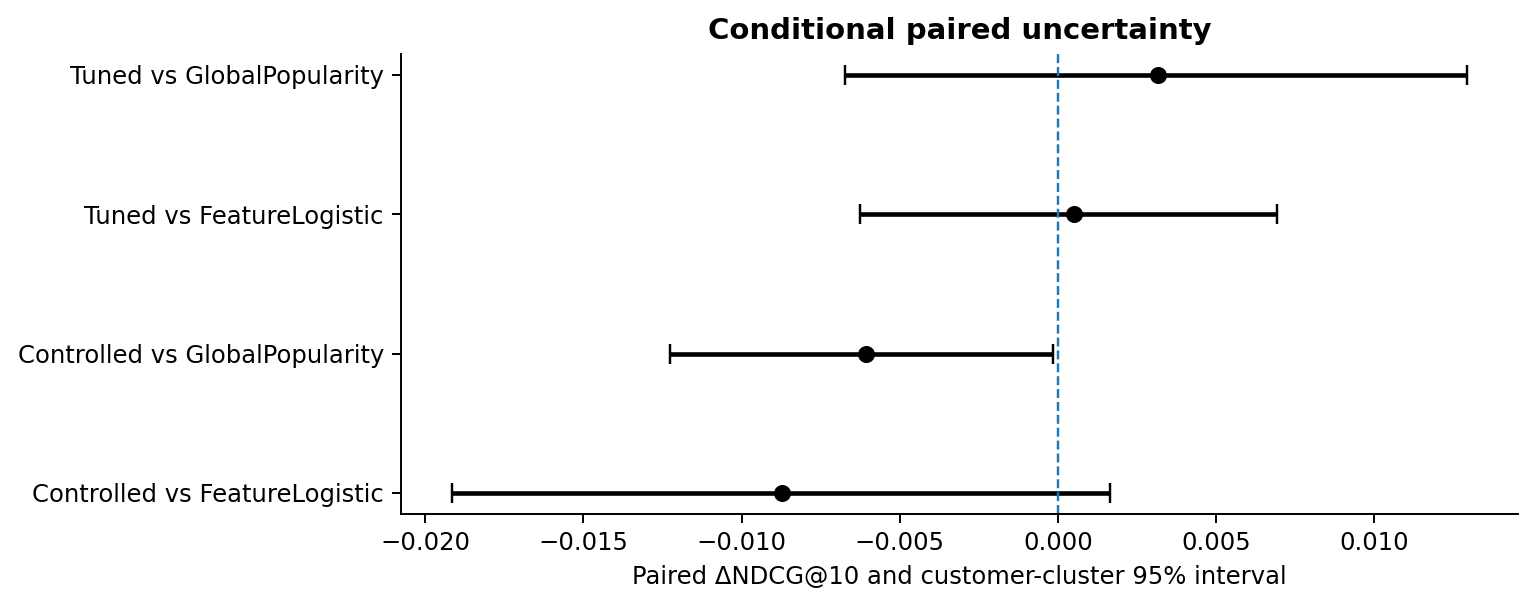

**Test-period heterogeneity: individual quarters/months, not a long-run temporal stability estimate**

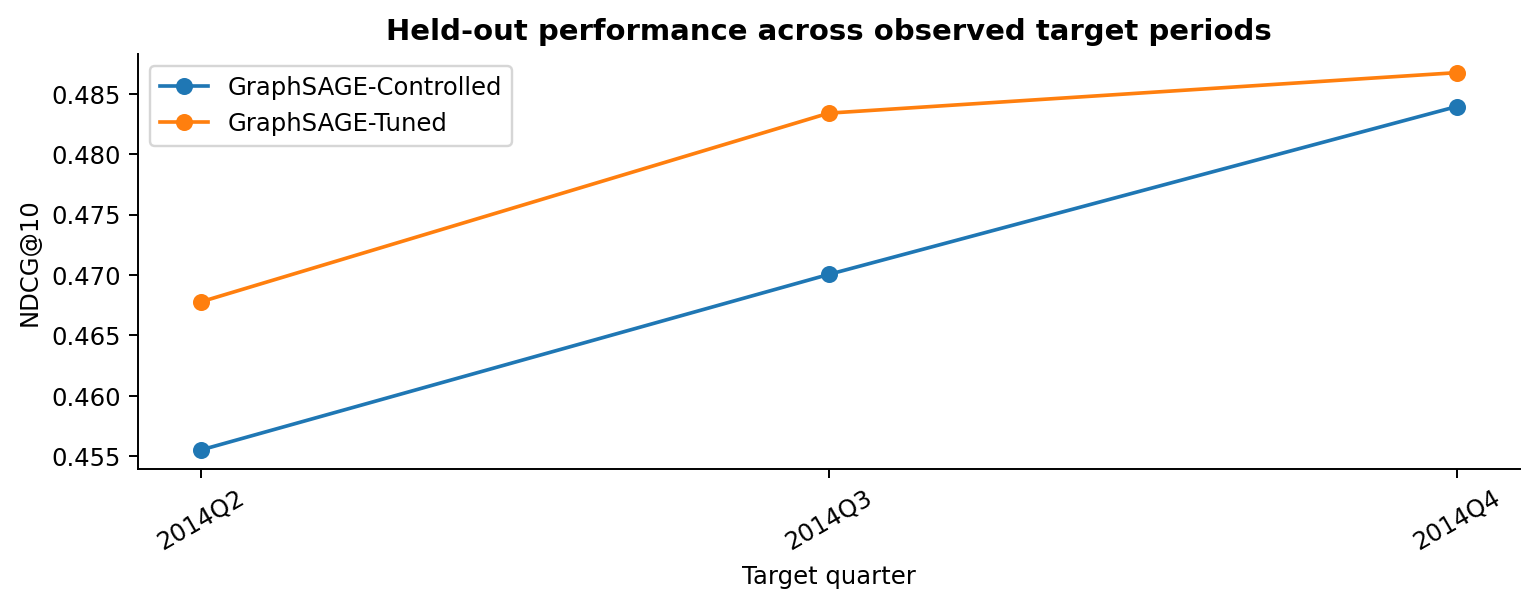

#### Retail POS · monthly

**Customer-cluster paired difference estimates**

,method,baseline,delta,ci_low,ci_high,n_customers
0,GraphSAGE-Controlled,FeatureMLP,-0.0004,-0.0018,0.0009,235
1,GraphSAGE-Controlled,GlobalPopularity,-0.0004,-0.0018,0.0009,235
2,GraphSAGE-Tuned,FeatureMLP,-0.0003,-0.0034,0.0029,235
3,GraphSAGE-Tuned,GlobalPopularity,-0.0003,-0.0034,0.0029,235


**Difference from validation-frozen and popularity comparators; intervals conditional on observed periods**

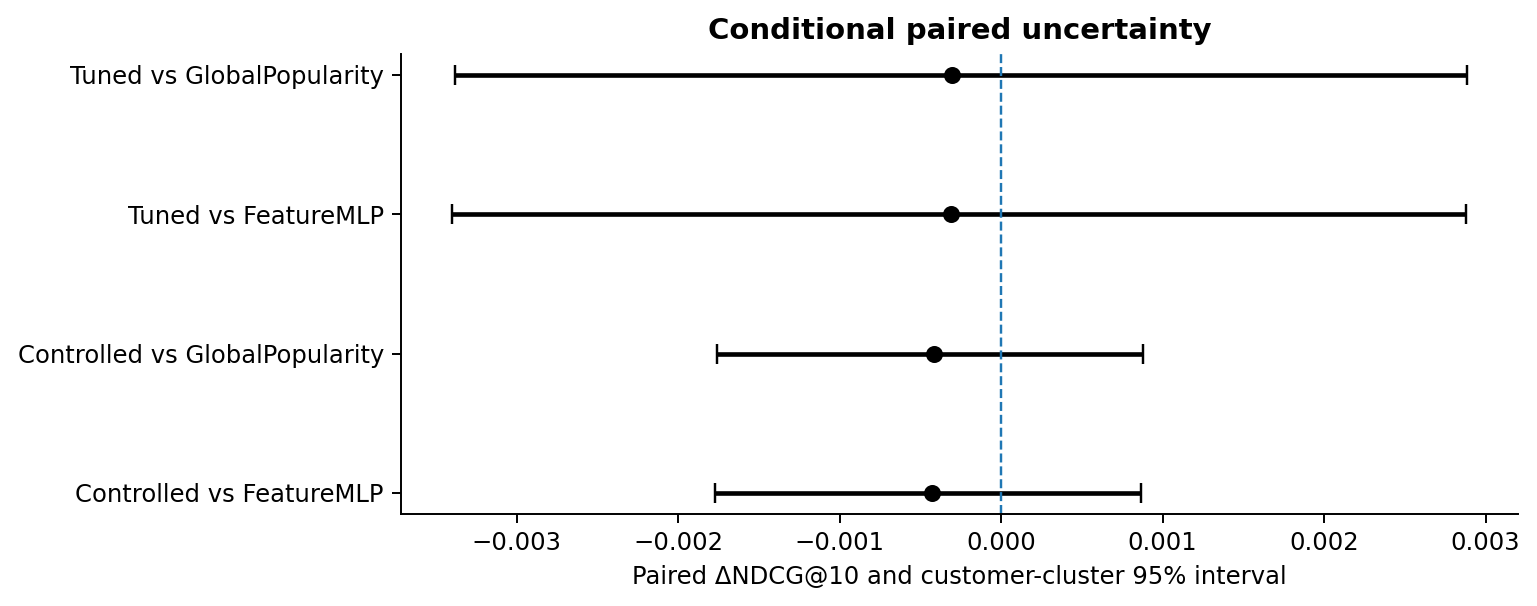

**Test-period heterogeneity: individual quarters/months, not a long-run temporal stability estimate**

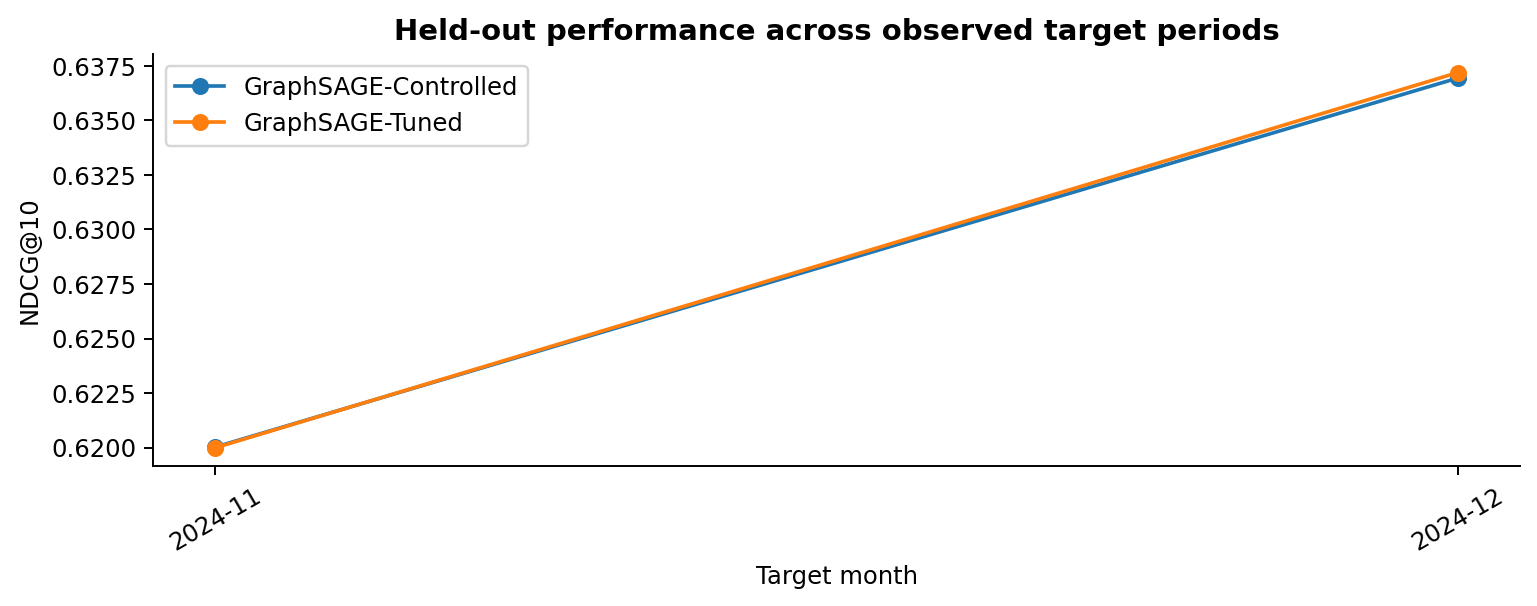

In [ ]:
# Bootstrap compares matching customer-period cohorts and a validation-frozen Run 3 winner.
MAIN_INSTANCES=pd.concat(INSTANCES,ignore_index=True)
MAIN_MONTHS=pd.DataFrame(MONTHS)
def paired_bootstrap(ds,method,baseline):
    g=MAIN_INSTANCES[(MAIN_INSTANCES.dataset==ds)&(MAIN_INSTANCES.method==method)&
                     (MAIN_INSTANCES.split=='test')].groupby(['target_month','customer_idx'],as_index=False)['NDCG@10'].mean()
    paths=sorted((RUN3/f'predictions/{ds}/{baseline}').glob('seed*/test_instances.csv.gz'))
    if not paths:raise FileNotFoundError(f'Run 3 baseline instance records missing: {ds}/{baseline}')
    b=pd.concat([pd.read_csv(p)[['target_month','customer_idx','NDCG@10']] for p in paths],ignore_index=True)
    b=b.groupby(['target_month','customer_idx'],as_index=False)['NDCG@10'].mean()
    x=g.merge(b,on=['target_month','customer_idx'],validate='one_to_one',suffixes=('_gnn','_baseline'))
    assert len(x)==len(g)==len(b),'Misaligned paired evaluation cohort'
    x['delta']=x['NDCG@10_gnn']-x['NDCG@10_baseline']
    f=x.groupby('customer_idx').delta.agg(['sum','count']);rng=np.random.default_rng(2026)
    sums=f['sum'].to_numpy();counts=f['count'].to_numpy();n=len(f)
    # Chunk sampling so 5000 resamples never construct an unnecessarily huge array.
    draws=[]
    for start in range(0,B['boot'],250):
        ix=rng.integers(n,size=(min(250,B['boot']-start),n))
        draws.extend((sums[ix].sum(axis=1)/counts[ix].sum(axis=1)).tolist())
    return {'dataset':ds,'method':method,'baseline':baseline,'delta':float(x.delta.mean()),
       'ci_low':float(np.quantile(draws,.025)),'ci_high':float(np.quantile(draws,.975)),
       'n_customers':n,'n_examples':len(x),'bootstrap_draws':B['boot'],
       'uncertainty_scope':'conditional_on_seed_averages_and_observed_test_periods'}
BOOT=[]
for ds in DATASETS:
    ds_header(ds)
    baseline=SELECTION3[ds]['best_validation_method']
    for m in ('GraphSAGE-Controlled','GraphSAGE-Tuned'):
        for b in dict.fromkeys([baseline,'GlobalPopularity']):BOOT.append(paired_bootstrap(ds,m,b))
    bb=pd.DataFrame(BOOT);part=bb[bb.dataset==ds].reset_index(drop=True)
    numeric_table(part[['method','baseline','delta','ci_low','ci_high','n_customers']],
                  'Customer-cluster paired difference estimates')
    fig,ax=plt.subplots(figsize=(9,3.7));y=np.arange(len(part))
    ax.errorbar(part.delta,y,xerr=[part.delta-part.ci_low,part.ci_high-part.delta],fmt='o',color='black',ecolor='black',elinewidth=1.9,capsize=4)
    ax.axvline(0,lw=1,ls='--');ax.set_yticks(y,[f'{r.method.replace("GraphSAGE-","")} vs {r.baseline}' for r in part.itertuples()])
    ax.set(xlabel='Paired ΔNDCG@10 and customer-cluster 95% interval',title='Conditional paired uncertainty')
    chapter_figure(fig,ds,'02_statistical_uncertainty',f'{ds}_paired_customer_bootstrap',
                   'Difference from validation-frozen and popularity comparators; intervals conditional on observed periods')
    g=MAIN_MONTHS[(MAIN_MONTHS.dataset==ds)&(MAIN_MONTHS.split=='test')]
    fig,ax=plt.subplots(figsize=(9,3.7))
    for method,ss in g.groupby('method'):
        z=ss.groupby('target_month',sort=True)['NDCG@10'].mean()
        ax.plot(z.index,z.values,marker='o',label=method)
    ax.set(xlabel='Target quarter' if ds=='euromart' else 'Target month',ylabel='NDCG@10',
           title='Held-out performance across observed target periods')
    ax.tick_params(axis='x',rotation=30);ax.legend()
    chapter_figure(fig,ds,'03_temporal_generalisation',f'{ds}_target_period_performance',
                   'Test-period heterogeneity: individual quarters/months, not a long-run temporal stability estimate')
save_csv(pd.DataFrame(BOOT),OUT/'tables/run6_paired_bootstrap.csv')

## 07 · Interventions: separating graph structure from node attributes

**Question.** Does message passing, the placement of edges or increasing graph depth matter when other training choices are held fixed?

All ablations retrain a controlled architecture under the stated intervention, using the same final seeds. The `NoMessages` condition disables incoming messages *during both training and inference*. Feature removals zero selected node inputs. Degree-preserving edge swaps preserve customer/category degrees but not individual historical edge identities.

**Scope warning:** rewiring holds historically derived node features fixed, so it is a sensitivity test of adjacency structure, *not* a fully re-generated counterfactual retail world. The ablation panels are exploratory on the observed test period and should not be used to retune the main model.

In [ ]:
for ds in DATASETS:
    sn=get_splits(ds,('train','val','test'))
    frozen=FROZEN['datasets'][ds]
    print('ABLATIONS',ds,'· profile',PROFILE,flush=True)
    for name,cfg,mask in ablation_plan(frozen['GraphSAGE-Controlled'],frozen['GraphSAGE-Tuned']):
        evaluate_variant(ds,'GraphSAGE-'+name,cfg,sn,mask=mask,seeds=B['ablation_seeds'],allow_all_failed=True)
ALL_METRICS=pd.DataFrame(METRICS)
ALL_INSTANCES=pd.concat(INSTANCES,ignore_index=True)
ALL_MONTHS=pd.DataFrame(MONTHS)
ALL_NOVELTY=pd.DataFrame(NOVELTY)
ALL_DIVERSITY=pd.DataFrame(DIVERSITY)
ALL_LAYERS=pd.DataFrame(LAYERS)
ALL_HISTORIES=pd.concat(HISTORIES,ignore_index=True) if HISTORIES else pd.DataFrame()
for table,df in [('all_metrics',ALL_METRICS),('monthly',ALL_MONTHS),('instances',ALL_INSTANCES),
                 ('novelty',ALL_NOVELTY),('diversity',ALL_DIVERSITY),('layers',ALL_LAYERS)]:
    save_csv(df,OUT/f'tables/run6_{table}.csv.gz')
if len(ALL_HISTORIES):save_csv(ALL_HISTORIES,OUT/'tables/run6_epoch_history.csv.gz')
# Registry includes all attempts, including zero-success ablations.
summary=[]
seed_audit=pd.DataFrame(STATUS).drop_duplicates(['dataset','method','seed'],keep='last')
for (ds,method),attempts in seed_audit.groupby(['dataset','method']):
    scores=ALL_METRICS[(ALL_METRICS.dataset==ds)&(ALL_METRICS.method==method)&
                       (ALL_METRICS.split=='test')]
    n=len(scores);n_all=len(attempts)
    row=dict(dataset=ds,method=method,attempted_seeds=n_all,valid_seeds=n,
             failed_seeds=int((attempts.status!='ok').sum()),
             completion_status='all_failed' if n==0 else ('partial' if n<n_all else 'complete'))
    for metric in ('NDCG@3','NDCG@5','NDCG@10','Recall@10','PR-AUC'):
        row[metric]=float(scores[metric].mean()) if n else np.nan
        row[metric+'_seed_sd']=float(scores[metric].std(ddof=1)) if n>=2 else np.nan
    summary.append(row)
SUMMARY=pd.DataFrame(summary).sort_values(['dataset','NDCG@10'],ascending=[True,False],na_position='last')
save_csv(SUMMARY,OUT/'tables/run6_test_summary.csv')
save_csv(seed_audit,OUT/'tables/run6_seed_audit.csv')
numeric_table(SUMMARY[['dataset','method','valid_seeds','NDCG@10','NDCG@10_seed_sd']],
              'All controlled interventions (test; descriptive only)')

ABLATIONS euromart · profile exhaustive
FINAL euromart GraphSAGE-NoMessages 42 ok train_s= 0.6028882440000416 test_forward_s= 0.0004421300000103656 
FINAL euromart GraphSAGE-NoMessages 43 ok train_s= 0.6560694540000895 test_forward_s= 0.00036646000000928325 
FINAL euromart GraphSAGE-NoMessages 44 ok train_s= 0.5836657340000784 test_forward_s= 0.0003374000000349042 
FINAL euromart GraphSAGE-NoCustomerFeatures 42 ok train_s= 0.7934454050000568 test_forward_s= 0.0006579700000202138 
FINAL euromart GraphSAGE-NoCustomerFeatures 43 ok train_s= 0.8679715149999083 test_forward_s= 0.000895000000014079 
FINAL euromart GraphSAGE-NoCustomerFeatures 44 ok train_s= 0.8063588960000061 test_forward_s= 0.0006769500000700646 
FINAL euromart GraphSAGE-NoCategoryFeatures 42 ok train_s= 3.1531138210000336 test_forward_s= 0.0006972500000301807 
FINAL euromart GraphSAGE-NoCategoryFeatures 43 ok train_s= 1.6530984309999894 test_forward_s= 0.0007099800000105461 
FINAL euromart GraphSAGE-NoCategoryFeatures 44 o

**All controlled interventions (test; descriptive only)**

,dataset,method,valid_seeds,NDCG@10,NDCG@10_seed_sd
1,euromart,GraphSAGE-DegreeSqrtAggregation,3,0.4821,0.0012
19,euromart,GraphSAGE-Tuned,3,0.4805,0.0030
6,euromart,GraphSAGE-Depth3Residual,3,0.4790,0.0034
9,euromart,GraphSAGE-MaxAggregation,3,0.4774,0.0017
2,euromart,GraphSAGE-Depth1,3,0.4767,0.0039
15,euromart,GraphSAGE-Rewired2,3,0.4763,0.0049
8,euromart,GraphSAGE-Depth4,3,0.4756,0.0060
12,euromart,GraphSAGE-NoMessages,3,0.4747,0.0040
16,euromart,GraphSAGE-Rewired3,3,0.4740,0.0064
17,euromart,GraphSAGE-SumAggregation,3,0.4738,0.0051


### 07.0 · Runtime and GNN-team benchmarking

The comparison explicitly separates (i) HPO search cost, (ii) final selected model fit wall time, including epoch validation and early stopping, (iii) optimisation-only and training/validation monitoring time, (iv) held-out forward-pass inference wall time and candidate-pair throughput, and (v) individual ablation and feature-setup costs.

Timing uses monotonic wall-clock measurements with explicit CUDA synchronisation. Test inference excludes a warmup. The peak GPU memory figure is maximum CUDA memory *allocated* during training. All mean ± SD intervals use the sample SD across successful fresh seeds, and report SD as missing when fewer than two observations are available.

The team comparison table contains only Controlled and Tuned GraphSAGE. It does not attribute the whole hyperparameter search to one model fit. HPO is given as a separate experimental resource budget. Hardware, compute device, software versions, and caching policy are stored in the machine-readable benchmark manifest. Comparisons with teammates should match device, data scope, inference and fit timing boundaries.



**Team GNN comparison — measured GraphSAGE performance and cost**

,dataset,model_family,method,successful_seeds,freshly_trained_seeds,test_ndcg10_mean,test_ndcg10_seed_sd,test_recall10_mean,test_recall10_seed_sd,test_ap_mean,...,epochs_mean,epochs_seed_sd,trainable_parameters,peak_gpu_allocated_mib_mean,peak_gpu_allocated_mib_seed_sd,device,gpu,include_validation_monitoring_in_training_time,excluded_from_training_time,measured_this_execution
0,euromart,GraphSAGE,GraphSAGE-Controlled,3,3,0.4713,0.0068,0.7167,0.0118,0.2073,...,23.3333,1.1547,17664.0,30.4531,0.1218,cuda,NVIDIA RTX PRO 6000 Blackwell Server Edition,True,"HPO, data preparation, held-out evaluation, fi...",True
1,euromart,GraphSAGE,GraphSAGE-Tuned,3,3,0.4805,0.0030,0.7225,0.0077,0.2043,...,35.3333,4.9329,110208.0,63.9408,0.5289,cuda,NVIDIA RTX PRO 6000 Blackwell Server Edition,True,"HPO, data preparation, held-out evaluation, fi...",True
2,retail_pos,GraphSAGE,GraphSAGE-Controlled,3,3,0.6287,0.0009,0.7664,0.0034,0.4066,...,22.3333,1.5275,17664.0,30.2148,0.0947,cuda,NVIDIA RTX PRO 6000 Blackwell Server Edition,True,"HPO, data preparation, held-out evaluation, fi...",True
3,retail_pos,GraphSAGE,GraphSAGE-Tuned,3,3,0.6288,0.0027,0.7685,0.0004,0.3617,...,34.0000,5.5678,18688.0,30.2568,0.0981,cuda,NVIDIA RTX PRO 6000 Blackwell Server Edition,True,"HPO, data preparation, held-out evaluation, fi...",True


**Full validation-only search cost, separately reported**

,dataset,stage,attempted,successful,failed,elapsed_seconds_total,computed_this_execution_seconds
0,euromart,initial,96,93,3,73.5985,73.5985
1,euromart,rate_screen,5,4,1,3.4007,3.4007
2,euromart,rerank,15,15,0,14.1442,14.1442
3,retail_pos,initial,96,93,3,48.4924,48.4924
4,retail_pos,rate_screen,5,4,1,1.8892,1.8892
5,retail_pos,rerank,15,15,0,8.1825,8.1825


**Experimental resource accounting by dataset**

,dataset,hpo_trial_wall_seconds,headline_seed_pipeline_wall_seconds,ablation_seed_pipeline_wall_seconds,graph_feature_preparation_seconds,note
0,euromart,91.1434,9.1334,59.4138,2.1091,"Partial total excludes Run2/Run3, notebook set..."
1,retail_pos,58.5640,4.5387,40.2401,1.7441,"Partial total excludes Run2/Run3, notebook set..."


**Final fit and held-out forward-pass runtime. Black whiskers are sample seed SD only when two or more freshly timed seeds are available; HPO is excluded.**

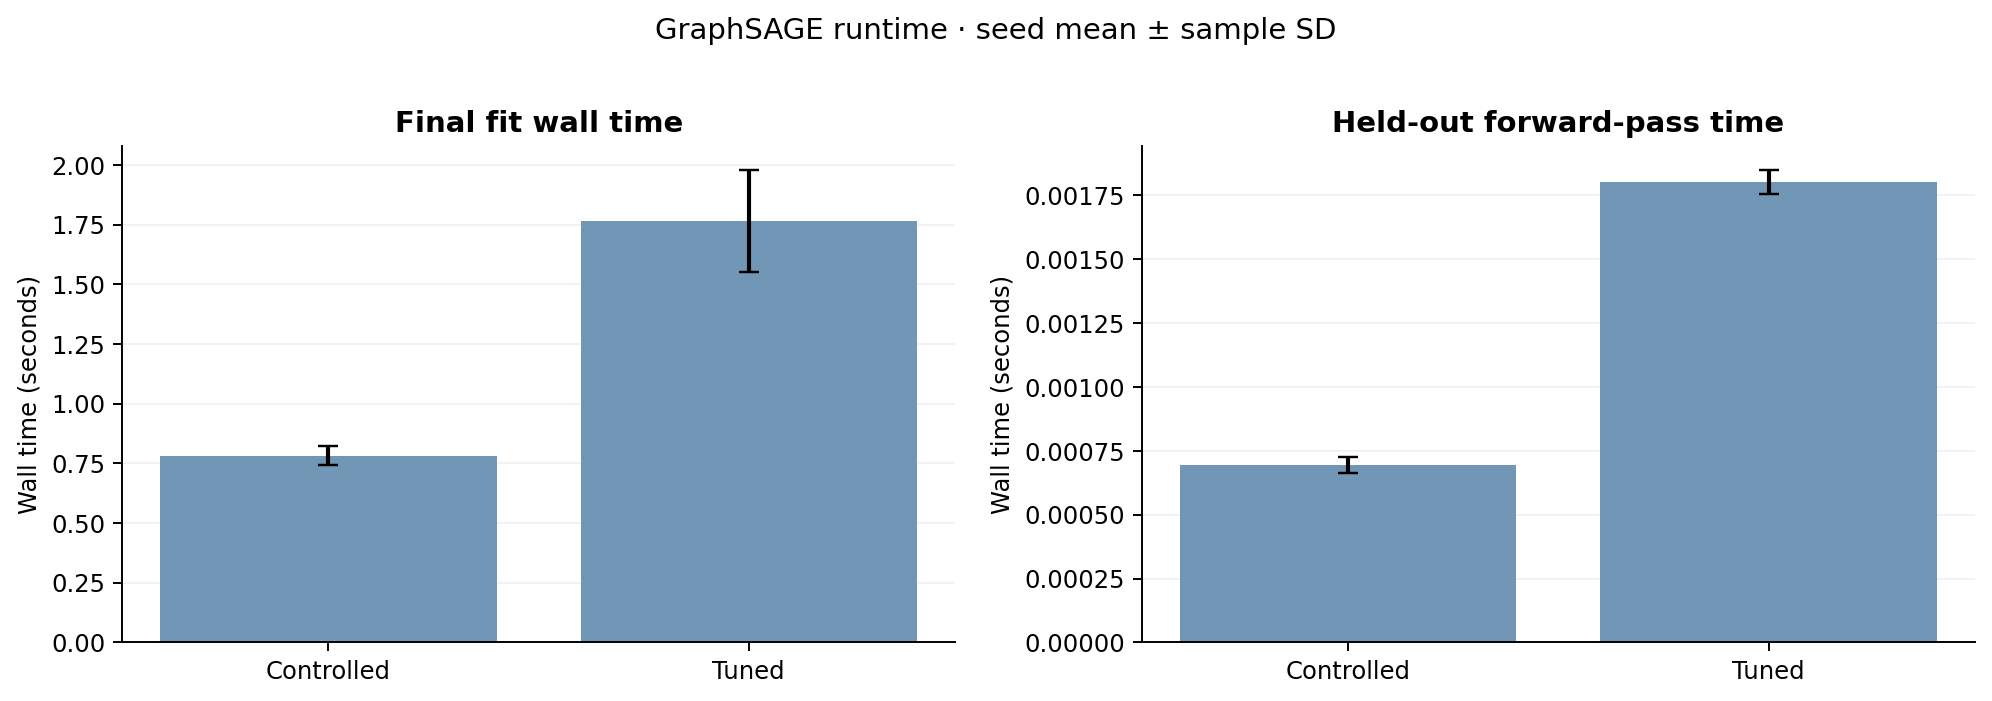

**Observed final fit time against held-out NDCG@10. Black whiskers indicate sample SD in both dimensions where available. Descriptive only.**

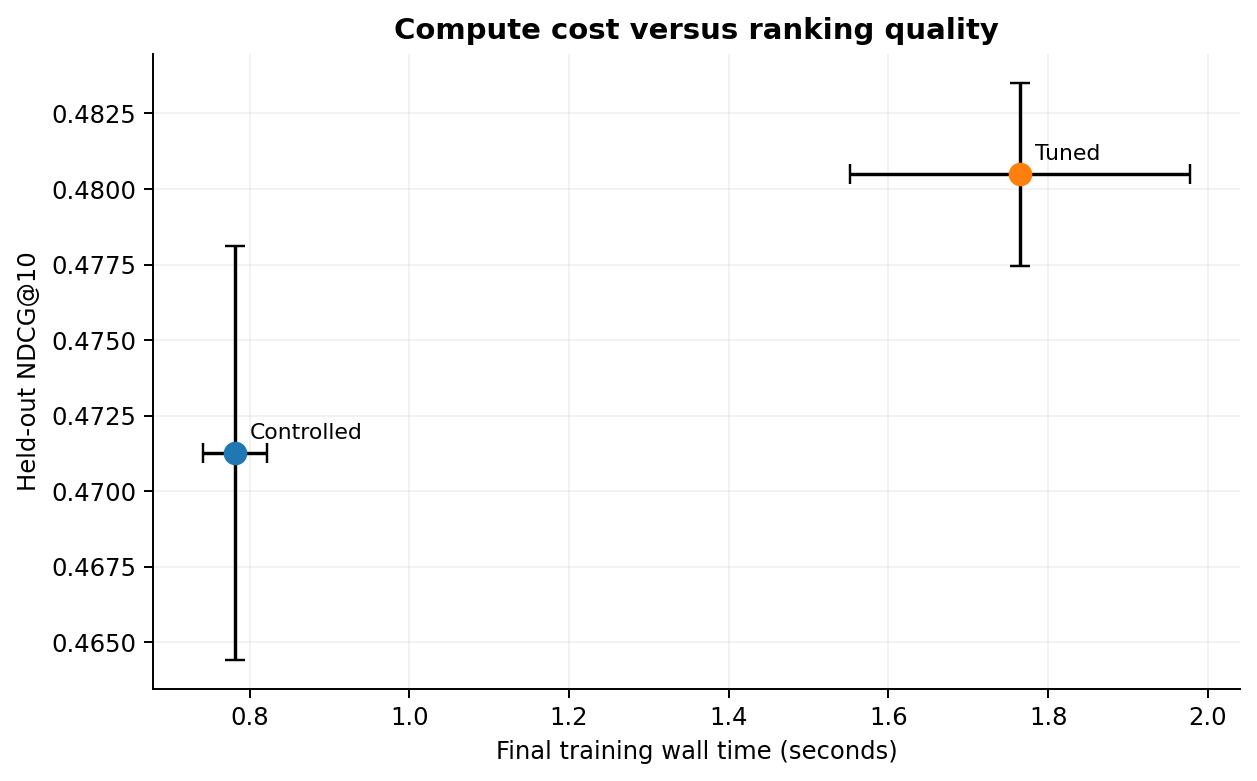

**Final fit and held-out forward-pass runtime. Black whiskers are sample seed SD only when two or more freshly timed seeds are available; HPO is excluded.**

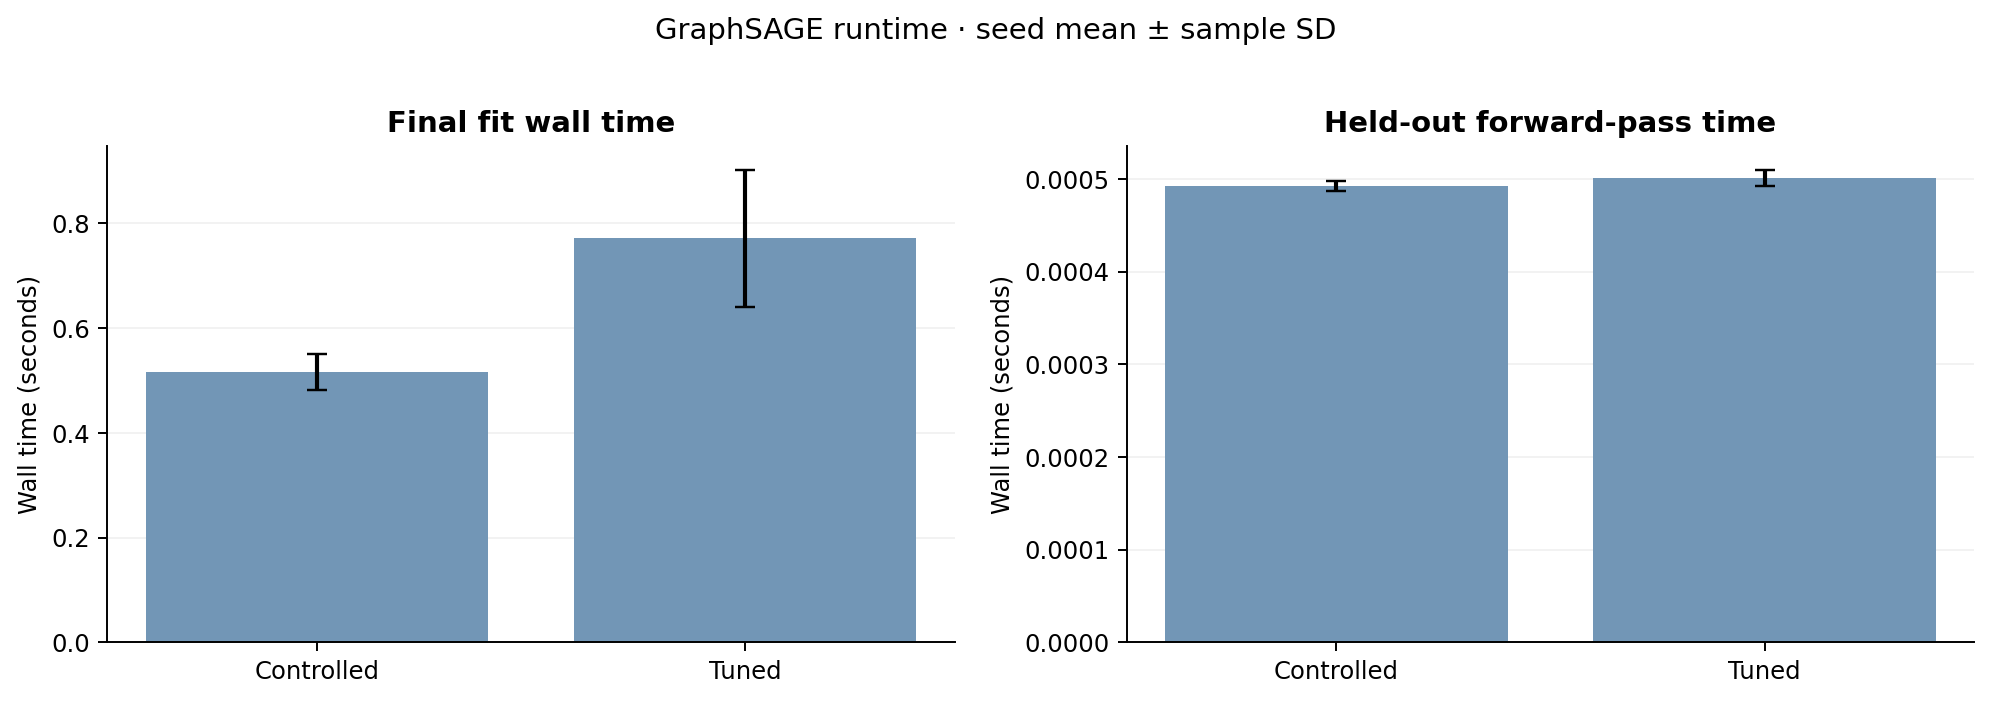

**Observed final fit time against held-out NDCG@10. Black whiskers indicate sample SD in both dimensions where available. Descriptive only.**

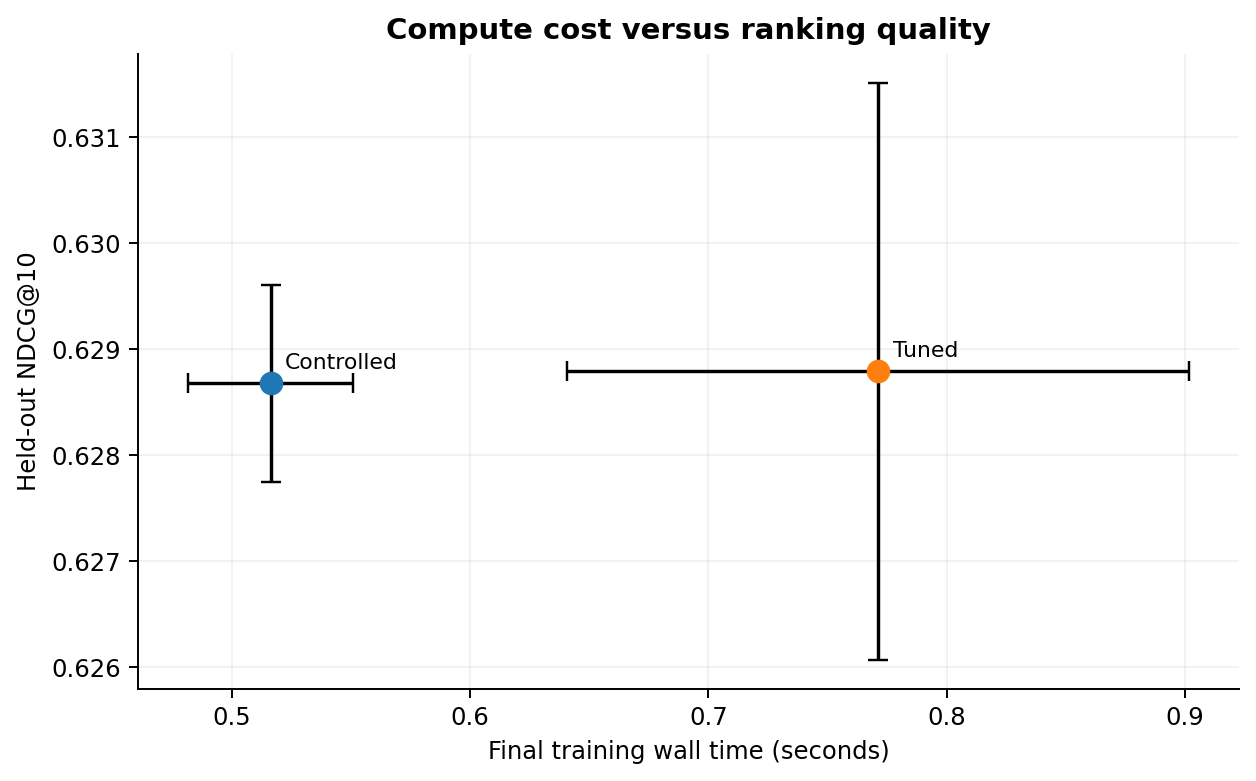

Team comparison CSV: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/tables/run6_gnn_team_comparison.csv
Hardware manifest: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/manifests/benchmark_hardware.json


In [ ]:
# Runtime accounting for trained models, ablations and hyperparameter search.
TIMES=pd.DataFrame(RUN_TIMING_ROWS)
PREPARATION=pd.DataFrame(PREP_TIMING_ROWS)
save_csv(TIMES,OUT/'tables/run6_runtime_per_seed.csv')
save_csv(PREPARATION,OUT/'tables/run6_runtime_preparation.csv')
if len(ALL_HISTORIES):
    epoch_fields=['dataset','method','seed','epoch','optimisation_seconds',
                  'training_monitor_seconds','validation_monitor_seconds',
                  'epoch_wall_seconds']
    save_csv(ALL_HISTORIES[epoch_fields],OUT/'tables/run6_epoch_runtime.csv.gz')

FIELDS=['training_wall_seconds','fit_wall_seconds','optimisation_seconds',
        'model_initialisation_seconds','training_monitor_seconds',
        'validation_monitor_seconds','mean_epoch_wall_seconds',
        'test_forward_seconds','test_pairs_per_second',
        'training_peak_cuda_memory_mib','seed_pipeline_wall_seconds',
        'epochs_ran','parameters']
def summarise_runtime(group):
    successful=group[group.status=='ok']
    fresh=successful[successful.trained_this_execution.astype(bool)]
    item=dict(dataset=group.dataset.iloc[0],method=group.method.iloc[0],
              attempted_seeds=len(group),successful_seeds=len(successful),
              failed_seeds=int((group.status!='ok').sum()),
              freshly_trained_successes=len(fresh),
              total_attempt_pipeline_seconds=float(group.seed_pipeline_wall_seconds.sum()),
              device=group.device.iloc[0],gpu_name=group.gpu_name.iloc[0])
    for name in FIELDS:
        df=successful if name in ('epochs_ran','parameters') else fresh
        v=pd.to_numeric(df[name],errors='coerce').dropna()
        item[name+'_mean']=float(v.mean()) if len(v) else np.nan
        item[name+'_sd']=float(v.std(ddof=1)) if len(v)>=2 else np.nan
        item[name+'_n']=len(v)
    return item

TIME_SUMMARY=pd.DataFrame([summarise_runtime(g)
    for _,g in TIMES.groupby(['dataset','method'])]).sort_values(
    ['dataset','method']).reset_index(drop=True)
save_csv(TIME_SUMMARY,OUT/'tables/run6_runtime_summary.csv')

hpo_rows=[]
for ds in DATASETS:
    p=OUT/'search'/ds/'trials.csv'
    if not p.exists():continue
    trials=pd.read_csv(p)
    if 'trial_wall_seconds' not in trials.columns:continue
    for stage,g in trials.groupby('stage'):
        hpo_rows.append(dict(dataset=ds,stage=stage,attempted=len(g),
             successful=int((g.status=='ok').sum()),
             failed=int((g.status!='ok').sum()),
             elapsed_seconds_total=float(g.trial_wall_seconds.sum()),
             computed_this_execution_seconds=float(
                 g.compute_this_execution_seconds.sum())))
HPO_TIME=pd.DataFrame(hpo_rows)
save_csv(HPO_TIME,OUT/'tables/run6_hpo_runtime_by_stage.csv')

stage_rows=[]
for ds in DATASETS:
    sub=TIMES[TIMES.dataset==ds]
    h=HPO_TIME[HPO_TIME.dataset==ds] if len(HPO_TIME) else pd.DataFrame()
    selected=sub.method.isin(('GraphSAGE-Controlled','GraphSAGE-Tuned'))
    stage_rows.append(dict(dataset=ds,
       hpo_trial_wall_seconds=float(h.elapsed_seconds_total.sum()) if len(h) else np.nan,
       headline_seed_pipeline_wall_seconds=float(sub[selected].seed_pipeline_wall_seconds.sum()),
       ablation_seed_pipeline_wall_seconds=float(sub[~selected].seed_pipeline_wall_seconds.sum()),
       graph_feature_preparation_seconds=float(PREPARATION[
           PREPARATION.dataset==ds].preparation_wall_seconds.sum()),
       note='Partial total excludes Run2/Run3, notebook setup and figure rendering'))
STAGE_TIME=pd.DataFrame(stage_rows)
save_csv(STAGE_TIME,OUT/'tables/run6_runtime_stage_totals.csv')

team_rows=[]
for ds in DATASETS:
    for method in ('GraphSAGE-Controlled','GraphSAGE-Tuned'):
        sel=TIME_SUMMARY[(TIME_SUMMARY.dataset==ds)&(TIME_SUMMARY.method==method)]
        metric=ALL_METRICS[(ALL_METRICS.dataset==ds)&(ALL_METRICS.method==method)&
                           (ALL_METRICS.split=='test')]
        if sel.empty:continue
        t=sel.iloc[0]
        def metric_mean_sd(key):
            return (float(metric[key].mean()) if len(metric) else np.nan,
                    float(metric[key].std(ddof=1)) if len(metric)>=2 else np.nan)
        ndcg,ndcg_sd=metric_mean_sd('NDCG@10')
        recall,recall_sd=metric_mean_sd('Recall@10')
        ap,ap_sd=metric_mean_sd('PR-AUC')
        team_rows.append(dict(dataset=ds,model_family='GraphSAGE',method=method,
          successful_seeds=int(t.successful_seeds),
          freshly_trained_seeds=int(t.freshly_trained_successes),
          test_ndcg10_mean=ndcg,test_ndcg10_seed_sd=ndcg_sd,
          test_recall10_mean=recall,test_recall10_seed_sd=recall_sd,
          test_ap_mean=ap,test_ap_seed_sd=ap_sd,
          training_wall_seconds_mean=t.training_wall_seconds_mean,
          training_wall_seconds_seed_sd=t.training_wall_seconds_sd,
          fit_wall_seconds_mean=t.fit_wall_seconds_mean,
          optimiser_wall_seconds_mean=t.optimisation_seconds_mean,
          monitoring_train_seconds_mean=t.training_monitor_seconds_mean,
          monitoring_validation_seconds_mean=t.validation_monitor_seconds_mean,
          test_forward_seconds_mean=t.test_forward_seconds_mean,
          test_forward_seconds_seed_sd=t.test_forward_seconds_sd,
          test_candidate_pairs_per_second_mean=t.test_pairs_per_second_mean,
          test_candidate_pairs_per_second_seed_sd=t.test_pairs_per_second_sd,
          epochs_mean=t.epochs_ran_mean,epochs_seed_sd=t.epochs_ran_sd,
          trainable_parameters=t.parameters_mean,
          peak_gpu_allocated_mib_mean=t.training_peak_cuda_memory_mib_mean,
          peak_gpu_allocated_mib_seed_sd=t.training_peak_cuda_memory_mib_sd,
          device=str(t.device),gpu=str(t.gpu_name),
          include_validation_monitoring_in_training_time=True,
          excluded_from_training_time='HPO, data preparation, held-out evaluation, figures',
          measured_this_execution=bool(t.freshly_trained_successes>=1)))
TEAM_GNN=pd.DataFrame(team_rows)
save_csv(TEAM_GNN,OUT/'tables/run6_gnn_team_comparison.csv')

numeric_table(TEAM_GNN,'Team GNN comparison — measured GraphSAGE performance and cost')
numeric_table(HPO_TIME,'Full validation-only search cost, separately reported')
numeric_table(STAGE_TIME,'Experimental resource accounting by dataset')

for ds in DATASETS:
    part=TEAM_GNN[TEAM_GNN.dataset==ds].copy()
    if part.empty:continue
    labels=part.method.str.replace('GraphSAGE-','',regex=False)
    fig,axs=plt.subplots(1,2,figsize=(11.6,4.1))
    for ax,mu,sd,title in [
        (axs[0],'training_wall_seconds_mean','training_wall_seconds_seed_sd','Final fit wall time'),
        (axs[1],'test_forward_seconds_mean','test_forward_seconds_seed_sd','Held-out forward-pass time')]:
        x=np.arange(len(part))
        avg=part[mu].to_numpy(float);err=part[sd].to_numpy(float)
        ax.bar(x,avg,color='#7296b6',zorder=2)
        valid=np.isfinite(avg)&np.isfinite(err)&(part.freshly_trained_seeds.to_numpy()>=2)
        if valid.any():
            ax.errorbar(x[valid],avg[valid],yerr=err[valid],
                        fmt='none',ecolor='black',elinewidth=1.7,capsize=4,zorder=3)
        ax.set_xticks(x,labels)
        ax.set(ylabel='Wall time (seconds)',title=title)
        ax.grid(axis='y',alpha=.16,zorder=0)
    fig.suptitle('GraphSAGE runtime · seed mean ± sample SD')
    chapter_figure(fig,ds,'13_runtime_efficiency',f'{ds}_training_and_inference_runtime',
        'Final fit and held-out forward-pass runtime. Black whiskers are sample seed SD '
        'only when two or more freshly timed seeds are available; HPO is excluded.',
        'tables/run6_gnn_team_comparison.csv')

    fig,ax=plt.subplots(figsize=(7.4,4.7))
    for entry in part.itertuples():
        x=float(entry.training_wall_seconds_mean)
        y=float(entry.test_ndcg10_mean)
        if not(np.isfinite(x) and np.isfinite(y)):continue
        ax.scatter(x,y,s=76,zorder=3)
        ax.annotate(entry.method.replace('GraphSAGE-',''),(x,y),
                    xytext=(6,6),textcoords='offset points',fontsize=9)
        sx=float(entry.training_wall_seconds_seed_sd)
        sy=float(entry.test_ndcg10_seed_sd)
        if np.isfinite(sx) and np.isfinite(sy):
            ax.errorbar(x,y,xerr=sx,yerr=sy,fmt='none',
                        ecolor='black',elinewidth=1.4,capsize=4)
    ax.set(xlabel='Final training wall time (seconds)',
           ylabel='Held-out NDCG@10',title='Compute cost versus ranking quality')
    ax.grid(alpha=.16)
    chapter_figure(fig,ds,'13_runtime_efficiency',f'{ds}_runtime_vs_ndcg',
        'Observed final fit time against held-out NDCG@10. Black whiskers indicate '
        'sample SD in both dimensions where available. Descriptive only.',
        'tables/run6_gnn_team_comparison.csv')
print('Team comparison CSV:',OUT/'tables/run6_gnn_team_comparison.csv')
print('Hardware manifest:',OUT/'manifests/benchmark_hardware.json')


### 07.1 · Ablation effect sizes relative to the controlled model

Ablation effects are defined as $\Delta=\mathrm{NDCG@10}_{\mathrm{variant}}-\mathrm{NDCG@10}_{\mathrm{Controlled}}$. We use matched seeds when available and show *all* individual-seed differences; the difference between positive and negative point estimates is not, by itself, a significance test. This design distinguishes feature access, structural perturbation, depth and aggregation changes.

#### EuroMart · quarterly

**Performance effects of training-time graph, feature and architecture interventions**

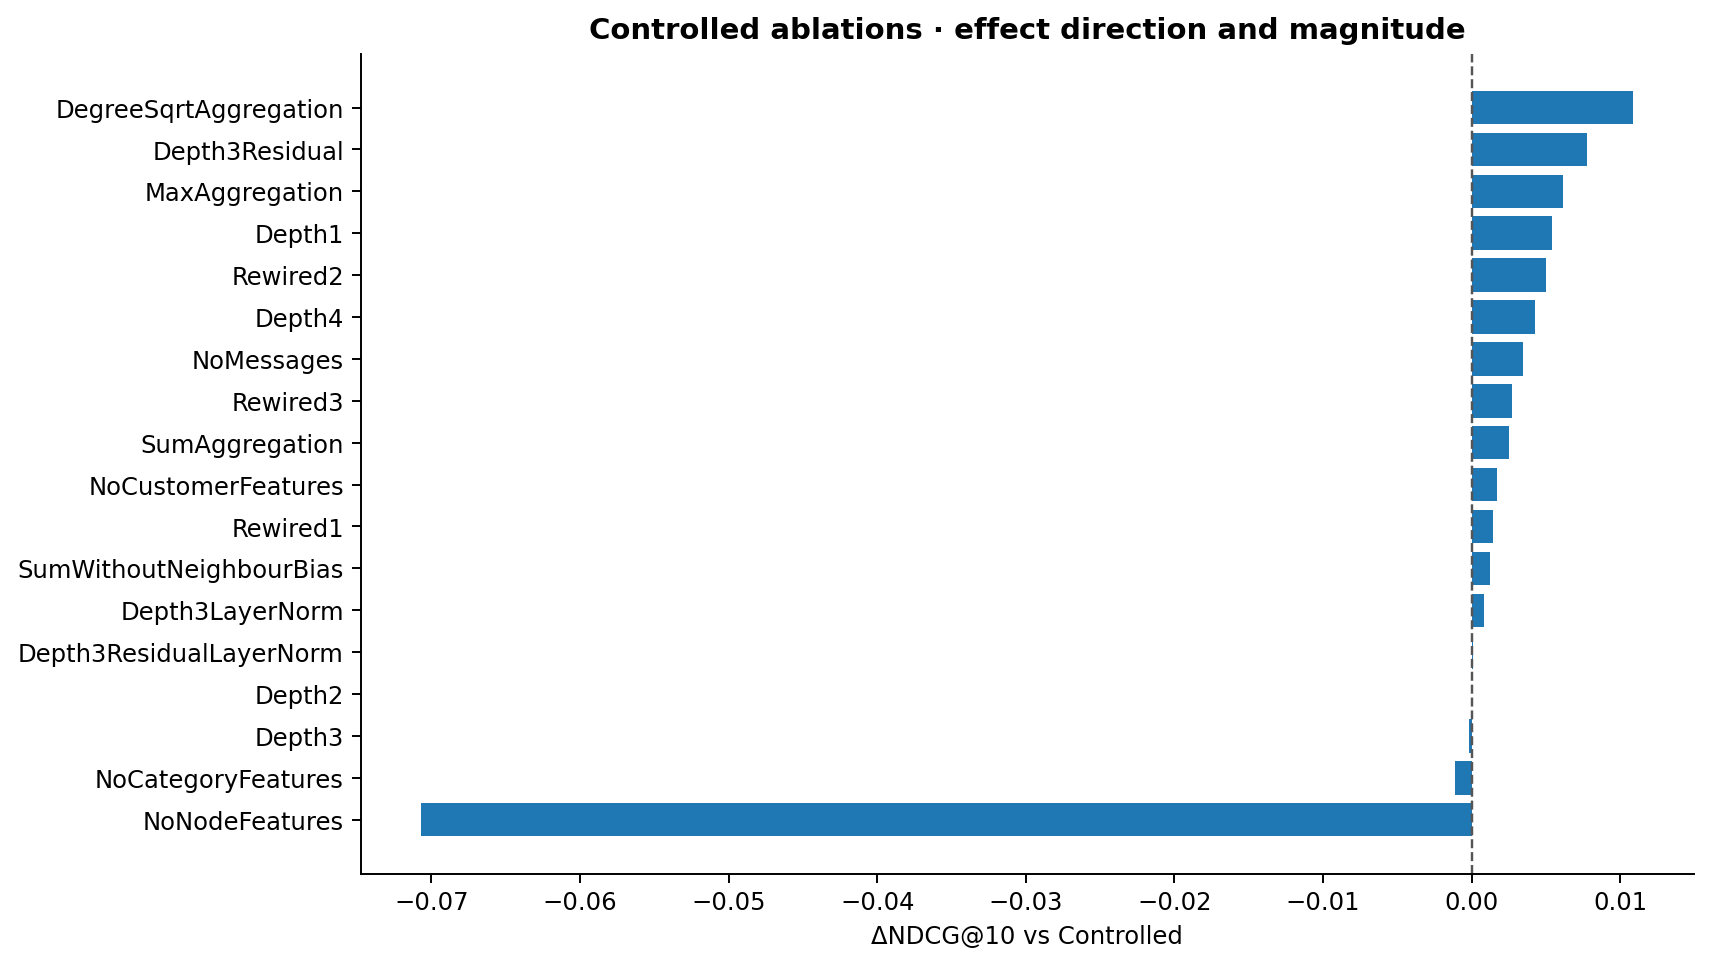

**Information interventions: individual seed differences; black mean ± sample SD when n>=2**

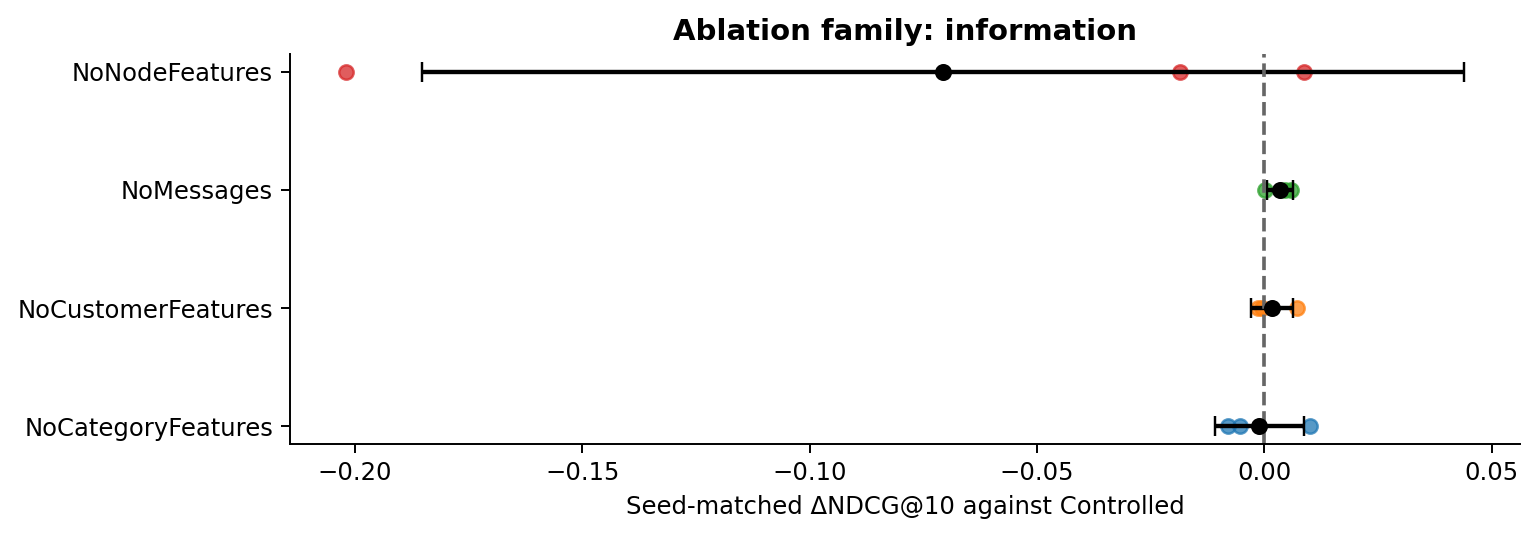

**Depth interventions: individual seed differences; black mean ± sample SD when n>=2**

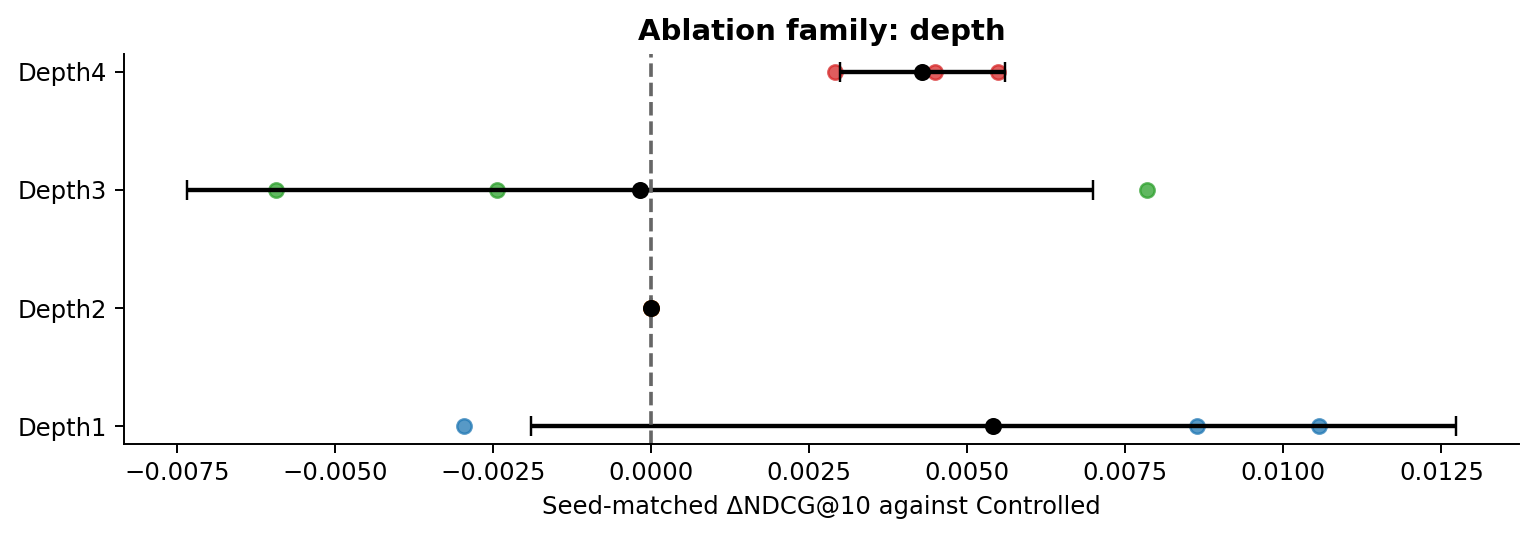

**Aggregation interventions: individual seed differences; black mean ± sample SD when n>=2**

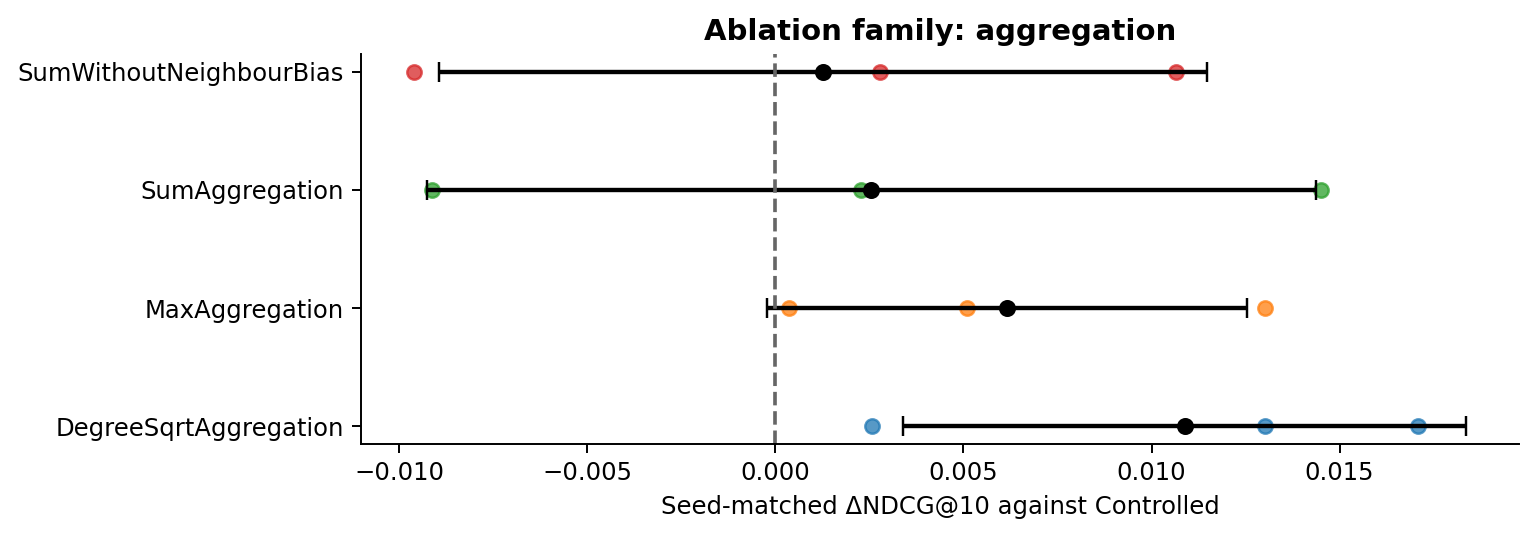

**Stabilisation interventions: individual seed differences; black mean ± sample SD when n>=2**

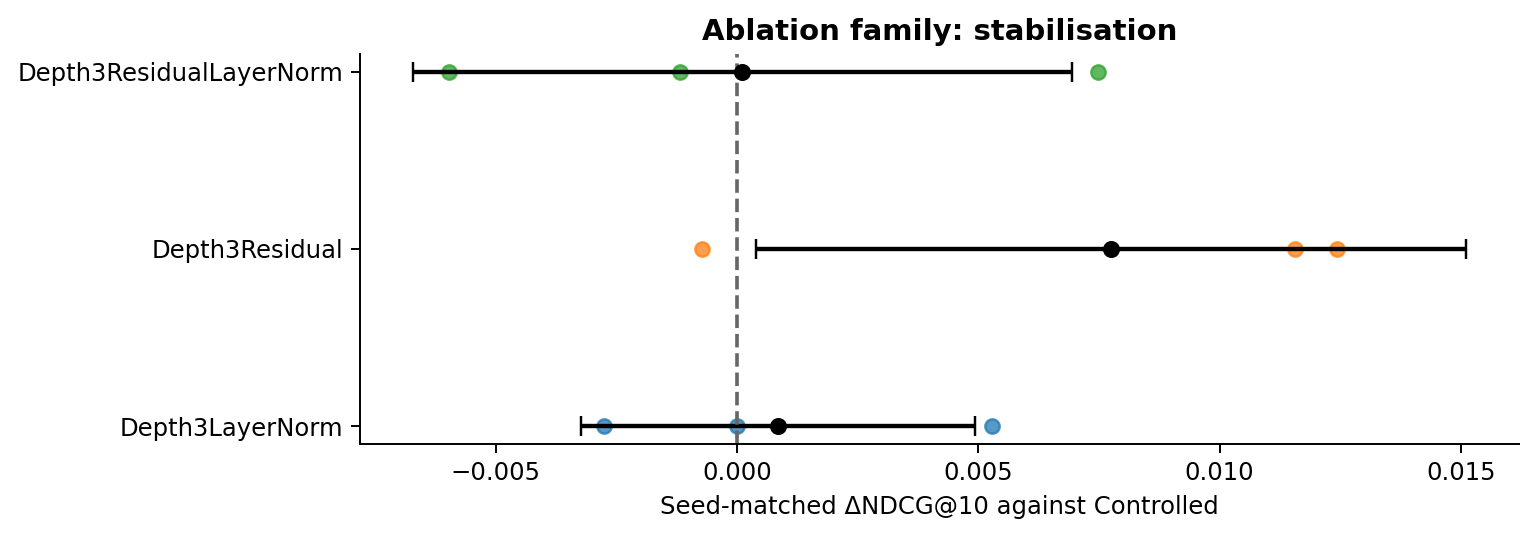

**Rewiring interventions: individual seed differences; black mean ± sample SD when n>=2**

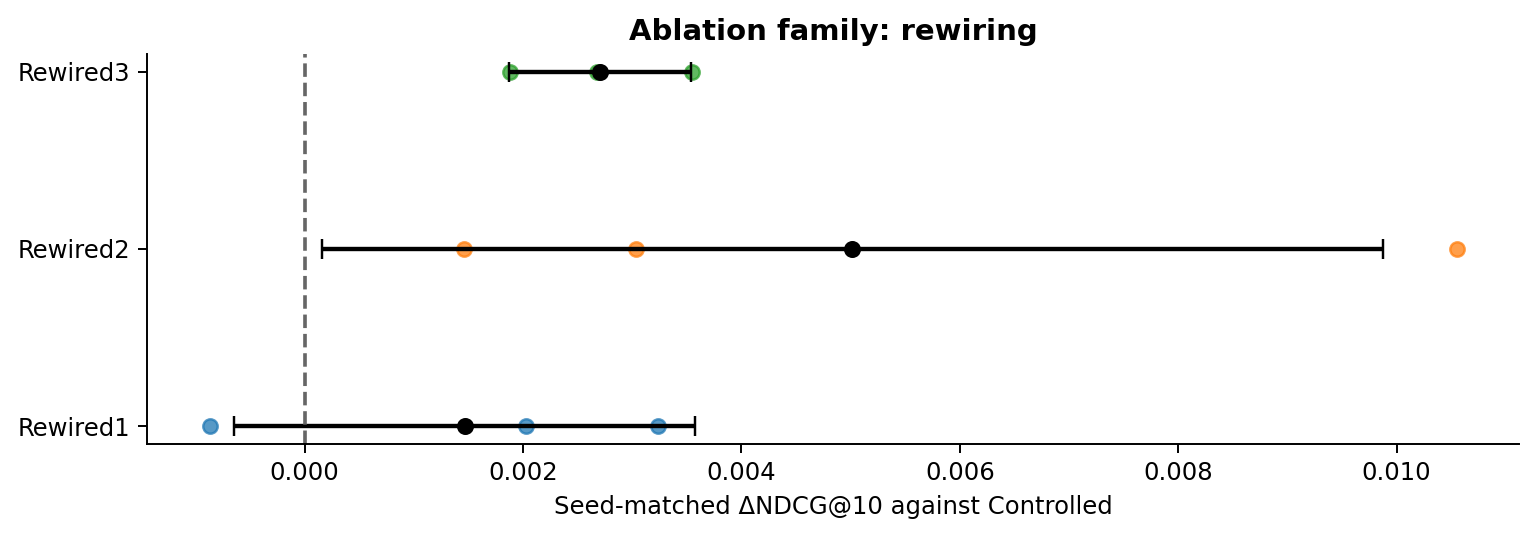

#### Retail POS · monthly

**Excluded from numeric effect plots: zero successful seeds**

,method,attempted_seeds,failed_seeds,completion_status
38,GraphSAGE-SumWithoutNeighbourBias,3,3,all_failed


**Performance effects of training-time graph, feature and architecture interventions**

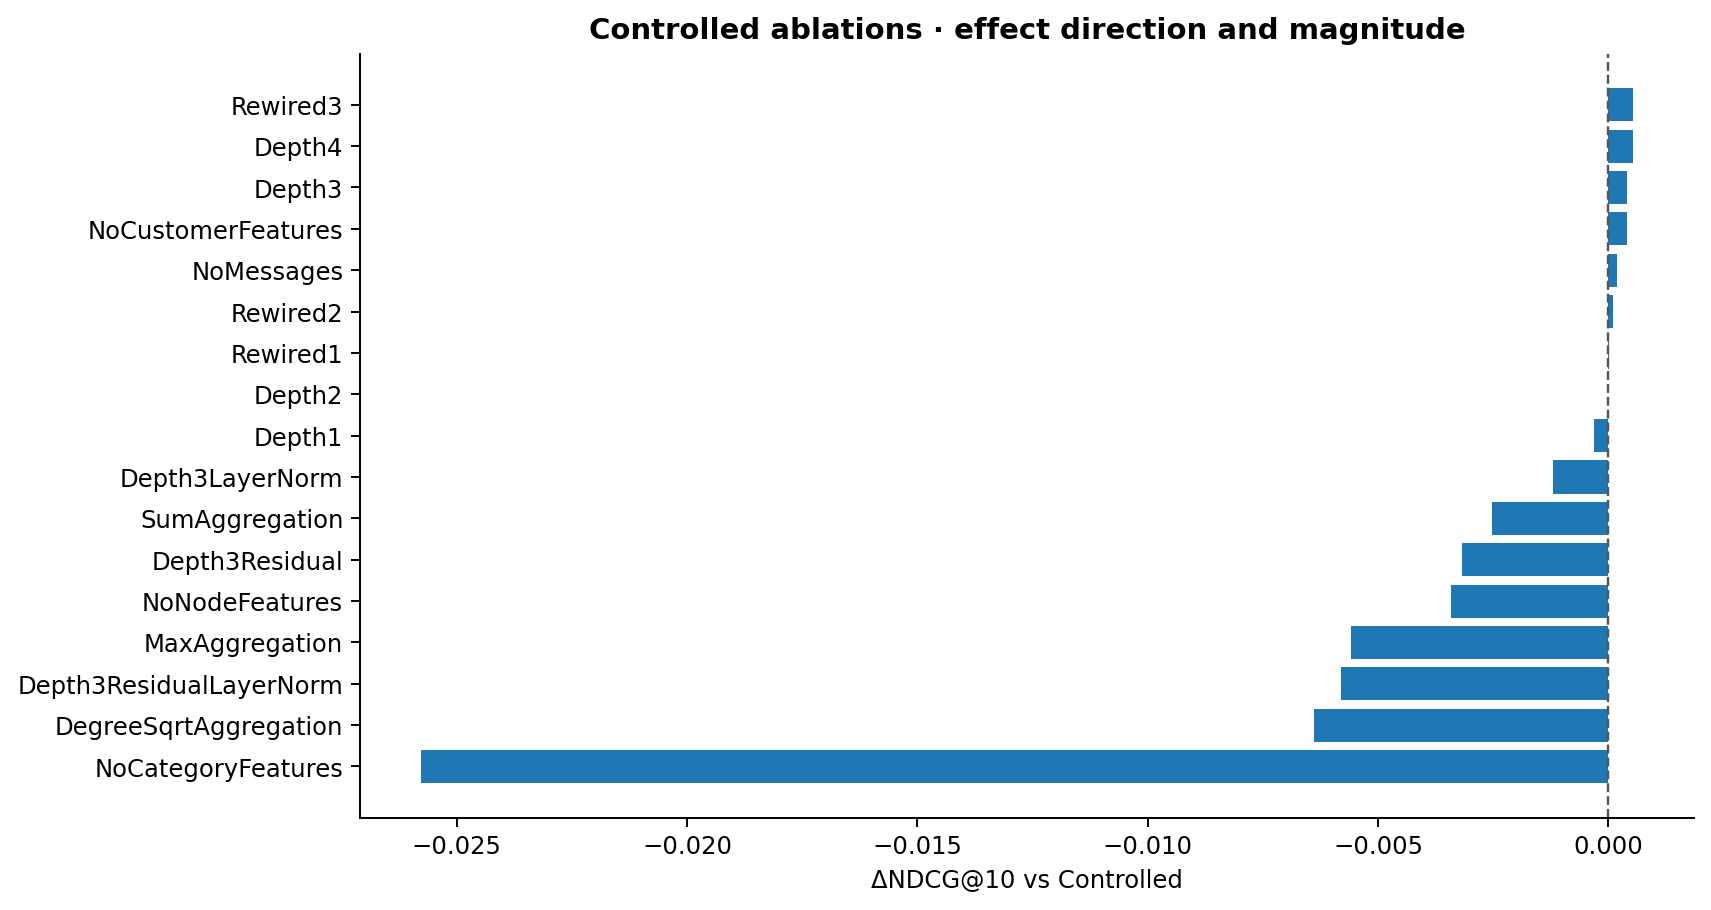

**Information interventions: individual seed differences; black mean ± sample SD when n>=2**

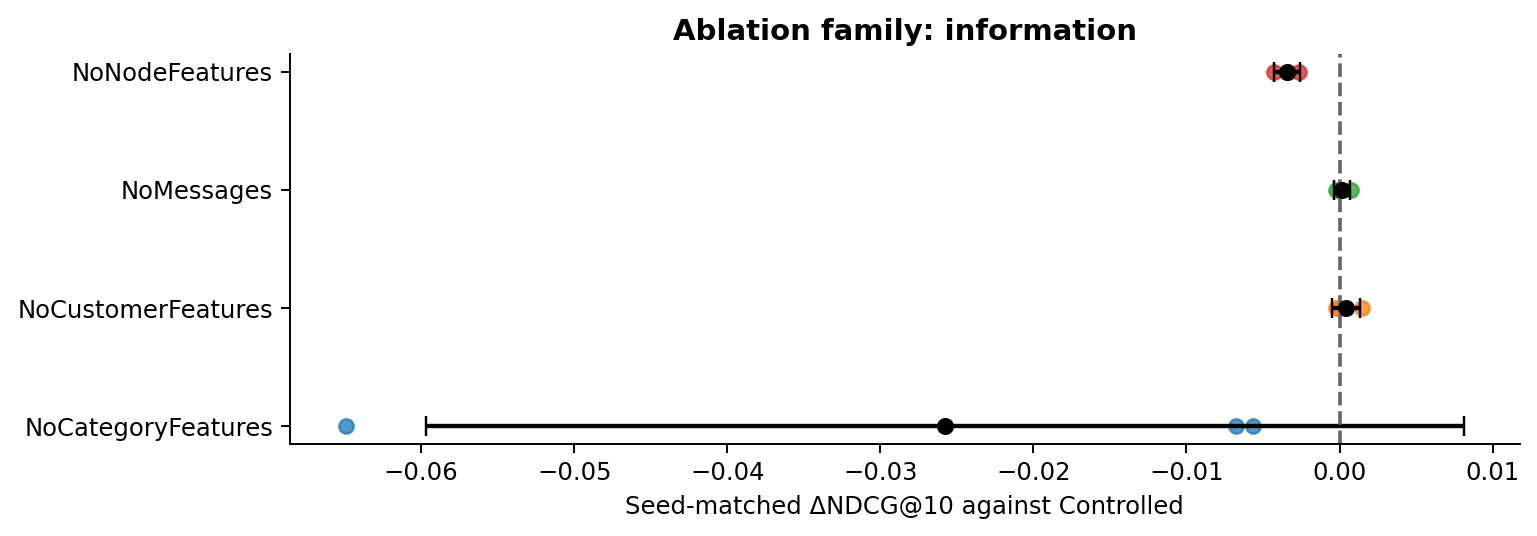

**Depth interventions: individual seed differences; black mean ± sample SD when n>=2**

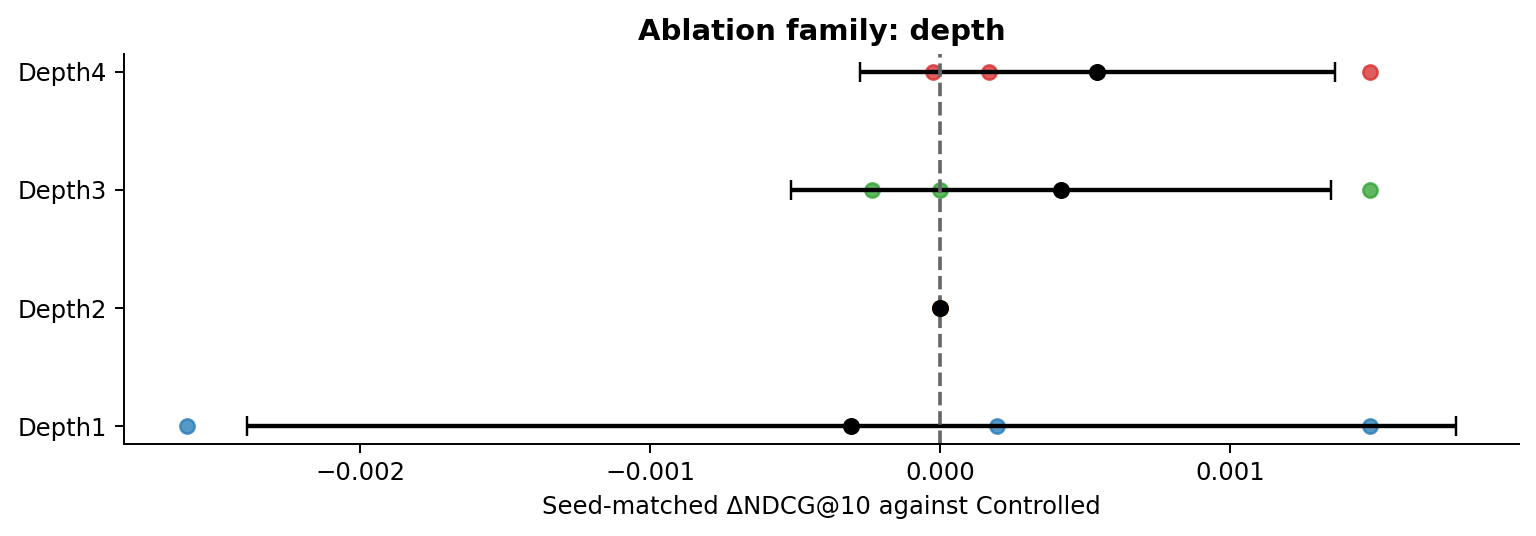

**Aggregation interventions: individual seed differences; black mean ± sample SD when n>=2**

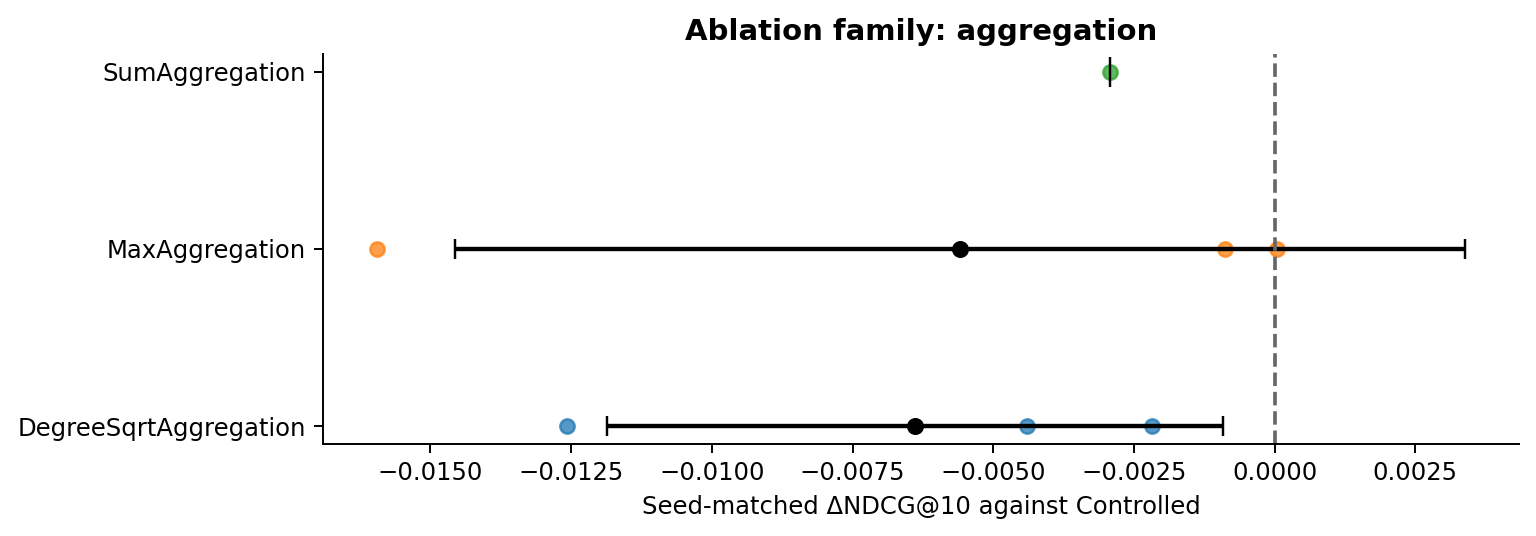

**Stabilisation interventions: individual seed differences; black mean ± sample SD when n>=2**

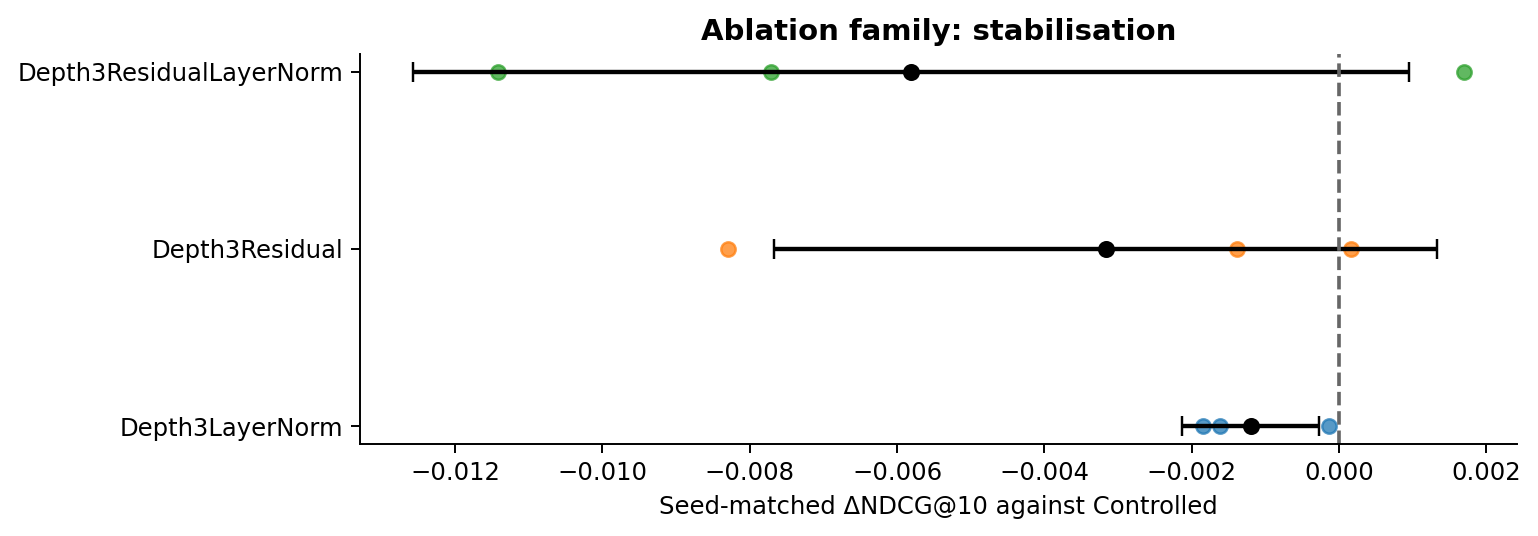

**Rewiring interventions: individual seed differences; black mean ± sample SD when n>=2**

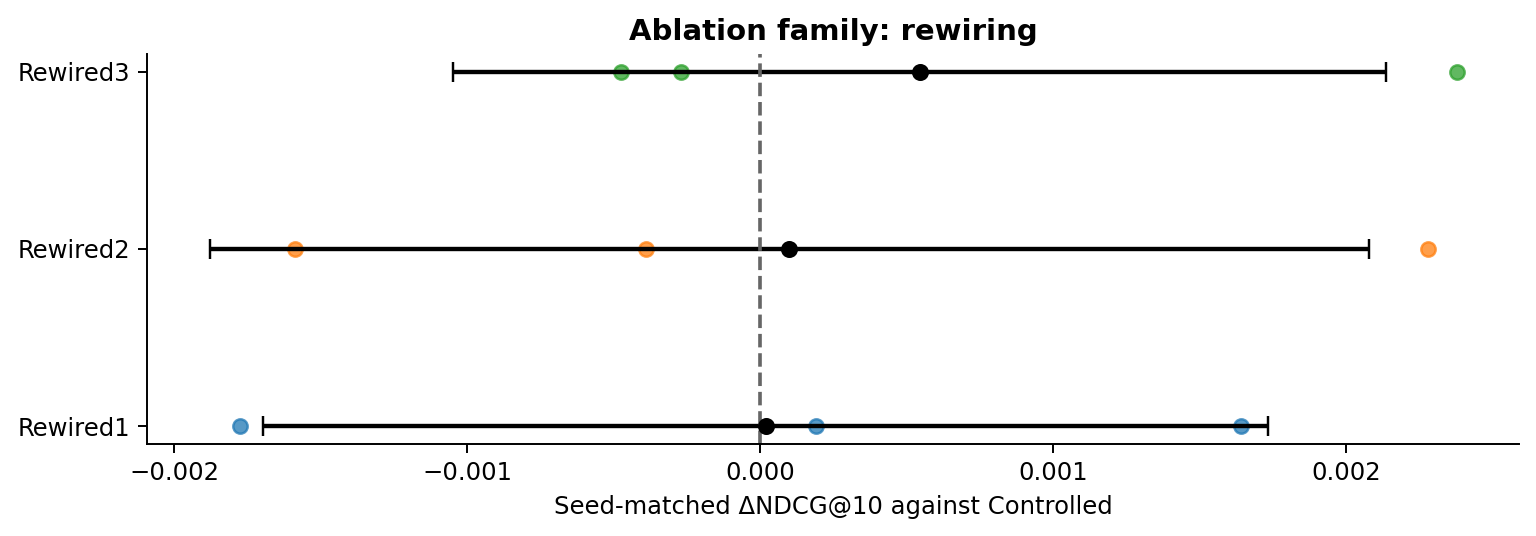

In [ ]:
for ds in DATASETS:
    ds_header(ds)
    z=SUMMARY[(SUMMARY.dataset==ds)&SUMMARY.method.str.startswith('GraphSAGE-')].copy()
    c=float(z.loc[z.method=='GraphSAGE-Controlled','NDCG@10'].iloc[0])
    failed=z[z.valid_seeds==0][['method','attempted_seeds','failed_seeds','completion_status']]
    if len(failed):numeric_table(failed,'Excluded from numeric effect plots: zero successful seeds')
    z['delta_control']=z['NDCG@10']-c
    z=z[(z.valid_seeds>0)&~z.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])].sort_values('delta_control')
    fig,ax=plt.subplots(figsize=(10,max(4.3,len(z)*.32)))
    ax.barh(z.method.str.replace('GraphSAGE-','',regex=False),z.delta_control)
    ax.axvline(0,ls='--',lw=1,color='#555');ax.set(xlabel='ΔNDCG@10 vs Controlled',
        title='Controlled ablations · effect direction and magnitude')
    chapter_figure(fig,ds,'10_graph_ablations',f'{ds}_ablation_effects',
                   'Performance effects of training-time graph, feature and architecture interventions')
    s=ALL_METRICS[(ALL_METRICS.dataset==ds)&(ALL_METRICS.split=='test')][['method','seed','NDCG@10']]
    a=s[s.method=='GraphSAGE-Controlled'][['seed','NDCG@10']].rename(columns={'NDCG@10':'control'})
    matched=s.merge(a,on='seed',validate='many_to_one');matched['delta']=matched['NDCG@10']-matched.control
    groups={
      'information':['NoMessages','NoCustomerFeatures','NoCategoryFeatures','NoNodeFeatures'],
      'depth':[f'Depth{k}' for k in [1,2,3,4]],
      'aggregation':['SumAggregation','SumWithoutNeighbourBias','MaxAggregation','DegreeSqrtAggregation'],
      'stabilisation':['Depth3Residual','Depth3LayerNorm','Depth3ResidualLayerNorm'],
      'rewiring':[f'Rewired{k}' for k in [1,2,3]],
    }
    for fam,names in groups.items():
        m=matched[matched.method.isin(['GraphSAGE-'+n for n in names])].copy()
        if m.empty:continue
        order=sorted(m.method.unique())
        fig,ax=plt.subplots(figsize=(9,max(3.3,len(order)*.55)))
        for i,method in enumerate(order):
            v=m[m.method==method].delta.to_numpy()
            ax.scatter(v,np.full(len(v),i),s=35,alpha=.75)
            if len(v)>=2:
                ax.errorbar(float(v.mean()),i,xerr=float(np.std(v,ddof=1)),
                            fmt='o',color='black',ecolor='black',capsize=4,elinewidth=1.8)
            else:ax.plot([float(v.mean())],[i],marker='|',color='black',markersize=12)
        ax.axvline(0,ls='--',color='#666');ax.set_yticks(range(len(order)),
                [m.replace('GraphSAGE-','') for m in order])
        ax.set(xlabel='Seed-matched ΔNDCG@10 against Controlled',title=f'Ablation family: {fam}')
        chapter_figure(fig,ds,'10_graph_ablations',f'{ds}_{fam}_matched_seed_effects',
                       f'{fam.title()} interventions: individual seed differences; black mean ± sample SD when n>=2')

## 08 · Behaviour of actual recommendations

**Question.** Can the model personalise ten recommended categories out of seventeen, and do its wins predominantly come from rediscovering familiar categories?

**Analysis family A — Personalisation.** Count distinct ordered and unordered top-10 lists within each held-out period. A large number of ordered lists but few unordered sets indicates ranking variation without meaningful category-set variety. We also examine category-level recommendation exposure to identify concentration.

**Analysis family B — Novelty and cohorts.** Partition positives into historically observed and never-before-observed customer–category links. Stratify customer NDCG by previous history degree. Recall on these subgroups is conditional on having at least one positive label in that subgroup, and therefore uses different denominators from overall recall.

#### EuroMart · quarterly

**Personalisation diversity per test period (mean across seeds and periods)**

,distinct_ordered_top10,distinct_unordered_top10,customer_count
method,,,
GraphSAGE-Controlled,13.8889,2.2222,290.6667
GraphSAGE-Tuned,3.0000,1.4444,290.6667


**Unique ordered versus unordered top-10 recommendations (17-category candidate universe)**

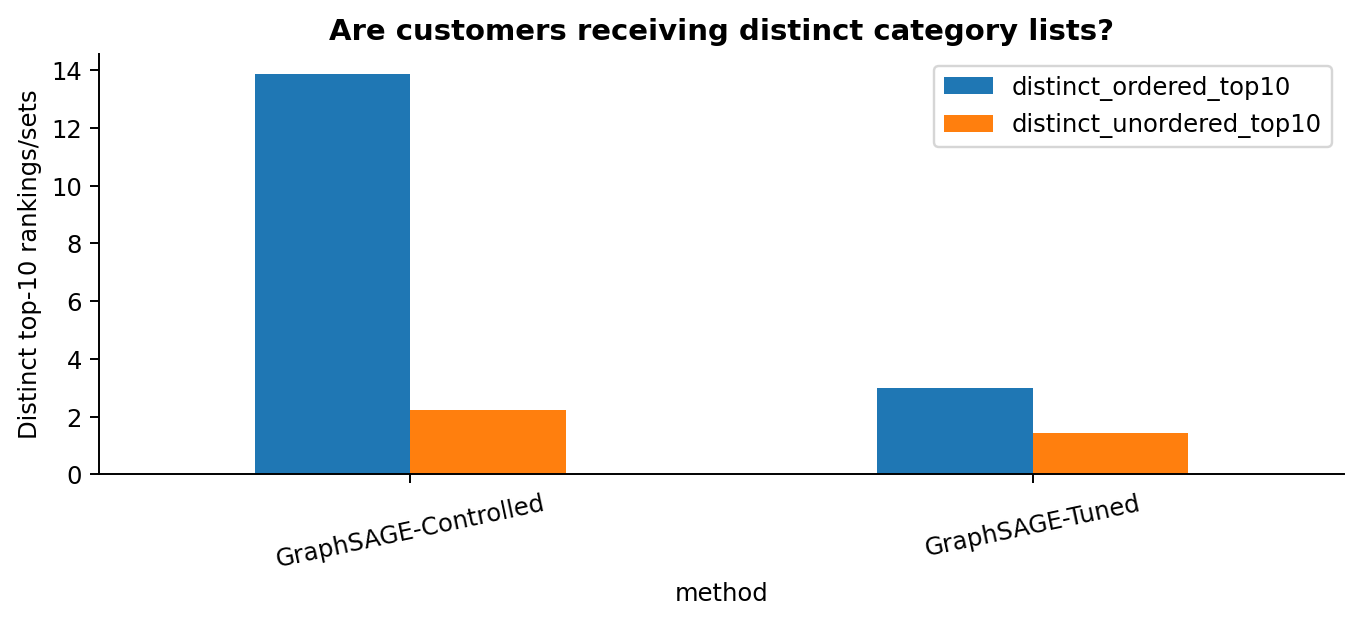

**Top-10 exposure frequency by category, averaged over held-out periods and seeds**

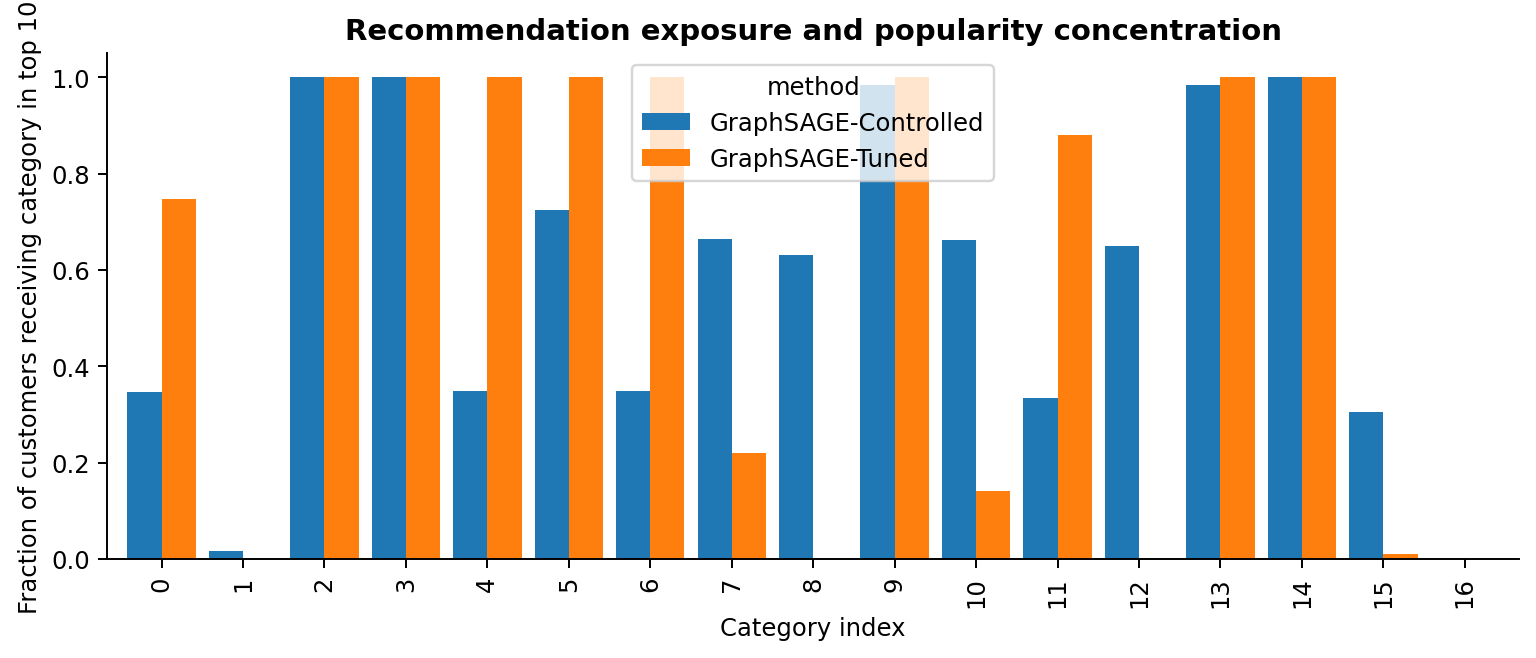

**Recall@3 split by previously observed versus novel positive links**

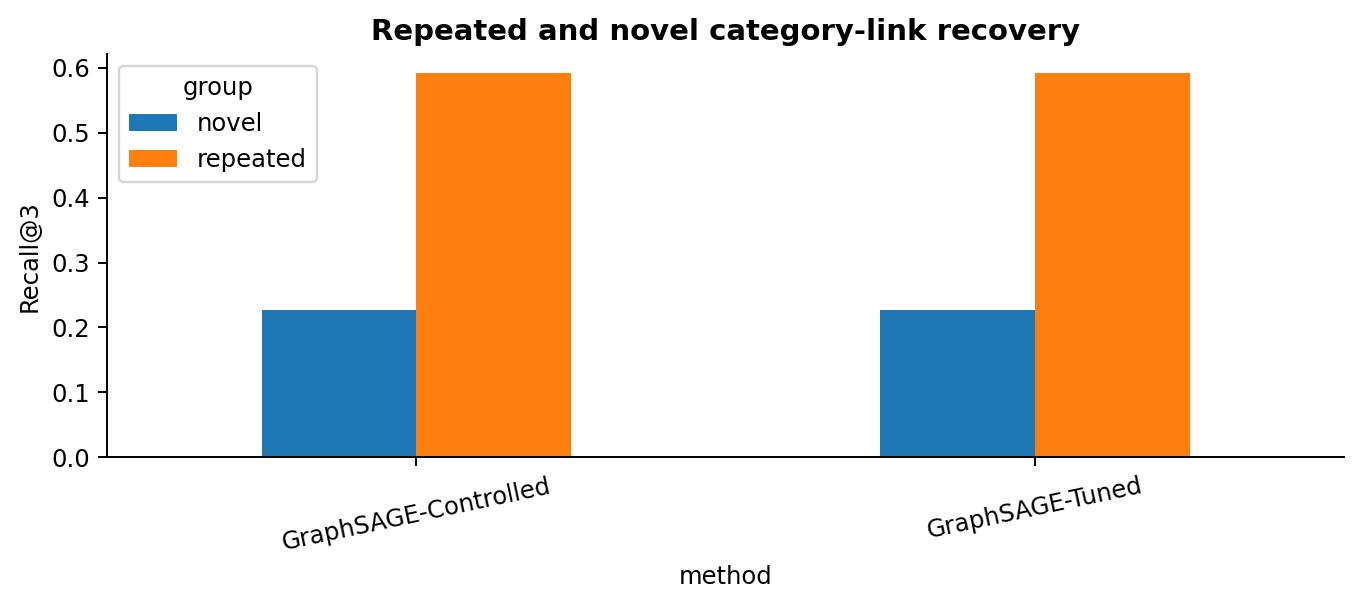

**Recall@5 split by previously observed versus novel positive links**

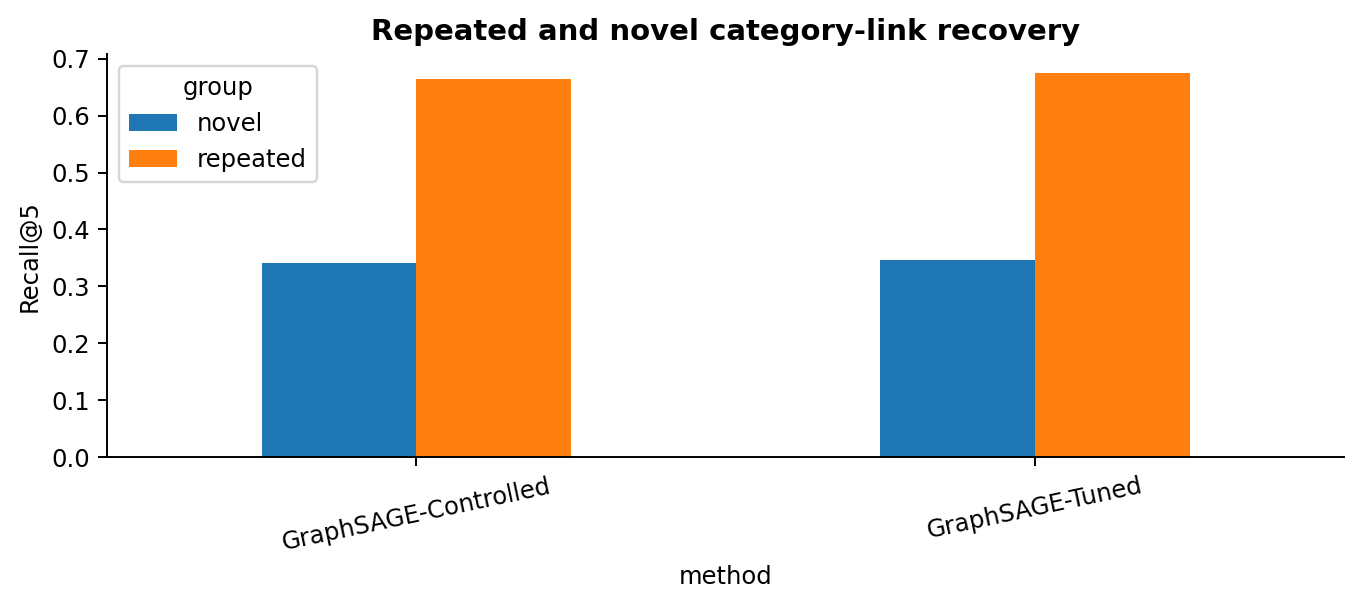

**Recall@10 split by previously observed versus novel positive links**

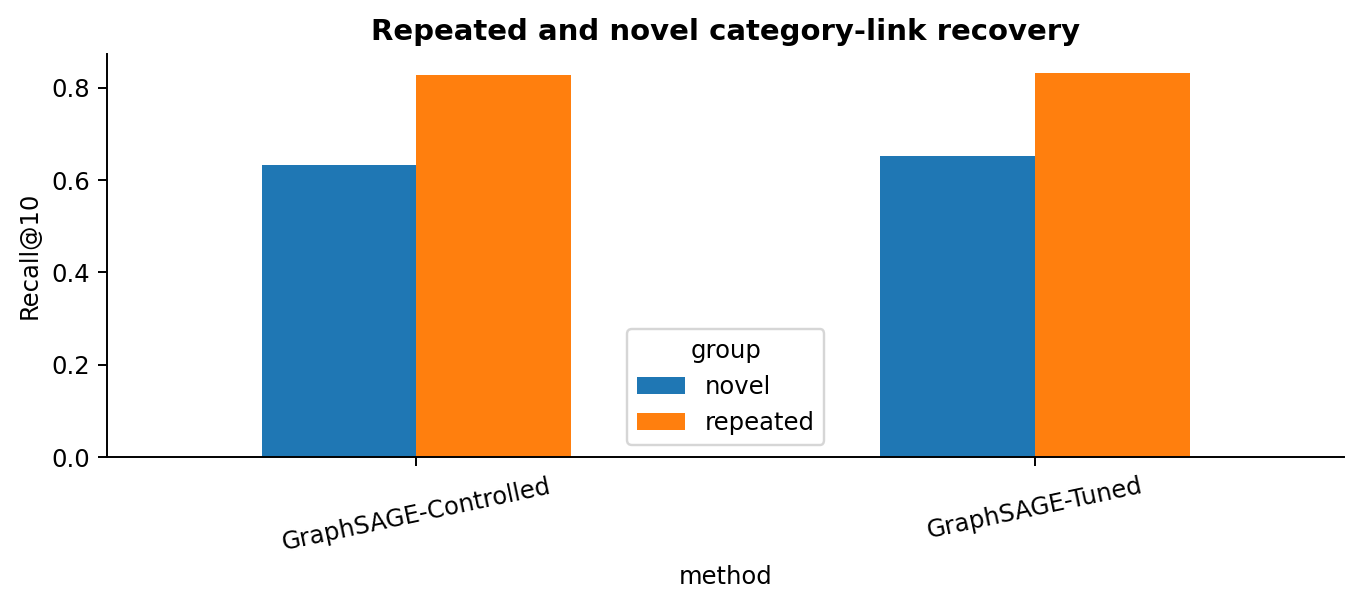

**Ranking performance by historical customer degree; inspect subgroup sample sizes**

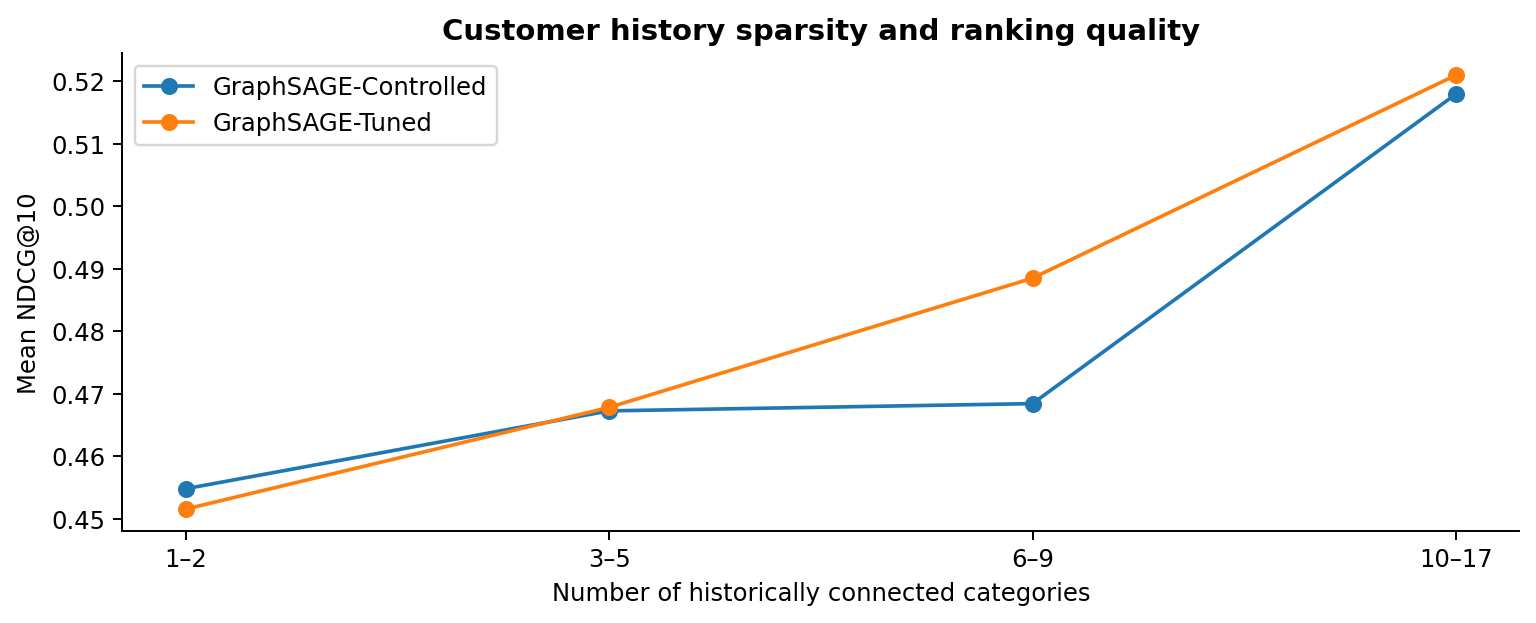

**Degree subgroup sizes: essential context for the curve**

,method,degree_band,mean,count
0,GraphSAGE-Controlled,1–2,0.4548,255
1,GraphSAGE-Controlled,3–5,0.4672,939
2,GraphSAGE-Controlled,6–9,0.4684,1179
3,GraphSAGE-Controlled,10–17,0.5180,243
4,GraphSAGE-Tuned,1–2,0.4515,255
5,GraphSAGE-Tuned,3–5,0.4678,939
6,GraphSAGE-Tuned,6–9,0.4885,1179
7,GraphSAGE-Tuned,10–17,0.5210,243


#### Retail POS · monthly

**Personalisation diversity per test period (mean across seeds and periods)**

,distinct_ordered_top10,distinct_unordered_top10,customer_count
method,,,
GraphSAGE-Controlled,3.3333,1.1667,131.0
GraphSAGE-Tuned,12.6667,1.5000,131.0


**Unique ordered versus unordered top-10 recommendations (17-category candidate universe)**

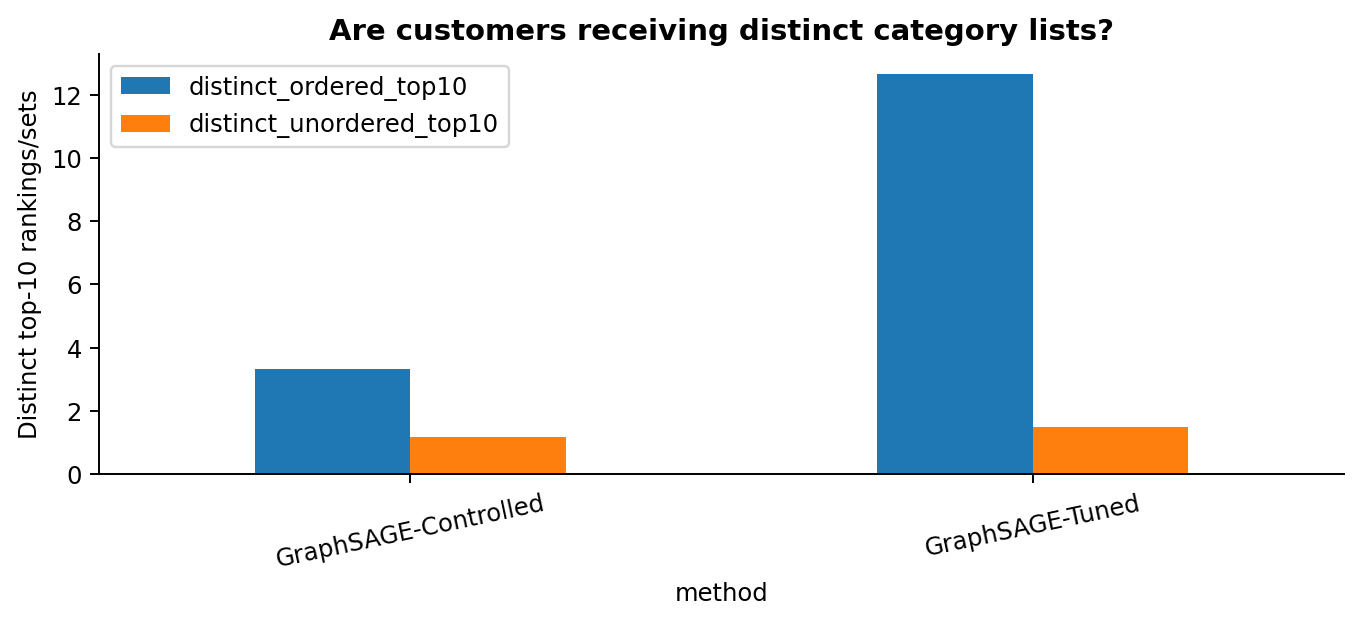

**Top-10 exposure frequency by category, averaged over held-out periods and seeds**

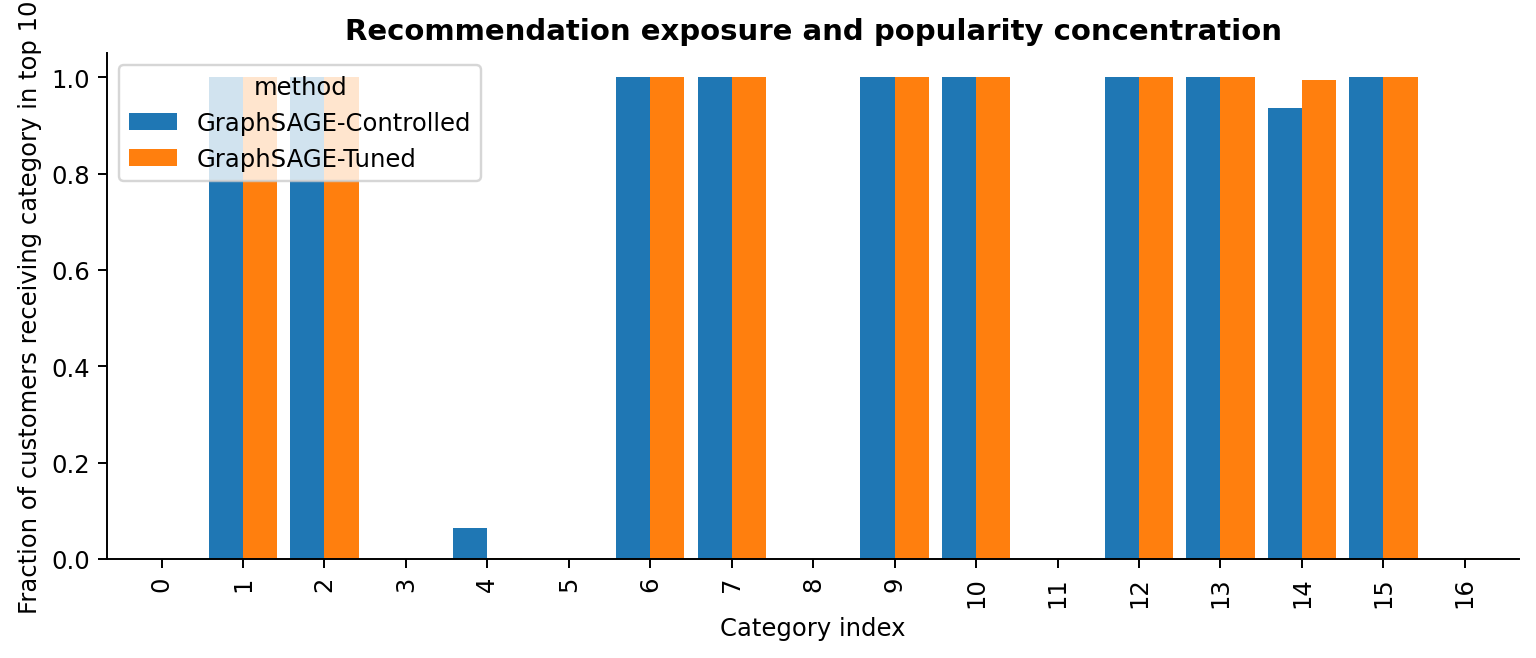

**Recall@3 split by previously observed versus novel positive links**

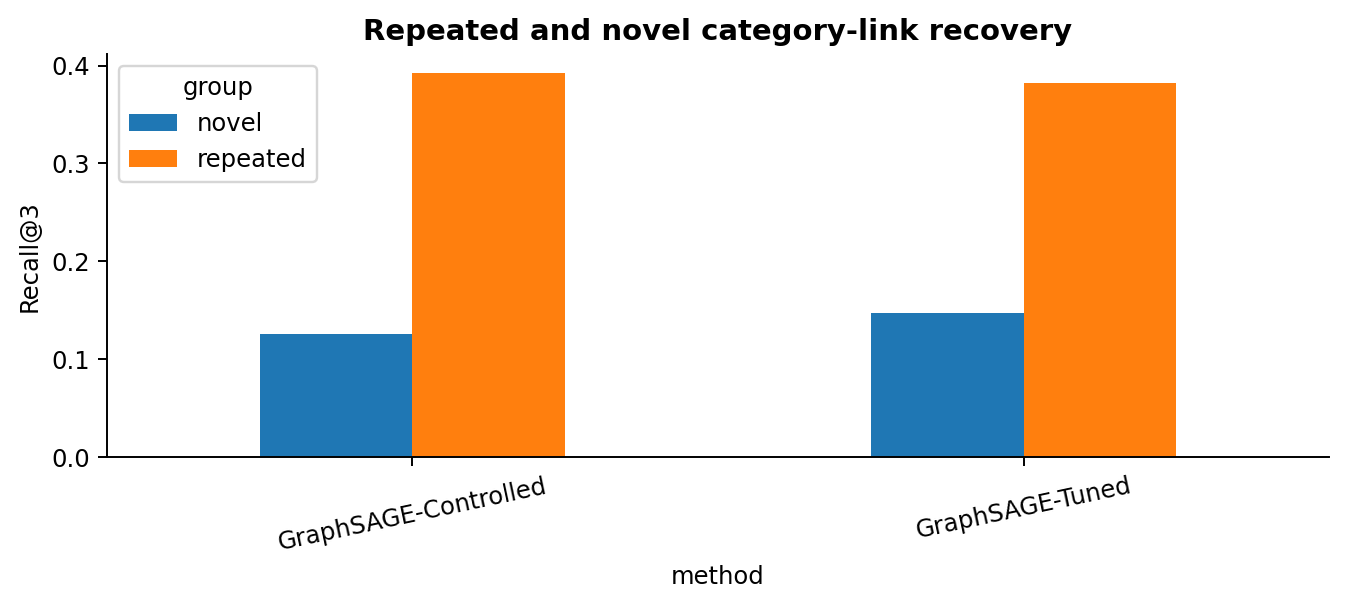

**Recall@5 split by previously observed versus novel positive links**

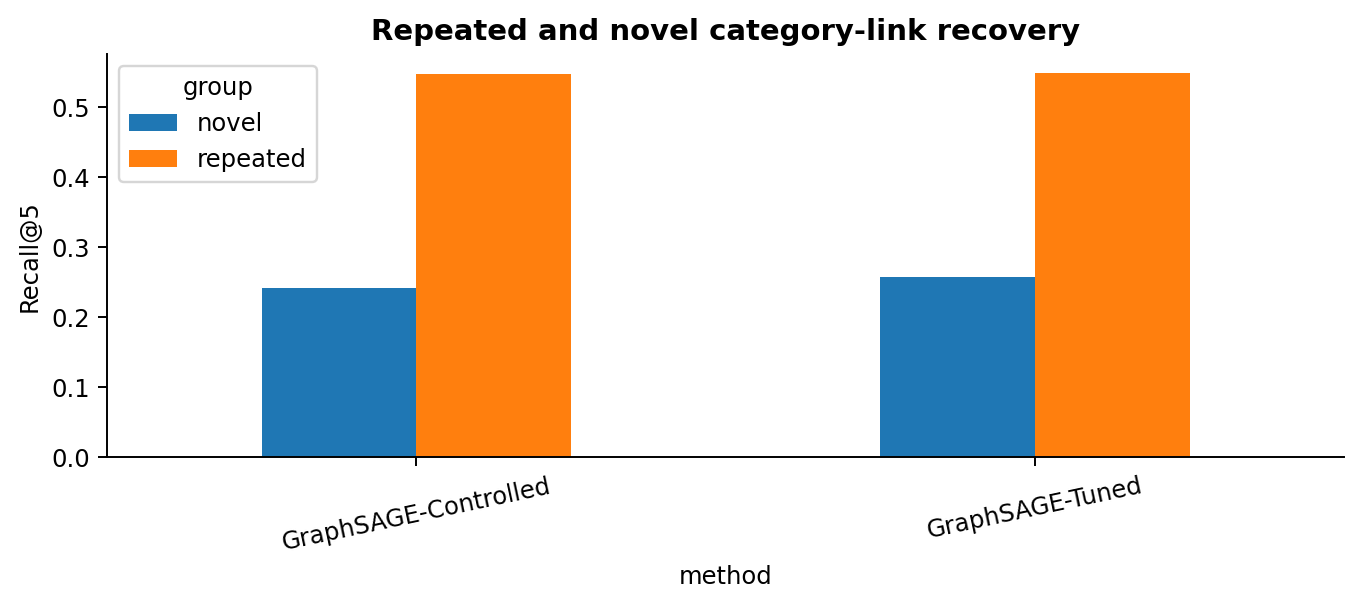

**Recall@10 split by previously observed versus novel positive links**

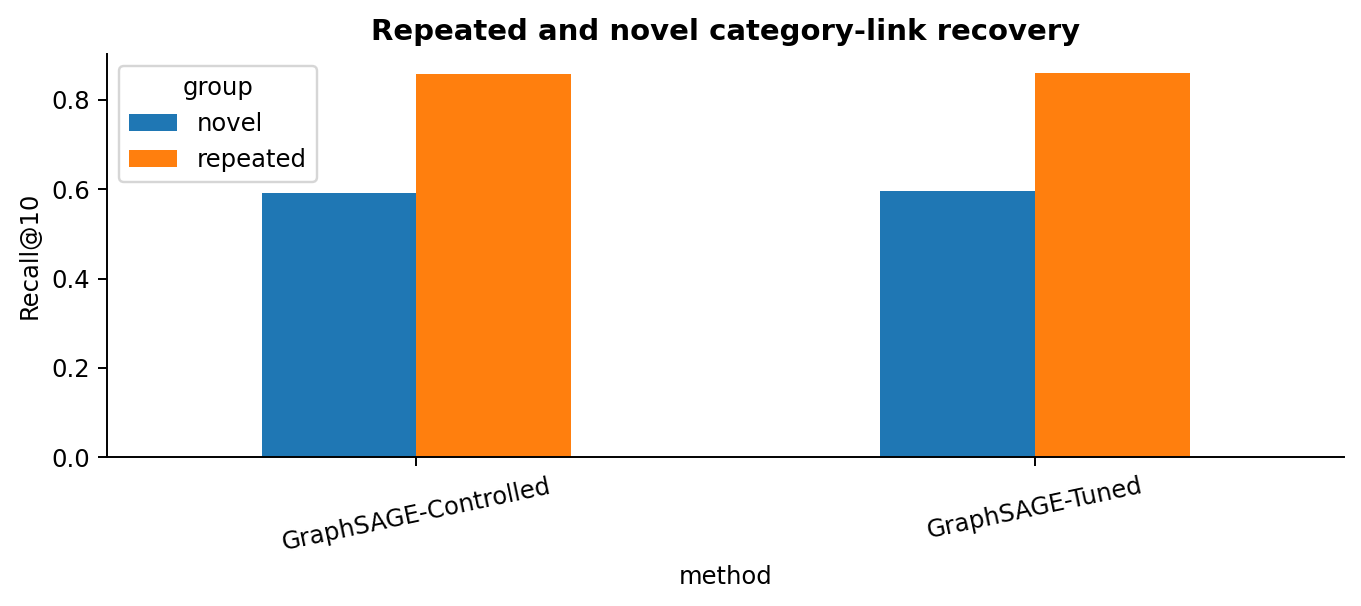

**Ranking performance by historical customer degree; inspect subgroup sample sizes**

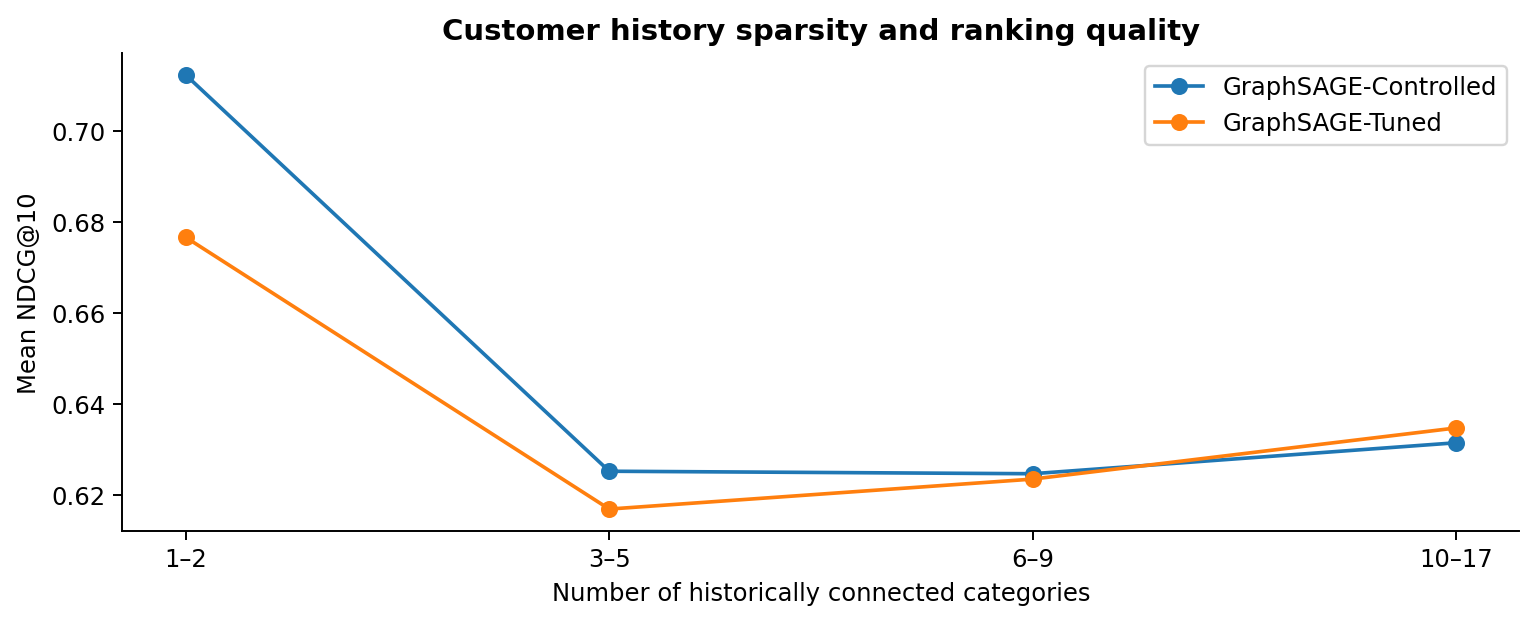

**Degree subgroup sizes: essential context for the curve**

,method,degree_band,mean,count
0,GraphSAGE-Controlled,1–2,0.7122,3
1,GraphSAGE-Controlled,3–5,0.6252,102
2,GraphSAGE-Controlled,6–9,0.6247,264
3,GraphSAGE-Controlled,10–17,0.6315,417
4,GraphSAGE-Tuned,1–2,0.6766,3
5,GraphSAGE-Tuned,3–5,0.6169,102
6,GraphSAGE-Tuned,6–9,0.6235,264
7,GraphSAGE-Tuned,10–17,0.6347,417


In [ ]:
for ds in DATASETS:
    ds_header(ds)
    d=ALL_DIVERSITY[(ALL_DIVERSITY.dataset==ds)&(ALL_DIVERSITY.split=='test')&
         ALL_DIVERSITY.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])]
    means=d.groupby('method')[['distinct_ordered_top10','distinct_unordered_top10','customer_count']].mean()
    numeric_table(means,'Personalisation diversity per test period (mean across seeds and periods)')
    fig,ax=plt.subplots(figsize=(8,3.8))
    means[['distinct_ordered_top10','distinct_unordered_top10']].plot.bar(ax=ax)
    ax.tick_params(axis='x',rotation=12);ax.set(ylabel='Distinct top-10 rankings/sets',
         title='Are customers receiving distinct category lists?')
    chapter_figure(fig,ds,'04_recommendation_personalisation',f'{ds}_ordered_unordered_diversity',
                   'Unique ordered versus unordered top-10 recommendations (17-category candidate universe)')
    rows=[]
    for m in ('GraphSAGE-Controlled','GraphSAGE-Tuned'):
        # Candidate files were recorded in the already completed evaluation.
        for ss in ALL_DIVERSITY[(ALL_DIVERSITY.dataset==ds)&(ALL_DIVERSITY.method==m)&(ALL_DIVERSITY.split=='test')].itertuples():
            p=OUT/f'predictions/{ds}/{m}/seed{ss.seed}/test/{ss.target_month}_candidates.csv.gz'
            cand=pd.read_csv(p,usecols=['category_idx','rank'])
            count=cand[cand['rank']<=10].groupby('category_idx').size()
            for c in range(N_CAT):rows.append(dict(method=m,category=c,target_period=ss.target_month,seed=ss.seed,
                                     exposure=int(count.get(c,0)),customers=ss.customer_count))
    exp=pd.DataFrame(rows)
    exp['exposure_rate']=exp.exposure/exp.customers
    x=exp.groupby(['method','category']).exposure_rate.mean().unstack(0).reindex(range(17))
    fig,ax=plt.subplots(figsize=(9,4));x.plot.bar(ax=ax,width=.84)
    ax.set(xlabel='Category index',ylabel='Fraction of customers receiving category in top 10',
           title='Recommendation exposure and popularity concentration')
    chapter_figure(fig,ds,'07_category_exposure',f'{ds}_category_exposure',
                   'Top-10 exposure frequency by category, averaged over held-out periods and seeds')
    nov=ALL_NOVELTY[(ALL_NOVELTY.dataset==ds)&(ALL_NOVELTY.split=='test')&
                    ALL_NOVELTY.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])]
    for metric in ('Recall@3','Recall@5','Recall@10'):
        z=nov.groupby(['method','group'])[metric].mean().unstack()
        fig,ax=plt.subplots(figsize=(8,3.7));z.plot.bar(ax=ax)
        ax.set(ylabel=metric,title='Repeated and novel category-link recovery')
        ax.tick_params(axis='x',rotation=12)
        chapter_figure(fig,ds,'05_repeated_vs_novel_links',f'{ds}_novel_repeat_{metric.replace("@","at")}',
                       f'{metric} split by previously observed versus novel positive links')
    z=ALL_INSTANCES[(ALL_INSTANCES.dataset==ds)&(ALL_INSTANCES.split=='test')&
               ALL_INSTANCES.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])].copy()
    z['degree_band']=pd.cut(z.historical_degree,[-.1,0,2,5,9,17],
                         labels=['0','1–2','3–5','6–9','10–17'])
    agg=z.groupby(['method','degree_band'],observed=True)['NDCG@10'].agg(['mean','count']).reset_index()
    save_csv(agg,OUT/f'tables/{ds}_customer_history_degree_strata.csv')
    fig,ax=plt.subplots(figsize=(9,3.8))
    for method,ss in agg.groupby('method'):
        ax.plot(ss.degree_band.astype(str),ss['mean'],marker='o',label=method)
    ax.legend();ax.set(xlabel='Number of historically connected categories',ylabel='Mean NDCG@10',
           title='Customer history sparsity and ranking quality')
    chapter_figure(fig,ds,'06_customer_subgroups',f'{ds}_degree_stratified_ndcg',
                   'Ranking performance by historical customer degree; inspect subgroup sample sizes')
    numeric_table(agg,'Degree subgroup sizes: essential context for the curve')

## 09 · Representational geometry and numerical stability

**Question.** Does propagation cause embedding concentration, explode score magnitudes, or produce saturated decision scores?

The figures below track mean and upper-tail customer embedding norms across layers, and the entropy effective rank of the *singular-value spectrum* of the centred customer-embedding matrix. Effective rank is a descriptive proxy for embedding dimensional diversity, **not** a proof of oversmoothing. Score diagnostics report median/p99 absolute logits and the fraction with $|s|>16$; logits are not calibrated probabilities.

#### EuroMart · quarterly

**Layer-wise entropy effective rank of singular values; descriptive mean over observed test records**

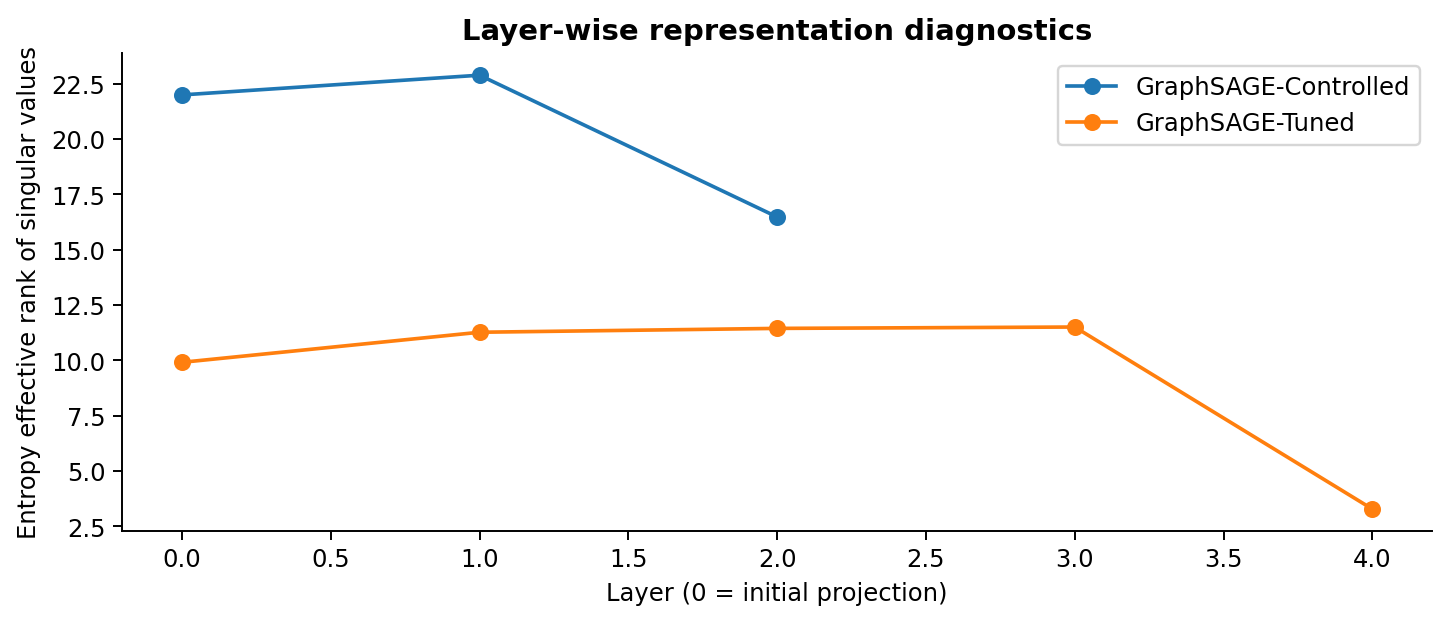

**Layer-wise mean customer embedding l2 norm; descriptive mean over observed test records**

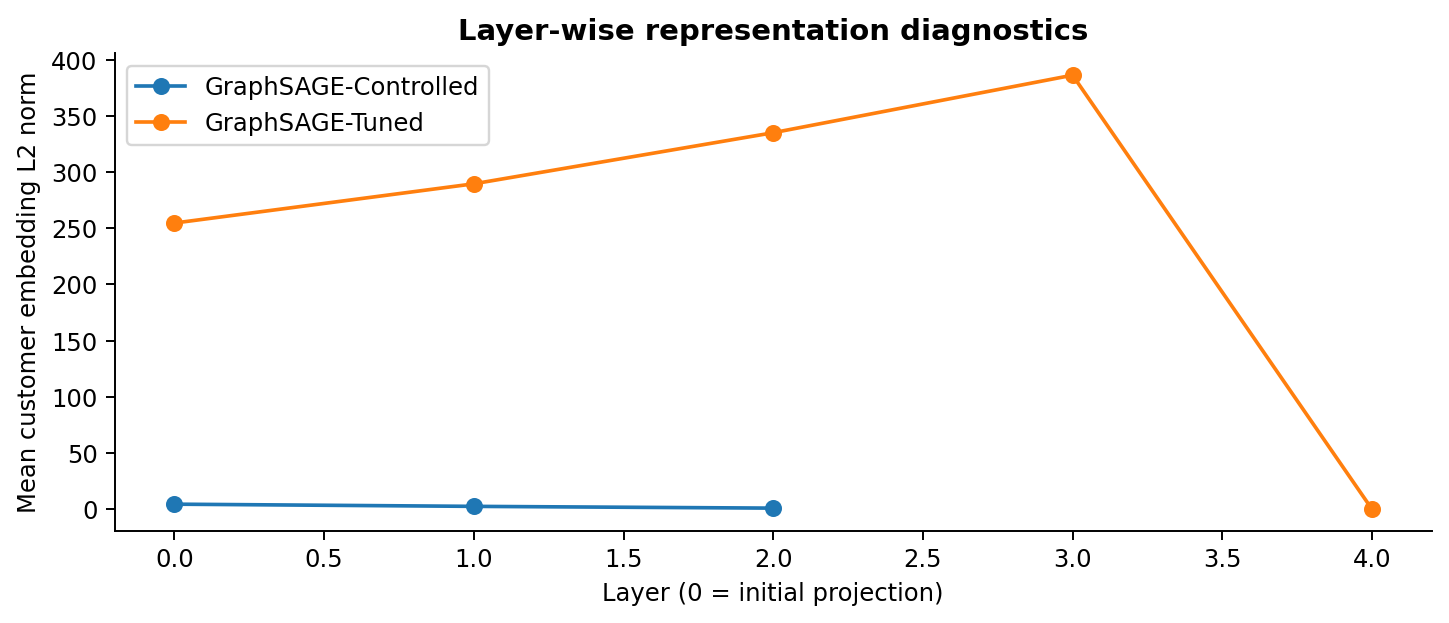

**Layer-wise 95th percentile customer embedding l2 norm; descriptive mean over observed test records**

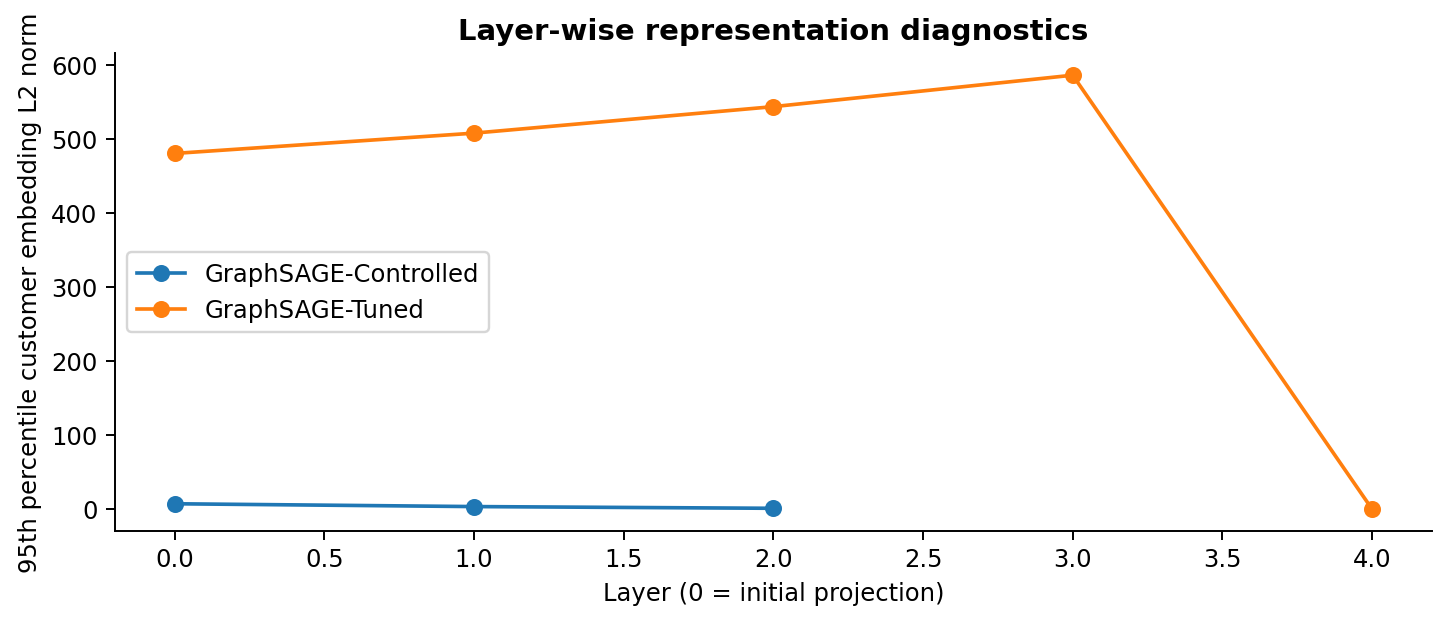

**Median absolute logit over held-out periods and available seeds**

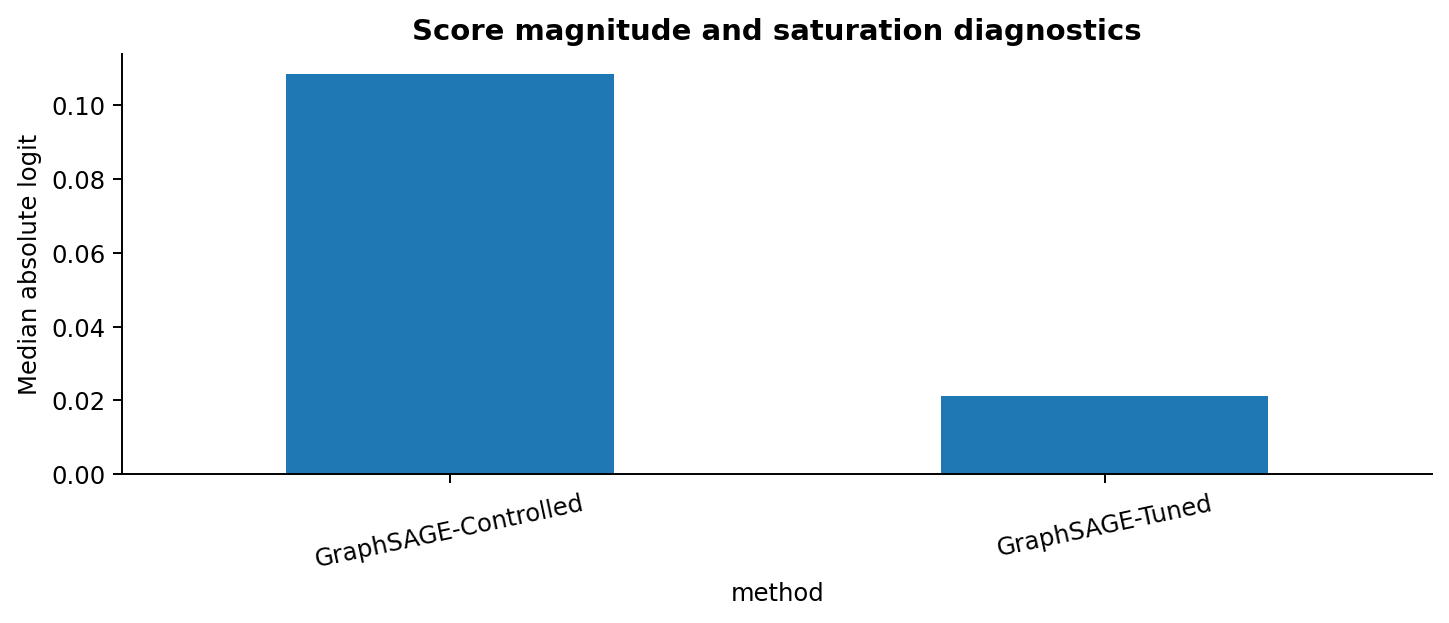

**99th percentile absolute logit over held-out periods and available seeds**

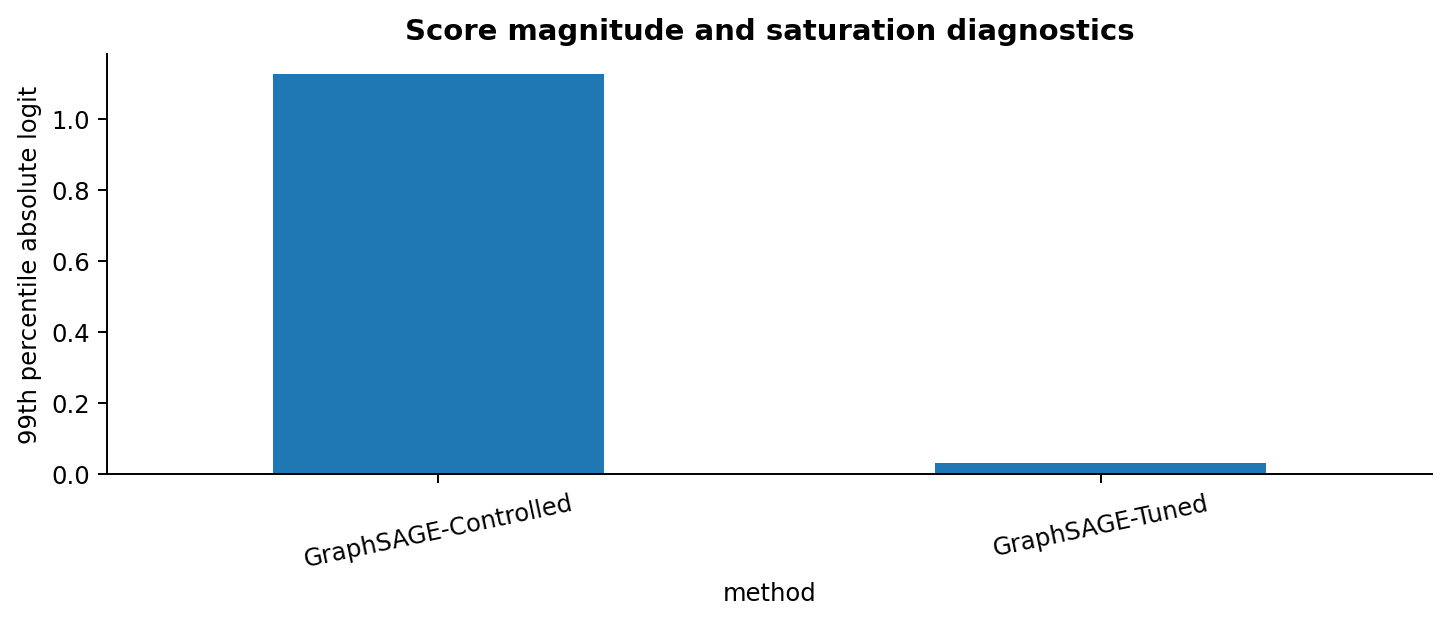

**Fraction |logit|>16 over held-out periods and available seeds**

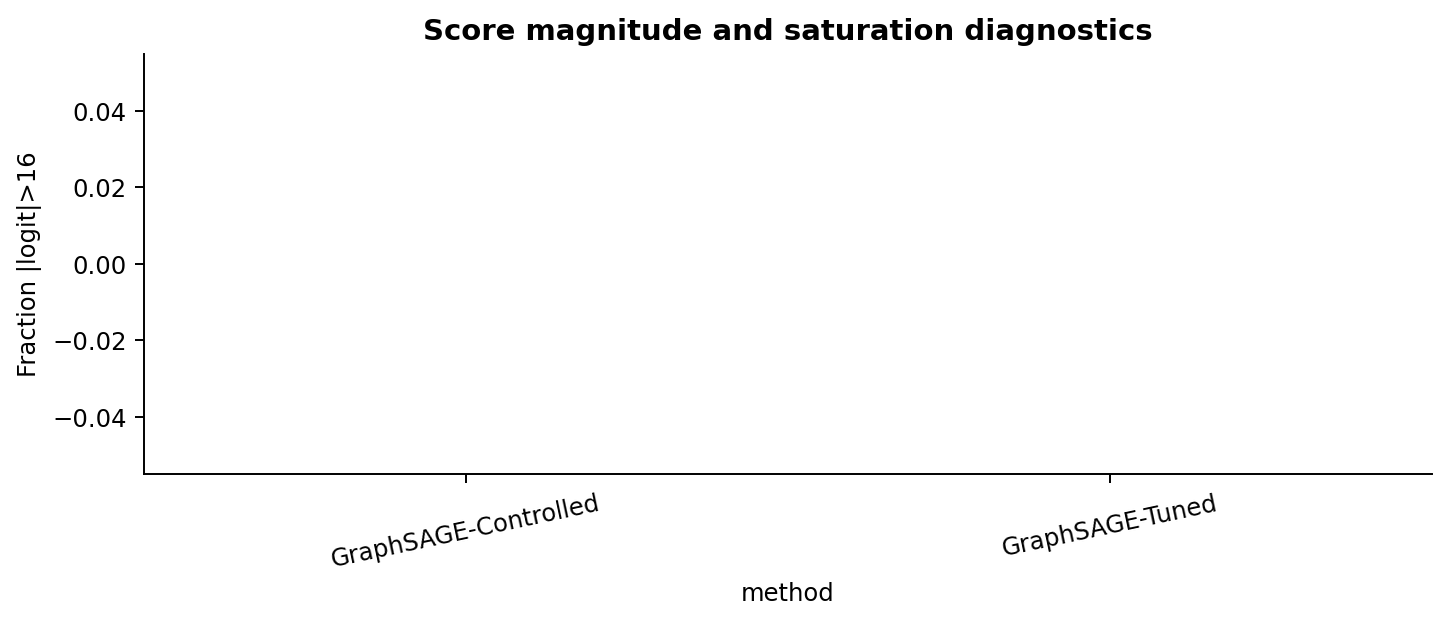

#### Retail POS · monthly

**Layer-wise entropy effective rank of singular values; descriptive mean over observed test records**

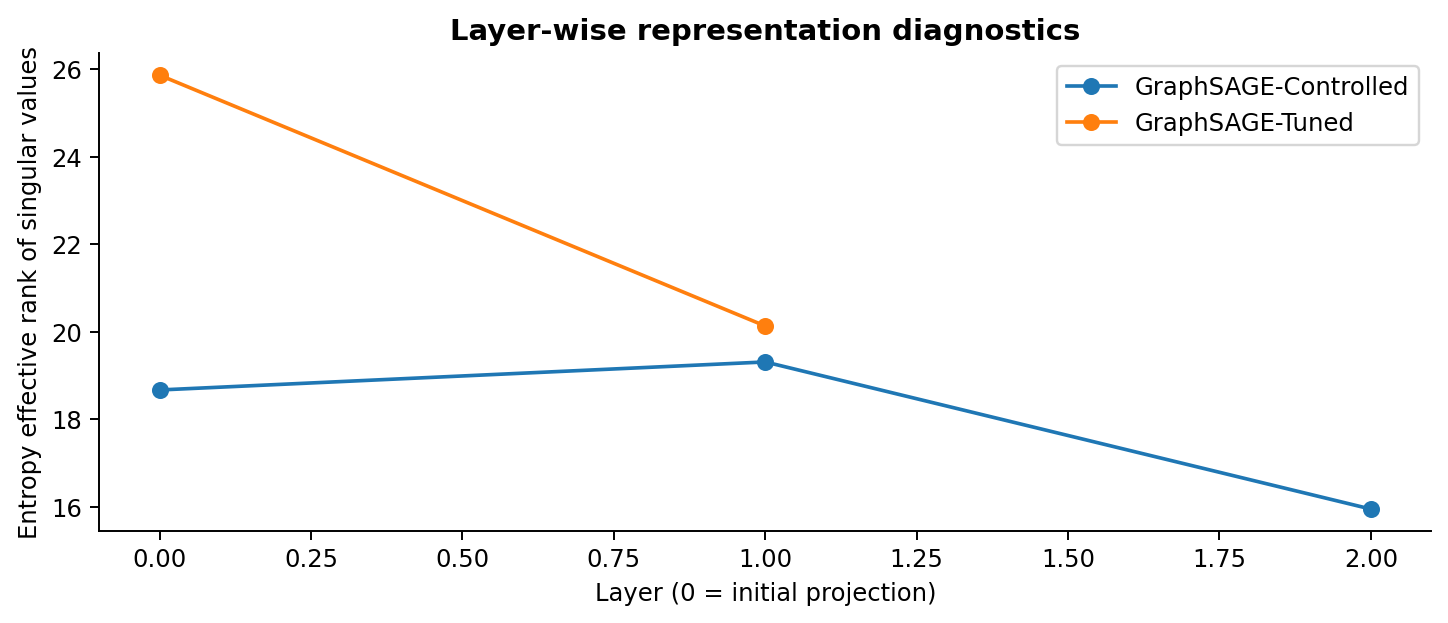

**Layer-wise mean customer embedding l2 norm; descriptive mean over observed test records**

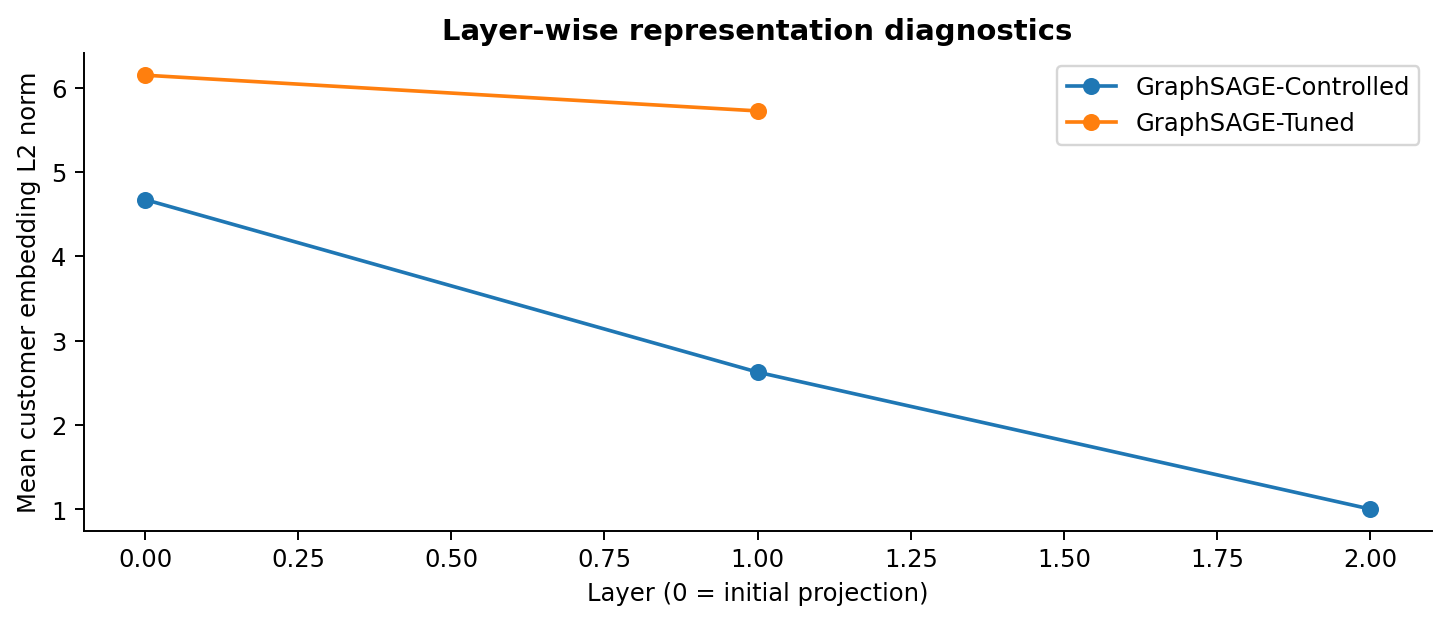

**Layer-wise 95th percentile customer embedding l2 norm; descriptive mean over observed test records**

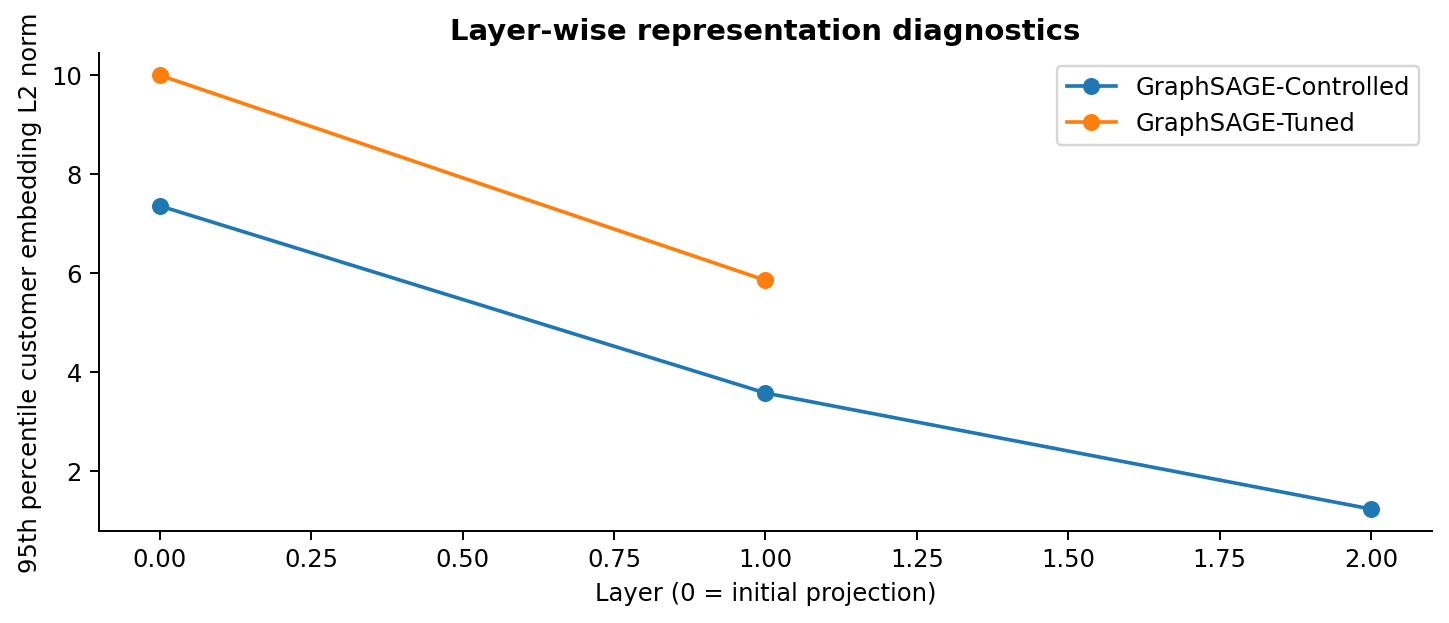

**Median absolute logit over held-out periods and available seeds**

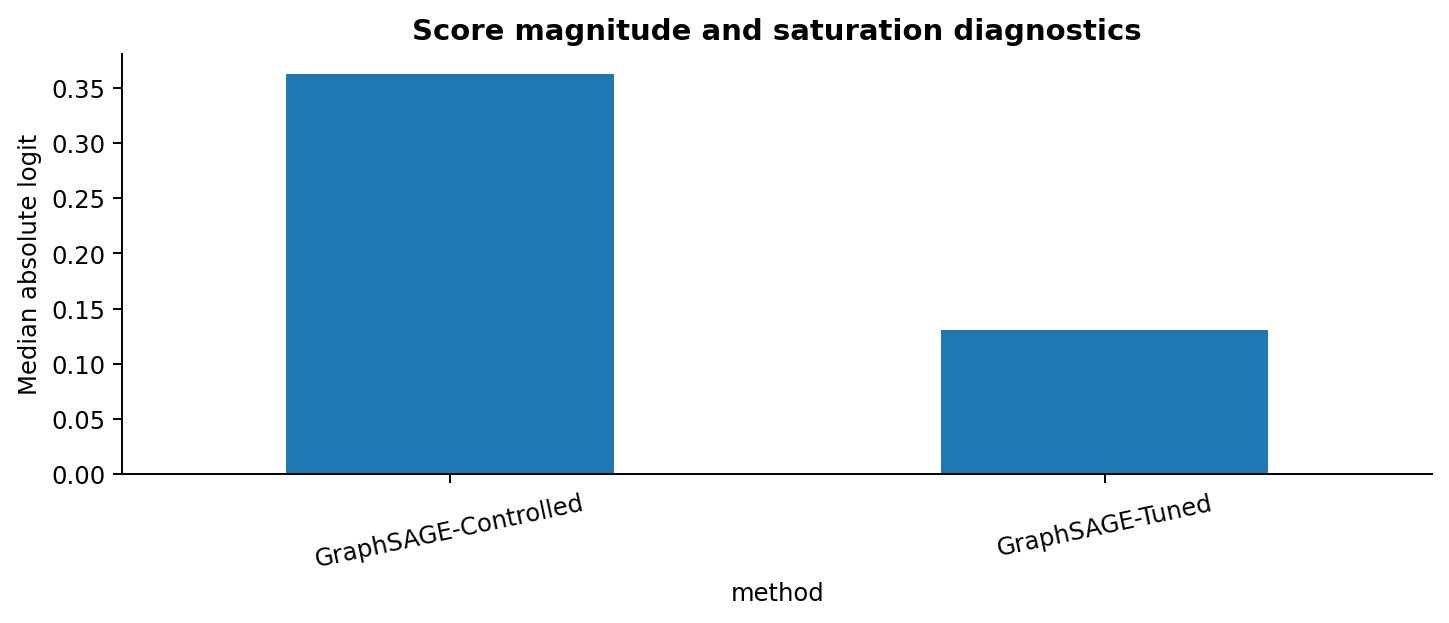

**99th percentile absolute logit over held-out periods and available seeds**

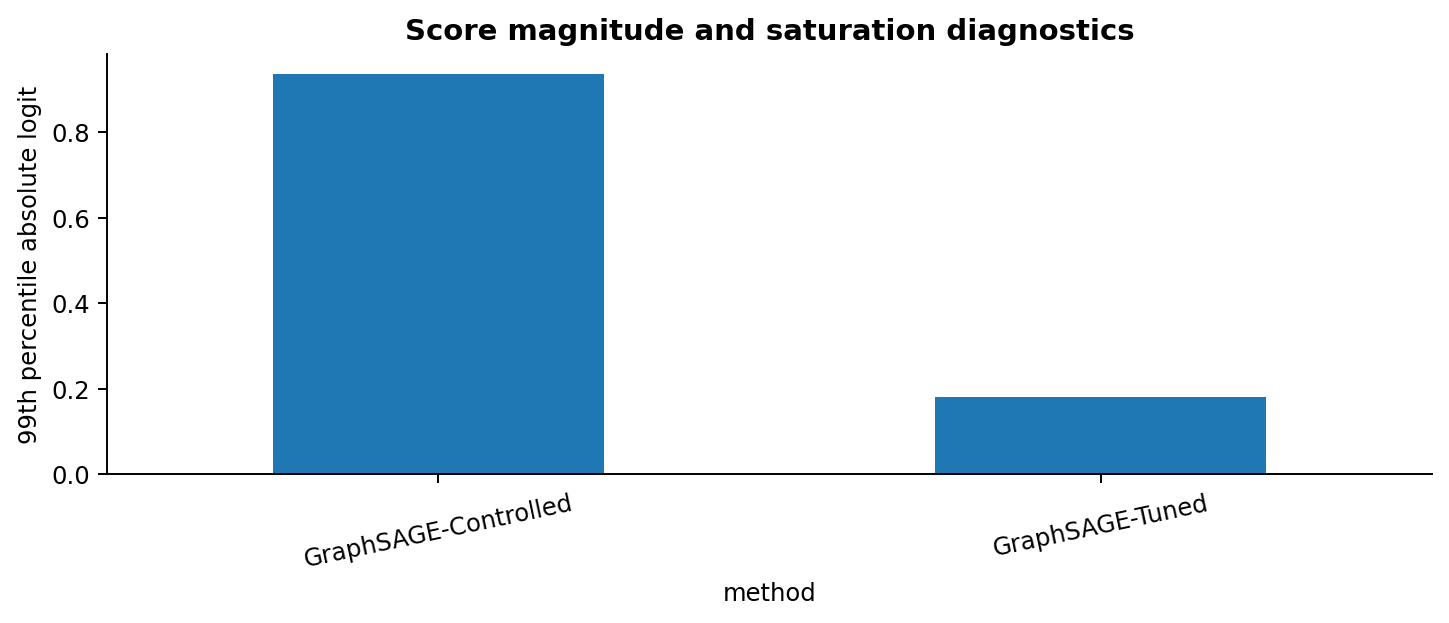

**Fraction |logit|>16 over held-out periods and available seeds**

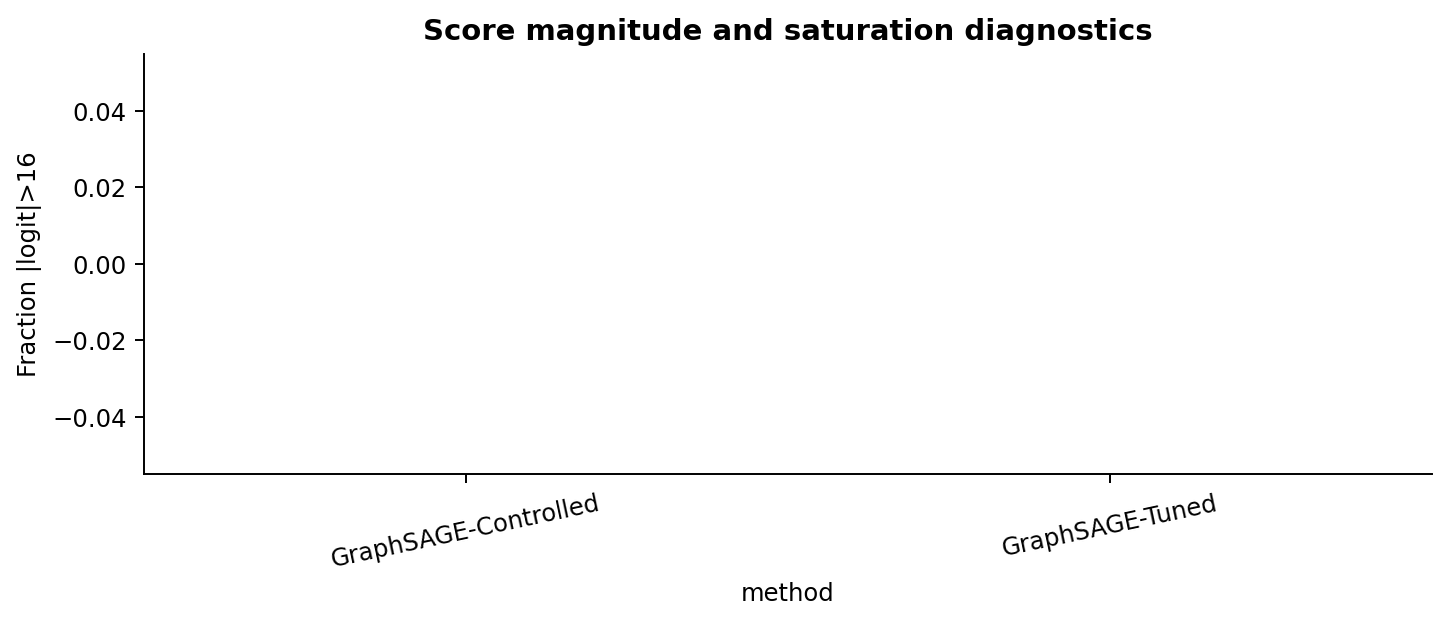

In [ ]:
for ds in DATASETS:
    ds_header(ds)
    x=ALL_LAYERS[(ALL_LAYERS.dataset==ds)&(ALL_LAYERS.split=='test')&
        ALL_LAYERS.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])]
    for metric,label in [('effective_rank','Entropy effective rank of singular values'),
                         ('mean_norm','Mean customer embedding L2 norm'),
                         ('p95_norm','95th percentile customer embedding L2 norm')]:
        fig,ax=plt.subplots(figsize=(8.5,3.8))
        for name,ss in x.groupby('method'):
            agg=ss.groupby('layer')[metric].mean()
            ax.plot(agg.index,agg.values,marker='o',label=name)
        ax.set(xlabel='Layer (0 = initial projection)',ylabel=label,title='Layer-wise representation diagnostics')
        ax.legend()
        chapter_figure(fig,ds,'11_embedding_diagnostics',f'{ds}_{metric}_by_layer',
                       f'Layer-wise {label.lower()}; descriptive mean over observed test records')
    ss=ALL_MONTHS[(ALL_MONTHS.dataset==ds)&(ALL_MONTHS.split=='test')&
        ALL_MONTHS.method.isin(['GraphSAGE-Controlled','GraphSAGE-Tuned'])]
    for metric,label in [('median_abs_logit','Median absolute logit'),
                         ('p99_abs_logit','99th percentile absolute logit'),
                         ('saturation_fraction','Fraction |logit|>16')]:
        fig,ax=plt.subplots(figsize=(8.5,3.8))
        ss.groupby('method')[metric].mean().plot.bar(ax=ax)
        ax.tick_params(axis='x',rotation=12);ax.set(ylabel=label,title='Score magnitude and saturation diagnostics')
        chapter_figure(fig,ds,'12_optimisation_stability',f'{ds}_{metric}_diagnostic',
                       f'{label} over held-out periods and available seeds')

## 10 · Synthesis, evidence limitations and reproducibility index

**What is directly identifiable:** selected validation architecture, held-out within-dataset ranking performance, empirical three-seed variation, conditional customer-level uncertainty, and descriptive effects of explicitly trained ablations.

**What this experiment does not prove:** that a small positive test difference generalises to future quarters, that embedding rank alone establishes oversmoothing, or that an ablation on fixed historical node features represents a genuine counterfactual transaction history. The v5 test outcomes are also exploratory because earlier project iterations exposed related test sets.

The final cell saves a figure registry with **captions, scientific chapter, paths and underlying data sources**. It checks that every newly generated plot exists in both PNG and SVG formats, writes summary CSVs, and stores a reproducibility manifest. No figure is merely linked: all are displayed when its analysis chapter runs.

In [ ]:
# Synthesis ledger, computed only from stored v5 results; no unsupported causal interpretation.
LEDGER=[]
for ds in DATASETS:
    winner=SELECTION3[ds]['best_validation_method']
    base=RUN3_SUMMARY[(RUN3_SUMMARY.dataset==ds)&(RUN3_SUMMARY.method==winner)]
    c=SUMMARY[(SUMMARY.dataset==ds)&(SUMMARY.method=='GraphSAGE-Controlled')]
    t=SUMMARY[(SUMMARY.dataset==ds)&(SUMMARY.method=='GraphSAGE-Tuned')]
    nm=SUMMARY[(SUMMARY.dataset==ds)&(SUMMARY.method=='GraphSAGE-NoMessages')]
    b=pd.DataFrame(BOOT)
    ci=b[(b.dataset==ds)&(b.method=='GraphSAGE-Tuned')&(b.baseline==winner)]
    div=ALL_DIVERSITY[(ALL_DIVERSITY.dataset==ds)&(ALL_DIVERSITY.method=='GraphSAGE-Tuned')&
                      (ALL_DIVERSITY.split=='test')]
    value=lambda frame,key:float(frame[key].iloc[0]) if len(frame) else float('nan')
    row={'dataset':ds,'run3_validation_winner':winner,
         'run3_winner_test_ndcg10':value(base,'NDCG@10'),
         'controlled_test_ndcg10':value(c,'NDCG@10'),
         'tuned_test_ndcg10':value(t,'NDCG@10'),
         'tuned_minus_run3_winner':value(t,'NDCG@10')-value(base,'NDCG@10'),
         'controlled_minus_no_messages':value(c,'NDCG@10')-value(nm,'NDCG@10'),
         'paired_ci_low':value(ci,'ci_low'),'paired_ci_high':value(ci,'ci_high'),
         'distinct_unordered_top10_mean':float(div.distinct_unordered_top10.mean()) if len(div) else float('nan'),
         'customers_per_test_period_mean':float(div.customer_count.mean()) if len(div) else float('nan')}
    LEDGER.append(row)
ledger=pd.DataFrame(LEDGER)
save_csv(ledger,OUT/'tables/narrative_evidence_ledger.csv')
display(NotebookMarkdown('### Evidence ledger · directly grounded in computed tables'))
display(ledger.round(5))
for row in LEDGER:
    scope=('smoke-test diagnostics only' if PROFILE=='smoke' else 'exploratory v5 test results')
    zero=('includes zero' if row['paired_ci_low']<=0<=row['paired_ci_high'] else 'excludes zero')
    display(NotebookMarkdown(
       f"**{row['dataset']} ({scope}).** The validation-selected Run 3 comparator is "
       f"{row['run3_validation_winner']}. Tuned GraphSAGE differs by "
       f"{row['tuned_minus_run3_winner']:+.4f} NDCG@10 on the observed test cohort; "
       f"the conditional paired interval {zero}. Controlled minus NoMessages is "
       f"{row['controlled_minus_no_messages']:+.4f}. The Tuned model generates, on average, "
       f"{row['distinct_unordered_top10_mean']:.1f} unique unordered top-10 sets per test period "
       f"among approximately {row['customers_per_test_period_mean']:.0f} eligible customers. "
       'None of these comparisons independently establishes causal generalisation to new calendar periods.'))

assert FIGURES and all((OUT/f['png']).exists() and (OUT/f['svg']).exists() for f in FIGURES)
figdf=pd.DataFrame(FIGURES)
save_csv(figdf,OUT/'tables/narrative_figure_index.csv')
counts=figdf.groupby(['chapter','dataset']).size().rename('figures').reset_index()
save_csv(counts,OUT/'tables/narrative_figure_counts.csv')
write_json(OUT/'manifests/narrative_figure_registry.json',FIGURES)
# Complete, current-run data tables; existing v3/v4 artifacts are untouched.
status=pd.DataFrame(STATUS)
save_csv(status,OUT/'tables/narrative_seed_status.csv')
write_json(OUT/'manifests/narrative_completion.json',{
  'profile':PROFILE,'status':('smoke_complete' if PROFILE=='smoke' else 'exhaustive_complete') if not (status.status=='failure').any() else 'completed_with_seed_failures',
  'figure_count':len(FIGURES),'successful_seed_rows':int((status.status=='ok').sum()),
  'failed_seed_rows':int((status.status=='failure').sum()),
  'frozen_selection_hash':filehash(FROZEN_PATH),'run3_selection_hash':RUN3_HASH,
  'node_only_feature_policy':True,'seeds_expected':list(B['final_seeds']),
  'hardware':HARDWARE,'force_rerun':FORCE_RERUN,
  'team_comparison_csv':'tables/run6_gnn_team_comparison.csv',
  'note':'Exploratory analyses; earlier project test exposure; intervals conditional on observed periods.'})
lines=['# Run 6 v5 · Narrative Figure Atlas','',
       'All generated figures are displayed inline in the executable notebook. The registered figures are saved by analysis and dataset.','',
       '| Analysis chapter | EuroMart | Retail POS |','|---|---:|---:|']
for name,g in figdf.groupby('chapter',sort=True):
    lines.append(f'| `{name}` | {sum(g.dataset=="euromart")} | {sum(g.dataset=="retail_pos")} |')
lines += ['',f'**Total:** {len(FIGURES)} PNGs and {len(FIGURES)} SVGs.','',
          'CSV catalogue: `tables/narrative_figure_index.csv`.',
          'Machine-readable registry: `manifests/narrative_figure_registry.json`.','',
          '## Figure captions and sources','']
for f in FIGURES:
    lines.append(f'- **{f["dataset"]} / {f["chapter"]} / {f["name"]}** — {f["caption"]}; source `{f["source"]}`')
(FIGROOT/'README_NARRATIVE_FIGURES.md').write_text('\n'.join(lines))
display(NotebookMarkdown('### Figure output by scientific family'))
display(counts.pivot(index='chapter',columns='dataset',values='figures').fillna(0).astype(int))
print(f'RUN 6 {PROFILE.upper()} COMPLETE · {len(FIGURES)} inline figures, PNG+SVG saved.')
print('Index:',OUT/'tables/narrative_figure_index.csv')
print('Source Run3 selection SHA256:',RUN3_HASH)

### Evidence ledger · directly grounded in computed tables

,dataset,run3_validation_winner,run3_winner_test_ndcg10,controlled_test_ndcg10,tuned_test_ndcg10,tuned_minus_run3_winner,controlled_minus_no_messages,paired_ci_low,paired_ci_high,distinct_unordered_top10_mean,customers_per_test_period_mean
0,euromart,FeatureLogistic,0.47999,0.47126,0.48048,0.00049,-0.00346,-0.00626,0.00691,1.44444,290.66667
1,retail_pos,FeatureMLP,0.62910,0.62868,0.62879,-0.00031,-0.00018,-0.00340,0.00288,1.50000,131.00000


**euromart (exploratory v5 test results).** The validation-selected Run 3 comparator is FeatureLogistic. Tuned GraphSAGE differs by +0.0005 NDCG@10 on the observed test cohort; the conditional paired interval includes zero. Controlled minus NoMessages is -0.0035. The Tuned model generates, on average, 1.4 unique unordered top-10 sets per test period among approximately 291 eligible customers. None of these comparisons independently establishes causal generalisation to new calendar periods.

**retail_pos (exploratory v5 test results).** The validation-selected Run 3 comparator is FeatureMLP. Tuned GraphSAGE differs by -0.0003 NDCG@10 on the observed test cohort; the conditional paired interval includes zero. Controlled minus NoMessages is -0.0002. The Tuned model generates, on average, 1.5 unique unordered top-10 sets per test period among approximately 131 eligible customers. None of these comparisons independently establishes causal generalisation to new calendar periods.

### Figure output by scientific family

dataset,euromart,retail_pos
chapter,,
01_model_performance,7,7
02_statistical_uncertainty,2,2
03_temporal_generalisation,1,1
04_recommendation_personalisation,1,1
05_repeated_vs_novel_links,3,3
06_customer_subgroups,1,1
07_category_exposure,1,1
08_training_dynamics,6,6
09_hyperparameter_search,7,7


RUN 6 EXHAUSTIVE COMPLETE · 86 inline figures, PNG+SVG saved.
Index: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/tables/narrative_figure_index.csv
Source Run3 selection SHA256: 403875bbe35c44da848d3803cd22bc60f92da47ec2cb05dbbaa1ba137d03d2ca


In [3]:
# ============================================================
# 11.0 — PUBLICATION FIGURES: DATA LOADING
# Reuses Run 3, Run 6, and Run 6B results. No retraining.
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Existing Run 6 variables: ROOT, RUN3, OUT
# Change SOURCE_6B if Run 6B outputs are stored elsewhere.
SOURCE_6B = ROOT / "results/v5/run06B_graphsage_visualisations"

FIG_DIR = OUT / "figures" / "11_publication_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 43, 44)

DATASET_NAMES = {
    "euromart": "EuroMart",
    "retail_pos": "Retail POS"
}

MODELS = [
    "Random",
    "GlobalPopularity",
    "FeatureLogistic",
    "FeatureMLP",
    "GraphSAGE-Controlled",
    "GraphSAGE-Tuned"
]

MODEL_LABELS = {
    "Random": "Random",
    "GlobalPopularity": "GlobalPopularity",
    "FeatureLogistic": "LogReg",
    "FeatureMLP": "MLP",
    "GraphSAGE-Controlled": "GraphSAGE-Controlled",
    "GraphSAGE-Tuned": "GraphSAGE-Tuned"
}

METRICS = ["NDCG@10", "Recall@10", "PR-AUC"]


def load_benchmark():

    combined = (
        SOURCE_6B / "tables" /
        "six_model_combined_summary.csv"
    )

    if combined.exists():
        df = pd.read_csv(combined)

    else:
        # Reconstruct from original Run 3 and Run 6
        run3 = pd.read_csv(
            RUN3 / "tables/run3_test_summary.csv"
        )

        run6 = pd.read_csv(
            OUT / "tables/run6_test_summary.csv"
        )

        df = pd.concat([
            run3[run3.method.isin(MODELS[:4])],
            run6[run6.method.isin(MODELS[4:])]
        ], ignore_index=True)

    df = df[
        df.dataset.isin(DATASET_NAMES)
        & df.method.isin(MODELS)
    ].copy()

    for metric in METRICS:
        df[metric] = pd.to_numeric(
            df[metric], errors="coerce"
        )

        sd = metric + "_seed_sd"
        if sd not in df.columns:
            df[sd] = np.nan

    for ds in DATASET_NAMES:
        for model in MODELS:
            count = len(df[
                (df.dataset == ds)
                & (df.method == model)
            ])
            assert count == 1, (
                f"Expected one row for {ds}/{model}; "
                f"found {count}"
            )

    return df


ABLATION_FOLDERS = {
    "euromart":
        "tuned_reference_ablations_euromart_v2",
    "retail_pos":
        "tuned_reference_ablations_retail_pos_l2_v1"
}


def load_ablation(dataset):

    path = (
        SOURCE_6B /
        ABLATION_FOLDERS[dataset] /
        "per_seed_results.csv"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Missing Run 6B ablation results:\n{path}\n"
            "Set SOURCE_6B to the correct output directory."
        )

    df = pd.read_csv(path)

    if "dataset" in df.columns:
        df = df[
            df.dataset.astype(str).str.lower() == dataset
        ].copy()

    df = df[
        pd.to_numeric(df.seed, errors="coerce").isin(SEEDS)
    ].copy()

    metric = (
        "test_NDCG@10"
        if "test_NDCG@10" in df.columns
        else "NDCG@10"
    )

    if metric not in df.columns:
        raise KeyError(
            f"No NDCG@10 metric column found in {path}"
        )

    df["_ndcg"] = pd.to_numeric(
        df[metric], errors="coerce"
    )

    df.loc[
        df.status.astype(str).str.lower() != "ok",
        "_ndcg"
    ] = np.nan

    if df.duplicated(["family", "variant", "seed"]).any():
        raise ValueError(
            f"Duplicate family/variant/seed rows in {path}"
        )

    return df


def save_figure(fig, filename, data=None):

    stem = FIG_DIR / filename

    for extension in ("png", "svg", "pdf"):
        fig.savefig(
            stem.with_suffix("." + extension),
            dpi=220,
            bbox_inches="tight"
        )

    if data is not None:
        data.to_csv(
            stem.with_suffix(".csv"), index=False
        )

    print(f"Saved: {stem}")

In [4]:
# ============================================================
# 11.1 — SIX-MODEL HELD-OUT BENCHMARK FIGURES
# ============================================================

def plot_benchmark(dataset, summary):

    sub = summary[
        summary.dataset == dataset
    ].copy()

    sub["method"] = pd.Categorical(
        sub.method,
        categories=MODELS,
        ordered=True
    )

    sub = sub.sort_values("method").reset_index(drop=True)

    colors = {
        "NDCG@10": "#2D70A6",
        "Recall@10": "#3B9C6D",
        "PR-AUC": "#C98632"
    }

    offsets = {
        "NDCG@10": -0.24,
        "Recall@10": 0,
        "PR-AUC": 0.24
    }

    fig, ax = plt.subplots(figsize=(12.5, 6.8))

    y = np.arange(len(sub))
    export = []

    for metric in METRICS:

        values = sub[metric].to_numpy(float)

        sd = pd.to_numeric(
            sub[metric + "_seed_sd"],
            errors="coerce"
        ).to_numpy(float)

        errors = np.where(
            np.isfinite(sd) & (sd > 0), sd, 0
        )

        positions = y + offsets[metric]

        ax.barh(
            positions,
            values,
            height=0.22,
            color=colors[metric],
            edgecolor="white",
            linewidth=0.8,
            label=metric,
            zorder=3
        )

        valid = errors > 0

        if valid.any():
            ax.errorbar(
                values[valid],
                positions[valid],
                xerr=errors[valid],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1.1,
                zorder=5
            )

        for i, (v, e, pos) in enumerate(
            zip(values, errors, positions)
        ):

            ax.annotate(
                f"{v:.4f}",
                (v + e, pos),
                xytext=(6, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=9,
                color="#23364C"
            )

            export.append({
                "dataset": dataset,
                "method": str(sub.loc[i, "method"]),
                "metric": metric,
                "mean": v,
                "seed_sd": sd[i]
            })

    ax.set_yticks(
        y,
        [
            MODEL_LABELS[str(model)]
            for model in sub.method
        ]
    )

    ax.invert_yaxis()

    ax.set_xlim(0, 0.89)
    ax.set_xlabel("Metric value", fontsize=12)

    ax.set_title(
        f"{DATASET_NAMES[dataset]} · "
        "held-out benchmark comparison",
        fontsize=15,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        alpha=0.15,
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        title="Metric",
        loc="upper right",
        frameon=True
    )

    fig.tight_layout()

    results = pd.DataFrame(export)

    save_figure(
        fig,
        f"{dataset}_six_model_heldout_benchmark",
        results
    )

    plt.show()
    plt.close(fig)

    return results

In [5]:
# ============================================================
# 11.2 — TUNED-REFERENCE GRAPHsage ABLATION FIGURES
# Five families, sample SD across seeds 42, 43, 44
# ============================================================

FACETS = {

    "euromart": [
        (
            "Depth", "Propagation depth",
            [
                ("Depth1", "1 layer"),
                ("Depth2", "2 layers"),
                ("Depth3", "3 layers")
            ]
        ),
        (
            "Features", "Node features",
            [
                ("NoCustomerFeatures", "No cust."),
                ("NoCategoryFeatures", "No cat."),
                ("NoNodeFeatures", "No features")
            ]
        ),
        (
            "Messages", "Neighbour mechanisms",
            [
                ("NoMessages", "No msgs"),
                ("Aggregator_mean", "Mean"),
                ("Aggregator_sum", "Sum"),
                ("Aggregator_degree_sqrt", "Deg-sqrt"),
                ("NoNeighbourBias", "No bias")
            ]
        ),
        (
            "Topology", "Graph topology",
            [
                ("Rewired1", "Rewire 1"),
                ("Rewired2", "Rewire 2"),
                ("Rewired3", "Rewire 3")
            ]
        ),
        (
            "Stabilisation", "Stabilisation",
            [
                ("Residual1_LayerNorm0", "Residual"),
                ("Residual0_LayerNorm1", "LayerNorm"),
                ("Residual0_LayerNorm0", "Neither")
            ]
        )
    ],

    "retail_pos": [
        (
            "Depth", "Propagation depth",
            [
                ("Depth2", "2 layers"),
                ("Depth3", "3 layers"),
                ("Depth4", "4 layers")
            ]
        ),
        (
            "Features", "Node features",
            [
                ("NoCustomerFeatures", "No cust."),
                ("NoCategoryFeatures", "No cat."),
                ("NoNodeFeatures", "No features")
            ]
        ),
        (
            "Messages", "Neighbour mechanisms",
            [
                ("NoMessages", "No msgs"),
                ("Aggregator_mean", "Mean"),
                ("Aggregator_max", "Max"),
                ("Aggregator_sum", "Sum"),
                ("NoNeighbourBias", "No bias")
            ]
        ),
        (
            "Topology", "Graph topology",
            [
                ("Rewired1", "Rewire 1"),
                ("Rewired2", "Rewire 2"),
                ("Rewired3", "Rewire 3")
            ]
        ),
        (
            "Stabilisation",
            "Normalisation and stability",
            [
                ("L2_0_LayerNorm_0", "Neither"),
                ("L2_1_LayerNorm_0", "L2 only"),
                ("L2_0_LayerNorm_1", "LN only")
            ]
        )
    ]
}


def ablation_stats(df, family, variant):

    sub = df[
        (df.family == family)
        & (df.variant == variant)
    ]

    values = sub["_ndcg"].dropna().to_numpy(float)

    return {
        "mean": (
            float(values.mean())
            if len(values) else np.nan
        ),
        "sd": (
            float(values.std(ddof=1))
            if len(values) > 1 else np.nan
        ),
        "n": len(values),
        "attempted": len(sub)
    }


def plot_ablations(dataset, df):

    reference = ablation_stats(
        df, "Reference", "Tuned"
    )

    if reference["n"] != 3:
        raise ValueError(
            "Tuned reference requires three successful seeds."
        )

    ref_score = reference["mean"]

    panels = []
    export = []
    bounds = []

    available = set(
        zip(df.family, df.variant)
    )

    for family, title, variants in FACETS[dataset]:

        rows = [{
            "family": "Reference",
            "variant": "Tuned",
            "label": "Tuned",
            **reference
        }]

        for variant, label in variants:

            if (family, variant) not in available:
                warnings.warn(
                    f"{dataset}: missing {family}/{variant}"
                )

            rows.append({
                "family": family,
                "variant": variant,
                "label": label,
                **ablation_stats(df, family, variant)
            })

        panels.append((title, rows))

        for row in rows:

            export.append({
                "dataset": dataset,
                "panel": title,
                **row
            })

            if np.isfinite(row["mean"]):

                sd = (
                    row["sd"]
                    if np.isfinite(row["sd"])
                    else 0
                )

                bounds.extend([
                    row["mean"] - sd,
                    row["mean"] + sd
                ])

    if not bounds:
        raise ValueError("No valid ablation results.")

    low, high = min(bounds), max(bounds)
    span = max(high - low, 0.01)

    ylim = (
        max(0, low - 0.10 * span),
        min(1, high + 0.19 * span)
    )

    DARK_BLUE = "#287DB7"
    LIGHT_BLUE = "#AEC3DE"
    RED = "#C94747"

    with plt.rc_context({
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "axes.edgecolor": "#444444",
        "pdf.fonttype": 42,
        "svg.fonttype": "none"
    }):

        fig, axes = plt.subplots(
            2, 3,
            figsize=(13.4, 7.0),
            gridspec_kw={
                "wspace": 0.20,
                "hspace": 0.43
            }
        )

        axes = axes.ravel()

        for i, (title, rows) in enumerate(panels):

            ax = axes[i]
            ax.set_ylim(*ylim)

            ax.axhline(
                ref_score,
                color=RED,
                linestyle=":",
                linewidth=1.35,
                zorder=2
            )

            for j, row in enumerate(rows):

                mean = row["mean"]

                if not np.isfinite(mean):
                    ax.text(
                        j,
                        ylim[0] + 0.05 * (ylim[1] - ylim[0]),
                        "failed" if row["attempted"] else "n/a",
                        ha="center",
                        fontsize=8,
                        color=RED
                    )
                    continue

                sd = (
                    row["sd"]
                    if np.isfinite(row["sd"])
                    else 0
                )

                ax.bar(
                    j,
                    mean,
                    width=0.73,
                    color=(
                        DARK_BLUE
                        if j == 0
                        else LIGHT_BLUE
                    ),
                    zorder=3
                )

                if sd > 0:
                    ax.errorbar(
                        j,
                        mean,
                        yerr=sd,
                        fmt="none",
                        color="#414141",
                        capsize=2.5,
                        linewidth=0.85,
                        zorder=4
                    )

                label_y = min(
                    mean + sd + 0.026 * (ylim[1] - ylim[0]),
                    ylim[1] - 0.015 * (ylim[1] - ylim[0])
                )

                ax.text(
                    j,
                    label_y,
                    f"{mean:.4f}",
                    ha="center",
                    va="bottom",
                    fontsize=7.8,
                    color="#252525"
                )

                if row["n"] < 3:
                    ax.text(
                        j,
                        ylim[0] + 0.025 * (ylim[1] - ylim[0]),
                        f'{row["n"]}/3',
                        ha="center",
                        fontsize=7,
                        color=RED
                    )

            ax.set_xticks(
                np.arange(len(rows))
            )

            ax.set_xticklabels(
                [r["label"] for r in rows],
                fontsize=7.5 if len(rows) >= 6 else 8
            )

            ax.set_title(title, pad=9)

            ax.grid(
                axis="y",
                color="#E8E8E8",
                linewidth=0.55,
                alpha=0.75
            )

            ax.set_axisbelow(True)

            if i % 3 == 0:
                ax.set_ylabel("Test NDCG@10")
            else:
                ax.tick_params(
                    axis="y",
                    labelleft=False
                )

        # Sixth panel: legend and methodology
        ax = axes[5]
        ax.axis("off")

        handles = [
            Patch(
                facecolor=DARK_BLUE,
                label="Tuned GraphSAGE"
            ),
            Patch(
                facecolor=LIGHT_BLUE,
                label="Ablated variant"
            ),
            Line2D(
                [0], [0],
                color=RED,
                linestyle=":",
                linewidth=1.5,
                label=f"Tuned reference ({ref_score:.4f})"
            )
        ]

        ax.legend(
            handles=handles,
            loc="upper left",
            frameon=False,
            fontsize=9
        )

        note = (
            "Error bars: ±1 SD across seeds\n"
            "Seeds: 42, 43, 44\n"
            "Failed runs excluded from means\n"
            "Tuned configuration held fixed except\n"
            "for the tested intervention."
        )

        if dataset == "retail_pos":
            note += (
                "\n*Residual branch inactive due to\n"
                "mismatched embedding dimensions."
            )

        ax.text(
            0.05,
            0.52,
            note,
            transform=ax.transAxes,
            fontsize=8.1,
            color="#555555",
            va="top",
            linespacing=1.35
        )

        fig.suptitle(
            f"{DATASET_NAMES[dataset]} GraphSAGE: "
            "Tuned-reference ablations — NDCG@10",
            fontsize=12,
            y=0.977
        )

        fig.subplots_adjust(
            left=0.072,
            right=0.985,
            bottom=0.105,
            top=0.905
        )

        results = pd.DataFrame(export)

        save_figure(
            fig,
            f"{dataset}_tuned_reference_5_facet_ablations",
            results
        )

        plt.show()
        plt.close(fig)

    return results


EuroMart — Benchmark
Saved: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures/11_publication_figures/euromart_six_model_heldout_benchmark


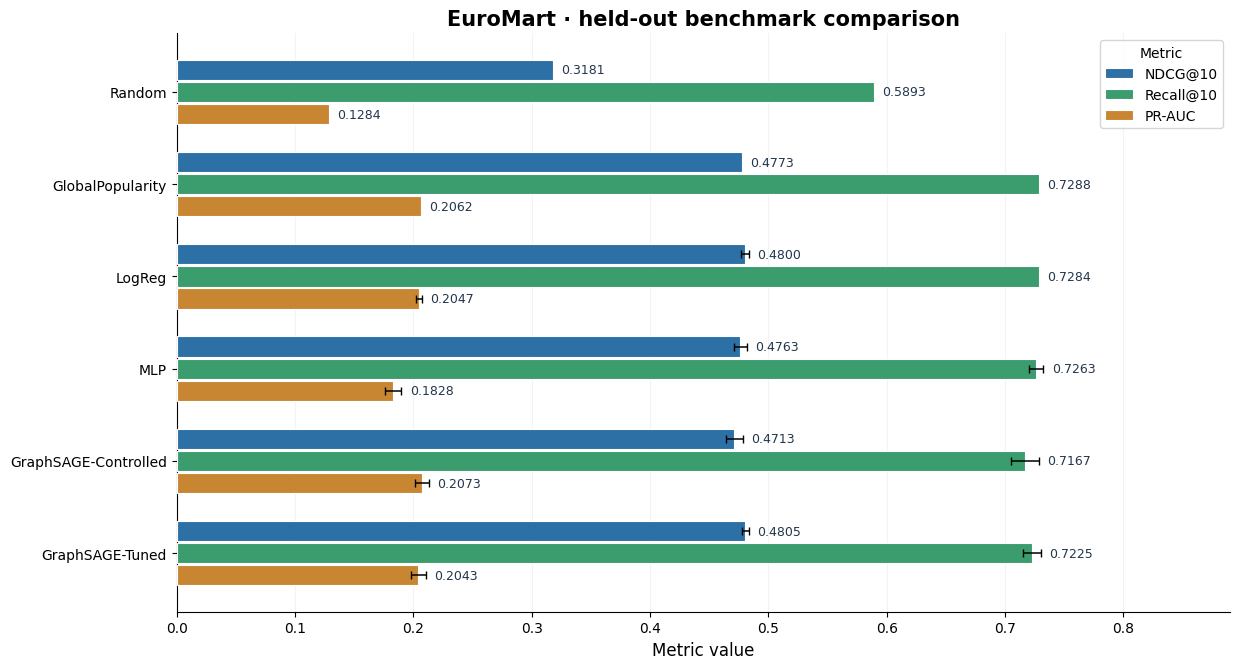


Retail POS — Benchmark
Saved: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures/11_publication_figures/retail_pos_six_model_heldout_benchmark


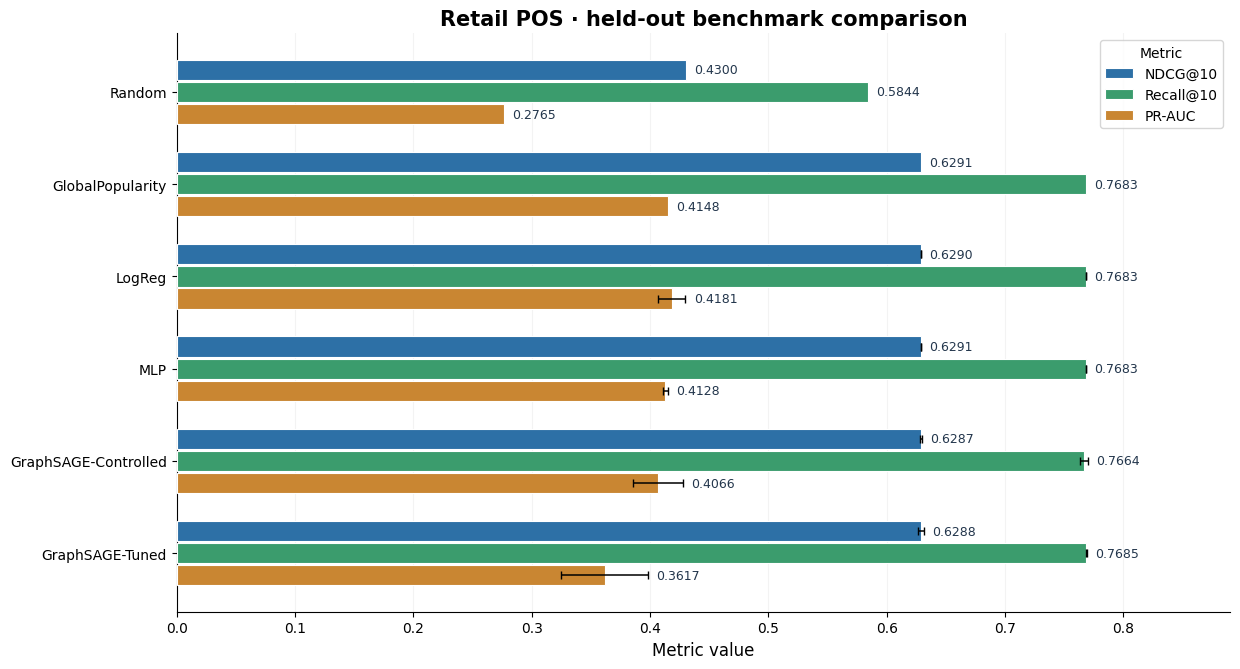


EuroMart — Ablations
Saved: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures/11_publication_figures/euromart_tuned_reference_5_facet_ablations


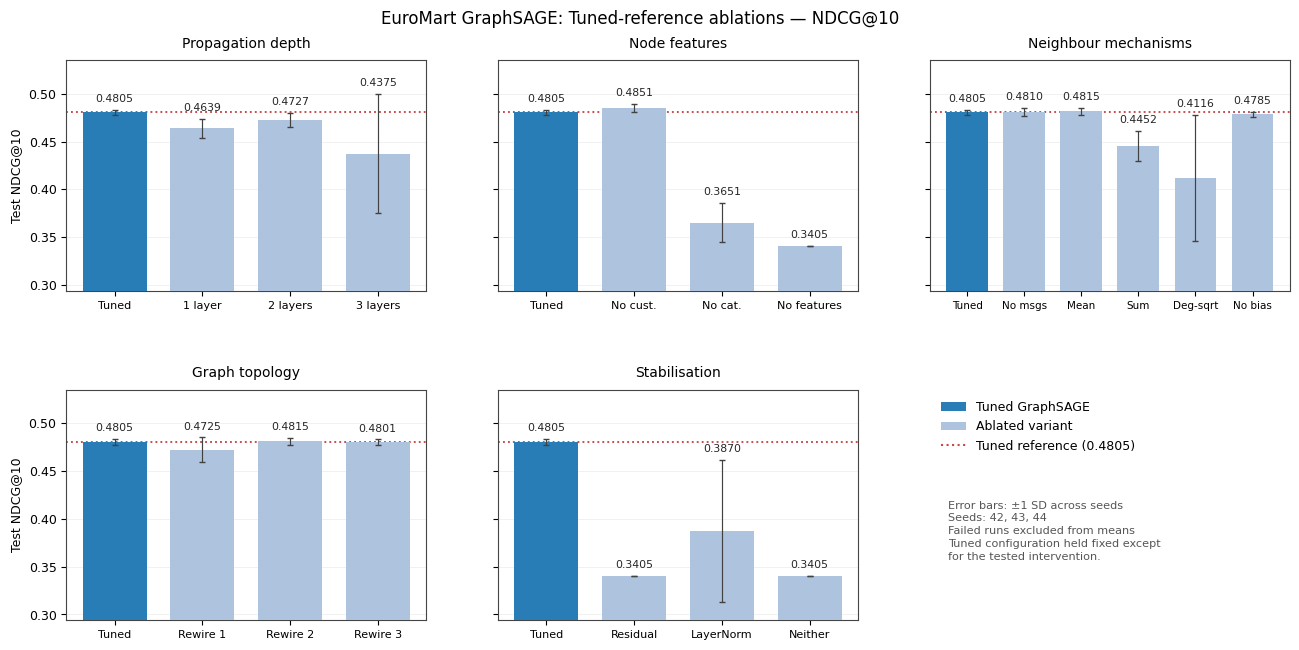


Retail POS — Ablations
Saved: /content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures/11_publication_figures/retail_pos_tuned_reference_5_facet_ablations


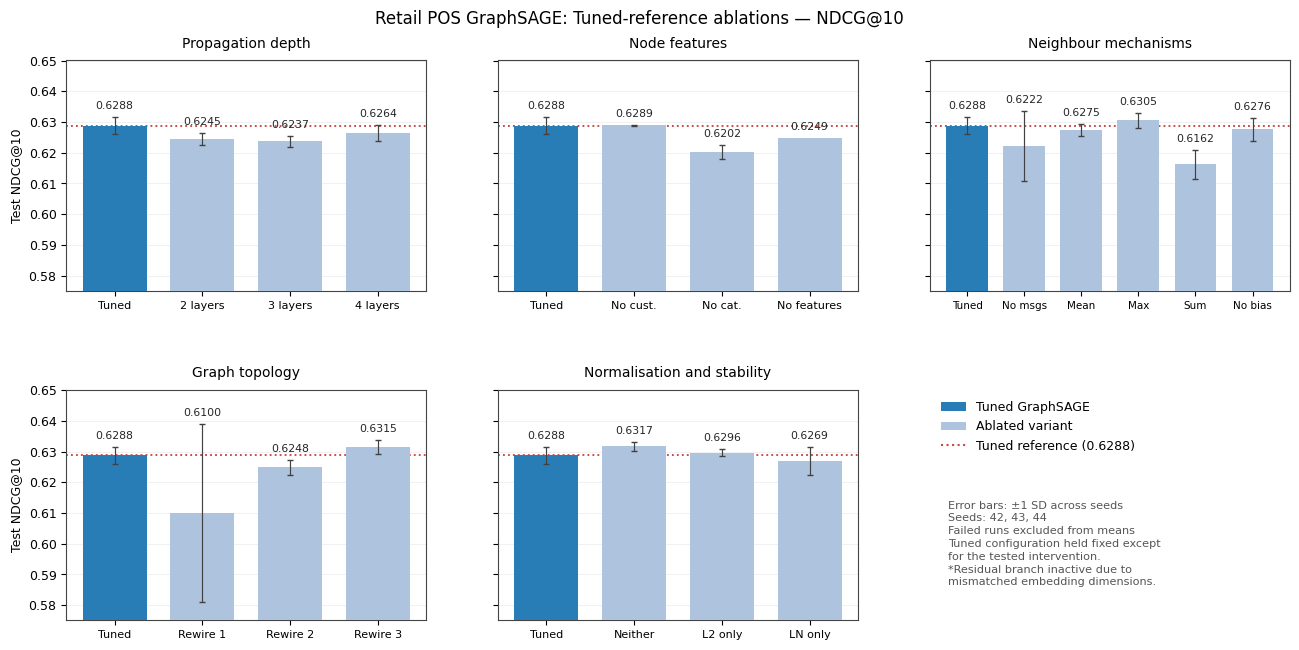


All four publication figures exported to:
/content/drive/MyDrive/SC4020-DataMining/results/v5/run6_graphsage_benchmark_v5/exhaustive/figures/11_publication_figures


In [6]:
# ============================================================
# 11.3 — GENERATE AND EXPORT ALL FOUR FIGURES
# ============================================================

BENCHMARK_DATA = load_benchmark()
FIGURE_DATA = {}

# Figures 1–2: Six-model held-out benchmarks
for dataset in DATASET_NAMES:

    print(f"\n{'='*60}")
    print(f"{DATASET_NAMES[dataset]} — Benchmark")
    print(f"{'='*60}")

    FIGURE_DATA[(dataset, "benchmark")] = (
        plot_benchmark(dataset, BENCHMARK_DATA)
    )

# Figures 3–4: Tuned-reference ablations
for dataset in DATASET_NAMES:

    print(f"\n{'='*60}")
    print(f"{DATASET_NAMES[dataset]} — Ablations")
    print(f"{'='*60}")

    raw = load_ablation(dataset)

    FIGURE_DATA[(dataset, "ablations")] = (
        plot_ablations(dataset, raw)
    )

print("\nAll four publication figures exported to:")
print(FIG_DIR)